# Import libraries and seurat object  

In [1]:
library(Seurat)
library(ggplot2)
library(dplyr)
library(sctransform)
library(tibble)
library(purrr)
library(patchwork)
library(glmGamPoi)
library(rlang)
library(ggrepel)
library(readr)
# library(vegan)


Loading required package: SeuratObject

Loading required package: sp


Attaching package: 'SeuratObject'


The following objects are masked from 'package:base':

    intersect, t




Error in .make_numeric_version(x, strict, .standard_regexps()$valid_numeric_version) : 
  invalid non-character version specification 'x' (type: double)



Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union



Attaching package: 'glmGamPoi'


The following object is masked from 'package:dplyr':

    vars


The following object is masked from 'package:ggplot2':

    vars



Attaching package: 'rlang'


The following objects are masked from 'package:purrr':

    %@%, flatten, flatten_chr, flatten_dbl, flatten_int, flatten_lgl,
    flatten_raw, invoke, splice




In [2]:
setwd("/workspaces/microsplit_DOL")


In [3]:
# Load the Seurat object
seurat_obj_filtered <- readRDS("jupyter/correct/correct_V2/ScObjects/SeuratObject_Val_Filtered_CDS_5cells.rds")

seurat_obj <- seurat_obj_filtered


In [4]:
cat("Available assays:\n")
print(Assays(seurat_obj))

cat("\nAvailable layers:\n")
print(Layers(seurat_obj))

# choose the assay to work with
GetAssay(seurat_obj, assay = "RNA")


Available assays:
[1] "RNA"



Available layers:
[1] "counts"


Assay (v5) data with 5491 features for 2934 cells
First 10 features:
 recC, recB, recD, QLH64-00045, QLH64-00050, QLH64-00055, QLH64-00060,
QLH64-00070, QLH64-00075, QLH64-00080 
Layers:
 counts 

In [5]:
# Display first rows of metadata
cat("\nMetadata overview:\n")
head(seurat_obj@meta.data)

# Display available columns
cat("\nAvailable columns in metadata:\n")
colnames(seurat_obj@meta.data)



Metadata overview:


,nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
GTACGCAA_AACCGAGA_AAACGATA,356,195,AAACGATA,AACCGAGA,GTACGCAA,A2,B2,E8,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
CGGATTGC_AACGCTTA_AAACGATA,302,184,AAACGATA,AACGCTTA,CGGATTGC,A2,B3,H6,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
CGCTGATC_AACGTGAT_AAACGATA,434,267,AAACGATA,AACGTGAT,CGCTGATC,A2,A1,A9,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
GCTAACGA_AAGAGATC_AAACGATA,804,387,AAACGATA,AAGAGATC,GCTAACGA,A2,F10,E4,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
CCTCTATC_AAGGACAC_AAACGATA,351,204,AAACGATA,AAGGACAC,CCTCTATC,A2,F11,H4,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
GTGTTCTA_ACACAGAA_AAACGATA,980,443,AAACGATA,ACACAGAA,GTGTTCTA,A2,B6,E11,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B



Available columns in metadata:


[1] "nCount_RNA"                     "nFeature_RNA"                  
 [3] "barcode.rd1"                    "barcode.rd2"                   
 [5] "barcode.rd3"                    "Well_loc_rd1"                  
 [7] "Well_loc_rd2"                   "Well_loc_rd3"                  
 [9] "Sample_ID"                      "Culture_medium"                
[11] "Rep_bio"                        "Rep_tech"                      
[13] "OD_timepoint"                   "OD_theoric"                    
[15] "OD_measured"                    "Condition"                     
[17] "Condition_OD_timepoint"         "Rep"                           
[19] "Condition_OD_timepoint_Rep_bio"

In [6]:

# Display available columns
cat("\nAvailable columns in metadata genes (features):\n")
# see the genes info layer metadata
colnames(seurat_obj[["RNA"]]@meta.data)
# colnames(GetAssay(seurat_obj, assay = "RNA")@meta.data) # fait pareil

head(seurat_obj@assays$RNA@meta.data)


Available columns in metadata genes (features):


[1] "seq_type"          "feature"           "class"            
 [4] "product_accession" "name"              "symbol"           
 [7] "locus_tag"         "symbol_old"        "locus_tag_old"    
[10] "symbol_renamed"    "final_gene_name"

,seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,final_gene_name
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>
6,chromosome,CDS,with_protein,WHS54405.1,exodeoxyribonuclease V subunit gamma,recC,QLH64-00030,recC,QLH64_00030,FALSE,recC
7,chromosome,CDS,with_protein,WHS54406.1,exodeoxyribonuclease V subunit beta,recB,QLH64-00035,recB,QLH64_00035,FALSE,recB
8,chromosome,CDS,with_protein,WHS54407.1,exodeoxyribonuclease V subunit alpha,recD,QLH64-00040,recD,QLH64_00040,FALSE,recD
9,chromosome,CDS,with_protein,WHS54408.1,YfiR family protein,,QLH64-00045,,QLH64_00045,FALSE,QLH64-00045
10,chromosome,CDS,with_protein,WHS54409.1,diguanylate cyclase,,QLH64-00050,,QLH64_00050,FALSE,QLH64-00050
11,chromosome,CDS,with_protein,WHS57090.1,OmpA family protein,,QLH64-00055,,QLH64_00055,FALSE,QLH64-00055


In [25]:
# import tsv file
gene_info <- read_tsv("data/raw_data/genome_annotation/other/extracted_features_no_duplicates.tsv")

Rows: 6249 Columns: 12
-- Column specification --------------------------------------------------------
Delimiter: "\t"
chr (11): seq_type, feature, class, product_accession, name, symbol, locus_t...
lgl  (1): symbol_renamed

i Use `spec()` to retrieve the full column specification for this data.
i Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [26]:
tail (gene_info)

seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
plasmid,CDS,with_protein,WHS57492.1,hypothetical protein,NA,QLH64-31220,NA,QLH64_31220,FALSE,QLH64-31220,QLH64-31220
plasmid,CDS,with_protein,WHS57493.1,hypothetical protein,NA,QLH64-31225,NA,QLH64_31225,FALSE,QLH64-31225,QLH64-31225
plasmid,CDS,with_protein,WHS57647.1,recombinase RecA,recA_2,QLH64-31230,recA,QLH64_31230,TRUE,QLH64-31230,recA_2
plasmid,CDS,with_protein,WHS57494.1,helix-hairpin-helix domain-containing protein,NA,QLH64-31235,NA,QLH64_31235,FALSE,QLH64-31235,QLH64-31235
plasmid,CDS,with_protein,WHS57495.1,Crp/Fnr family transcriptional regulator,NA,QLH64-31240,NA,QLH64_31240,FALSE,QLH64-31240,QLH64-31240
plasmid,CDS,with_protein,WHS57496.1,hypothetical protein,NA,QLH64-31245,NA,QLH64_31245,FALSE,QLH64-31245,QLH64-31245


# Test Simple Method 

In [6]:
#Normalisation
seurat_obj <- NormalizeData(seurat_obj, normalization.method = "LogNormalize", scale.factor = 1000)

Normalizing layer: counts



In [10]:
#Find variable features
seurat_obj <- FindVariableFeatures(seurat_obj, selection.method = "vst", nfeatures = 2000)


Finding variable features for layer counts



[1] "QLH64-12320" "QLH64-17820" "QLH64-24590" "QLH64-08635" "QLH64-22445"
 [6] "fabF_1"      "QLH64-19950" "QLH64-25710" "QLH64-08350" "QLH64-10015"

[1] "QLH64-12320" "QLH64-17820" "QLH64-24590" "QLH64-08635" "QLH64-22445"
 [6] "fabF_1"      "QLH64-19950" "QLH64-25710" "QLH64-08350" "QLH64-10015"
[11] "QLH64-25430" "QLH64-23710" "QLH64-05015" "QLH64-08330" "QLH64-13525"
[16] "QLH64-09505" "rbsK"        "QLH64-01895" "QLH64-01680" "QLH64-31020"
[21] "QLH64-02355" "QLH64-04585" "QLH64-07545" "QLH64-14525" "QLH64-06840"
[26] "folE2"       "QLH64-27370" "QLH64-05540" "QLH64-12600" "QLH64-23235"
[31] "QLH64-29360" "cysD"        "QLH64-29775" "QLH64-23980" "QLH64-04925"
[36] "QLH64-04060" "QLH64-04670" "QLH64-14995" "QLH64-06905" "QLH64-18745"
[41] "lpxH"        "cobA_1"      "QLH64-10530" "hpaA"        "QLH64-15090"
[46] "QLH64-16935" "QLH64-23730" "QLH64-26925" "QLH64-26610" "QLH64-27760"

When using repel, set xnudge and ynudge to 0 for optimal results



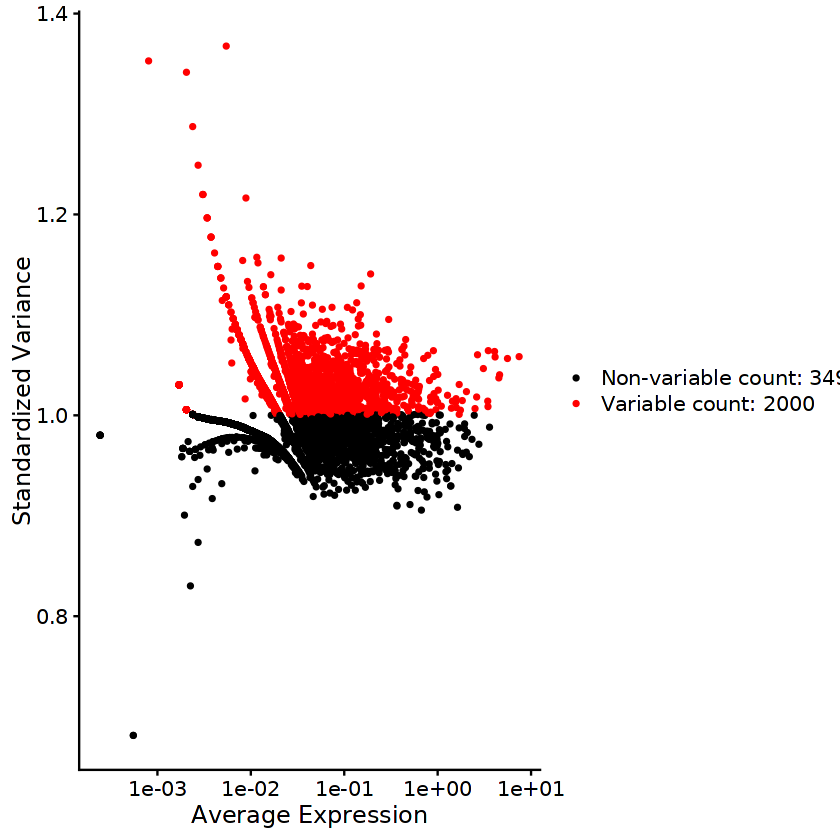

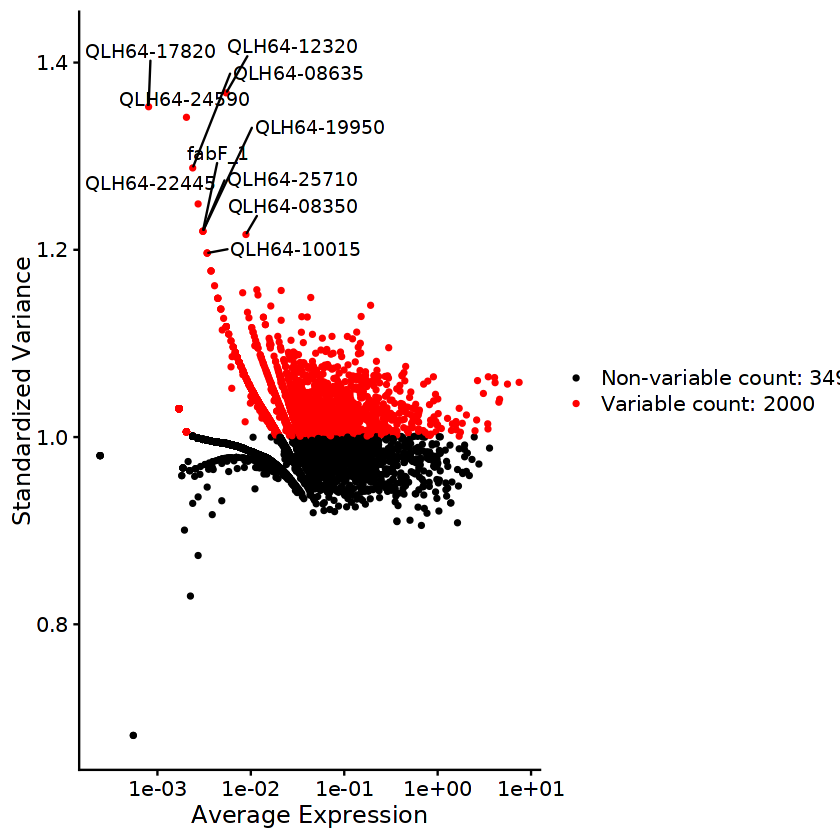

In [40]:
#Exploring variable features
top10 <- head(VariableFeatures(seurat_obj), n=10)
top10

top50 <- head(VariableFeatures(seurat_obj), n=50)
top50

var_feat_plot <- VariableFeaturePlot(seurat_obj)
var_feat_plot



var_feat_plot_labeled <- LabelPoints(plot = var_feat_plot, points = top10, repel = TRUE)
var_feat_plot_labeled 

In [45]:
gene_info  |> 
filter (final_gene_name %in% top10)


# gene_info  |> 
#filter (final_gene_name %in% top50)

seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
chromosome,CDS,with_protein,WHS55968.1,Gfo/Idh/MocA family oxidoreductase,NA,QLH64-08350,NA,QLH64_08350,FALSE,QLH64-08350,QLH64-08350
chromosome,CDS,with_protein,WHS56023.1,LysE family translocator,NA,QLH64-08635,NA,QLH64_08635,FALSE,QLH64-08635,QLH64-08635
chromosome,CDS,with_protein,WHS56272.1,beta-ketoacyl-ACP synthase II,fabF_1,QLH64-09935,fabF,QLH64_09935,TRUE,QLH64-09935,fabF_1
chromosome,CDS,with_protein,WHS56287.1,hypothetical protein,NA,QLH64-10015,NA,QLH64_10015,FALSE,QLH64-10015,QLH64-10015
chromosome,CDS,with_protein,WHS56729.1,hypothetical protein,NA,QLH64-12320,NA,QLH64_12320,FALSE,QLH64-12320,QLH64-12320
chromosome,CDS,with_protein,WHS52205.1,IS4 family transposase,NA,QLH64-17820,NA,QLH64_17820,FALSE,QLH64-17820,QLH64-17820
chromosome,CDS,with_protein,WHS52601.1,alginate biosynthesis protein Alg44,NA,QLH64-19950,NA,QLH64_19950,FALSE,QLH64-19950,QLH64-19950
chromosome,CDS,with_protein,WHS53064.1,MFS transporter,NA,QLH64-22445,NA,QLH64_22445,FALSE,QLH64-22445,QLH64-22445
chromosome,CDS,with_protein,WHS53470.1,amino acid ABC transporter permease,NA,QLH64-24590,NA,QLH64_24590,FALSE,QLH64-24590,QLH64-24590


In [41]:
# Scaling the data
all_genes <- rownames(seurat_obj)
seurat_obj <- ScaleData(seurat_obj, features = all_genes)

Centering and scaling data matrix



In [42]:
# Running PCA
seurat_obj <- RunPCA(seurat_obj, features = VariableFeatures(object = seurat_obj))
seurat_obj

PC_ 1 
Positive:  QLH64-19225, QLH64-05310, aceE, QLH64-02935, QLH64-00420, ccoN_2, atpD, QLH64-23140, fusA, rpoC 
	   icd, QLH64-26960, QLH64-05400, QLH64-12125, QLH64-09610, raiA, gap, rplB, QLH64-13720, infC 
	   QLH64-13705, acnB, QLH64-07480, QLH64-22540, QLH64-12435, QLH64-13710, QLH64-00845, QLH64-27060, infB, rplA 
Negative:  QLH64-24105, QLH64-02320, QLH64-00360, gluQRS, QLH64-18880, QLH64-02630, QLH64-01365, QLH64-06945, QLH64-22115, QLH64-05945 
	   QLH64-17200, QLH64-14890, QLH64-01455, QLH64-18615, QLH64-07010, QLH64-11020, QLH64-23410, QLH64-30160, QLH64-29715, QLH64-20285 
	   QLH64-08185, tssI_4, QLH64-12900, QLH64-15845, QLH64-16595, QLH64-28280, QLH64-14500, QLH64-03320, choX_1, QLH64-01295 
PC_ 2 
Positive:  QLH64-21275, QLH64-01435, QLH64-13690, QLH64-28815, QLH64-26335, rbfA, QLH64-15095, QLH64-04800, QLH64-27600, recF 
	   QLH64-07840, erpA, QLH64-25950, QLH64-23720, QLH64-07105, QLH64-02935, QLH64-10420, QLH64-02510, QLH64-06365, rlmE 
	   ccmI, QLH64-22205, hisC

An object of class Seurat 
5491 features across 2934 samples within 1 assay 
Active assay: RNA (5491 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 1 dimensional reduction calculated: pca

In [44]:
list <- c("QLH64-19225", "QLH64-05310", "aceE", "QLH64-02935", "QLH64-00420", "ccoN_2", "atpD", "QLH64-23140", "fusA", "rpoC", 
          "icd", "QLH64-26960", "QLH64-05400", "QLH64-12125", "QLH64-09610", "raiA", "gap", "rplB", "QLH64-13720", "infC", 
          "QLH64-13705", "acnB", "QLH64-07480", "QLH64-22540", "QLH64-12435", "QLH64-13710", "QLH64-00845", "QLH64-27060", "infB", "rplA")

In [46]:
gene_info  |> 
  filter(final_gene_name %in% list) 

seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
chromosome,CDS,with_protein,WHS54477.1,diiron oxygenase,NA,QLH64-00420,NA,QLH64_00420,FALSE,QLH64-00420,QLH64-00420
chromosome,CDS,with_protein,WHS54524.1,translation initiation factor IF-2,infB,QLH64-00680,infB,QLH64_00680,FALSE,QLH64-00680,infB
chromosome,CDS,with_protein,WHS54555.1,ABC transporter substrate-binding protein,NA,QLH64-00845,NA,QLH64_00845,FALSE,QLH64-00845,QLH64-00845
chromosome,CDS,with_protein,WHS54597.1,ribosome-associated translation inhibitor RaiA,raiA,QLH64-01075,raiA,QLH64_01075,FALSE,QLH64-01075,raiA
chromosome,CDS,with_protein,WHS54939.1,type I glyceraldehyde-3-phosphate dehydrogenase,gap,QLH64-02885,gap,QLH64_02885,FALSE,QLH64-02885,gap
chromosome,CDS,with_protein,WHS54949.1,carbohydrate porin,NA,QLH64-02935,NA,QLH64_02935,FALSE,QLH64-02935,QLH64-02935
chromosome,CDS,with_protein,WHS55389.1,non-ribosomal peptide synthetase,NA,QLH64-05310,NA,QLH64_05310,FALSE,QLH64-05310,QLH64-05310
chromosome,CDS,with_protein,WHS55407.1,OmpA family protein,NA,QLH64-05400,NA,QLH64_05400,FALSE,QLH64-05400,QLH64-05400
chromosome,CDS,with_protein,WHS55458.1,"cytochrome-c oxidase, cbb3-type subunit I",ccoN_2,QLH64-05670,ccoN,QLH64_05670,TRUE,QLH64-05670,ccoN_2


In [48]:
# Display PCA results
print(seurat_obj[["pca"]], dims = 1:15, nfeatures = 10)


PC_ 1 
Positive:  QLH64-19225, QLH64-05310, aceE, QLH64-02935, QLH64-00420, ccoN_2, atpD, QLH64-23140, fusA, rpoC 
Negative:  QLH64-24105, QLH64-02320, QLH64-00360, gluQRS, QLH64-18880, QLH64-02630, QLH64-01365, QLH64-06945, QLH64-22115, QLH64-05945 
PC_ 2 
Positive:  QLH64-21275, QLH64-01435, QLH64-13690, QLH64-28815, QLH64-26335, rbfA, QLH64-15095, QLH64-04800, QLH64-27600, recF 
Negative:  QLH64-02765, QLH64-27430, QLH64-14565, QLH64-13345, gorA, QLH64-16885, QLH64-05795, QLH64-15420, QLH64-24335, QLH64-02095 
PC_ 3 
Positive:  QLH64-24320, QLH64-23070, pgi, QLH64-26220, QLH64-01850, QLH64-15470, QLH64-08745, QLH64-10100, QLH64-22145, QLH64-20405 
Negative:  QLH64-28875, QLH64-10875, QLH64-13325, QLH64-20135, lolA, treS, asd_1, lpoB, QLH64-24535, cra 
PC_ 4 
Positive:  QLH64-15455, QLH64-22205, ybeY, lptB, QLH64-15715, QLH64-27570, QLH64-03940, coaBC, trxA_2, rpsI 
Negative:  QLH64-15500, QLH64-30825, thrS, QLH64-02010, QLH64-03730, QLH64-18305, flgK, QLH64-01940, QLH64-29530, QLH64

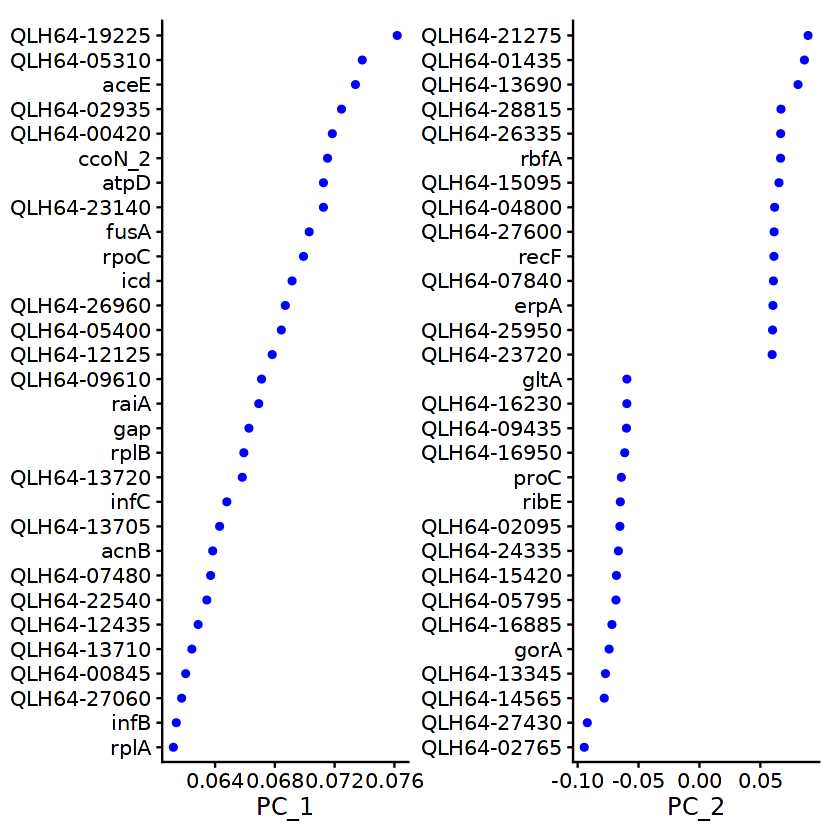

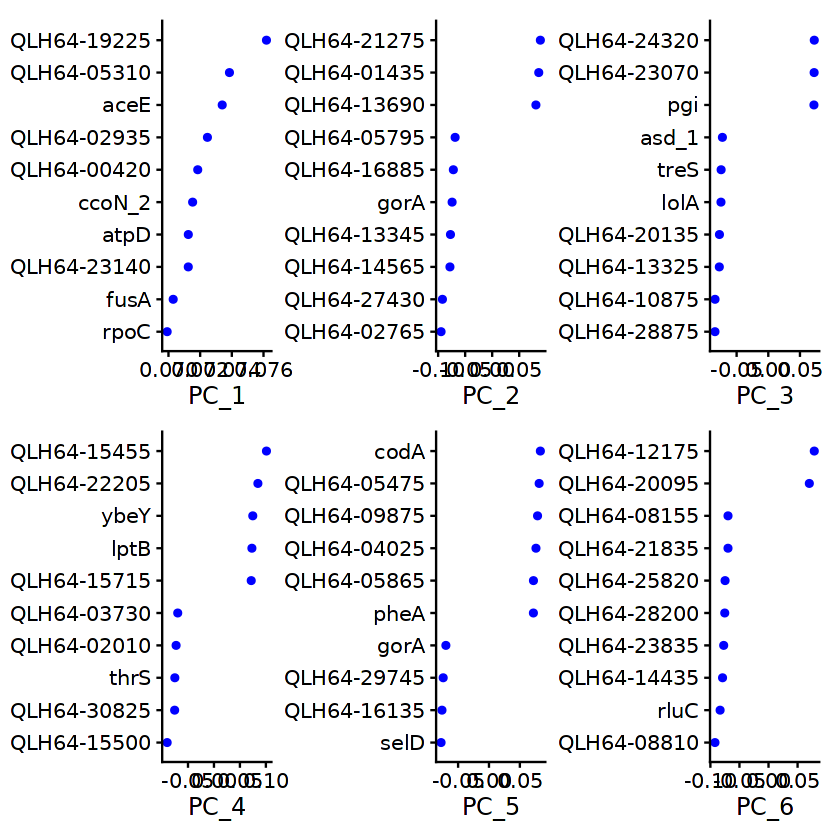

In [50]:
VizDimLoadings(seurat_obj, dims = 1:2)
VizDimLoadings(seurat_obj, dims = 1:6, reduction = "pca", ncol = 3, nfeature=10)


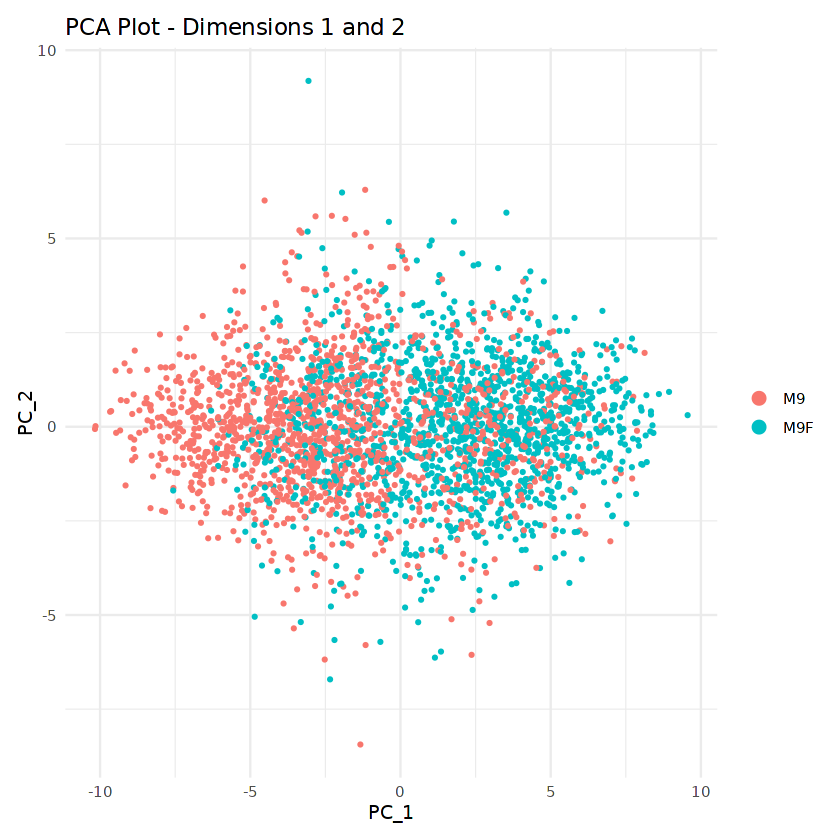

In [53]:
DimPlot(seurat_obj, reduction = "pca", dims = 1:2, group.by = "Culture_medium") +
  ggtitle("PCA Plot - Dimensions 1 and 2") +
  theme_minimal()

In [ ]:
# choose the size of the plot in the notebook




Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


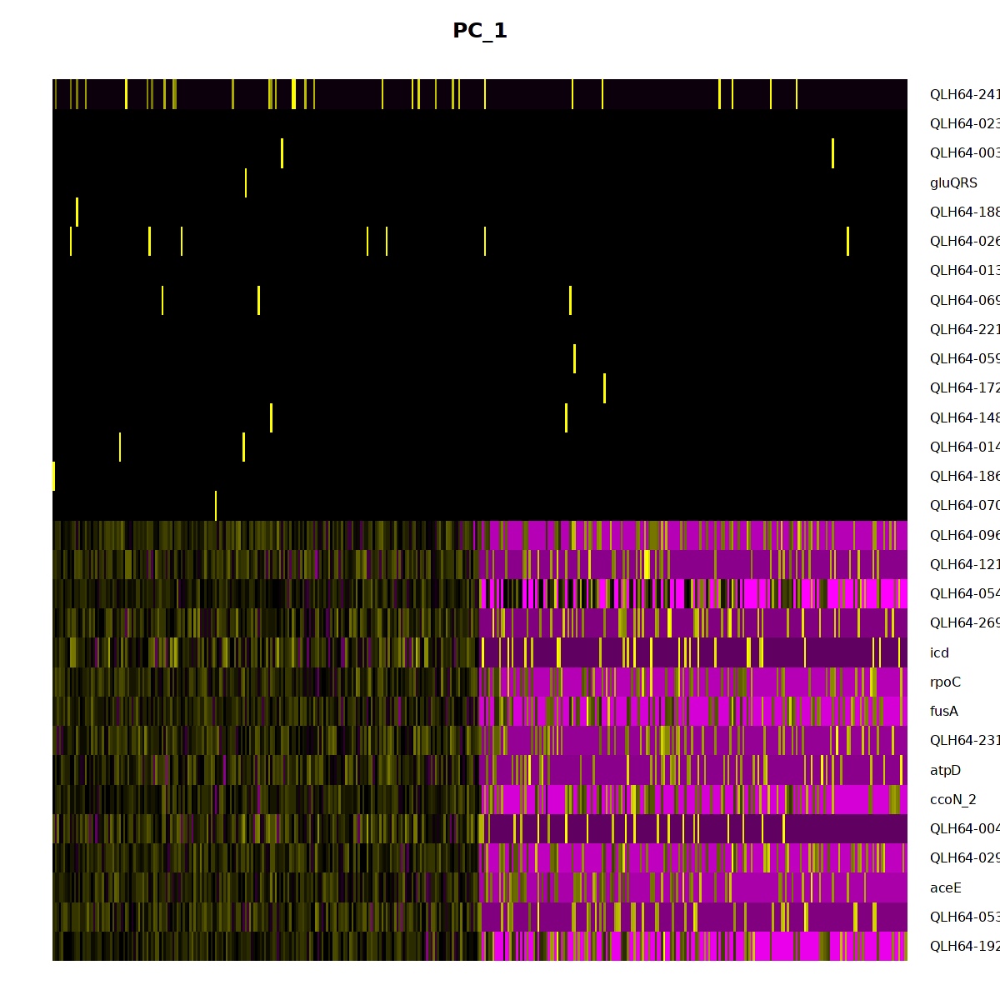

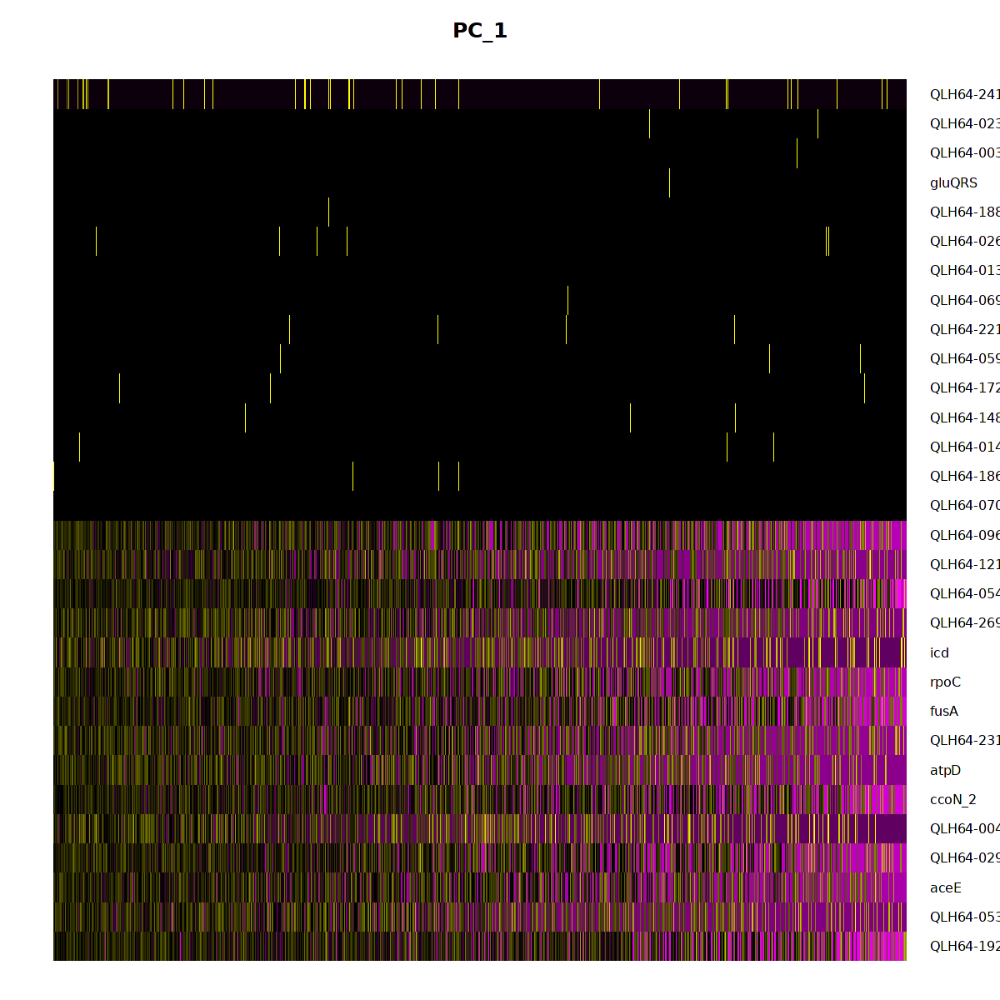

In [79]:
#options(repr.plot.width = 10, repr.plot.height = 10)
DimHeatmap(seurat_obj, dims = 1, cells = 400, balanced = TRUE)
DimHeatmap(seurat_obj, dims = 1, cells = 4000, balanced = TRUE)

# on peut mettre 4000 cells pour voir toutes les cellules 

In [60]:
gene_info  |> 
  filter(final_gene_name %in% c("gluQRS", "QLH64-19225")) 

seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
chromosome,CDS,with_protein,WHS52462.1,OprD family porin,NA,QLH64-19225,NA,QLH64_19225,FALSE,QLH64-19225,QLH64-19225
chromosome,CDS,with_protein,WHS52831.1,tRNA glutamyl-Q(34) synthetase GluQRS,gluQRS,QLH64-21205,gluQRS,QLH64_21205,FALSE,QLH64-21205,gluQRS


In [59]:
gene_info  |> 
  filter(final_gene_name %in% c("icd", "ccoN_2")) 

seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
chromosome,CDS,with_protein,WHS55458.1,"cytochrome-c oxidase, cbb3-type subunit I",ccoN_2,QLH64-05670,ccoN,QLH64_05670,TRUE,QLH64-05670,ccoN_2
chromosome,CDS,with_protein,WHS55743.1,NADP-dependent isocitrate dehydrogenase,icd,QLH64-07160,icd,QLH64_07160,FALSE,QLH64-07160,icd


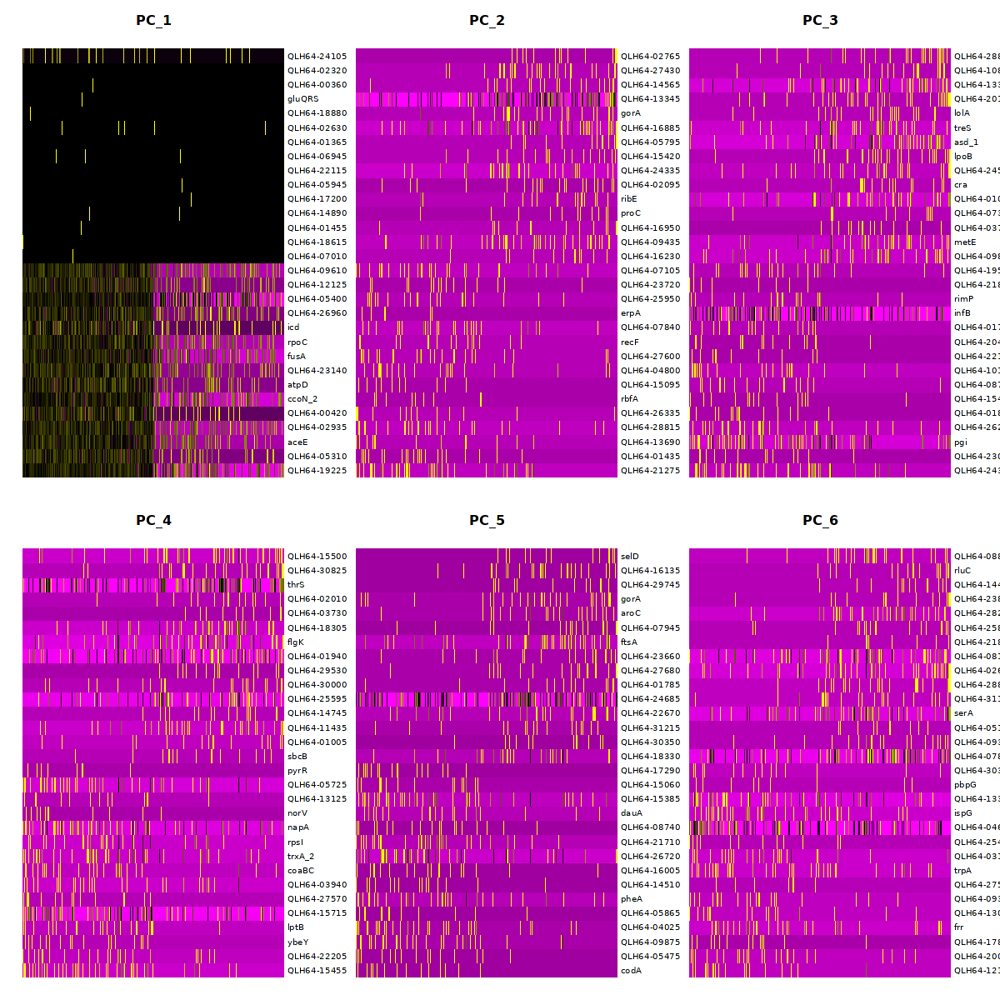

In [80]:
DimHeatmap(seurat_obj, dims = 1:6, cells = 400, balanced = TRUE, ncol = 3)

Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


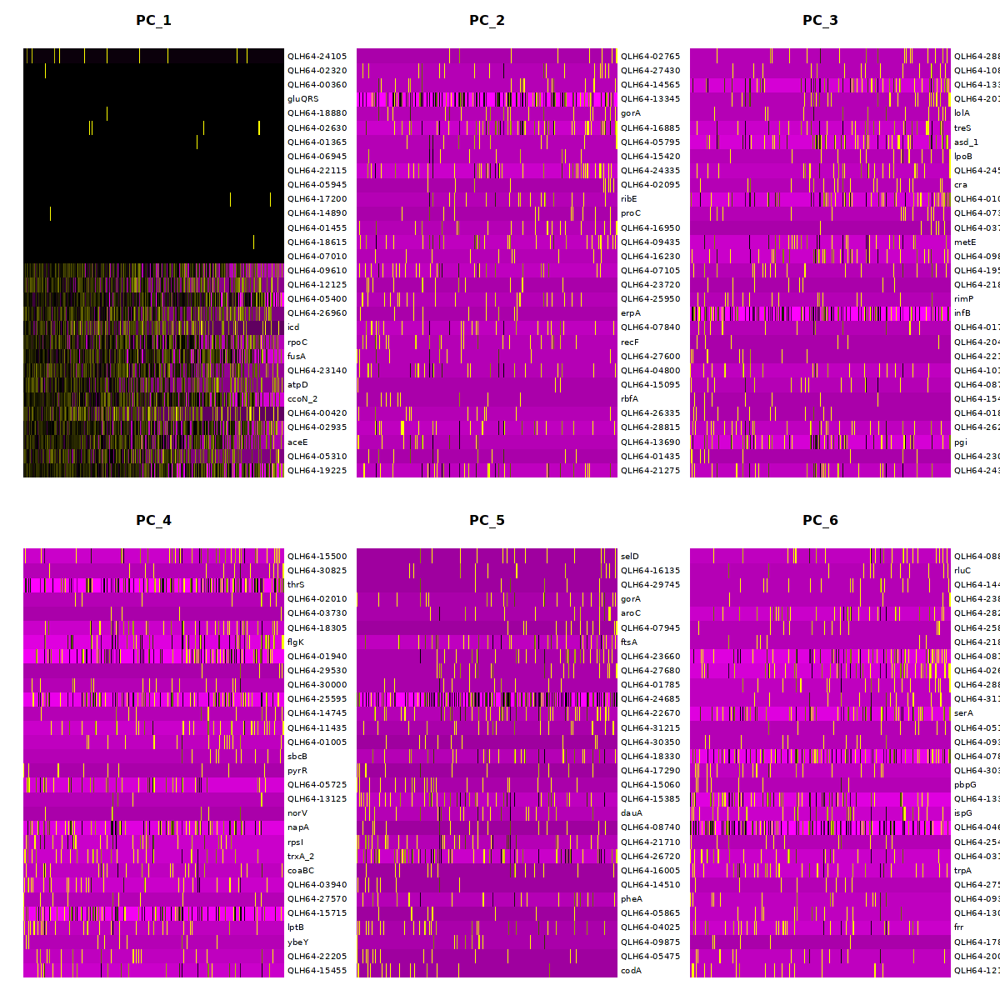

In [78]:
DimHeatmap(seurat_obj, dims = 1:6, cells = 4000, balanced = TRUE, ncol = 3)

Violet foncé ; Valeurs faibles ; Faible contribution (sous la moyenne)
Noir ; Valeur ~0 (centrée) ; Moyenne (z-score ≈ 0)
Jaune vif ; Valeurs élevées; Forte contribution (au-dessus de la moyenne)


In [90]:
#Loadings(seurat_obj[["pca"]])[, 1]

# Loadings = contribution de chaque gène à chaque dimension
loadings <- Loadings(seurat_obj[["pca"]])

# PCA 1
loadings_pca1 <- loadings[, 1]

# Top 10 positifs (jaune)
top_positive_genes <- sort(loadings_pca1, decreasing = TRUE)[1:10]

# Top 10 négatifs (violet)
top_negative_genes <- sort(loadings_pca1, decreasing = FALSE)[1:10]

# Gènes les plus neutres (noirs) = valeurs proches de 0
threshold <- 0.001  # Tu peux ajuster
neutral_genes <- loadings_pca1[abs(loadings_pca1) < threshold]

print("Top 10 genes fortement positifs (jaune) :")
print(top_positive_genes)

print("Top 10 genes fortement négatifs (violet) :")
print(top_negative_genes)

print("Genes proches de 0 (noirs) :")
head(neutral_genes, 10)  # Affiche les 10 premiers

# 3. Regrouper dans une liste R nommée
gene_lists <- list(
  jaune = top_positive_genes,
  violet = top_negative_genes,
  noir = neutral_genes
)

# Afficher
str(gene_lists)



[1] "Top 10 genes fortement positifs (jaune) :"
QLH64-19225 QLH64-05310        aceE QLH64-02935 QLH64-00420      ccoN_2 
 0.07618639  0.07384995  0.07339279  0.07245906  0.07184710  0.07152486 
       atpD QLH64-23140        fusA        rpoC 
 0.07125202  0.07125012  0.07029780  0.06991634 
[1] "Top 10 genes fortement n<U+00E9>gatifs (violet) :"
  QLH64-24105   QLH64-02320   QLH64-00360        gluQRS   QLH64-18880 
-3.708781e-03 -1.224357e-03 -5.300643e-04 -4.708770e-04 -4.609647e-04 
  QLH64-02630   QLH64-01365   QLH64-06945   QLH64-22115   QLH64-05945 
-1.886824e-05  4.519986e-06  1.481066e-04  1.535855e-04  1.739874e-04 
[1] "Genes proches de 0 (noirs) :"


QLH64-29715   QLH64-02630   QLH64-12900   QLH64-01365   QLH64-05945 
 6.948777e-04 -1.886824e-05  9.522559e-04  4.519986e-06  1.739874e-04 
  QLH64-20285        gluQRS   QLH64-30160   QLH64-00360   QLH64-08185 
 6.951509e-04 -4.708770e-04  6.537272e-04 -5.300643e-04  8.327179e-04

List of 3
 $ jaune : Named num [1:10] 0.0762 0.0738 0.0734 0.0725 0.0718 ...
  ..- attr(*, "names")= chr [1:10] "QLH64-19225" "QLH64-05310" "aceE" "QLH64-02935" ...
 $ violet: Named num [1:10] -0.003709 -0.001224 -0.00053 -0.000471 -0.000461 ...
  ..- attr(*, "names")= chr [1:10] "QLH64-24105" "QLH64-02320" "QLH64-00360" "gluQRS" ...
 $ noir  : Named num [1:21] 6.95e-04 -1.89e-05 9.52e-04 4.52e-06 1.74e-04 ...
  ..- attr(*, "names")= chr [1:21] "QLH64-29715" "QLH64-02630" "QLH64-12900" "QLH64-01365" ...


In [ ]:
# voir si les noir sont des gènes de housekeeping

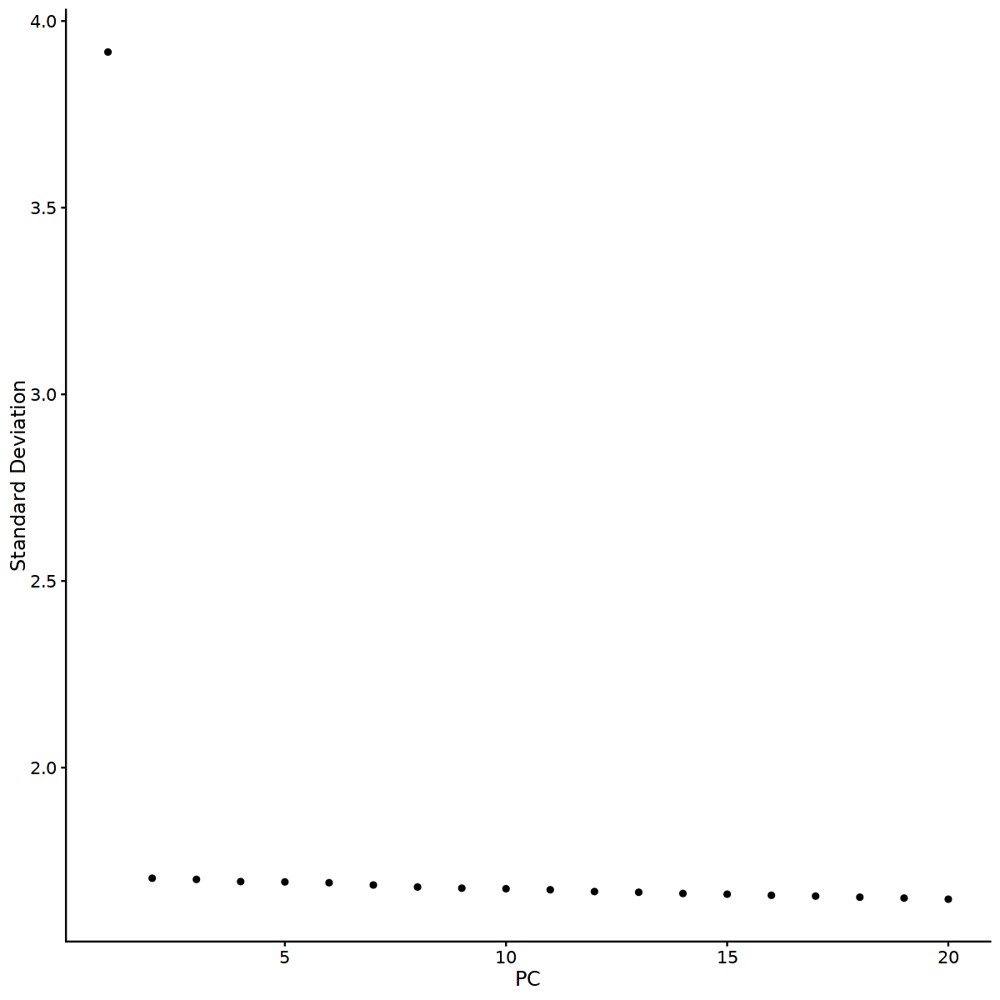

In [76]:
ElbowPlot(seurat_obj)

In [92]:
#Clustering
seurat_obj <- FindNeighbors(seurat_obj, dims = 1:10)

Computing nearest neighbor graph

Computing SNN



In [93]:
seurat_obj <- FindClusters(seurat_obj, resolution = 0.5)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 94626

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7227
Number of communities: 3
Elapsed time: 0 seconds


In [94]:
head(Idents(seurat_obj), 10)
seurat_obj <- RunUMAP(seurat_obj, 1:10)

GTACGCAA_AACCGAGA_AAACGATA CGGATTGC_AACGCTTA_AAACGATA 
                         1                          1 
CGCTGATC_AACGTGAT_AAACGATA GCTAACGA_AAGAGATC_AAACGATA 
                         1                          0 
CCTCTATC_AAGGACAC_AAACGATA GTGTTCTA_ACACAGAA_AAACGATA 
                         1                          0 
ACAGATTC_ACAGATTC_AAACGATA CAAGACTA_ACATTGGC_AAACGATA 
                         1                          1 
CCGTGAGA_ACCACTGT_AAACGATA ACTATGCA_AGTACAAG_AAACGATA 
                         1                          1 
Levels: 0 1 2

Warning message:
"The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session"
08:41:48 UMAP embedding parameters a = 0.9922 b = 1.112

08:41:48 Read 2934 rows and found 10 numeric columns

08:41:48 Using Annoy for neighbor search, n_neighbors = 30

08:41:48 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

08:41:49 Writing NN index file to temp file /tmp/RtmpoxfOPx/file3bc2653f11b

08:41:49 Searching Annoy index using 1 thread, search_k = 3000

08:41:50 Annoy recall = 100%

08:41:51 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 

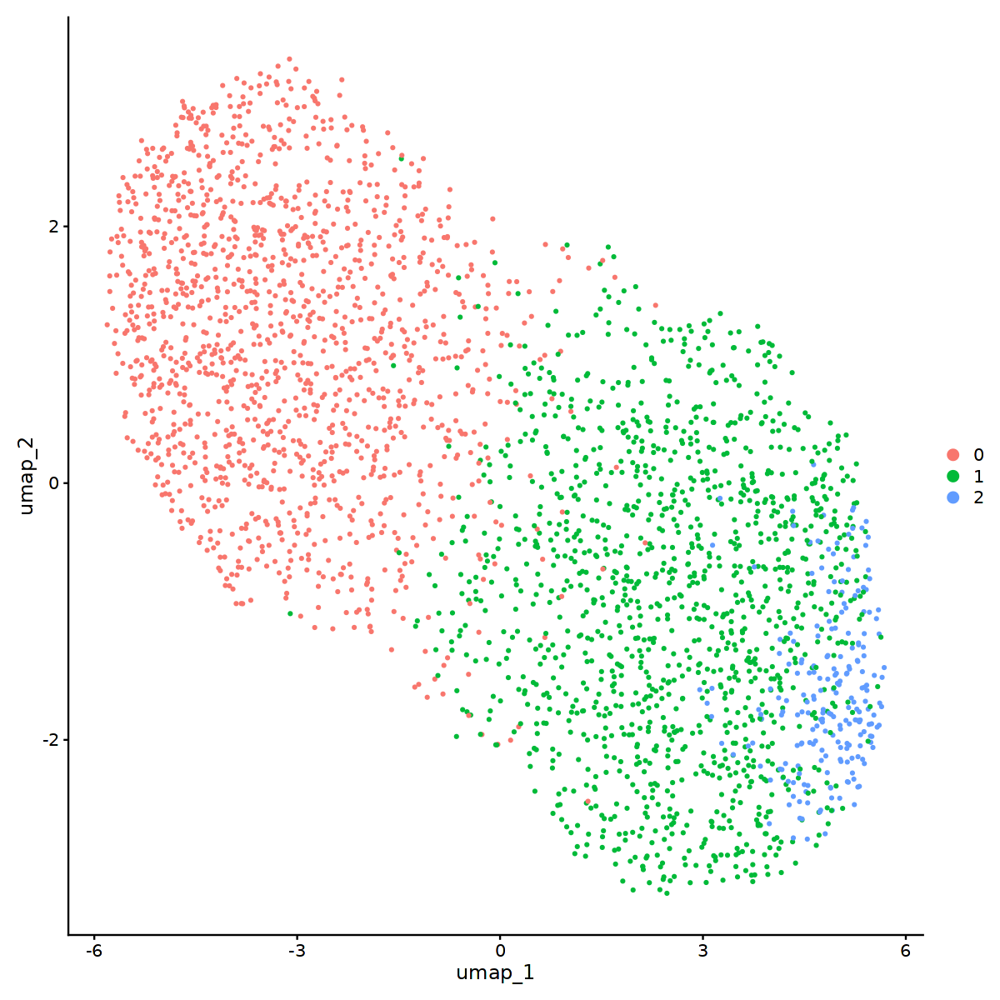

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2



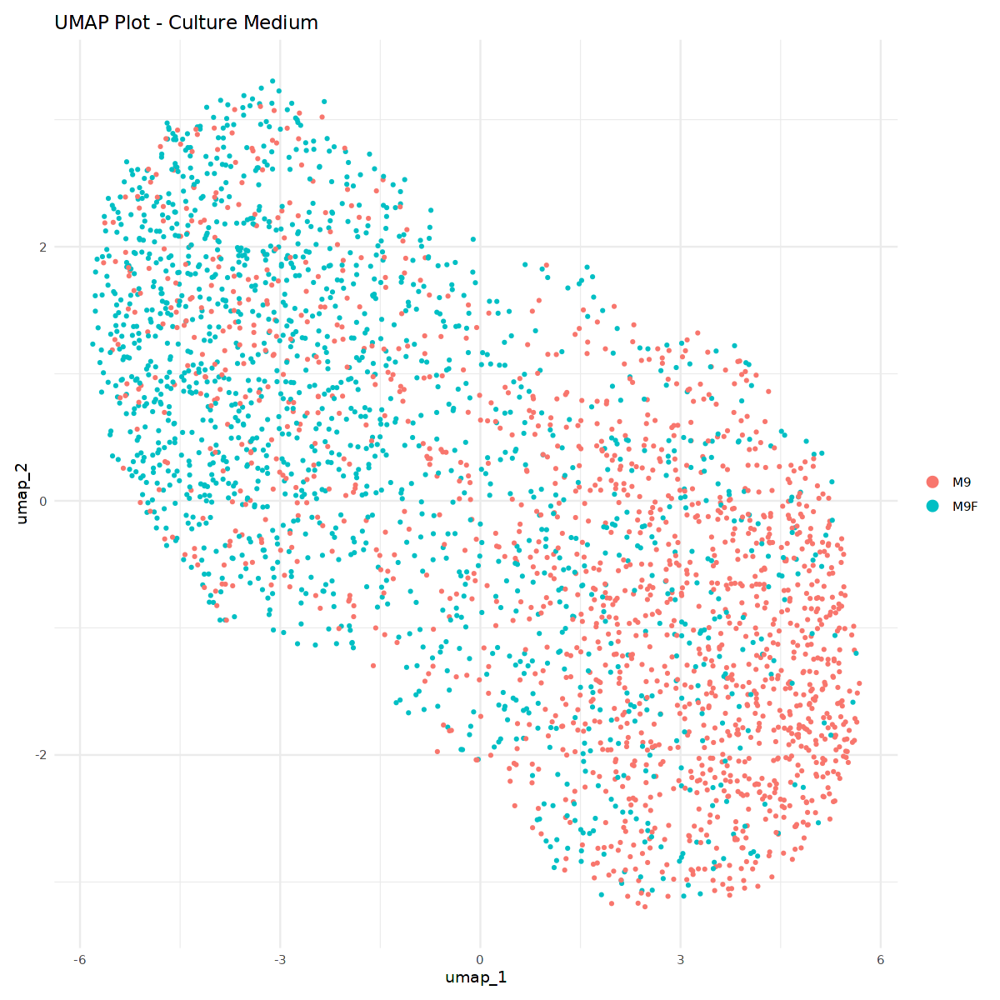

In [100]:
DimPlot(seurat_obj, reduction = "umap")
DimPlot(seurat_obj, reduction = "umap", group.by = "Culture_medium") +
  ggtitle("UMAP Plot - Culture Medium") +
  theme_minimal()
seurat_markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, min.pct = 0.25, logfc.threshold = 0.25)

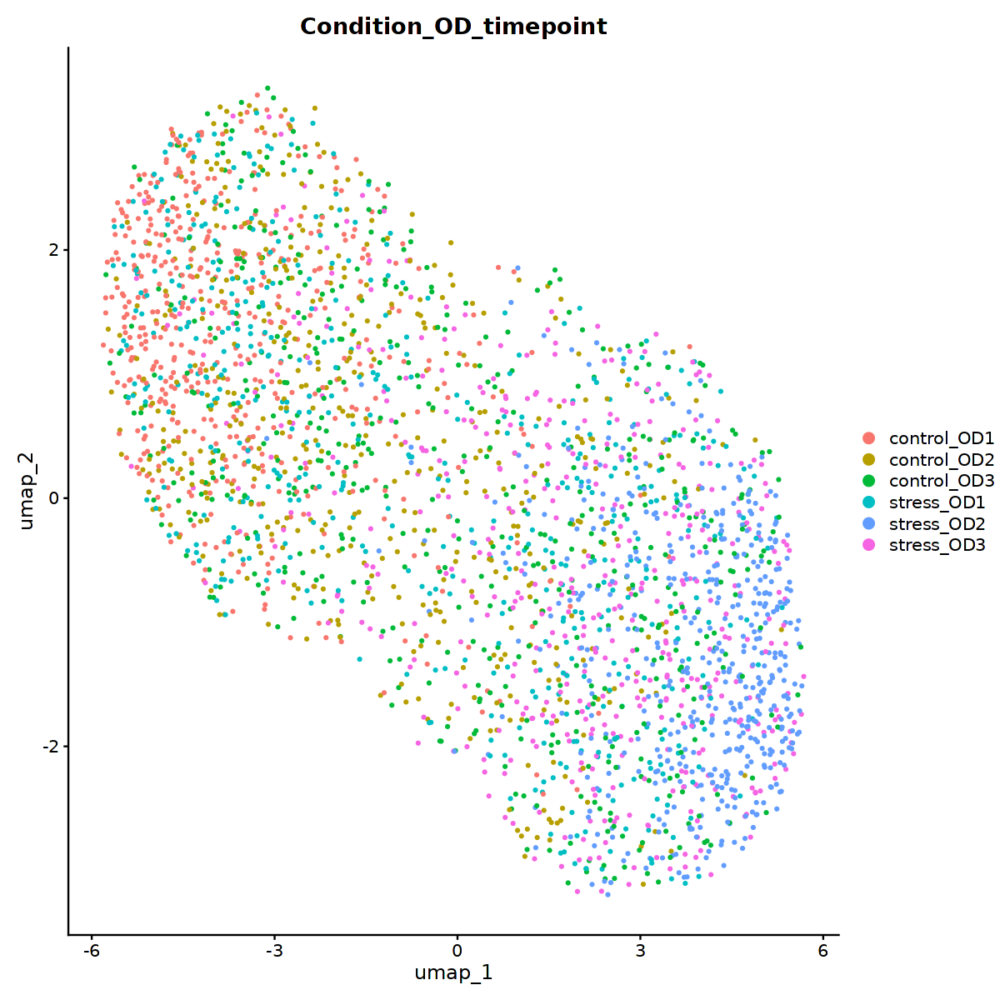

In [104]:
DimPlot(seurat_obj, reduction = "umap", group.by = "Condition_OD_timepoint")

In [105]:

top_2_markers <- seurat_markers %>%
  group_by(cluster) %>%
  slice_max(n = 2, order_by = avg_log2FC)
top_2_markers


p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
1.100182e-62,0.5782643,0.361,0.079,6.041099e-59,0,hcnA
4.234471e-50,0.5449623,0.289,0.063,2.325148e-46,0,tcyJ
1.026132e-13,0.4535999,0.128,0.275,5.634492e-10,1,leuB
3.007157e-12,0.3473645,0.121,0.252,1.651230e-08,1,bfr_1
2.200684e-06,0.9105137,0.134,0.339,1.208395e-02,2,QLH64-10165
6.236859e-06,0.8901113,0.097,0.262,3.424659e-02,2,QLH64-23150


In [99]:
gene_info  |> 
  filter(final_gene_name %in% top_2_markers$gene) 

seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
chromosome,CDS,with_protein,WHS57153.1,cyanide-forming glycine dehydrogenase subunit HcnA,hcnA,QLH64-08290,hcnA,QLH64_08290,FALSE,QLH64-08290,hcnA
chromosome,CDS,with_protein,WHS56315.1,alpha/beta hydrolase,NA,QLH64-10165,NA,QLH64_10165,FALSE,QLH64-10165,QLH64-10165
chromosome,CDS,with_protein,WHS51819.1,3-isopropylmalate dehydrogenase,leuB,QLH64-15730,leuB,QLH64_15730,FALSE,QLH64-15730,leuB
chromosome,CDS,with_protein,WHS52409.1,bacterioferritin,bfr_1,QLH64-18935,bfr,QLH64_18935,TRUE,QLH64-18935,bfr_1
chromosome,CDS,with_protein,WHS53196.1,SpoVR family protein,NA,QLH64-23150,NA,QLH64_23150,FALSE,QLH64-23150,QLH64-23150
chromosome,CDS,with_protein,WHS53978.1,cystine ABC transporter substrate-binding protein,tcyJ,QLH64-27290,tcyJ,QLH64_27290,FALSE,QLH64-27290,tcyJ


In [113]:
cluster_0_vs_cluster_1 <- FindMarkers(seurat_obj, ident.1 = 0, ident.2 = 1, min.pct = 0.25)
head(cluster_0_vs_cluster_1, n=10)

# extract col1 of cluster_0_vs_cluster_1

gene_info  |> 
  filter(final_gene_name %in% head(rownames(cluster_0_vs_cluster_1), 10))

 

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
hcnA,2.555613e-50,0.5265759,0.361,0.088,1.403287e-46
raiA,6.605148e-50,0.3053710,0.618,0.214,3.626887e-46
QLH64-17135,2.038261e-47,0.3142231,0.412,0.117,1.119209e-43
ppsA,3.319710e-47,0.2006796,0.611,0.213,1.822853e-43
rplA,1.891948e-45,0.2069147,0.566,0.196,1.038869e-41
tssH_2,3.058634e-45,0.3298833,0.410,0.120,1.679496e-41
QLH64-00400,7.416700e-44,0.2125847,0.430,0.131,4.072510e-40
QLH64-15715,7.754895e-44,0.3261677,0.397,0.117,4.258213e-40
QLH64-29870,9.094367e-44,0.2445489,0.399,0.118,4.993717e-40


seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
chromosome,CDS,with_protein,WHS54473.1,HlyD family secretion protein,NA,QLH64-00400,NA,QLH64_00400,FALSE,QLH64-00400,QLH64-00400
chromosome,CDS,with_protein,WHS54597.1,ribosome-associated translation inhibitor RaiA,raiA,QLH64-01075,raiA,QLH64_01075,FALSE,QLH64-01075,raiA
chromosome,CDS,with_protein,WHS55400.1,phosphoenolpyruvate synthase,ppsA,QLH64-05365,ppsA,QLH64_05365,FALSE,QLH64-05365,ppsA
chromosome,CDS,with_protein,WHS55552.1,HU family DNA-binding protein,NA,QLH64-06170,NA,QLH64_06170,FALSE,QLH64-06170,QLH64-06170
chromosome,CDS,with_protein,WHS57153.1,cyanide-forming glycine dehydrogenase subunit HcnA,hcnA,QLH64-08290,hcnA,QLH64_08290,FALSE,QLH64-08290,hcnA
chromosome,CDS,with_protein,WHS51816.1,FimV/HubP family polar landmark protein,NA,QLH64-15715,NA,QLH64_15715,FALSE,QLH64-15715,QLH64-15715
chromosome,CDS,with_protein,WHS52077.1,acyl-CoA dehydrogenase,NA,QLH64-17135,NA,QLH64_17135,FALSE,QLH64-17135,QLH64-17135
chromosome,CDS,with_protein,WHS53146.1,50S ribosomal protein L1,rplA,QLH64-22855,rplA,QLH64_22855,FALSE,QLH64-22855,rplA
chromosome,CDS,with_protein,WHS53587.1,type VI secretion system ATPase TssH,tssH_2,QLH64-25225,tssH,QLH64_25225,TRUE,QLH64-25225,tssH_2


In [114]:
cluster_0_vs_cluster_2 <- FindMarkers(seurat_obj, ident.1 = 0, ident.2 = 2, min.pct = 0.25)
head(cluster_0_vs_cluster_2, n=10)

# extract col1 of cluster_0_vs_cluster_2

gene_info  |> 
  filter(final_gene_name %in% head(rownames(cluster_0_vs_cluster_2), 10))


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
amrS,7.401746e-41,0.5163641,0.765,0.120,4.064299e-37
QLH64-09570,3.975967e-40,0.6795793,0.650,0.069,2.183204e-36
clpA,4.253351e-40,0.4468033,0.779,0.129,2.335515e-36
QLH64-07480,3.645804e-37,0.1816856,0.712,0.111,2.001911e-33
QLH64-00420,1.075693e-36,0.2367800,0.748,0.129,5.906631e-33
QLH64-22540,2.013511e-36,0.3708354,0.725,0.120,1.105619e-32
icd,2.232134e-36,0.2555850,0.735,0.124,1.225665e-32
QLH64-12435,2.295025e-36,0.1195449,0.756,0.134,1.260198e-32
rpoA,5.788172e-35,0.2766842,0.741,0.134,3.178285e-31


seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
chromosome,CDS,with_protein,WHS54477.1,diiron oxygenase,NA,QLH64-00420,NA,QLH64_00420,FALSE,QLH64-00420,QLH64-00420
chromosome,CDS,with_protein,WHS54971.1,GntP family permease,NA,QLH64-03055,NA,QLH64_03055,FALSE,QLH64-03055,QLH64-03055
chromosome,CDS,with_protein,WHS55743.1,NADP-dependent isocitrate dehydrogenase,icd,QLH64-07160,icd,QLH64_07160,FALSE,QLH64-07160,icd
chromosome,CDS,with_protein,WHS55746.1,ATP-dependent Clp protease ATP-binding subunit ClpA,clpA,QLH64-07175,clpA,QLH64_07175,FALSE,QLH64-07175,clpA
chromosome,CDS,with_protein,WHS55804.1,calcium-binding protein,NA,QLH64-07480,NA,QLH64_07480,FALSE,QLH64-07480,QLH64-07480
chromosome,CDS,with_protein,WHS56203.1,DUF885 domain-containing protein,NA,QLH64-09570,NA,QLH64_09570,FALSE,QLH64-09570,QLH64-09570
chromosome,CDS,with_protein,WHS56751.1,AidA/PixA family protein,NA,QLH64-12435,NA,QLH64_12435,FALSE,QLH64-12435,QLH64-12435
chromosome,CDS,with_protein,WHS52099.1,AmmeMemoRadiSam system radical SAM enzyme,amrS,QLH64-17245,amrS,QLH64_17245,FALSE,QLH64-17245,amrS
chromosome,CDS,with_protein,WHS53083.1,OmpW family outer membrane protein,NA,QLH64-22540,NA,QLH64_22540,FALSE,QLH64-22540,QLH64-22540


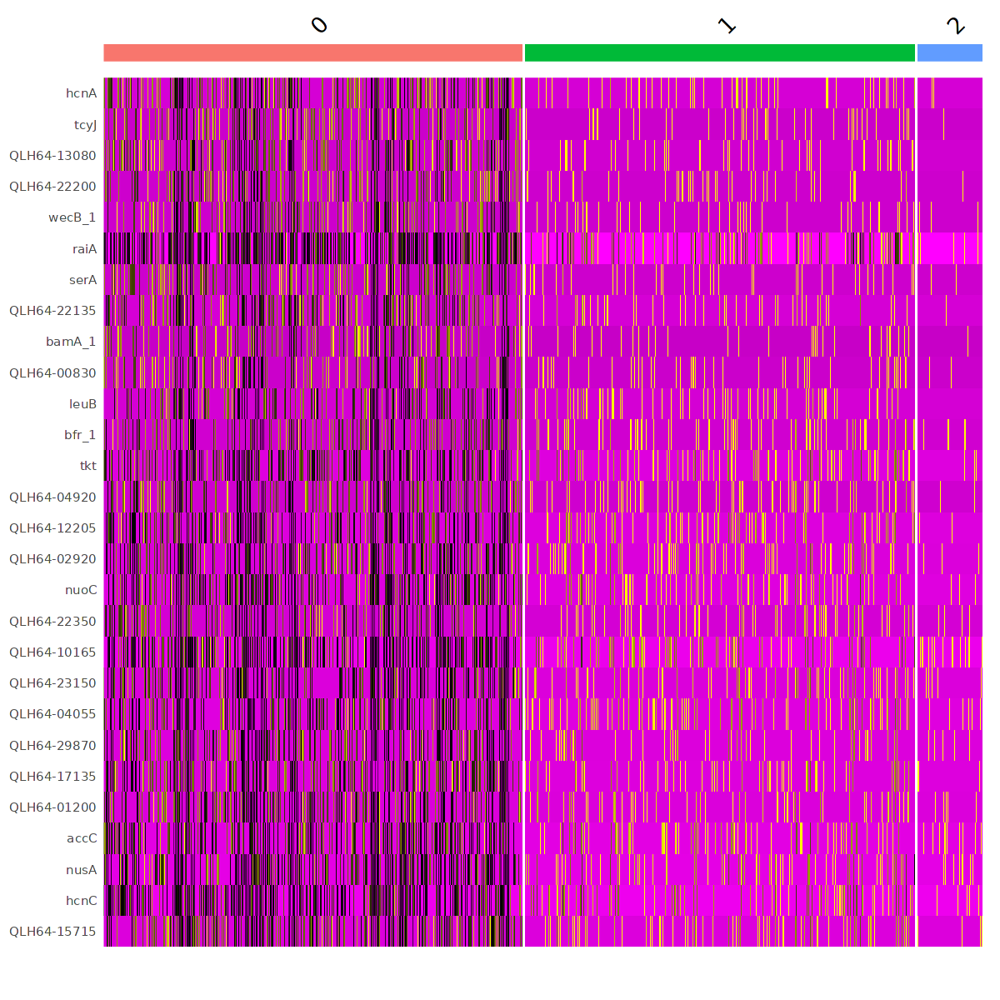

In [116]:
top_10_markers <- seurat_markers %>%
  group_by(cluster) %>%
  slice_max(n = 10, order_by = avg_log2FC)
DoHeatmap(seurat_obj, features = top_10_markers$gene) + NoLegend()

In [117]:
know_marker_genes <- c("raiA")
extracted_marker_genes <- top_2_markers$gene

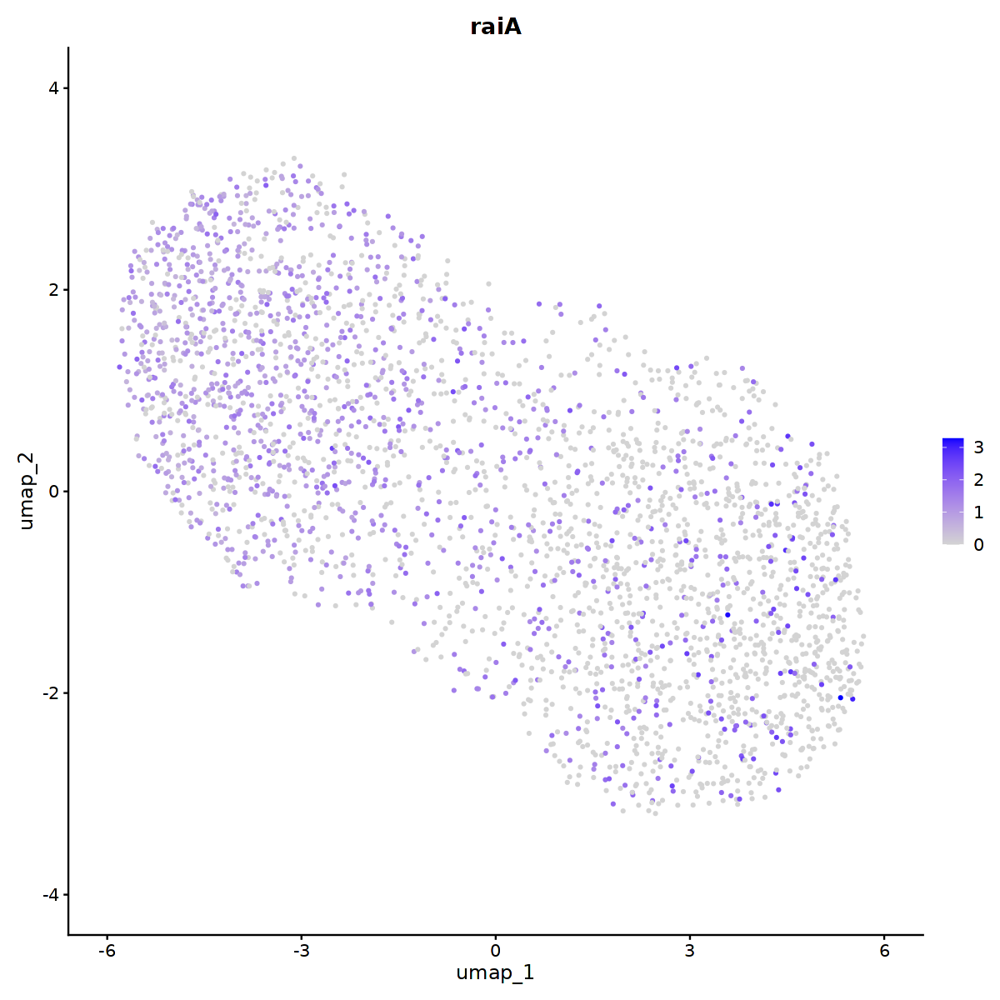

In [119]:
FeaturePlot(seurat_obj, features=know_marker_genes)

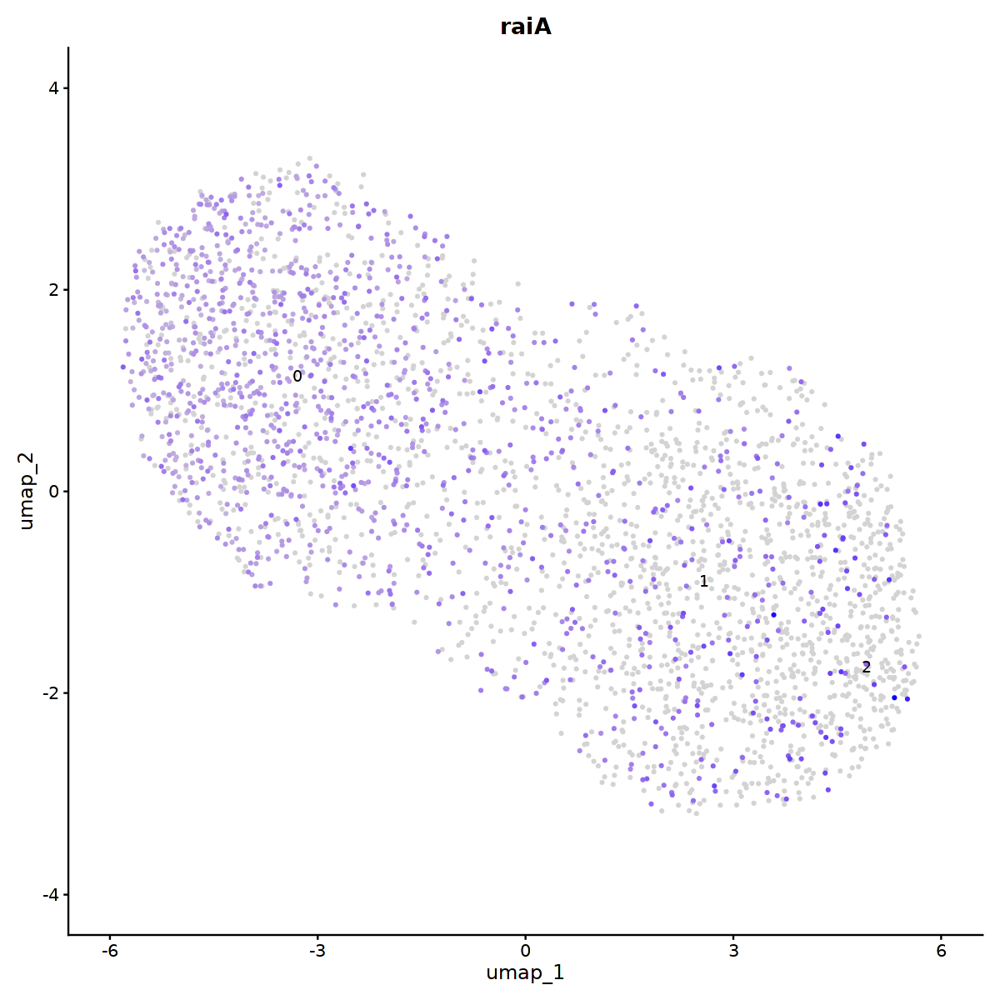

In [120]:
FeaturePlot(seurat_obj, features=know_marker_genes, order = TRUE, label = TRUE) & NoLegend()

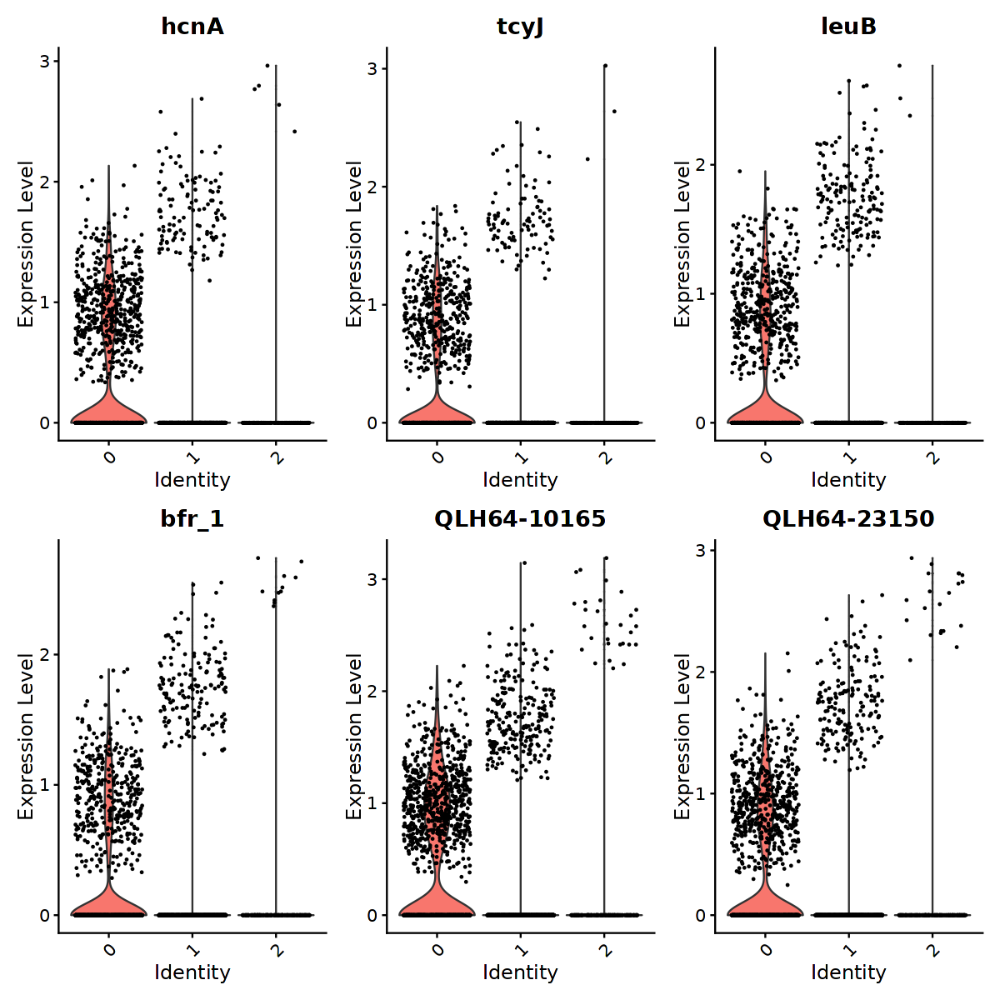

In [122]:
VlnPlot(seurat_obj, features = extracted_marker_genes[1:6])

In [124]:
VlnPlot(seurat_obj, features = extracted_marker_genes[7:12])

Warning message:
"The following requested variables were not found: NA"
Warning message:
"Removing 2934 cells missing data for vars requested"


ERROR: Error in plots[[i]]: subscript out of bounds


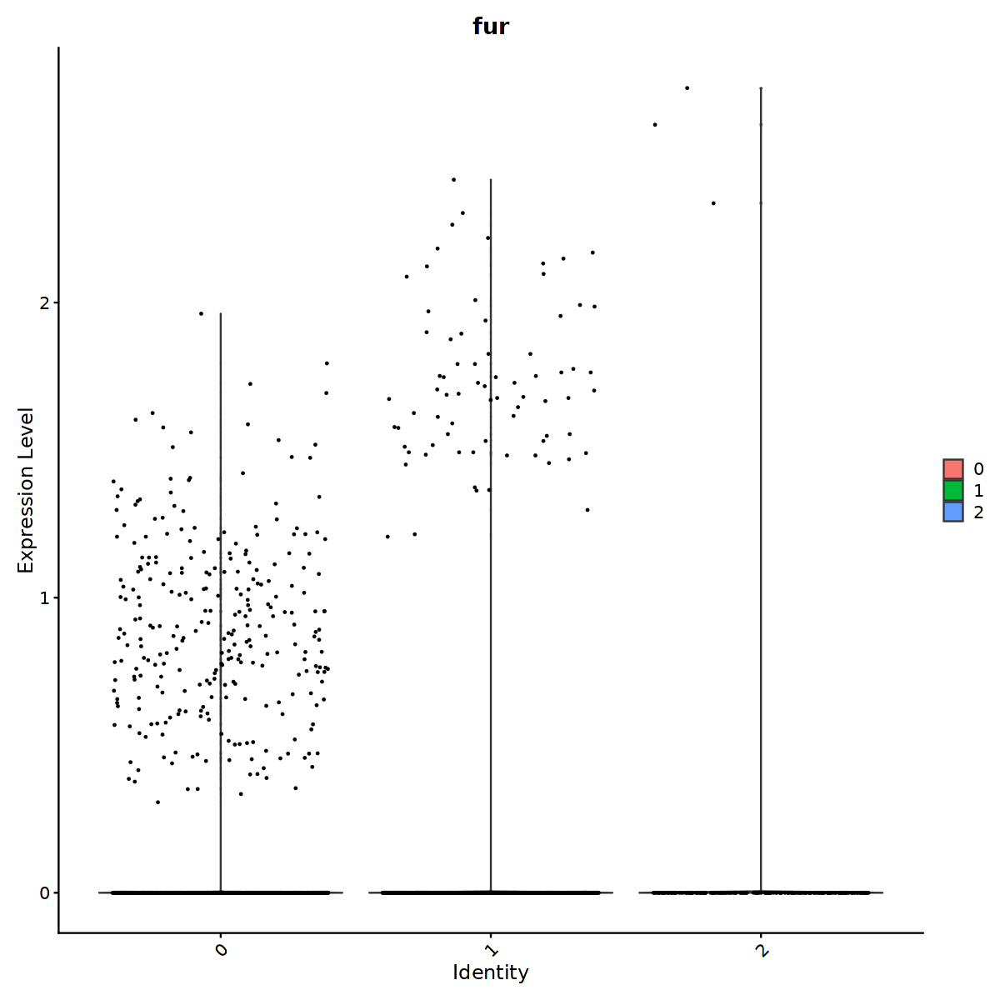

In [127]:
VlnPlot(seurat_obj, features = "fur")

Warning message:
"Scaling data with a low number of groups may produce misleading results"


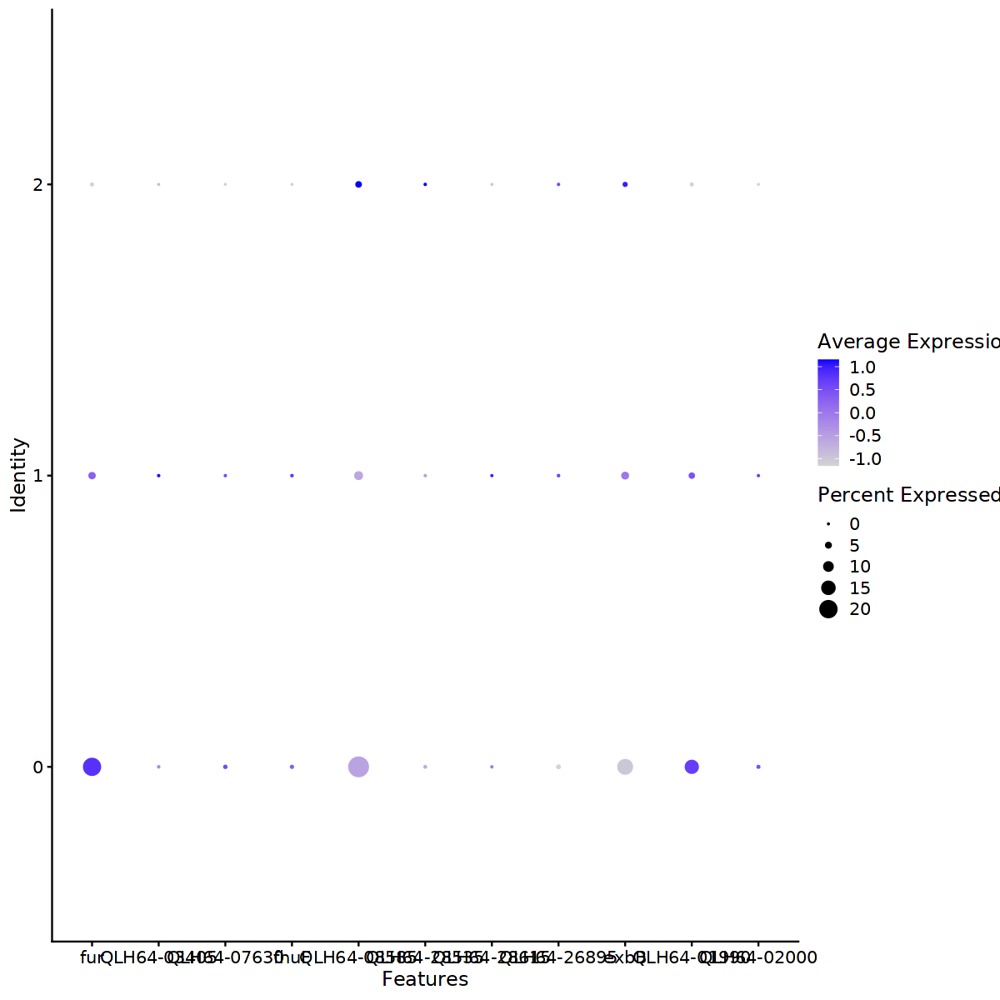

In [140]:
DotPlot(seurat_obj, features = c("fur","QLH64-03405", "QLH64-07630","fhuF","QLH64-08585","QLH64-28535", "QLH64-28615","QLH64-26895","exbB","QLH64-01990", "QLH64-02000"))

In [ ]:
new_cluster_ids <- c("Naive CD4 T", "CD14+ Mono", "Memory CD4 T", "B", "CD8 T", "FCGR3A+ Mono", "NK", "DC", "Platelet")
names(new_cluster_ids) <- levels(seurat_object)
seurat_object <- RenameIdents(seurat_object, new_cluster_ids)
DimPlot(seurat_object, reduction = "umap", label = TRUE, pt.size = 0.5) + NoLegend()

In [ ]:
# How many cells are in each cluster
table(Idents(seurat_object))

In [ ]:
# What proportion of cells are in each cluster?
prop.table(table(Idents(seurat_obj)))

In [ ]:
seurat_obj

In [141]:
dir.create("tests", showWarnings = FALSE)

saveRDS(seurat_obj, file = 'tests/seurat_workflow_analysis.rds')

# Test other parameters

In [142]:
#Normalisation
seurat_obj <- NormalizeData(seurat_obj, normalization.method = "LogNormalize", scale.factor = 1000)

#Find variable features
seurat_obj <- FindVariableFeatures(seurat_obj, selection.method = "vst", nfeatures = 1000)

Normalizing layer: counts

Finding variable features for layer counts



[1] "QLH64-12320" "QLH64-17820" "QLH64-24590" "QLH64-08635" "QLH64-22445"
 [6] "fabF_1"      "QLH64-19950" "QLH64-25710" "QLH64-08350" "QLH64-10015"

[1] "QLH64-12320" "QLH64-17820" "QLH64-24590" "QLH64-08635" "QLH64-22445"
 [6] "fabF_1"      "QLH64-19950" "QLH64-25710" "QLH64-08350" "QLH64-10015"
[11] "QLH64-25430" "QLH64-23710" "QLH64-05015" "QLH64-08330" "QLH64-13525"
[16] "QLH64-09505" "rbsK"        "QLH64-01895" "QLH64-01680" "QLH64-31020"
[21] "QLH64-02355" "QLH64-04585" "QLH64-07545" "QLH64-14525" "QLH64-06840"
[26] "folE2"       "QLH64-27370" "QLH64-05540" "QLH64-12600" "QLH64-23235"
[31] "QLH64-29360" "cysD"        "QLH64-29775" "QLH64-23980" "QLH64-04925"
[36] "QLH64-04060" "QLH64-04670" "QLH64-14995" "QLH64-06905" "QLH64-18745"
[41] "lpxH"        "cobA_1"      "QLH64-10530" "hpaA"        "QLH64-15090"
[46] "QLH64-16935" "QLH64-23730" "QLH64-26925" "QLH64-26610" "QLH64-27760"

When using repel, set xnudge and ynudge to 0 for optimal results



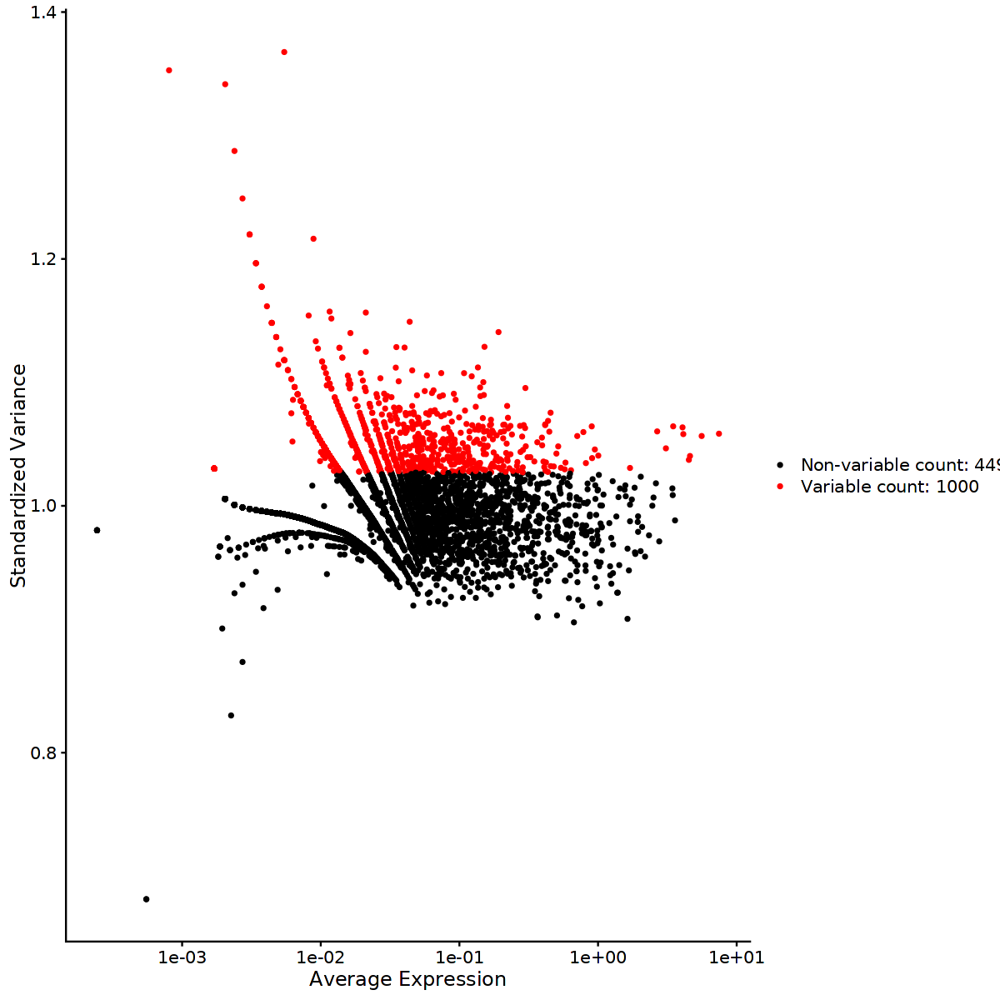

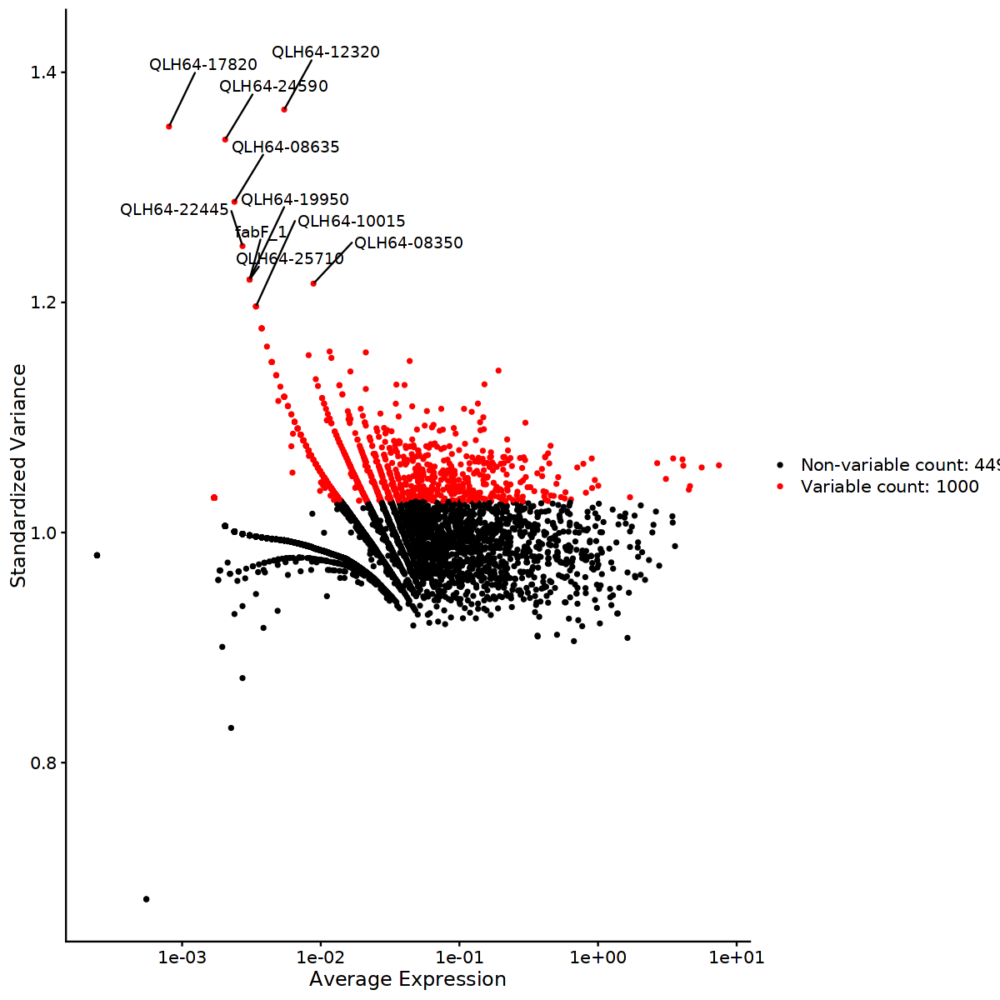

In [143]:
#Exploring variable features
top10 <- head(VariableFeatures(seurat_obj), n=10)
top10

top50 <- head(VariableFeatures(seurat_obj), n=50)
top50

var_feat_plot <- VariableFeaturePlot(seurat_obj)
var_feat_plot



var_feat_plot_labeled <- LabelPoints(plot = var_feat_plot, points = top10, repel = TRUE)
var_feat_plot_labeled 

In [144]:
gene_info  |> 
filter (final_gene_name %in% top10)


# gene_info  |> 
#filter (final_gene_name %in% top50)

seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
chromosome,CDS,with_protein,WHS55968.1,Gfo/Idh/MocA family oxidoreductase,NA,QLH64-08350,NA,QLH64_08350,FALSE,QLH64-08350,QLH64-08350
chromosome,CDS,with_protein,WHS56023.1,LysE family translocator,NA,QLH64-08635,NA,QLH64_08635,FALSE,QLH64-08635,QLH64-08635
chromosome,CDS,with_protein,WHS56272.1,beta-ketoacyl-ACP synthase II,fabF_1,QLH64-09935,fabF,QLH64_09935,TRUE,QLH64-09935,fabF_1
chromosome,CDS,with_protein,WHS56287.1,hypothetical protein,NA,QLH64-10015,NA,QLH64_10015,FALSE,QLH64-10015,QLH64-10015
chromosome,CDS,with_protein,WHS56729.1,hypothetical protein,NA,QLH64-12320,NA,QLH64_12320,FALSE,QLH64-12320,QLH64-12320
chromosome,CDS,with_protein,WHS52205.1,IS4 family transposase,NA,QLH64-17820,NA,QLH64_17820,FALSE,QLH64-17820,QLH64-17820
chromosome,CDS,with_protein,WHS52601.1,alginate biosynthesis protein Alg44,NA,QLH64-19950,NA,QLH64_19950,FALSE,QLH64-19950,QLH64-19950
chromosome,CDS,with_protein,WHS53064.1,MFS transporter,NA,QLH64-22445,NA,QLH64_22445,FALSE,QLH64-22445,QLH64-22445
chromosome,CDS,with_protein,WHS53470.1,amino acid ABC transporter permease,NA,QLH64-24590,NA,QLH64_24590,FALSE,QLH64-24590,QLH64-24590


In [145]:
# Scaling the data
all_genes <- rownames(seurat_obj)
seurat_obj <- ScaleData(seurat_obj, features = all_genes)

Centering and scaling data matrix



In [146]:
# Running PCA
seurat_obj <- RunPCA(seurat_obj, features = VariableFeatures(object = seurat_obj))
seurat_obj

PC_ 1 
Positive:  QLH64-19225, QLH64-02935, fusA, QLH64-26960, rpoC, QLH64-05400, QLH64-13705, QLH64-13720, icd, QLH64-13710 
	   QLH64-07480, QLH64-30060, rpsB, rplL, QLH64-19800, gltA, QLH64-31045, secA, QLH64-04320, QLH64-12185 
	   QLH64-24685, gltB, QLH64-12130, sdhA, QLH64-13080, tcyJ, leuA_2, QLH64-18250, QLH64-13345, QLH64-04480 
Negative:  QLH64-24105, gluQRS, QLH64-01365, QLH64-02630, choX_1, QLH64-05945, QLH64-30160, QLH64-20285, QLH64-15845, QLH64-06820 
	   QLH64-20500, QLH64-14500, QLH64-04220, QLH64-07875, gbcA, QLH64-26395, QLH64-10750, QLH64-08660, QLH64-09150, QLH64-00325 
	   QLH64-10570, QLH64-12960, QLH64-28180, QLH64-27515, QLH64-24355, QLH64-01295, QLH64-12340, QLH64-29715, QLH64-12900, QLH64-15415 
PC_ 2 
Positive:  QLH64-07335, QLH64-08810, gguB, fur, QLH64-02870, hldE, treS, QLH64-25445, iscR, hisC_2 
	   QLH64-13880, hisD, ftsY, QLH64-24695, QLH64-13700, guaD, QLH64-07370, QLH64-10420, mqo_2, QLH64-17790 
	   QLH64-19010, QLH64-27880, QLH64-13355, QLH64-29075

An object of class Seurat 
5491 features across 2934 samples within 1 assay 
Active assay: RNA (5491 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

In [ ]:
# Display PCA results
print(seurat_obj[["pca"]], dims = 1:15, nfeatures = 10)

PC_ 1 
Positive:  QLH64-19225, QLH64-02935, fusA, QLH64-26960, rpoC, QLH64-05400, QLH64-13705, QLH64-13720, icd, QLH64-13710 
Negative:  QLH64-24105, gluQRS, QLH64-01365, QLH64-02630, choX_1, QLH64-05945, QLH64-30160, QLH64-20285, QLH64-15845, QLH64-06820 
PC_ 2 
Positive:  QLH64-07335, QLH64-08810, gguB, fur, QLH64-02870, hldE, treS, QLH64-25445, iscR, hisC_2 
Negative:  QLH64-30905, QLH64-26220, QLH64-16885, rpsJ, topA, QLH64-09265, QLH64-22950, QLH64-01920, QLH64-01890, QLH64-25595 
PC_ 3 
Positive:  QLH64-06520, QLH64-00535, QLH64-19010, QLH64-18305, serA, QLH64-12075, QLH64-02655, QLH64-29030, panB, QLH64-18375 
Negative:  QLH64-14565, QLH64-19860, QLH64-19920, QLH64-22950, QLH64-22670, ndk, hemE, QLH64-07340, QLH64-07370, pilQ 
PC_ 4 
Positive:  QLH64-00395, QLH64-03650, QLH64-25830, QLH64-06520, pilB, cmk, nagZ, QLH64-16795, QLH64-15200, QLH64-13355 
Negative:  hisD, QLH64-24105, QLH64-25260, gyrB, QLH64-29075, QLH64-23255, QLH64-04295, ccoP_1, guaD, QLH64-23480 
PC_ 5 
Positive

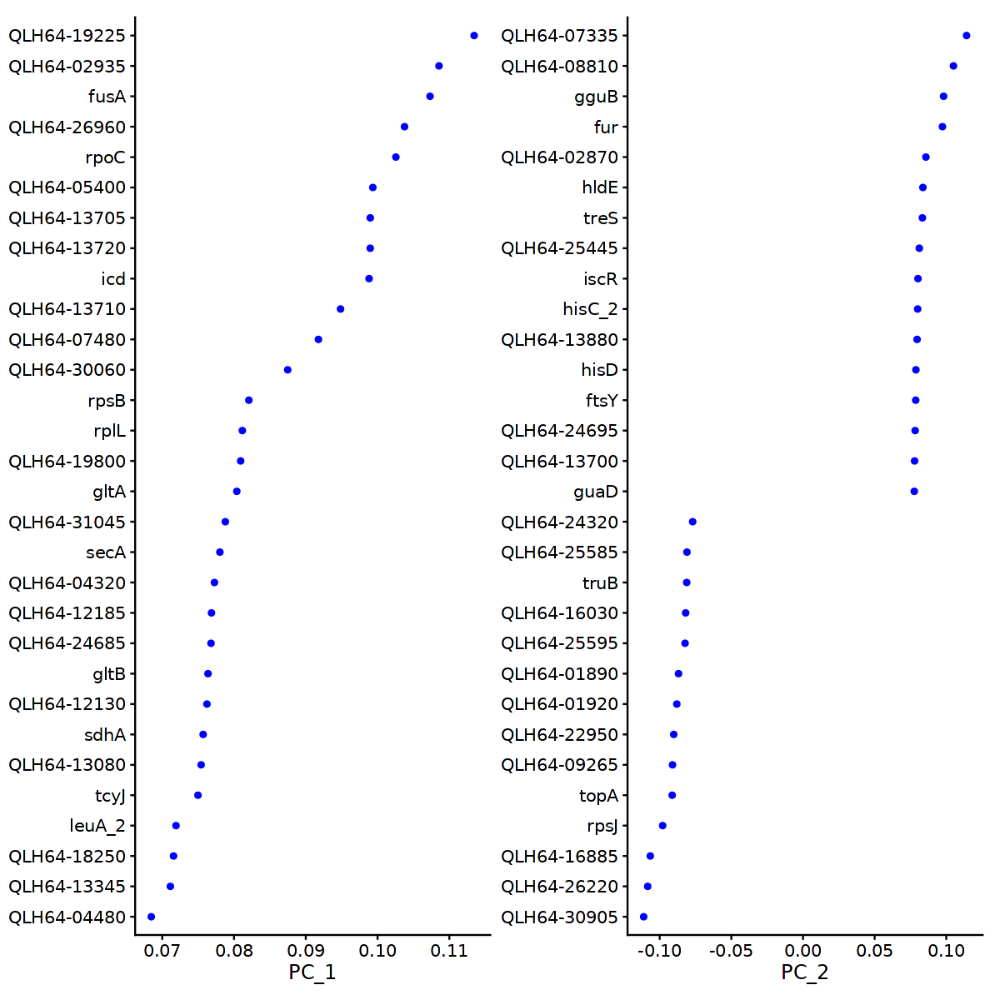

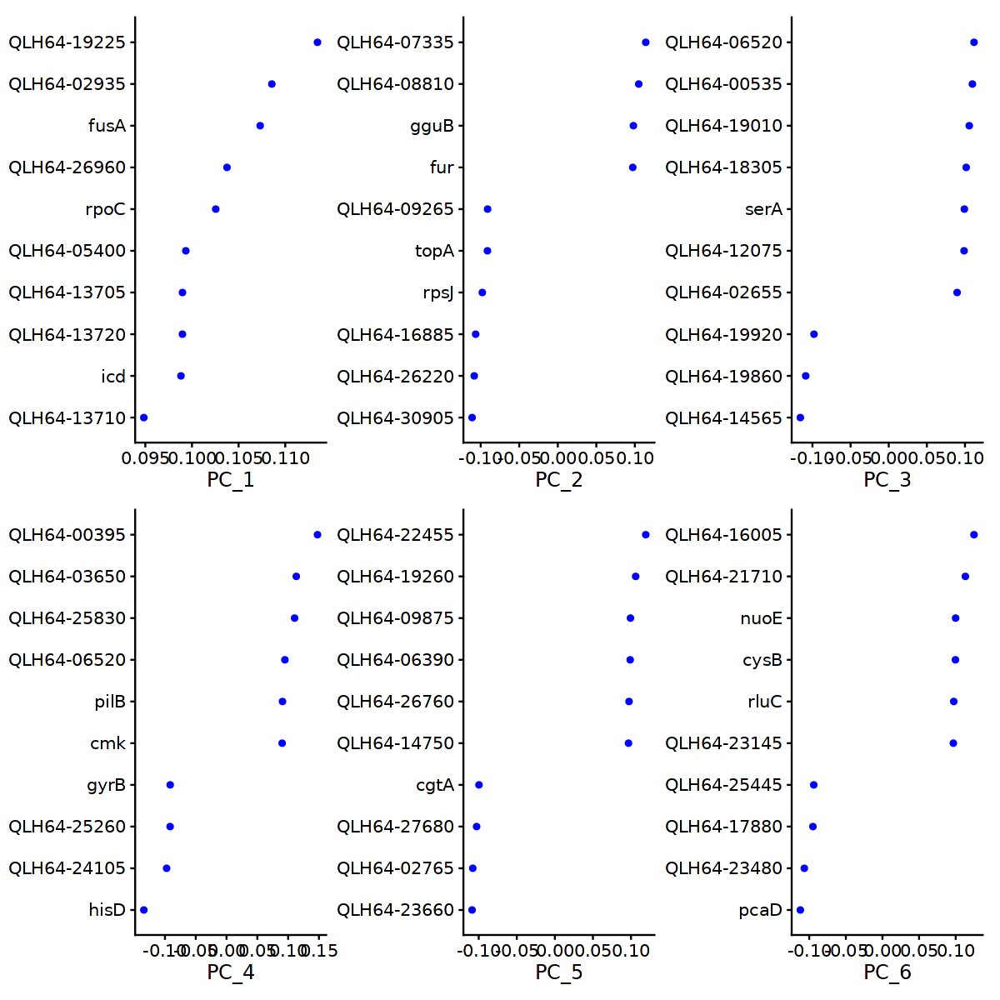

In [149]:
VizDimLoadings(seurat_obj, dims = 1:2)
VizDimLoadings(seurat_obj, dims = 1:6, reduction = "pca", ncol = 3, nfeature=10)

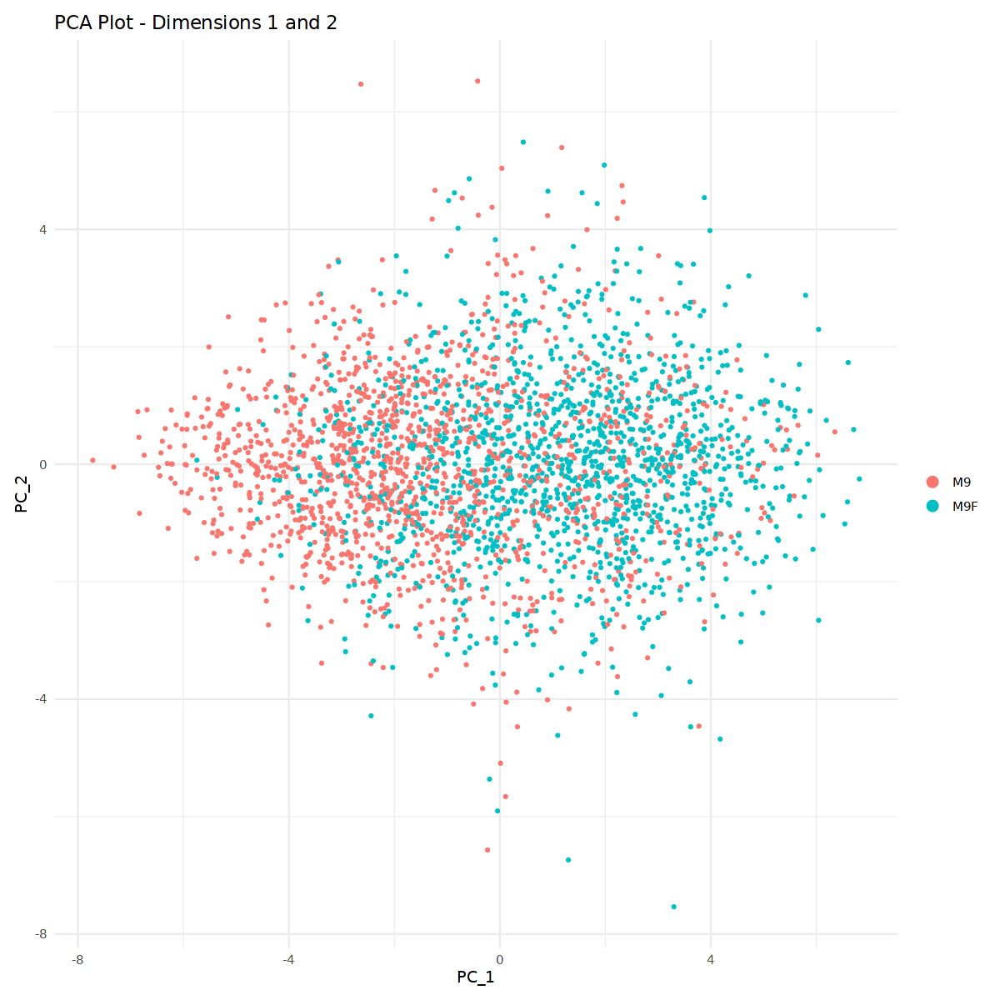

In [150]:
DimPlot(seurat_obj, reduction = "pca", dims = 1:2, group.by = "Culture_medium") +
  ggtitle("PCA Plot - Dimensions 1 and 2") +
  theme_minimal()

Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


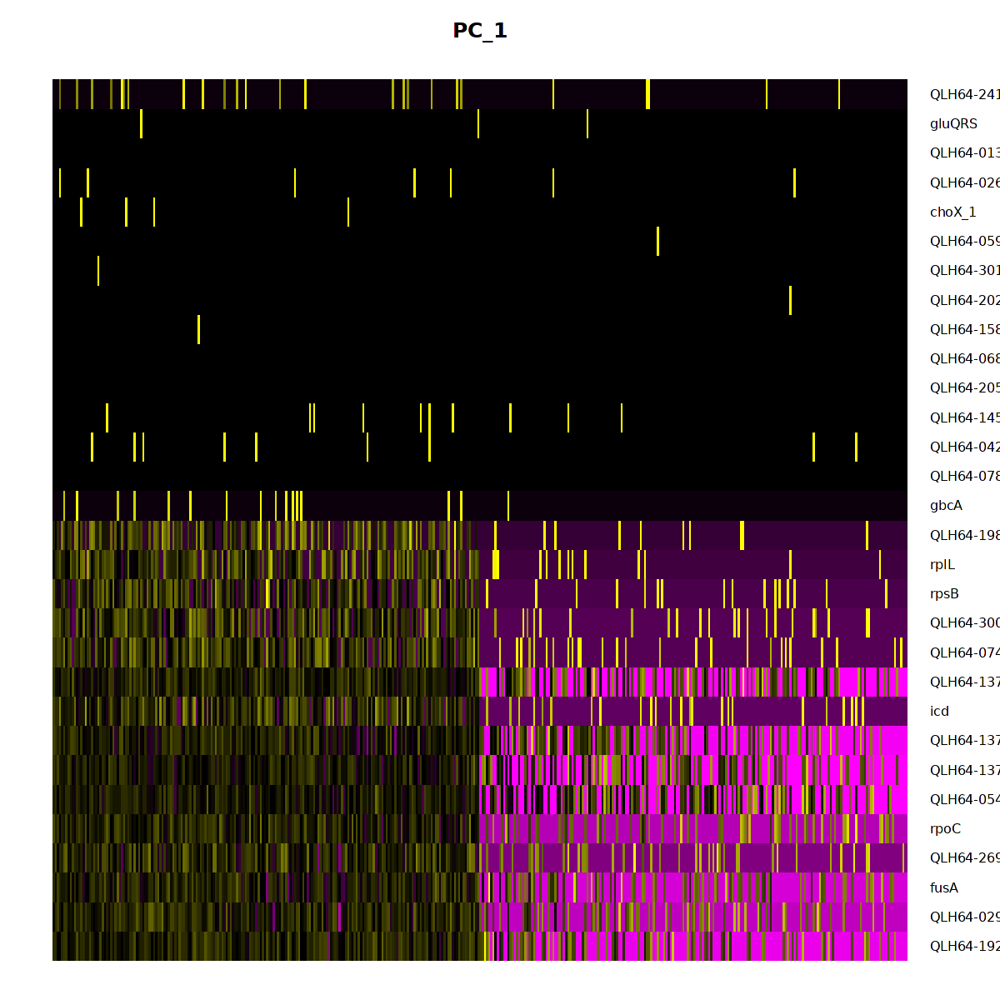

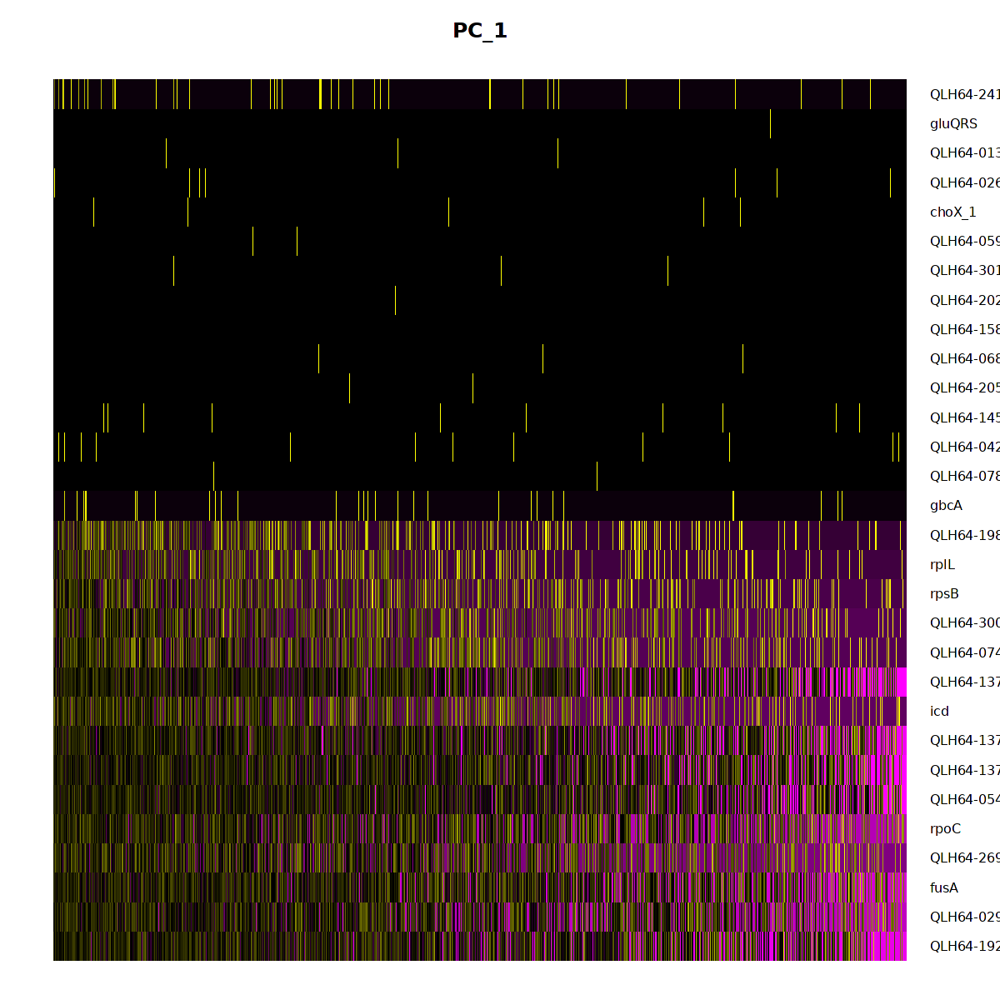

In [151]:
#options(repr.plot.width = 10, repr.plot.height = 10)
DimHeatmap(seurat_obj, dims = 1, cells = 400, balanced = TRUE)
DimHeatmap(seurat_obj, dims = 1, cells = 4000, balanced = TRUE)

# on peut mettre 4000 cells pour voir toutes les cellules 

In [ ]:
DimHeatmap(seurat_obj, dims = 1:6, cells = 400, balanced = TRUE, ncol = 3)

In [152]:
#Loadings(seurat_obj[["pca"]])[, 1]

# Loadings = contribution de chaque gène à chaque dimension
loadings <- Loadings(seurat_obj[["pca"]])

# PCA 1
loadings_pca1 <- loadings[, 1]

# Top 10 positifs (jaune)
top_positive_genes <- sort(loadings_pca1, decreasing = TRUE)[1:10]

# Top 10 négatifs (violet)
top_negative_genes <- sort(loadings_pca1, decreasing = FALSE)[1:10]

# Gènes les plus neutres (noirs) = valeurs proches de 0
threshold <- 0.001  # Tu peux ajuster
neutral_genes <- loadings_pca1[abs(loadings_pca1) < threshold]

print("Top 10 genes fortement positifs (jaune) :")
print(top_positive_genes)

print("Top 10 genes fortement négatifs (violet) :")
print(top_negative_genes)

print("Genes proches de 0 (noirs) :")
head(neutral_genes, 10)  # Affiche les 10 premiers

# 3. Regrouper dans une liste R nommée
gene_lists <- list(
  jaune = top_positive_genes,
  violet = top_negative_genes,
  noir = neutral_genes
)

# Afficher
str(gene_lists)



[1] "Top 10 genes fortement positifs (jaune) :"
QLH64-19225 QLH64-02935        fusA QLH64-26960        rpoC QLH64-05400 
 0.11345844  0.10856355  0.10731199  0.10375446  0.10255077  0.09934097 
QLH64-13705 QLH64-13720         icd QLH64-13710 
 0.09898066  0.09897740  0.09881960  0.09483997 
[1] "Top 10 genes fortement n<U+00E9>gatifs (violet) :"
  QLH64-24105        gluQRS   QLH64-01365   QLH64-02630        choX_1 
-4.233608e-03 -1.099687e-03 -9.453720e-04 -5.189788e-04  9.962521e-05 
  QLH64-05945   QLH64-30160   QLH64-20285   QLH64-15845   QLH64-06820 
 1.852823e-04  1.069535e-03  1.366895e-03  1.500641e-03  1.546021e-03 
[1] "Genes proches de 0 (noirs) :"


choX_1   QLH64-02630   QLH64-01365   QLH64-05945 
 9.962521e-05 -5.189788e-04 -9.453720e-04  1.852823e-04

List of 3
 $ jaune : Named num [1:10] 0.113 0.109 0.107 0.104 0.103 ...
  ..- attr(*, "names")= chr [1:10] "QLH64-19225" "QLH64-02935" "fusA" "QLH64-26960" ...
 $ violet: Named num [1:10] -4.23e-03 -1.10e-03 -9.45e-04 -5.19e-04 9.96e-05 ...
  ..- attr(*, "names")= chr [1:10] "QLH64-24105" "gluQRS" "QLH64-01365" "QLH64-02630" ...
 $ noir  : Named num [1:4] 9.96e-05 -5.19e-04 -9.45e-04 1.85e-04
  ..- attr(*, "names")= chr [1:4] "choX_1" "QLH64-02630" "QLH64-01365" "QLH64-05945"


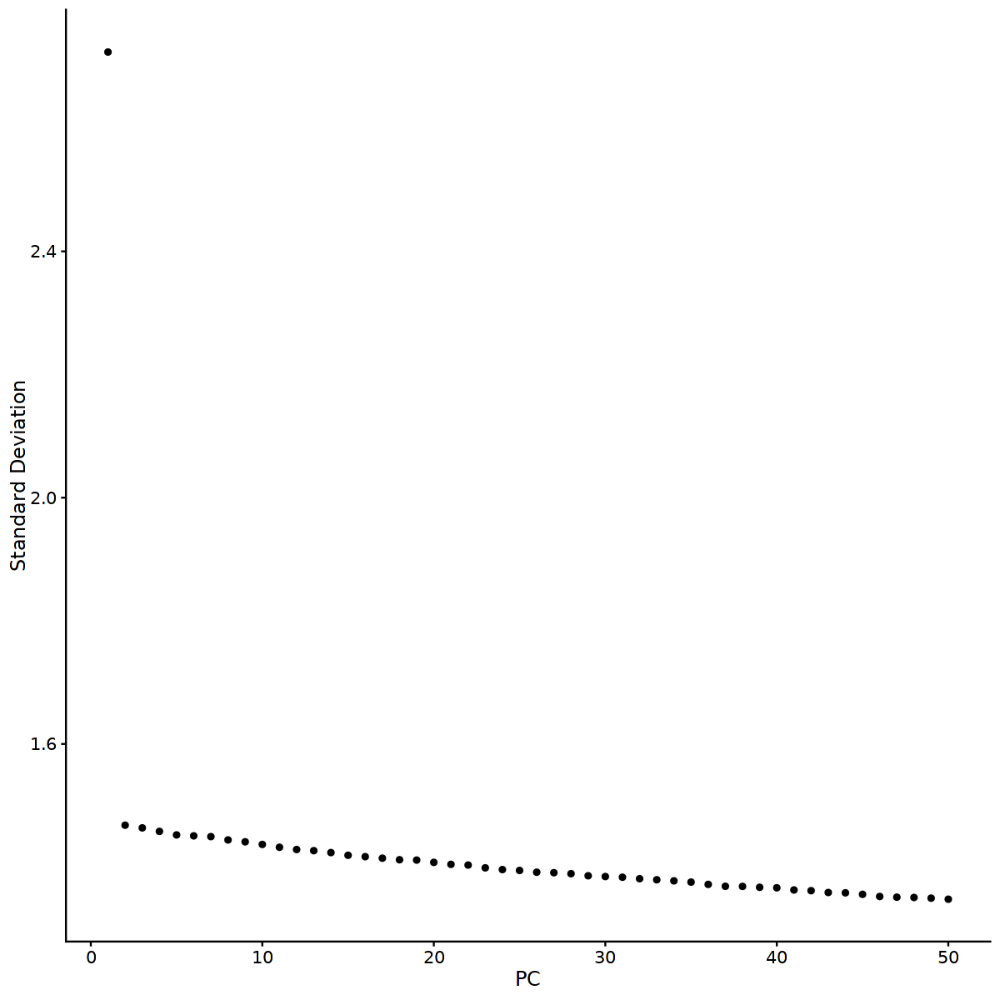

In [170]:
ElbowPlot(seurat_obj, 50)

In [155]:
#Clustering
seurat_obj <- FindNeighbors(seurat_obj, dims = 1:10)
seurat_obj <- FindClusters(seurat_obj, resolution = 0.5)


Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 92330

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6905
Number of communities: 3
Elapsed time: 0 seconds


In [156]:
head(Idents(seurat_obj), 10)
seurat_obj <- RunUMAP(seurat_obj, 1:10)

GTACGCAA_AACCGAGA_AAACGATA CGGATTGC_AACGCTTA_AAACGATA 
                         0                          0 
CGCTGATC_AACGTGAT_AAACGATA GCTAACGA_AAGAGATC_AAACGATA 
                         0                          1 
CCTCTATC_AAGGACAC_AAACGATA GTGTTCTA_ACACAGAA_AAACGATA 
                         0                          1 
ACAGATTC_ACAGATTC_AAACGATA CAAGACTA_ACATTGGC_AAACGATA 
                         0                          0 
CCGTGAGA_ACCACTGT_AAACGATA ACTATGCA_AGTACAAG_AAACGATA 
                         0                          0 
Levels: 0 1 2

13:45:34 UMAP embedding parameters a = 0.9922 b = 1.112

13:45:34 Read 2934 rows and found 10 numeric columns

13:45:34 Using Annoy for neighbor search, n_neighbors = 30

13:45:34 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

13:45:34 Writing NN index file to temp file /tmp/RtmpoxfOPx/file3bc76f2d500

13:45:34 Searching Annoy index using 1 thread, search_k = 3000

13:45:35 Annoy recall = 100%

13:45:37 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

13:45:38 Initializing from normalized Laplacian + noise (using RSpectra)

13:45:38 Commencing optimization for 500 epochs, with 114016 positive edges

13:45:38 Using rng type: pcg

13:45:41 Optimization finished



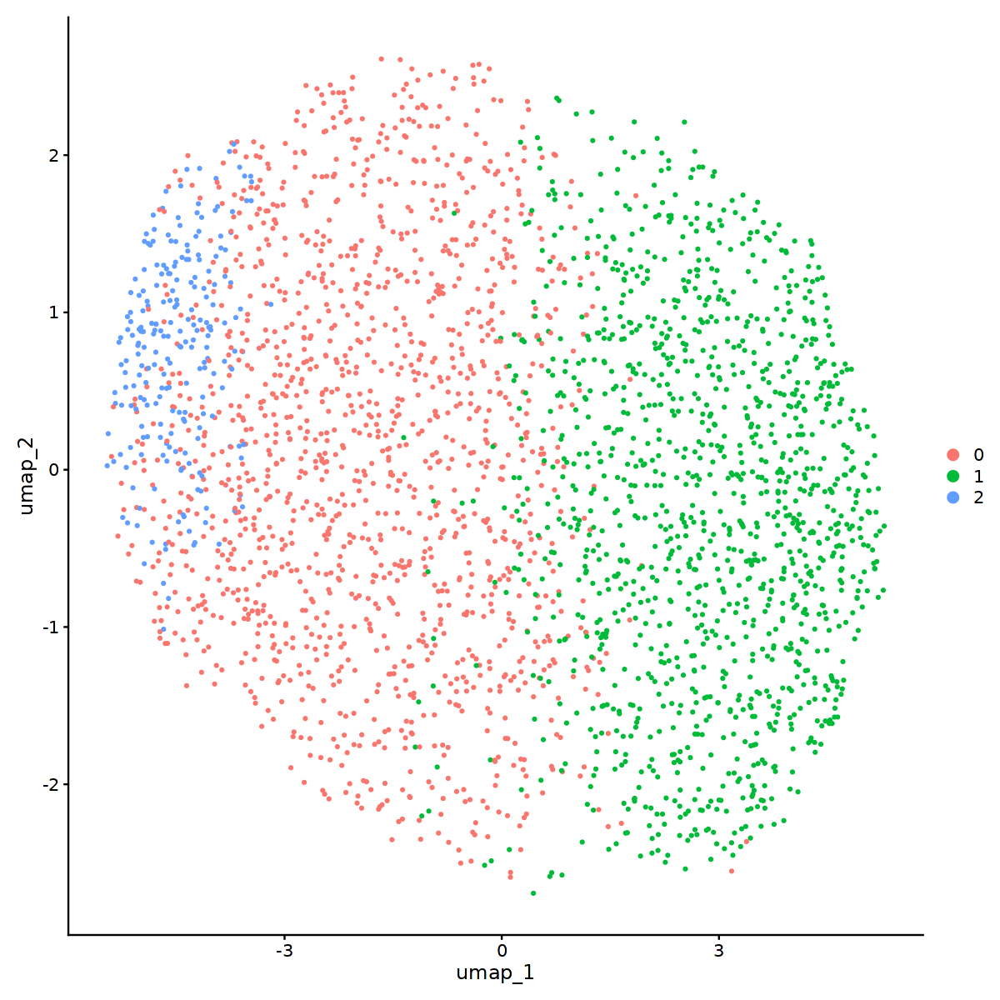

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2



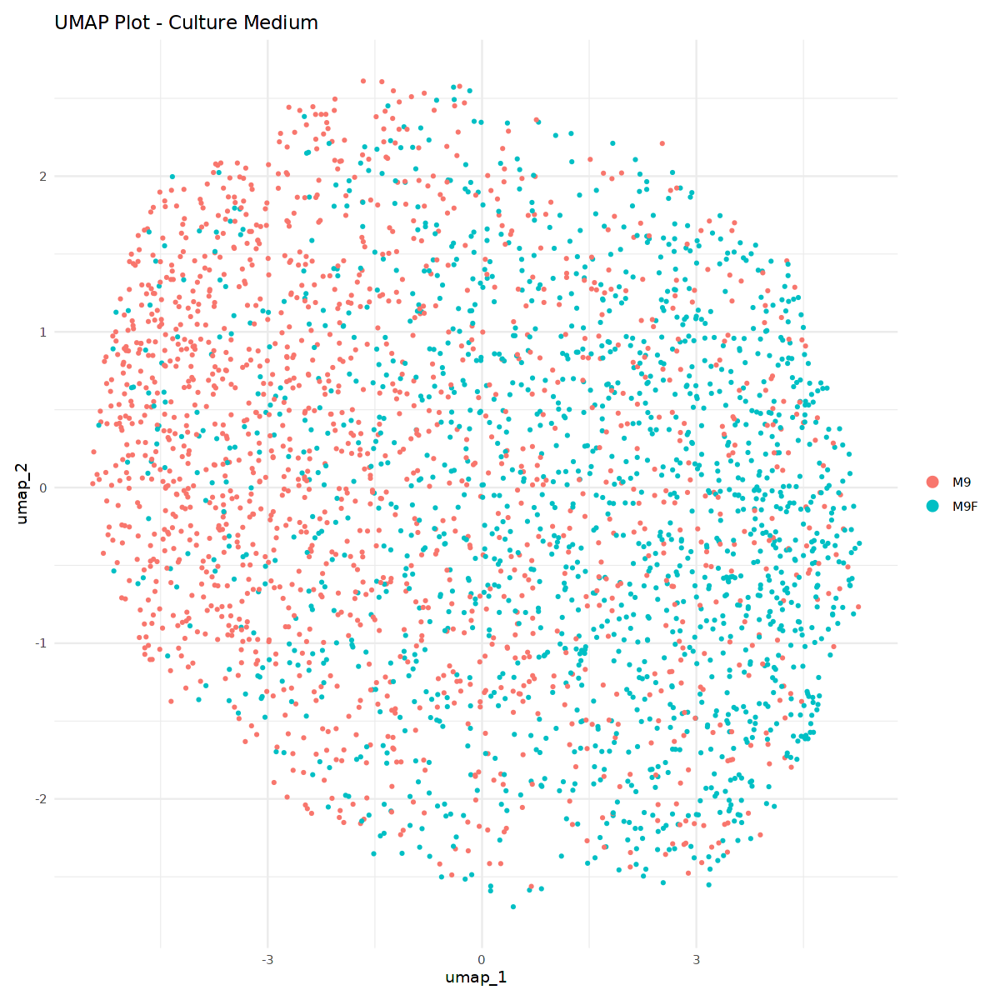

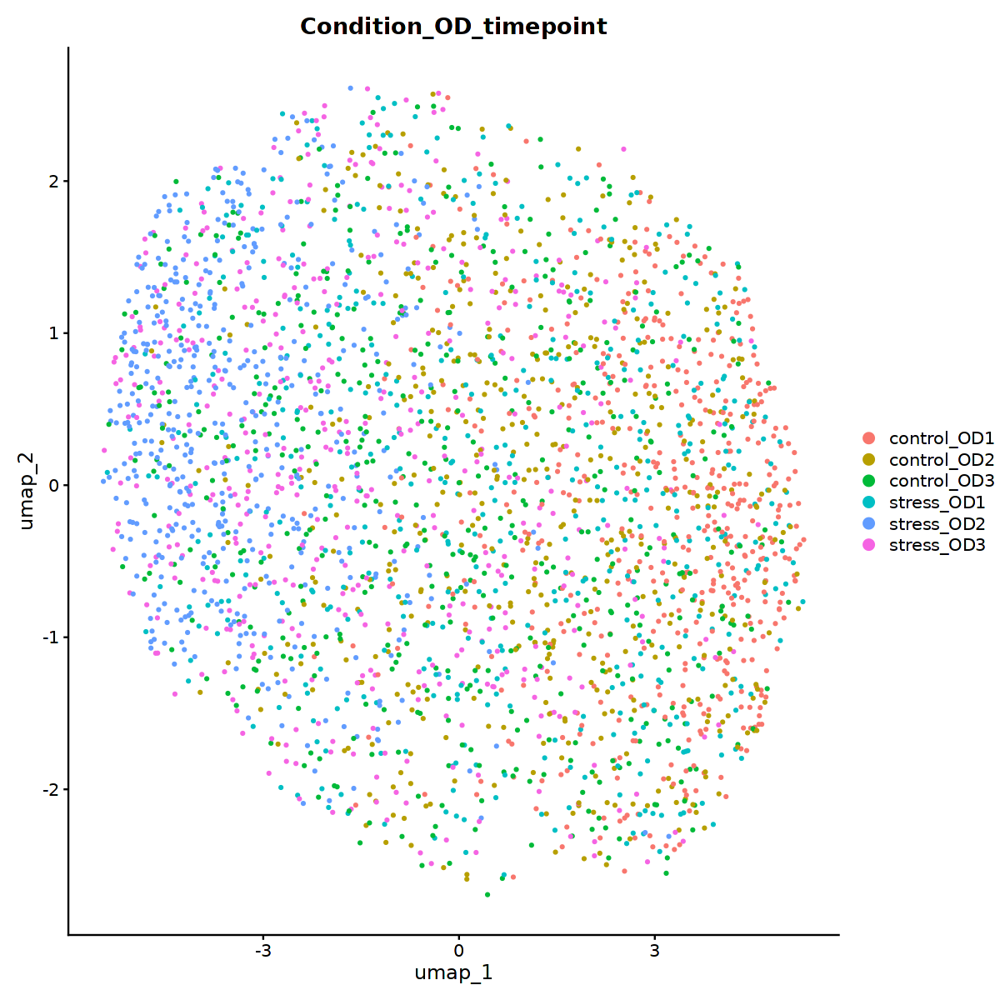

In [157]:
DimPlot(seurat_obj, reduction = "umap")
DimPlot(seurat_obj, reduction = "umap", group.by = "Culture_medium") +
  ggtitle("UMAP Plot - Culture Medium") +
  theme_minimal()
seurat_markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, min.pct = 0.25, logfc.threshold = 0.25)
DimPlot(seurat_obj, reduction = "umap", group.by = "Condition_OD_timepoint")

In [158]:

top_2_markers <- seurat_markers %>%
  group_by(cluster) %>%
  slice_max(n = 2, order_by = avg_log2FC)
top_2_markers

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
1.500918e-10,0.3625262,0.131,0.253,8.241539e-07,0,bfr_1
3.716496e-11,0.3383331,0.138,0.269,2.040728e-07,0,purL
1.268572e-49,0.5412335,0.299,0.071,6.965729e-46,1,tcyJ
4.176301e-41,0.5117529,0.255,0.063,2.293207e-37,1,tal
2.442384e-06,0.9335738,0.096,0.263,1.341113e-02,2,QLH64-29870
1.831926e-05,0.8635595,0.148,0.338,1.005910e-01,2,QLH64-10165


In [159]:
gene_info  |> 
  filter(final_gene_name %in% top_2_markers$gene) 

seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
chromosome,CDS,with_protein,WHS55505.1,transaldolase,tal,QLH64-05915,tal,QLH64_05915,FALSE,QLH64-05915,tal
chromosome,CDS,with_protein,WHS56315.1,alpha/beta hydrolase,NA,QLH64-10165,NA,QLH64_10165,FALSE,QLH64-10165,QLH64-10165
chromosome,CDS,with_protein,WHS52409.1,bacterioferritin,bfr_1,QLH64-18935,bfr,QLH64_18935,TRUE,QLH64-18935,bfr_1
chromosome,CDS,with_protein,WHS57241.1,phosphoribosylformylglycinamidine synthase,purL,QLH64-19725,purL,QLH64_19725,FALSE,QLH64-19725,purL
chromosome,CDS,with_protein,WHS53978.1,cystine ABC transporter substrate-binding protein,tcyJ,QLH64-27290,tcyJ,QLH64_27290,FALSE,QLH64-27290,tcyJ
plasmid,CDS,with_protein,WHS57561.1,hypothetical protein,NA,QLH64-29870,NA,QLH64_29870,FALSE,QLH64-29870,QLH64-29870


In [160]:
cluster_0_vs_cluster_1 <- FindMarkers(seurat_obj, ident.1 = 0, ident.2 = 1, min.pct = 0.25)
head(cluster_0_vs_cluster_1, n=10)

# extract col1 of cluster_0_vs_cluster_1

gene_info  |> 
  filter(final_gene_name %in% head(rownames(cluster_0_vs_cluster_1), 10))


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
raiA,3.419000e-48,-0.3661456,0.231,0.630,1.877373e-44
QLH64-17135,2.165277e-44,-0.2494355,0.132,0.422,1.188954e-40
QLH64-31045,7.875585e-43,-0.2227619,0.166,0.484,4.324484e-39
tcyJ,7.614259e-41,-0.5247088,0.078,0.299,4.180989e-37
QLH64-19800,2.862779e-40,-0.2185275,0.165,0.472,1.571952e-36
QLH64-06170,2.887942e-40,-0.1975495,0.139,0.422,1.585769e-36
hflK,3.358190e-40,-0.2043287,0.188,0.518,1.843982e-36
tssH_2,3.524599e-40,-0.2989837,0.137,0.415,1.935357e-36
QLH64-10165,5.067610e-40,-0.1623187,0.184,0.509,2.782625e-36


seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
chromosome,CDS,with_protein,WHS54597.1,ribosome-associated translation inhibitor RaiA,raiA,QLH64-01075,raiA,QLH64_01075,FALSE,QLH64-01075,raiA
chromosome,CDS,with_protein,WHS55552.1,HU family DNA-binding protein,NA,QLH64-06170,NA,QLH64_06170,FALSE,QLH64-06170,QLH64-06170
chromosome,CDS,with_protein,WHS56315.1,alpha/beta hydrolase,NA,QLH64-10165,NA,QLH64_10165,FALSE,QLH64-10165,QLH64-10165
chromosome,CDS,with_protein,WHS52077.1,acyl-CoA dehydrogenase,NA,QLH64-17135,NA,QLH64_17135,FALSE,QLH64-17135,QLH64-17135
chromosome,CDS,with_protein,WHS52572.1,HU family DNA-binding protein,NA,QLH64-19800,NA,QLH64_19800,FALSE,QLH64-19800,QLH64-19800
chromosome,CDS,with_protein,WHS53587.1,type VI secretion system ATPase TssH,tssH_2,QLH64-25225,tssH,QLH64_25225,TRUE,QLH64-25225,tssH_2
chromosome,CDS,with_protein,WHS53978.1,cystine ABC transporter substrate-binding protein,tcyJ,QLH64-27290,tcyJ,QLH64_27290,FALSE,QLH64-27290,tcyJ
chromosome,CDS,with_protein,WHS54261.1,FtsH protease activity modulator HflK,hflK,QLH64-28805,hflK,QLH64_28805,FALSE,QLH64-28805,hflK
plasmid,CDS,with_protein,WHS57561.1,hypothetical protein,NA,QLH64-29870,NA,QLH64_29870,FALSE,QLH64-29870,QLH64-29870


In [161]:
cluster_0_vs_cluster_2 <- FindMarkers(seurat_obj, ident.1 = 0, ident.2 = 2, min.pct = 0.25)
head(cluster_0_vs_cluster_2, n=10)

# extract col1 of cluster_0_vs_cluster_2

gene_info  |> 
  filter(final_gene_name %in% head(rownames(cluster_0_vs_cluster_2), 10))

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
QLH64-03465,4.154619e-10,0.5490394,0.404,0.140,2.281301e-06
QLH64-05310,1.348653e-09,0.2749526,0.519,0.210,7.405453e-06
icd,1.806770e-09,0.3785742,0.359,0.118,9.920973e-06
QLH64-12435,1.850249e-09,0.2808587,0.404,0.144,1.015972e-05
tssC_2,3.569356e-09,0.2563021,0.414,0.153,1.959934e-05
QLH64-27050,1.372033e-08,0.4329348,0.349,0.122,7.533832e-05
QLH64-26960,1.887454e-08,0.2184666,0.541,0.236,1.036401e-04
QLH64-28090,2.322265e-08,0.1999319,0.560,0.253,1.275156e-04
QLH64-19225,3.296962e-08,0.2938334,0.832,0.441,1.810362e-04


seq_type,feature,class,product_accession,name,symbol,locus_tag,symbol_old,locus_tag_old,symbol_renamed,locus_tag_a,final_gene_name
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>
chromosome,CDS,with_protein,WHS57120.1,hypothetical protein,NA,QLH64-03465,NA,QLH64_03465,FALSE,QLH64-03465,QLH64-03465
chromosome,CDS,with_protein,WHS55389.1,non-ribosomal peptide synthetase,NA,QLH64-05310,NA,QLH64_05310,FALSE,QLH64-05310,QLH64-05310
chromosome,CDS,with_protein,WHS55743.1,NADP-dependent isocitrate dehydrogenase,icd,QLH64-07160,icd,QLH64_07160,FALSE,QLH64-07160,icd
chromosome,CDS,with_protein,WHS56751.1,AidA/PixA family protein,NA,QLH64-12435,NA,QLH64_12435,FALSE,QLH64-12435,QLH64-12435
chromosome,CDS,with_protein,WHS52462.1,OprD family porin,NA,QLH64-19225,NA,QLH64_19225,FALSE,QLH64-19225,QLH64-19225
chromosome,CDS,with_protein,WHS53142.1,DNA-directed RNA polymerase subunit beta',rpoC,QLH64-22835,rpoC,QLH64_22835,FALSE,QLH64-22835,rpoC
chromosome,CDS,with_protein,WHS53580.1,type VI secretion system contractile sheath large subunit,tssC_2,QLH64-25190,tssC,QLH64_25190,TRUE,QLH64-25190,tssC_2
chromosome,CDS,with_protein,WHS53912.1,retention module-containing protein,NA,QLH64-26960,NA,QLH64_26960,FALSE,QLH64-26960,QLH64-26960
chromosome,CDS,with_protein,WHS53930.1,tail fiber protein,NA,QLH64-27050,NA,QLH64_27050,FALSE,QLH64-27050,QLH64-27050


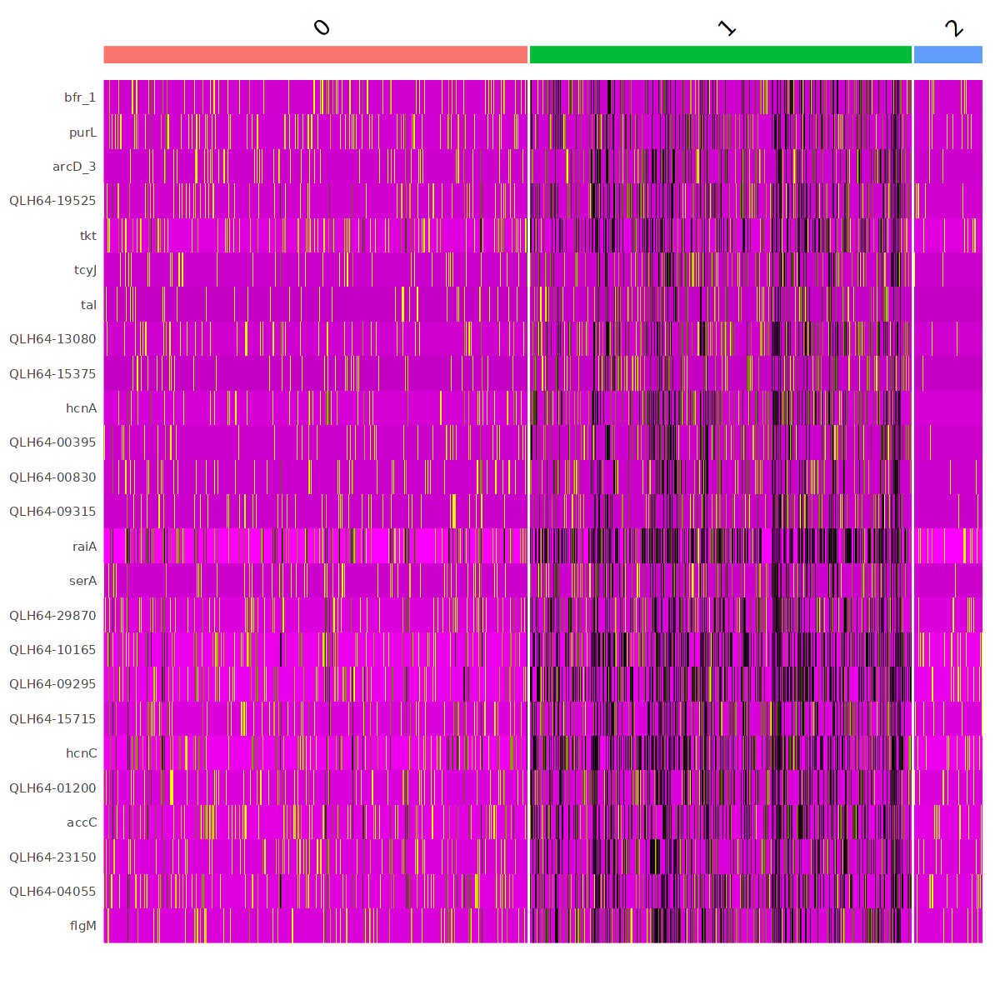

In [162]:
top_10_markers <- seurat_markers %>%
  group_by(cluster) %>%
  slice_max(n = 10, order_by = avg_log2FC)
DoHeatmap(seurat_obj, features = top_10_markers$gene) + NoLegend()

# test 3 : change les dim pour cluster 

In [164]:
#Clustering
seurat_obj <- FindNeighbors(seurat_obj, dims = 1:2)
seurat_obj <- FindClusters(seurat_obj, resolution = 0.5)

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 66242

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8846
Number of communities: 10
Elapsed time: 0 seconds


In [165]:
head(Idents(seurat_obj), 10)
seurat_obj <- RunUMAP(seurat_obj, 1:2)

GTACGCAA_AACCGAGA_AAACGATA CGGATTGC_AACGCTTA_AAACGATA 
                         5                          1 
CGCTGATC_AACGTGAT_AAACGATA GCTAACGA_AAGAGATC_AAACGATA 
                         1                          0 
CCTCTATC_AAGGACAC_AAACGATA GTGTTCTA_ACACAGAA_AAACGATA 
                         5                          0 
ACAGATTC_ACAGATTC_AAACGATA CAAGACTA_ACATTGGC_AAACGATA 
                         1                          9 
CCGTGAGA_ACCACTGT_AAACGATA ACTATGCA_AGTACAAG_AAACGATA 
                         1                          5 
Levels: 0 1 2 3 4 5 6 7 8 9

13:50:52 UMAP embedding parameters a = 0.9922 b = 1.112

13:50:52 Read 2934 rows and found 2 numeric columns

13:50:52 Using Annoy for neighbor search, n_neighbors = 30

13:50:52 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

13:50:52 Writing NN index file to temp file /tmp/RtmpoxfOPx/file3bc75007d4a

13:50:52 Searching Annoy index using 1 thread, search_k = 3000

13:50:53 Annoy recall = 100%

13:50:54 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

13:50:54 7 smooth knn distance failures

13:50:55 Initializing from normalized Laplacian + noise (using RSpectra)

13:50:58 Commencing optimization for 500 epochs, with 50544 positive edges

13:50:58 Using rng type: pcg

13:51:00 Optimization finished



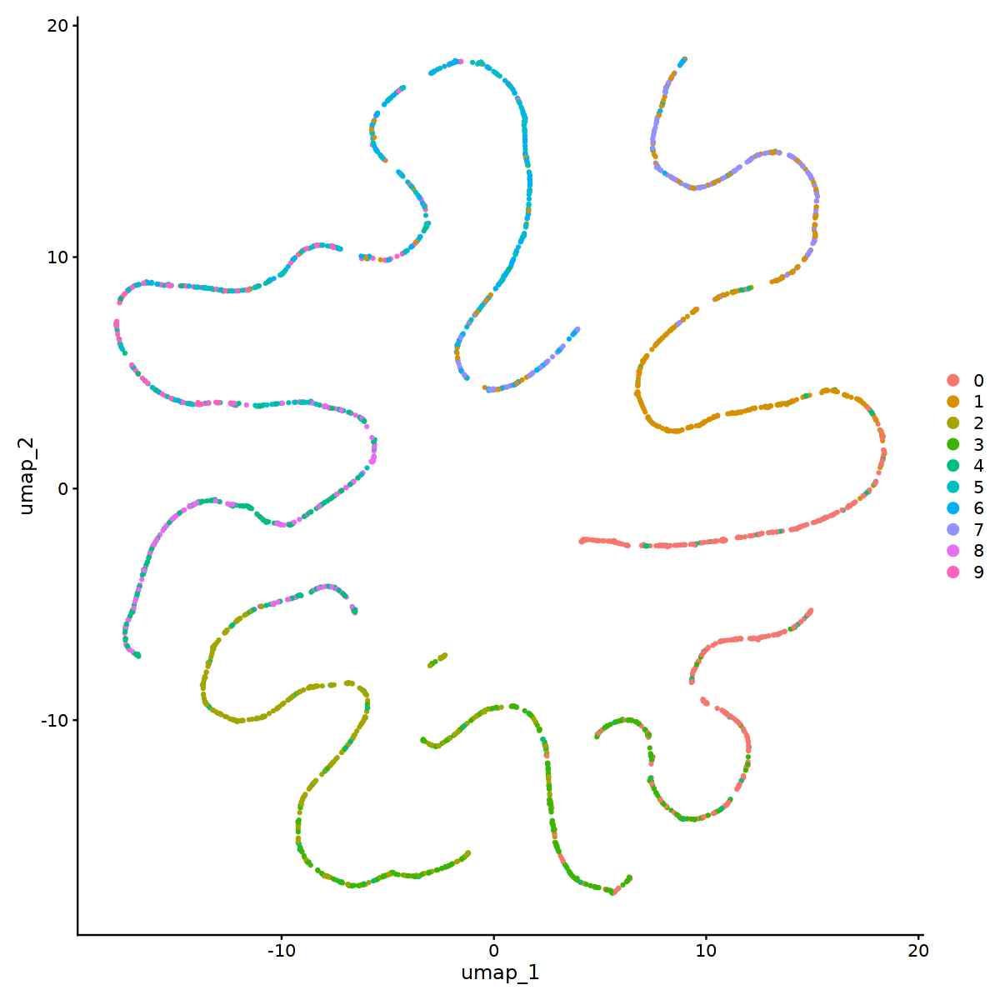

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9



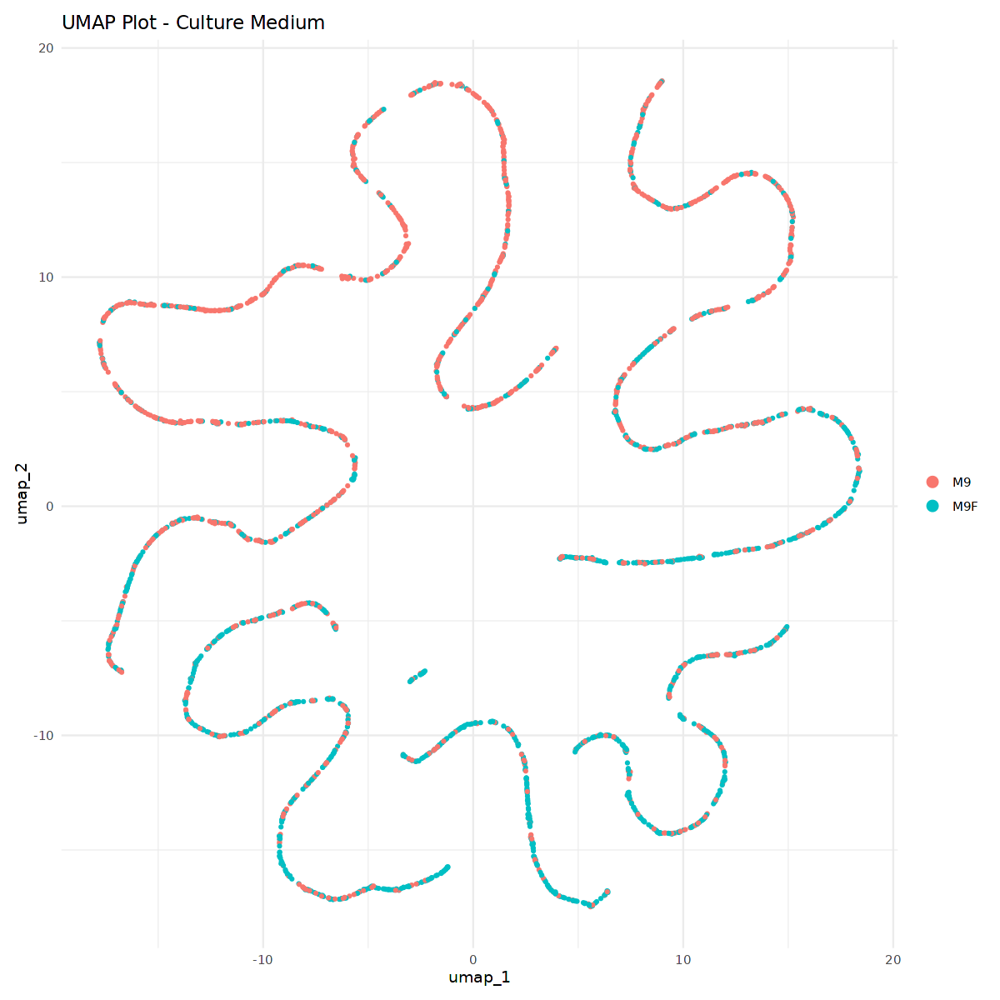

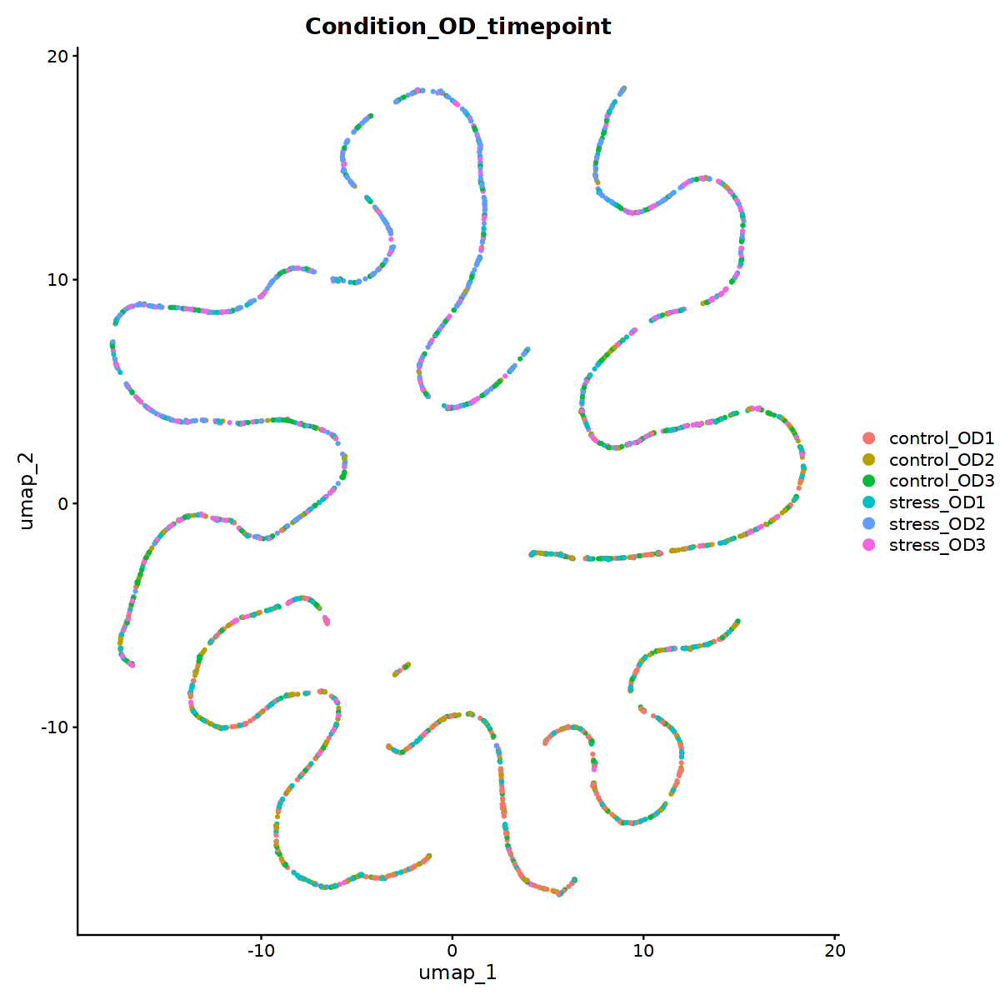

In [166]:
DimPlot(seurat_obj, reduction = "umap")
DimPlot(seurat_obj, reduction = "umap", group.by = "Culture_medium") +
  ggtitle("UMAP Plot - Culture Medium") +
  theme_minimal()
seurat_markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, min.pct = 0.25, logfc.threshold = 0.25)
DimPlot(seurat_obj, reduction = "umap", group.by = "Condition_OD_timepoint")

# Test 4  

In [167]:
#Clustering
seurat_obj <- FindNeighbors(seurat_obj, dims = 1:6)
seurat_obj <- FindClusters(seurat_obj, resolution = 0.5)

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 88152

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7148
Number of communities: 4
Elapsed time: 0 seconds


In [168]:
head(Idents(seurat_obj), 10)
seurat_obj <- RunUMAP(seurat_obj, 1:6)

GTACGCAA_AACCGAGA_AAACGATA CGGATTGC_AACGCTTA_AAACGATA 
                         0                          2 
CGCTGATC_AACGTGAT_AAACGATA GCTAACGA_AAGAGATC_AAACGATA 
                         0                          2 
CCTCTATC_AAGGACAC_AAACGATA GTGTTCTA_ACACAGAA_AAACGATA 
                         0                          1 
ACAGATTC_ACAGATTC_AAACGATA CAAGACTA_ACATTGGC_AAACGATA 
                         2                          0 
CCGTGAGA_ACCACTGT_AAACGATA ACTATGCA_AGTACAAG_AAACGATA 
                         0                          0 
Levels: 0 1 2 3

13:53:37 UMAP embedding parameters a = 0.9922 b = 1.112

13:53:37 Read 2934 rows and found 6 numeric columns

13:53:37 Using Annoy for neighbor search, n_neighbors = 30

13:53:37 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

13:53:38 Writing NN index file to temp file /tmp/RtmpoxfOPx/file3bc64145534

13:53:38 Searching Annoy index using 1 thread, search_k = 3000

13:53:39 Annoy recall = 100%

13:53:40 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

13:53:40 Initializing from normalized Laplacian + noise (using RSpectra)

13:53:40 Commencing optimization for 500 epochs, with 107136 positive edges

13:53:40 Using rng type: pcg

13:53:43 Optimization finished



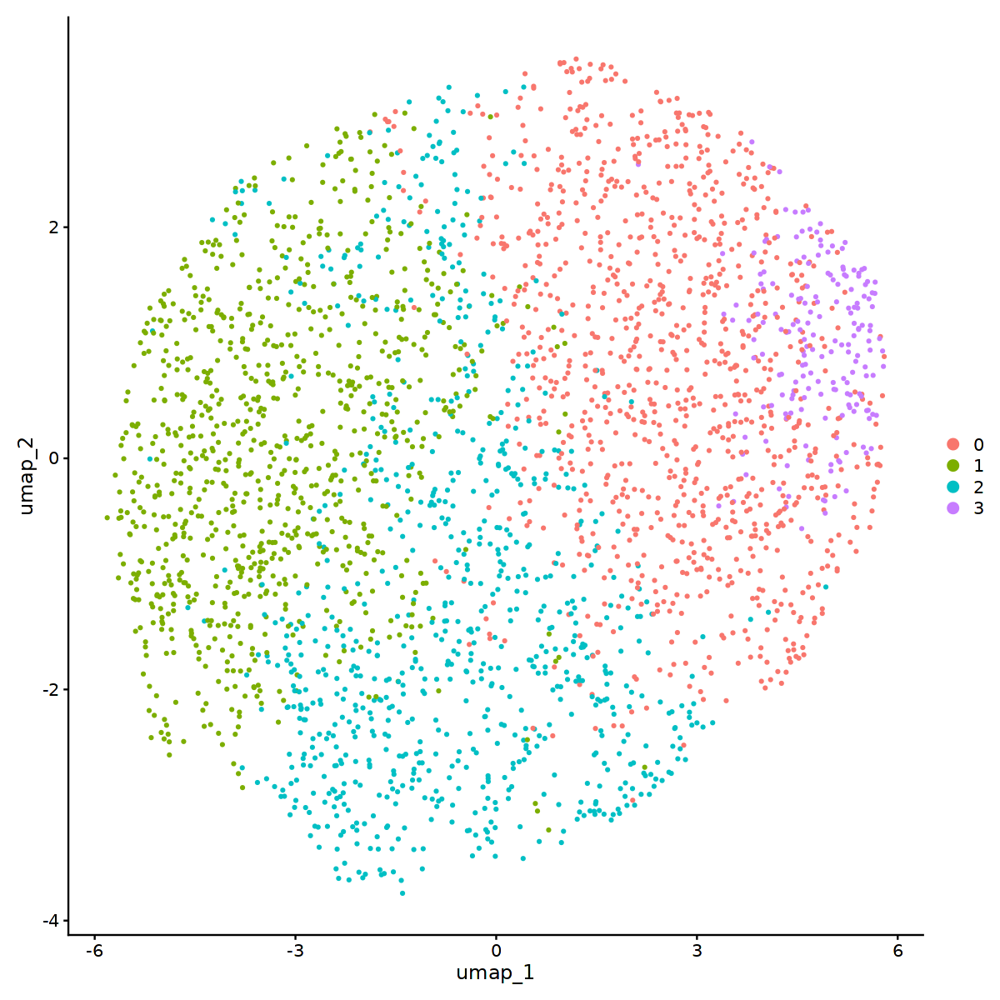

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3



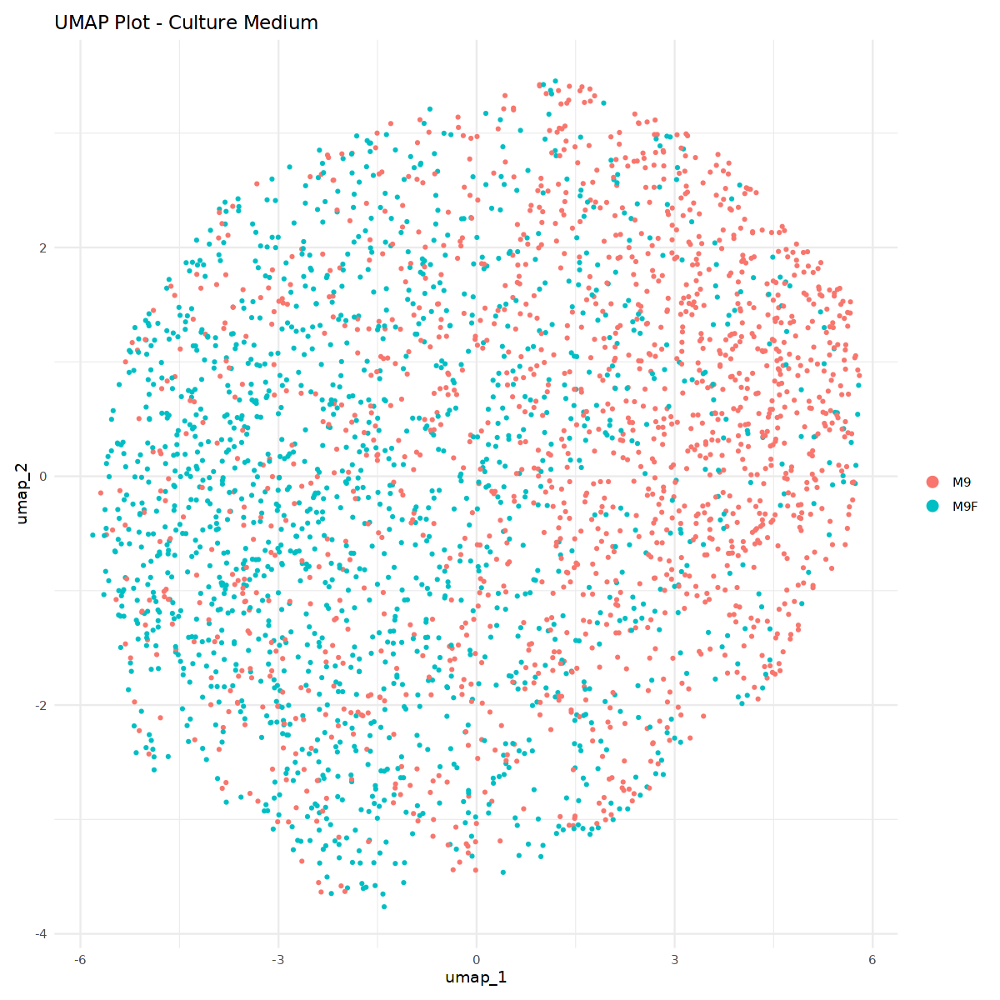

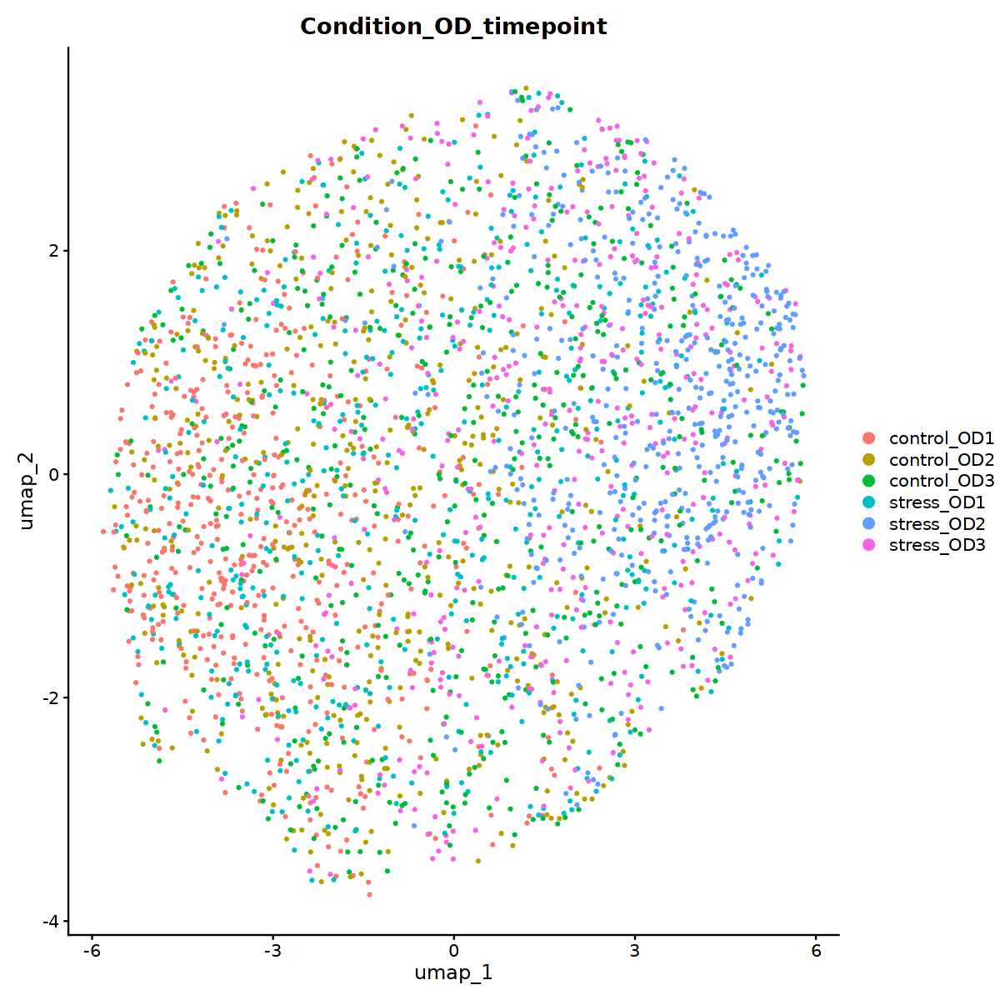

In [169]:
DimPlot(seurat_obj, reduction = "umap")
DimPlot(seurat_obj, reduction = "umap", group.by = "Culture_medium") +
  ggtitle("UMAP Plot - Culture Medium") +
  theme_minimal()
seurat_markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, min.pct = 0.25, logfc.threshold = 0.25)
DimPlot(seurat_obj, reduction = "umap", group.by = "Condition_OD_timepoint")

# test remonte le nombre de variables features  

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"
PC_ 1 
Positive:  QLH64-00395, ndk, QLH64-05905, folE2, QLH64-14565, QLH64-12130, QLH64-03850, QLH64-25565, topA, QLH64-11810 
	   QLH64-27880, QLH64-22035, hldE, fur, cysD, QLH64-16785, QLH64-00295, gshA, QLH64-19260, QLH64-17430 
	   cysB, QLH64-06375, QLH64-22005, QLH64-00515, QLH64-03590, QLH64-27175, QLH64-15200, QLH64-18745, QLH64-16790, QLH64-10155 
Negative:  QLH64-03825, choX_1, QLH64-14525, cobA_1, QLH64-30010, QLH64-08635, QLH64-24590, QLH64-09505, QLH64-08330, QLH64-04585 
	   QLH64-10530, QLH64-08350, QLH64-31240, QLH64-25710, QLH64-13525, QLH64-23710, QLH64-20890, QLH64-24145, QLH64-13385, QLH64-17505 
	   QLH64-12320, QLH64-02630, QLH64-05540, QLH64-19895, QLH64-02665, QLH64-23730, QLH64-17820, QLH64-14640, QLH64-14995, QLH64-02635 
PC_ 2 
Positive:  astE, QLH64-10155, QLH64-03850, prs, QLH64-24875, QLH6

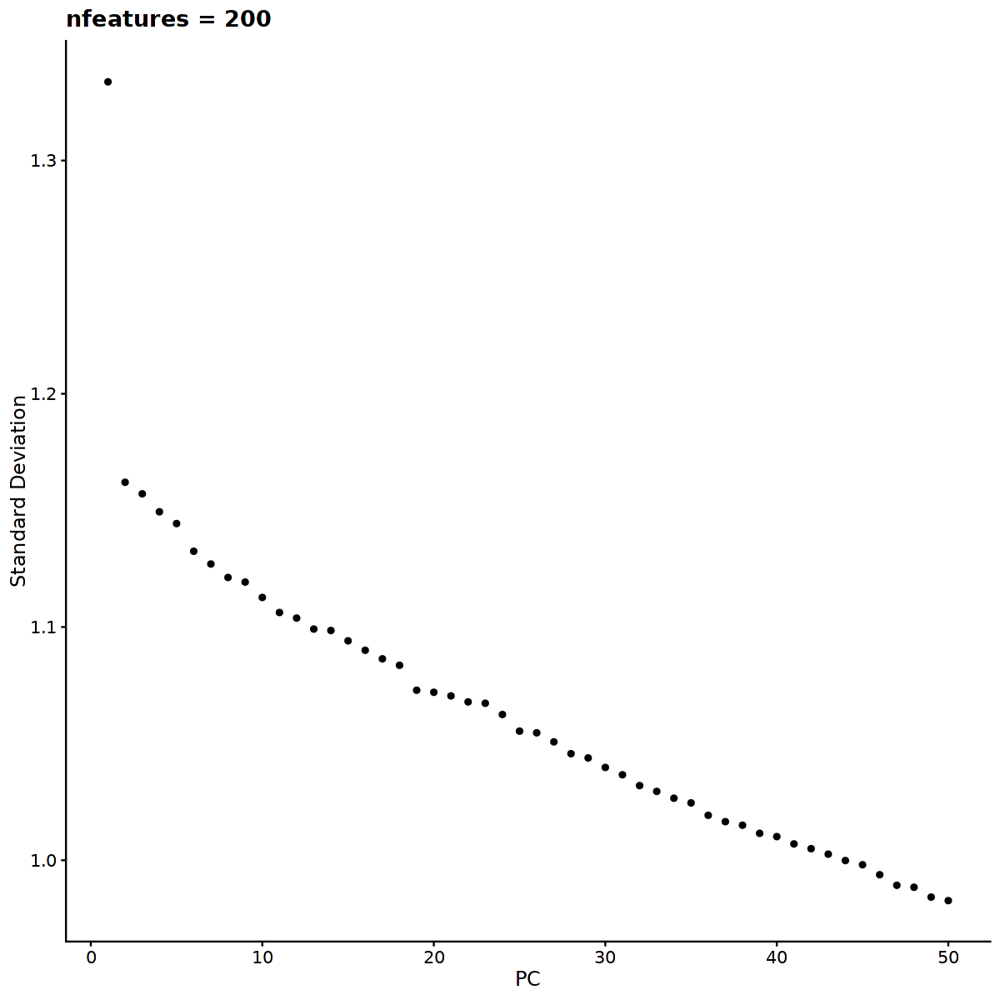

NULL


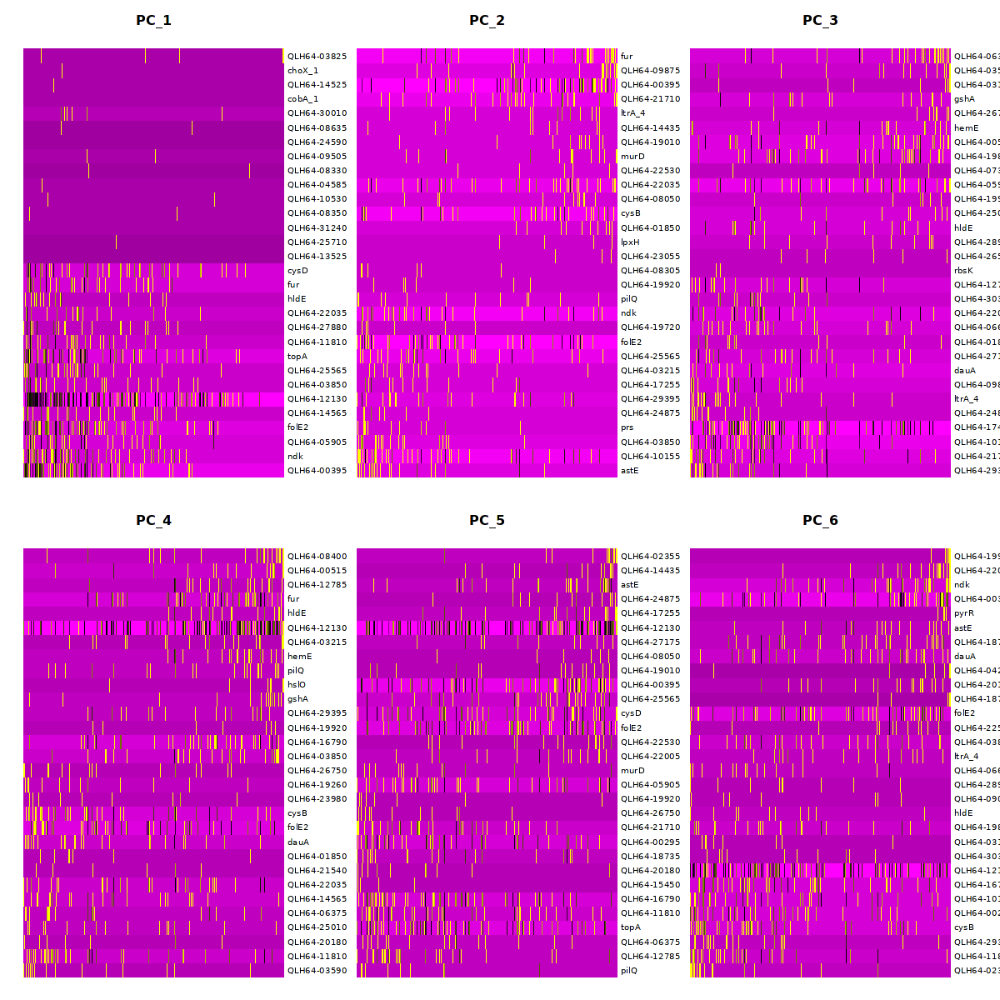

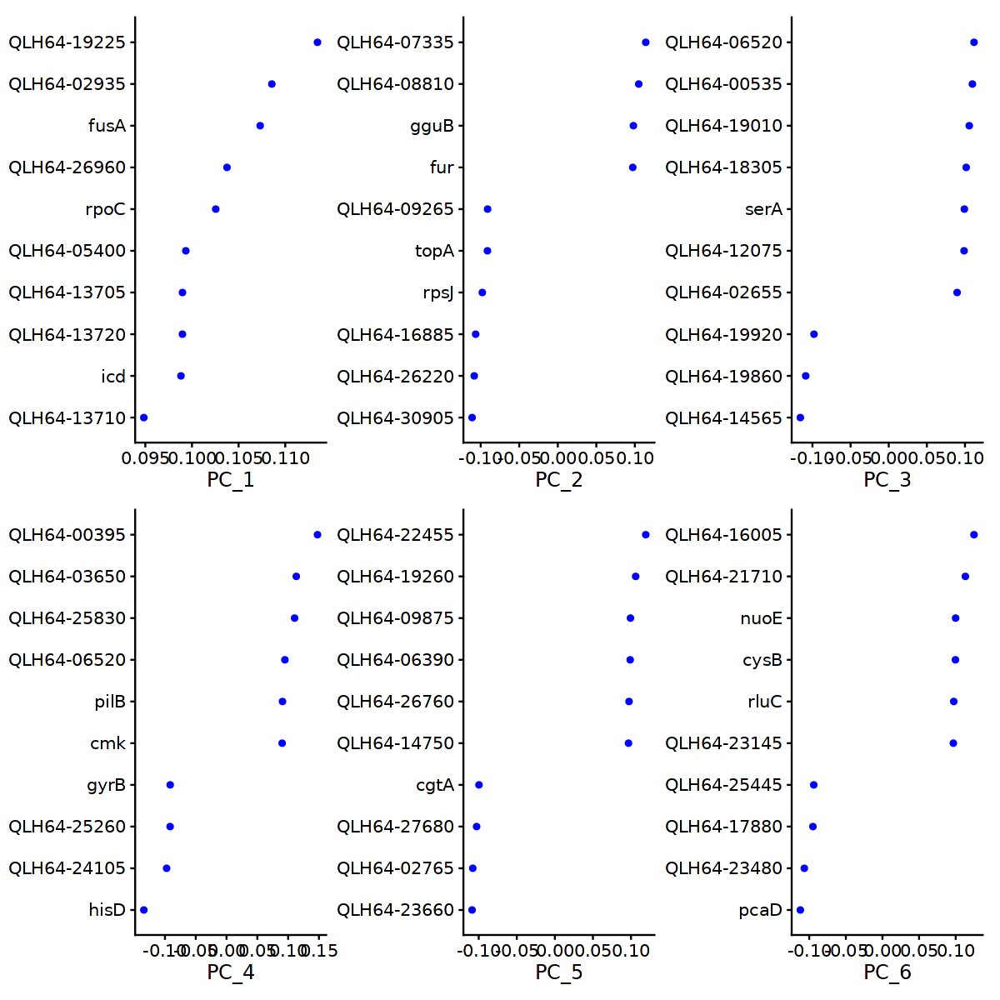

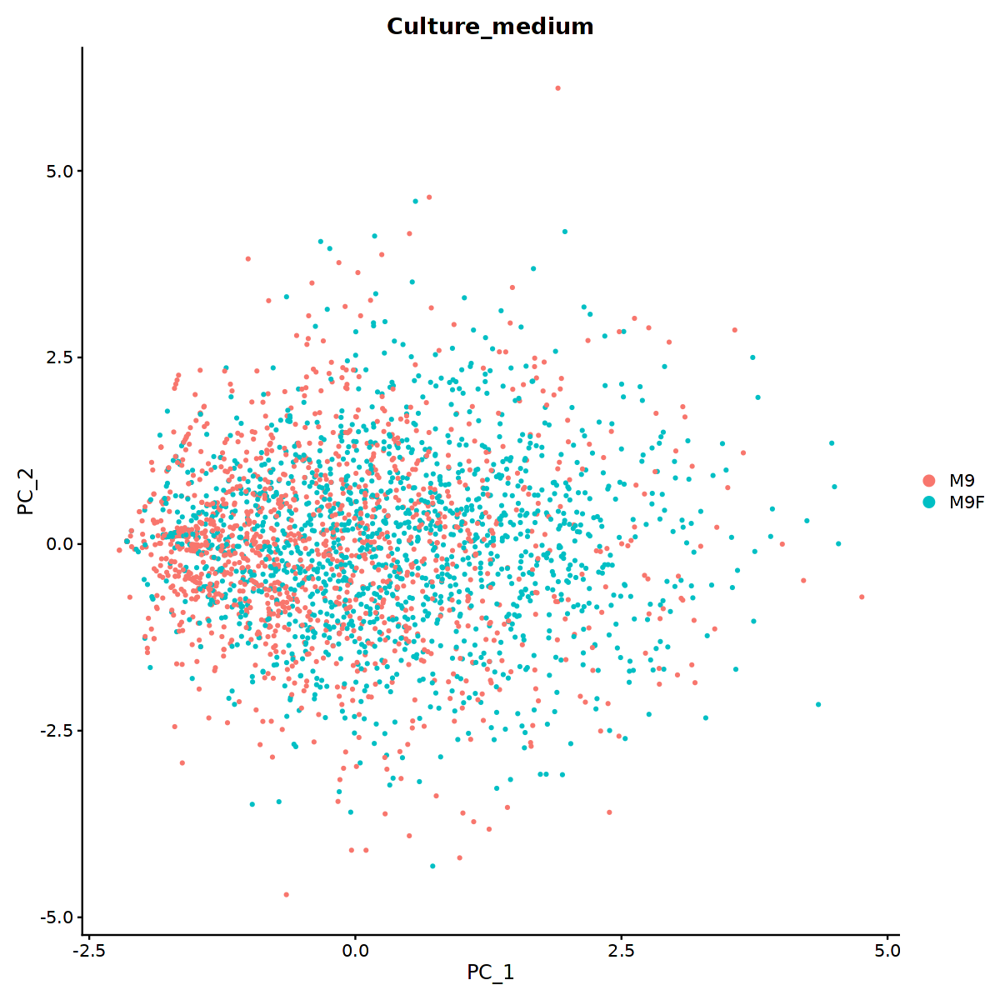

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 97384

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7499
Number of communities: 5
Elapsed time: 0 seconds


14:35:06 UMAP embedding parameters a = 0.9922 b = 1.112

14:35:06 Read 2934 rows and found 10 numeric columns

14:35:06 Using Annoy for neighbor search, n_neighbors = 30

14:35:06 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:35:07 Writing NN index file to temp file /tmp/RtmpoxfOPx/file3bc3f8fddcb

14:35:07 Searching Annoy index using 1 thread, search_k = 3000

14:35:08 Annoy recall = 95.23%

14:35:09 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:35:09 175 smooth knn distance failures

14:35:11 Initializing from normalized Laplacian + noise (using RSpectra)

14:35:11 Commencing optimization for 500 epochs, with 104410 positive edges

14:35:11 Using rng type: pcg

14:35:14 Optimization finished



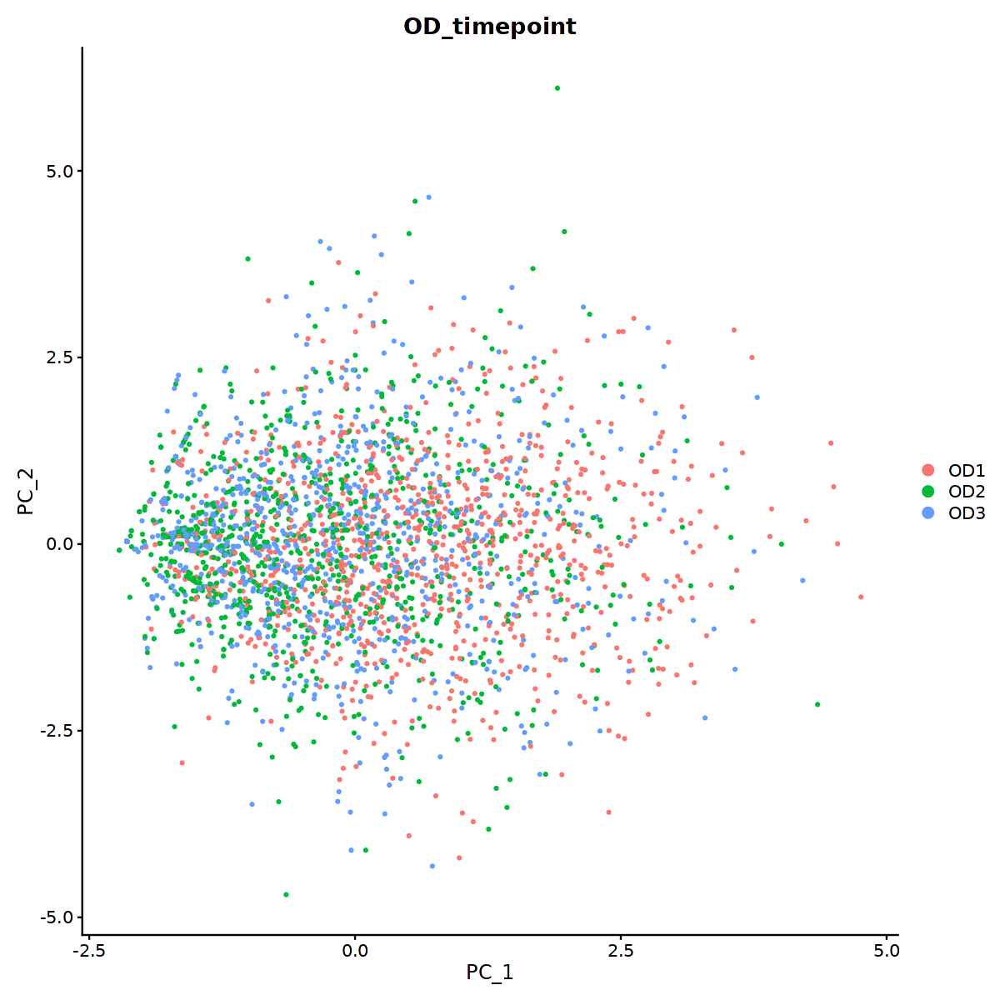

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"
PC_ 1 
Positive:  QLH64-19225, fusA, QLH64-02935, rpoC, QLH64-13720, QLH64-05400, QLH64-07480, QLH64-24685, secA, QLH64-12130 
	   QLH64-04320, QLH64-18250, galU, QLH64-12160, QLH64-27520, ppa, serA, QLH64-04480, QLH64-23145, folE2 
	   QLH64-00395, fabB, QLH64-29815, rplI, pgi, QLH64-13350, ndk, QLH64-11810, QLH64-13325, QLH64-05080 
Negative:  QLH64-02630, choX_1, QLH64-12580, QLH64-12900, cobA_1, QLH64-24590, QLH64-30870, QLH64-03825, QLH64-09870, chrA 
	   QLH64-02635, QLH64-22455, QLH64-08635, QLH64-17820, QLH64-13385, QLH64-20890, QLH64-23730, QLH64-14525, QLH64-08330, QLH64-07745 
	   QLH64-18655, QLH64-29715, QLH64-00325, QLH64-15415, QLH64-28035, QLH64-04585, QLH64-07545, QLH64-26175, QLH64-03320, pgeF 
PC_ 2 
Positive:  hemE, QLH64-13945, QLH64-00515, QLH64-03130, QLH64-02360, cysB, QLH64-06375, pilB, QLH64-1

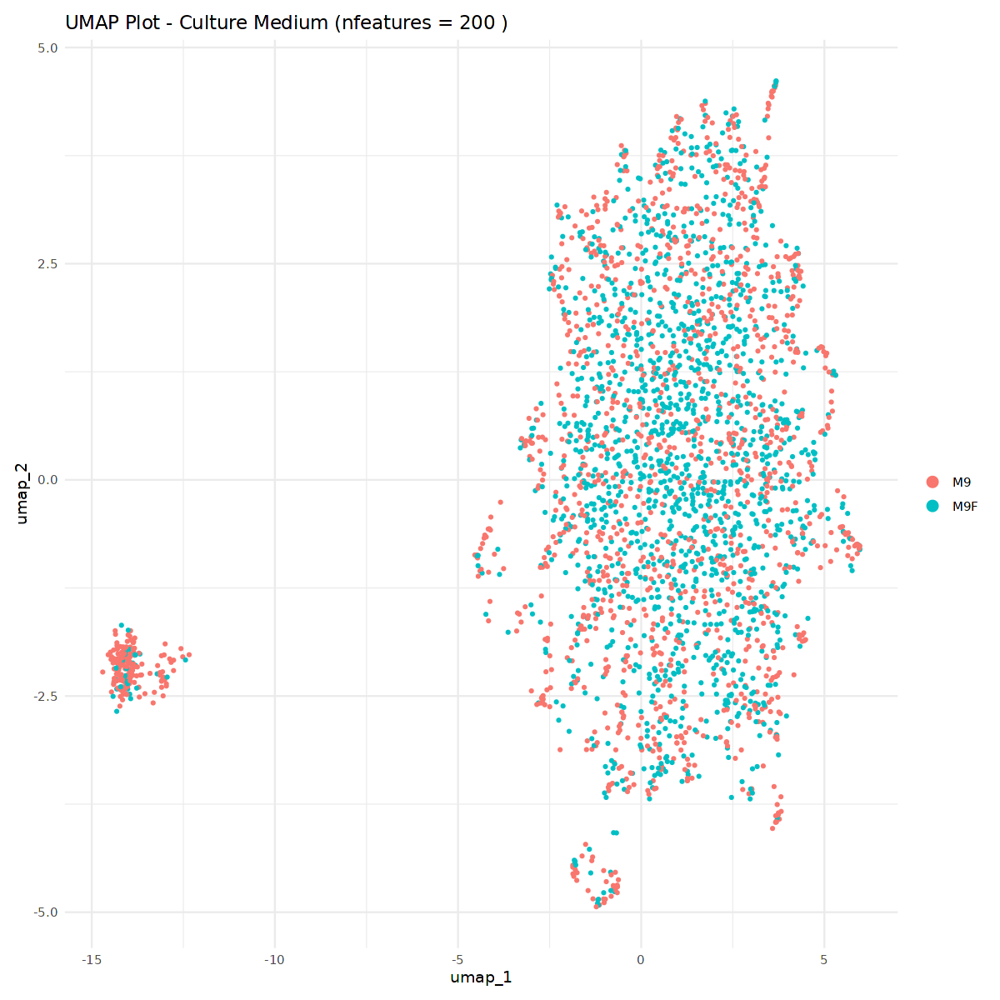

Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


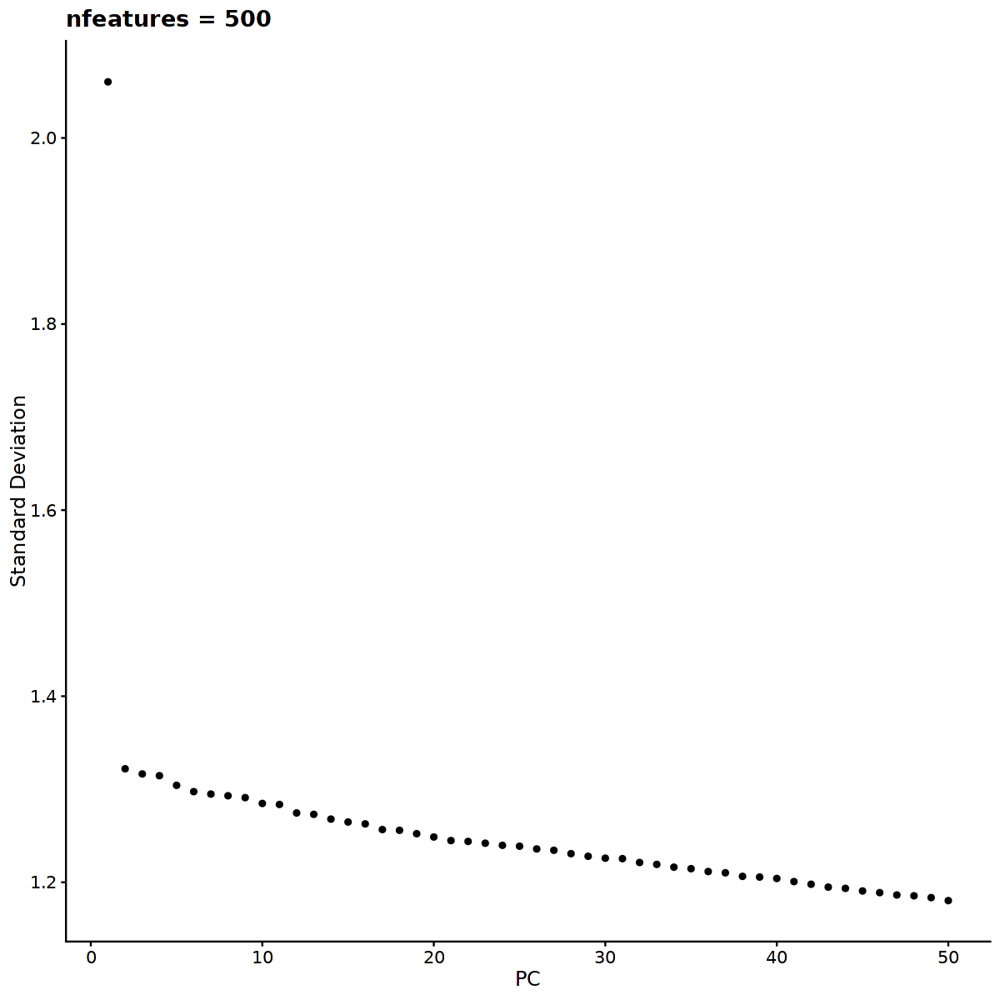

NULL


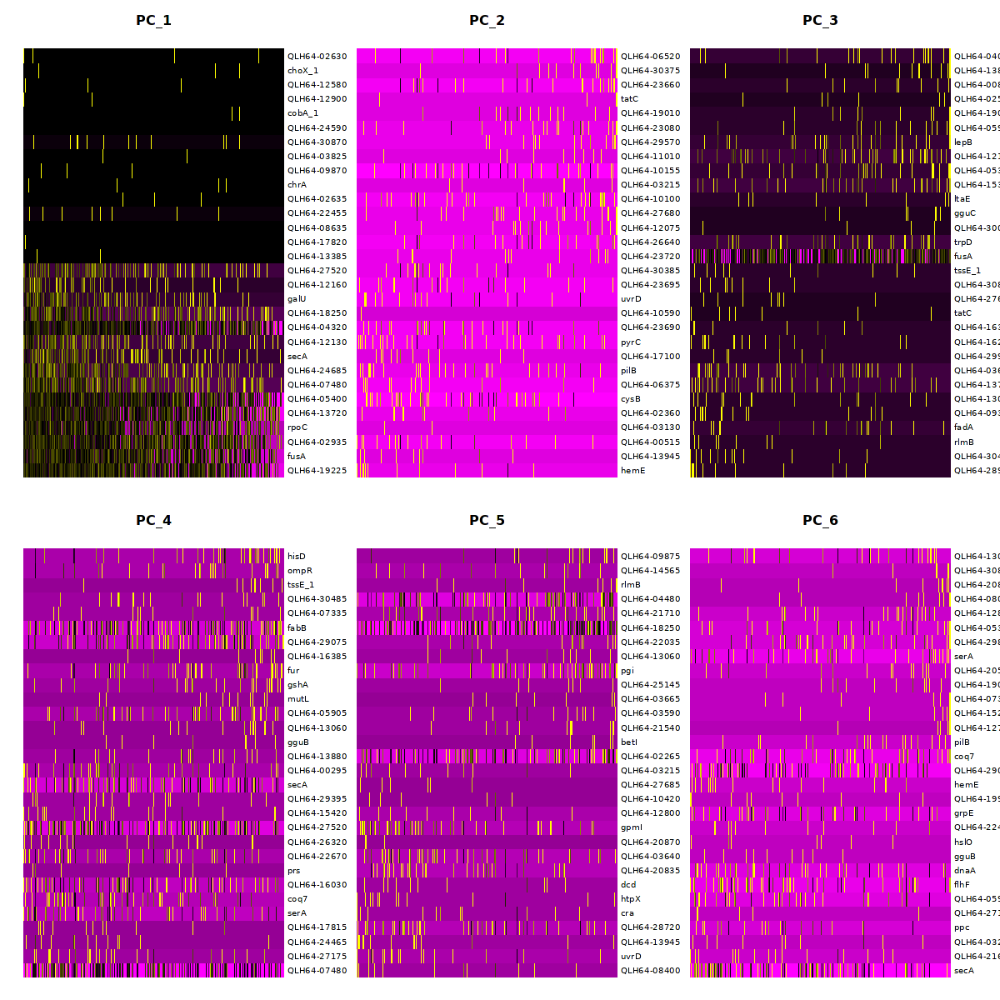

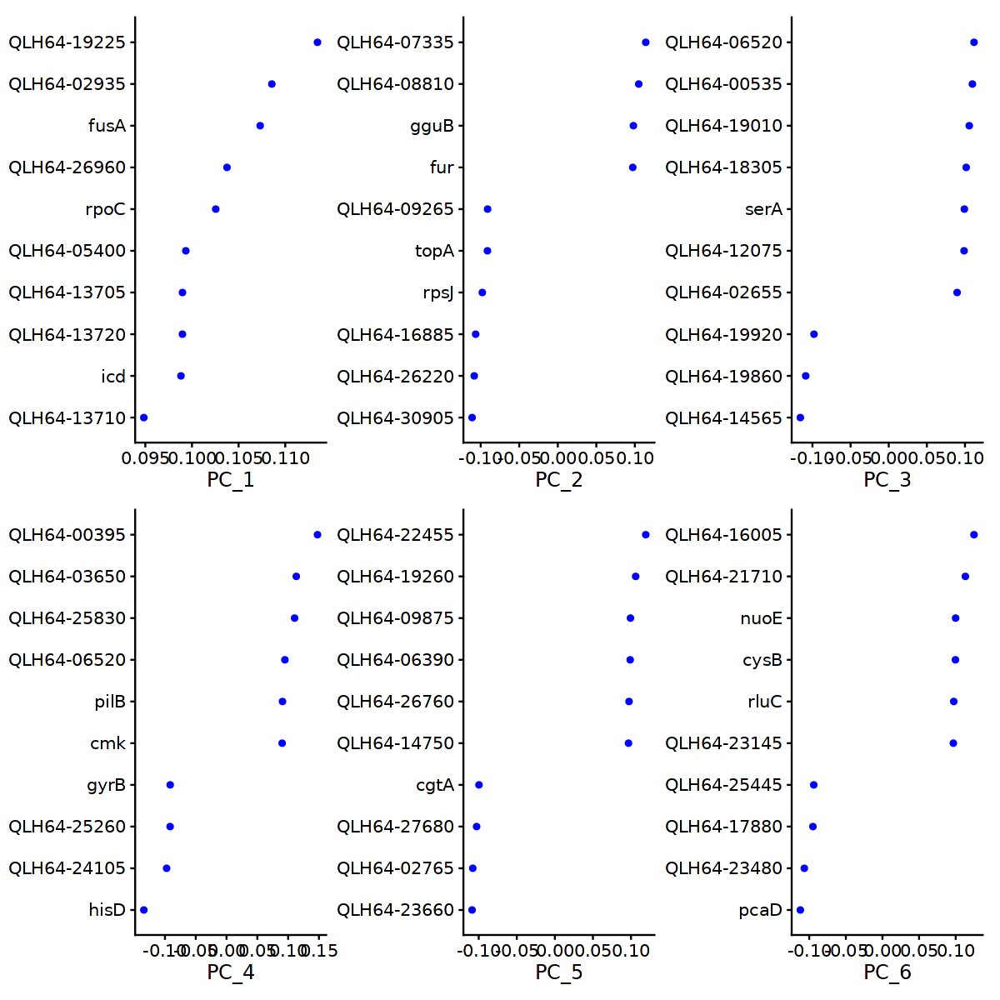

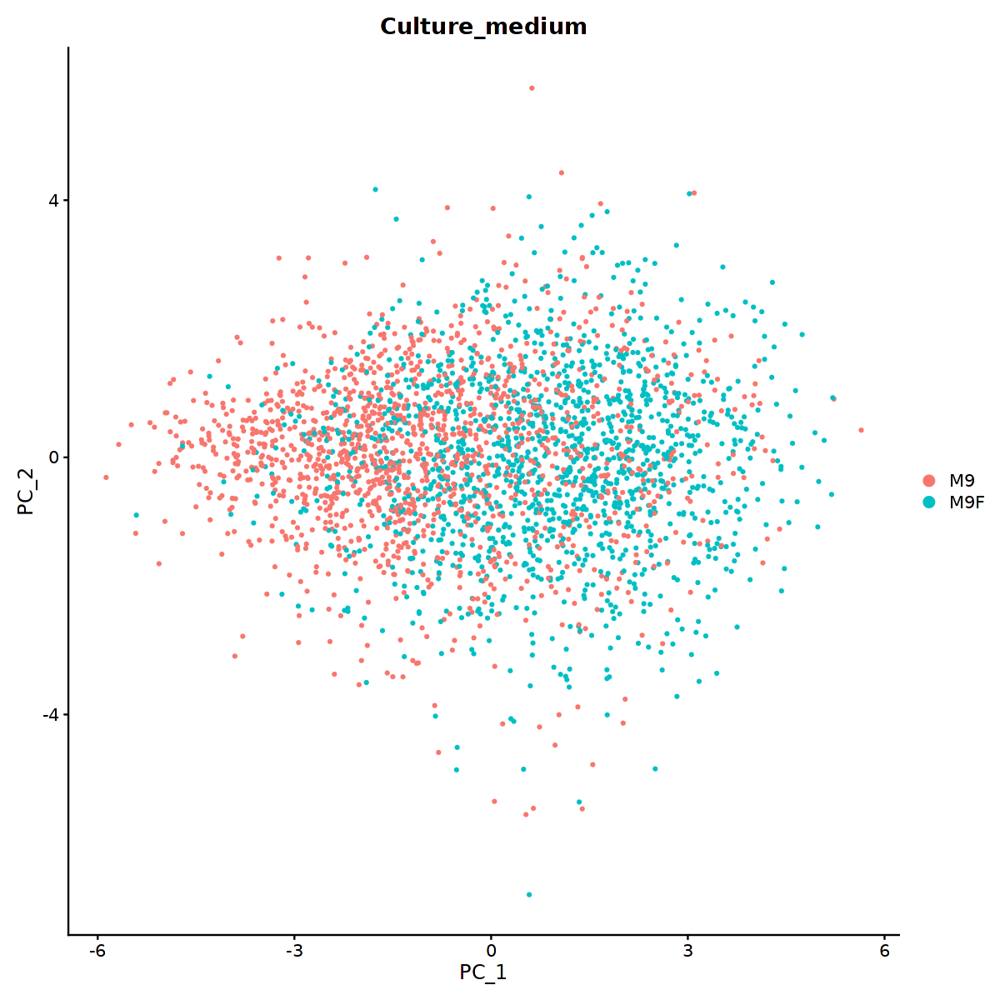

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 92519

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6766
Number of communities: 3
Elapsed time: 0 seconds


14:35:23 UMAP embedding parameters a = 0.9922 b = 1.112

14:35:23 Read 2934 rows and found 10 numeric columns

14:35:23 Using Annoy for neighbor search, n_neighbors = 30

14:35:23 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:35:23 Writing NN index file to temp file /tmp/RtmpoxfOPx/file3bc24de2b0

14:35:23 Searching Annoy index using 1 thread, search_k = 3000

14:35:24 Annoy recall = 100%

14:35:25 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:35:26 Initializing from normalized Laplacian + noise (using RSpectra)

14:35:26 Commencing optimization for 500 epochs, with 108628 positive edges

14:35:26 Using rng type: pcg

14:35:28 Optimization finished



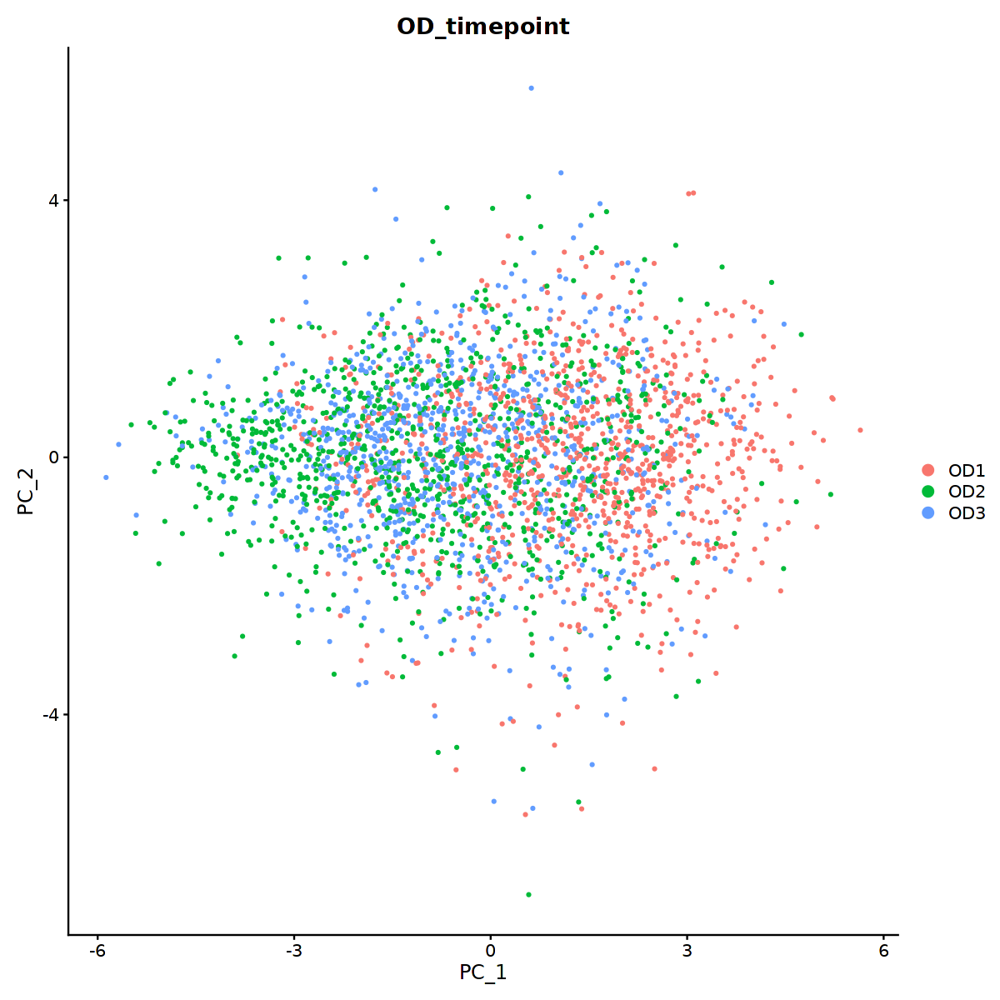

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"
PC_ 1 
Positive:  QLH64-19225, QLH64-02935, fusA, QLH64-26960, rpoC, QLH64-05400, QLH64-13705, QLH64-13720, icd, QLH64-13710 
	   QLH64-07480, QLH64-30060, rpsB, rplL, QLH64-19800, gltA, QLH64-31045, secA, QLH64-04320, QLH64-12185 
	   QLH64-24685, gltB, QLH64-12130, sdhA, QLH64-13080, tcyJ, leuA_2, QLH64-18250, QLH64-13345, QLH64-04480 
Negative:  QLH64-24105, gluQRS, QLH64-01365, QLH64-02630, choX_1, QLH64-05945, QLH64-30160, QLH64-20285, QLH64-15845, QLH64-06820 
	   QLH64-20500, QLH64-14500, QLH64-04220, QLH64-07875, gbcA, QLH64-26395, QLH64-10750, QLH64-08660, QLH64-09150, QLH64-00325 
	   QLH64-10570, QLH64-12960, QLH64-28180, QLH64-27515, QLH64-24355, QLH64-01295, QLH64-12340, QLH64-29715, QLH64-12900, QLH64-15415 
PC_ 2 
Positive:  QLH64-07335, QLH64-08810, gguB, fur, QLH64-02870, hldE, treS, QLH64-25445, iscR,

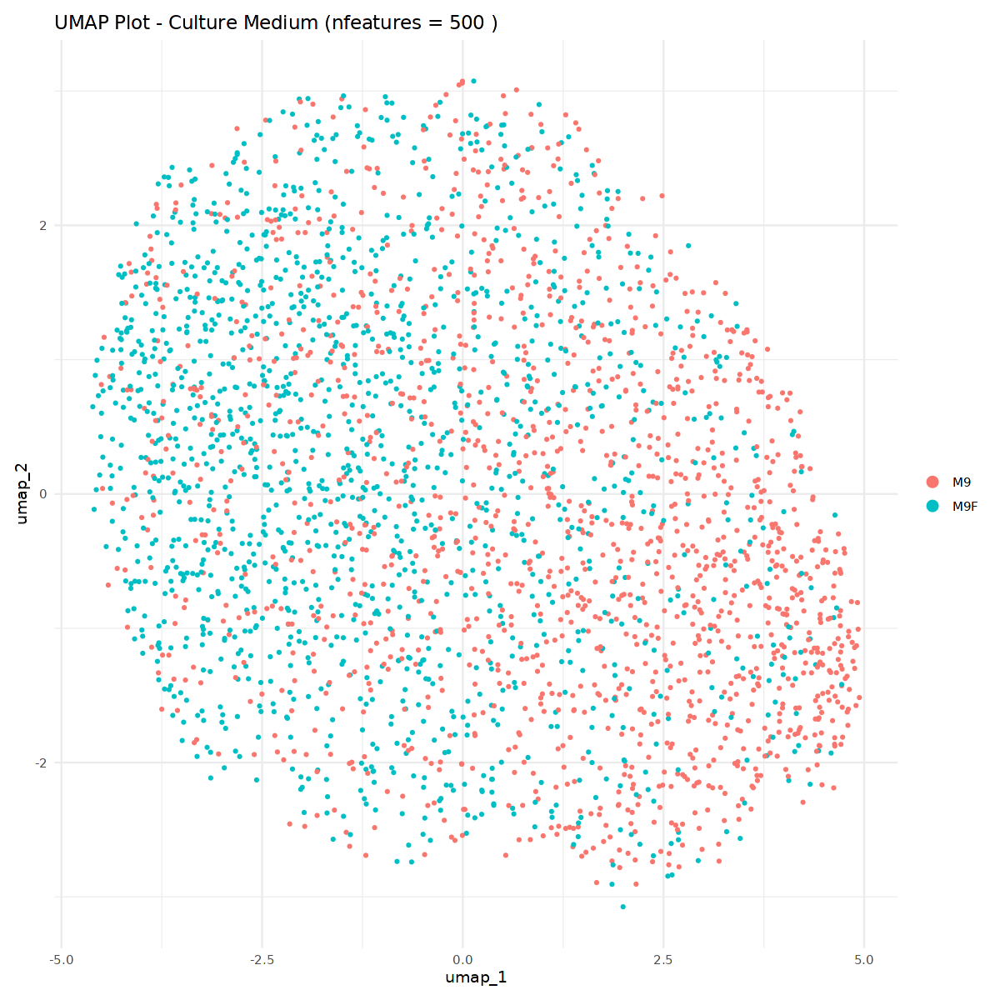

Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


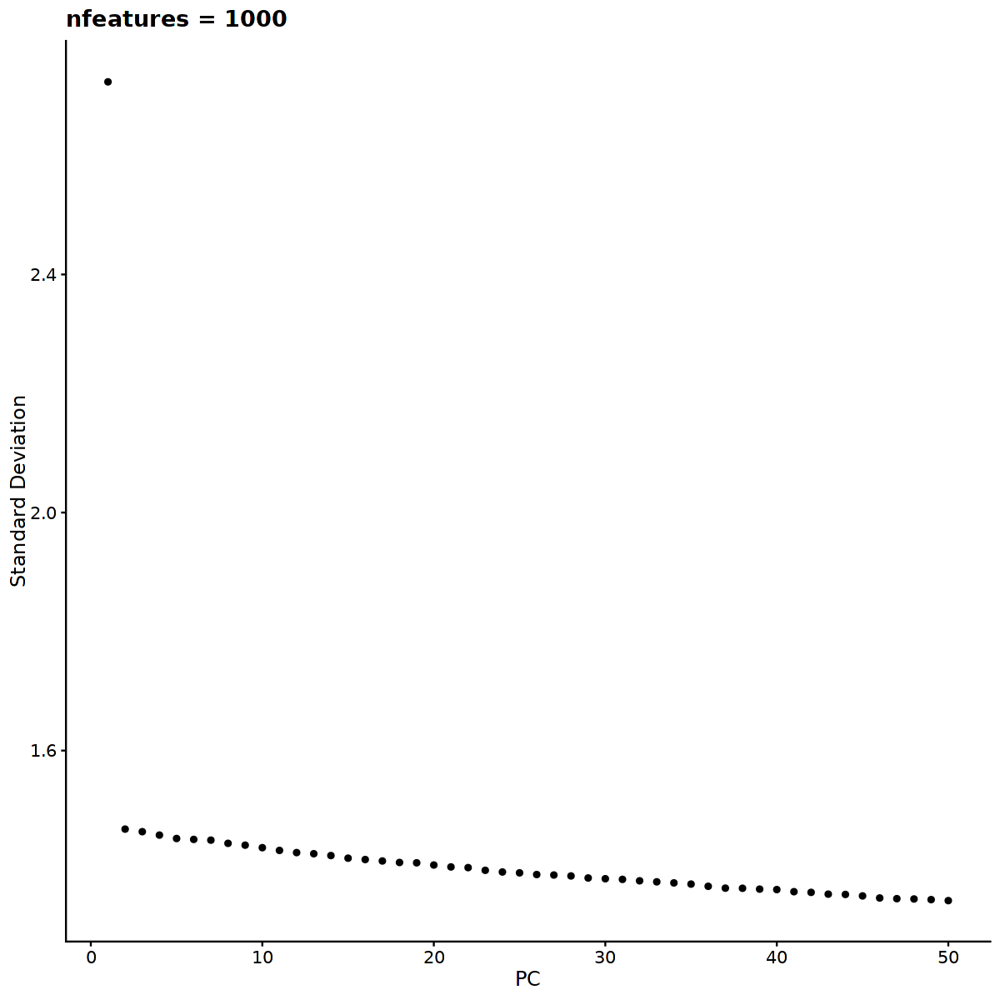

NULL


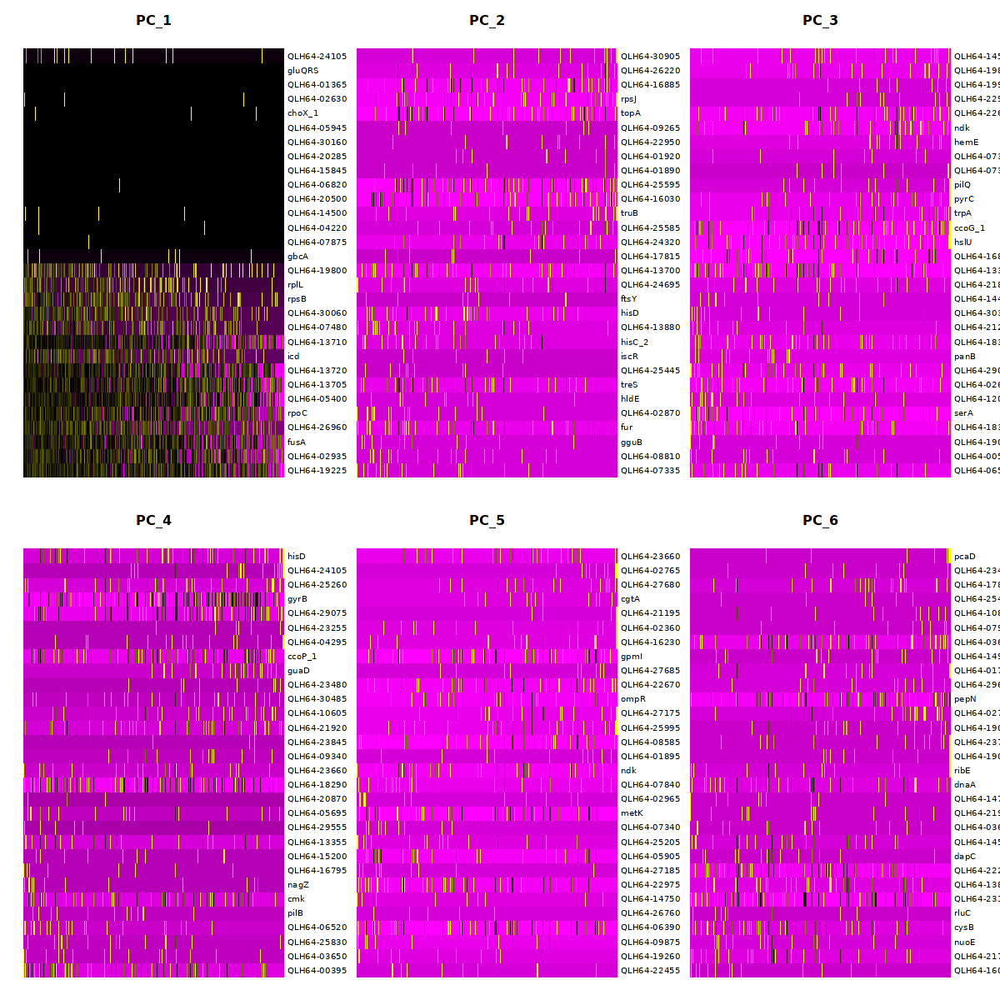

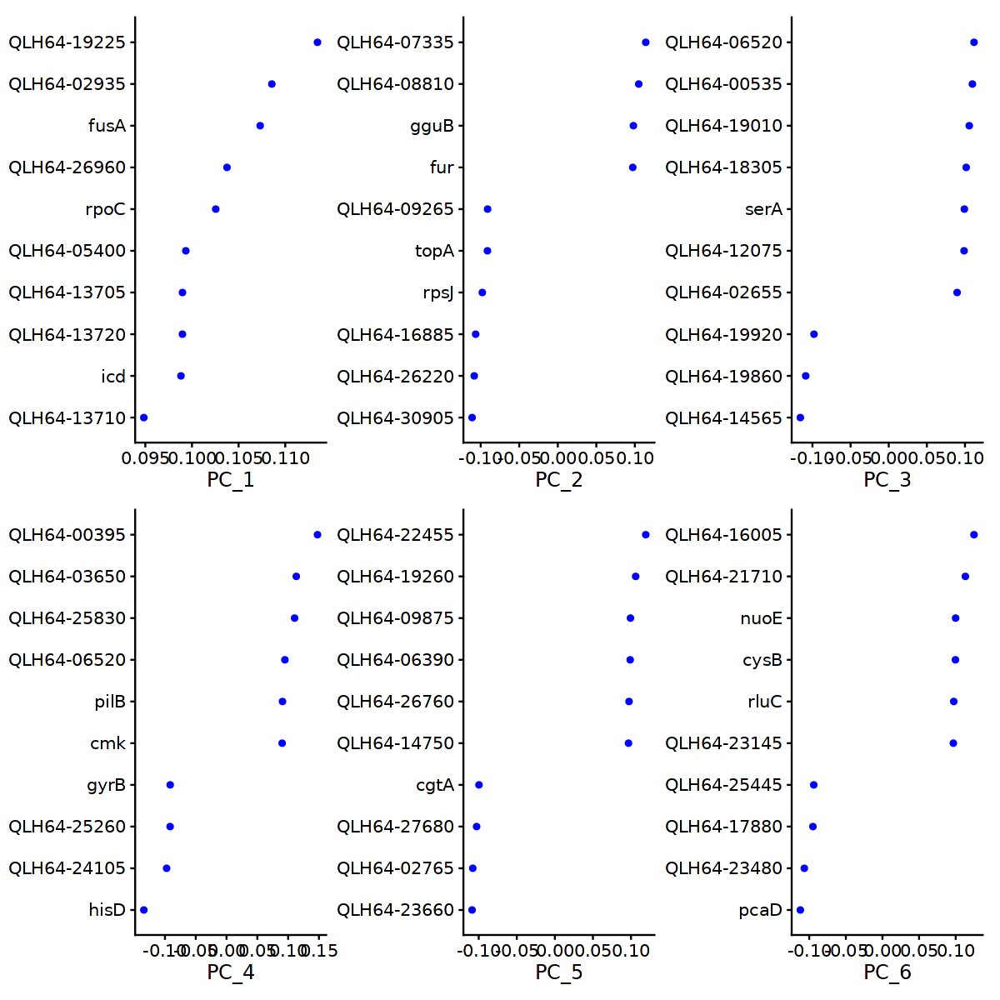

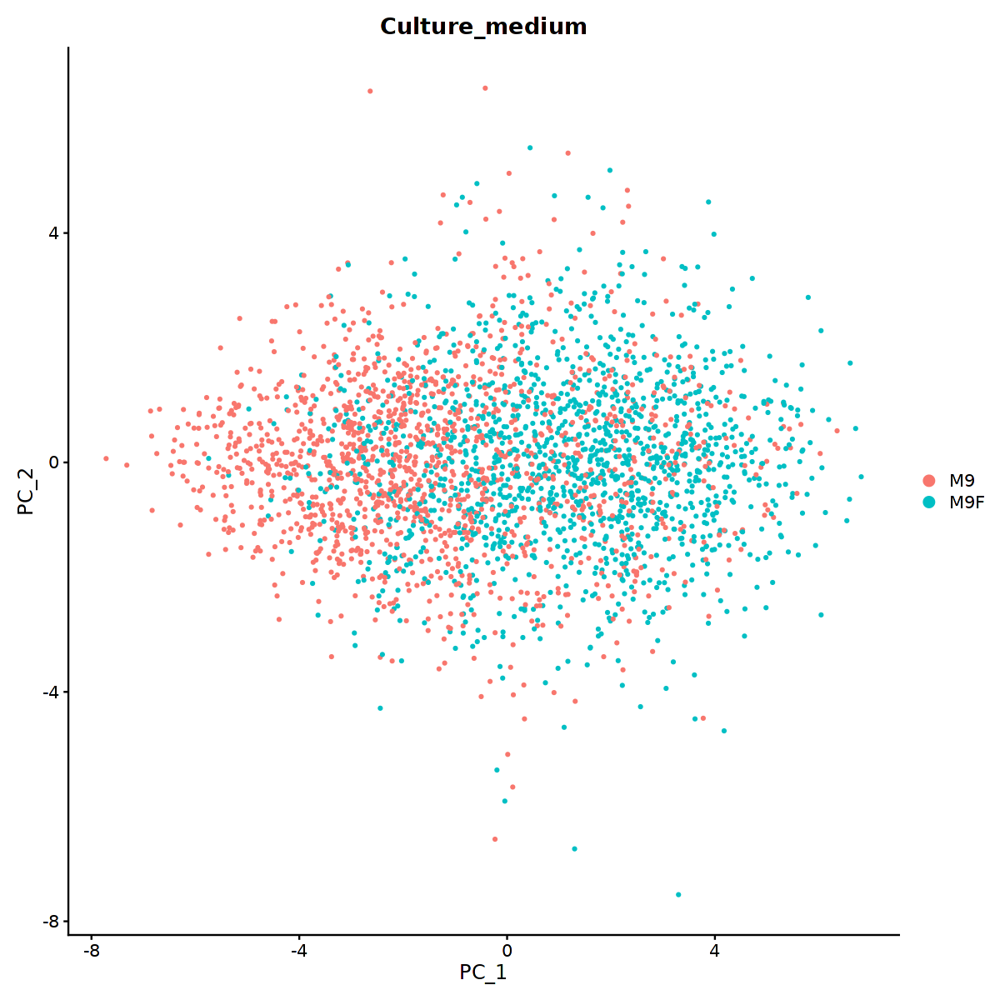

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 92330

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6905
Number of communities: 3
Elapsed time: 0 seconds


14:35:38 UMAP embedding parameters a = 0.9922 b = 1.112

14:35:38 Read 2934 rows and found 10 numeric columns

14:35:38 Using Annoy for neighbor search, n_neighbors = 30

14:35:38 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:35:38 Writing NN index file to temp file /tmp/RtmpoxfOPx/file3bc53081e96

14:35:38 Searching Annoy index using 1 thread, search_k = 3000

14:35:39 Annoy recall = 100%

14:35:40 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:35:41 Initializing from normalized Laplacian + noise (using RSpectra)

14:35:41 Commencing optimization for 500 epochs, with 114016 positive edges

14:35:41 Using rng type: pcg

14:35:44 Optimization finished



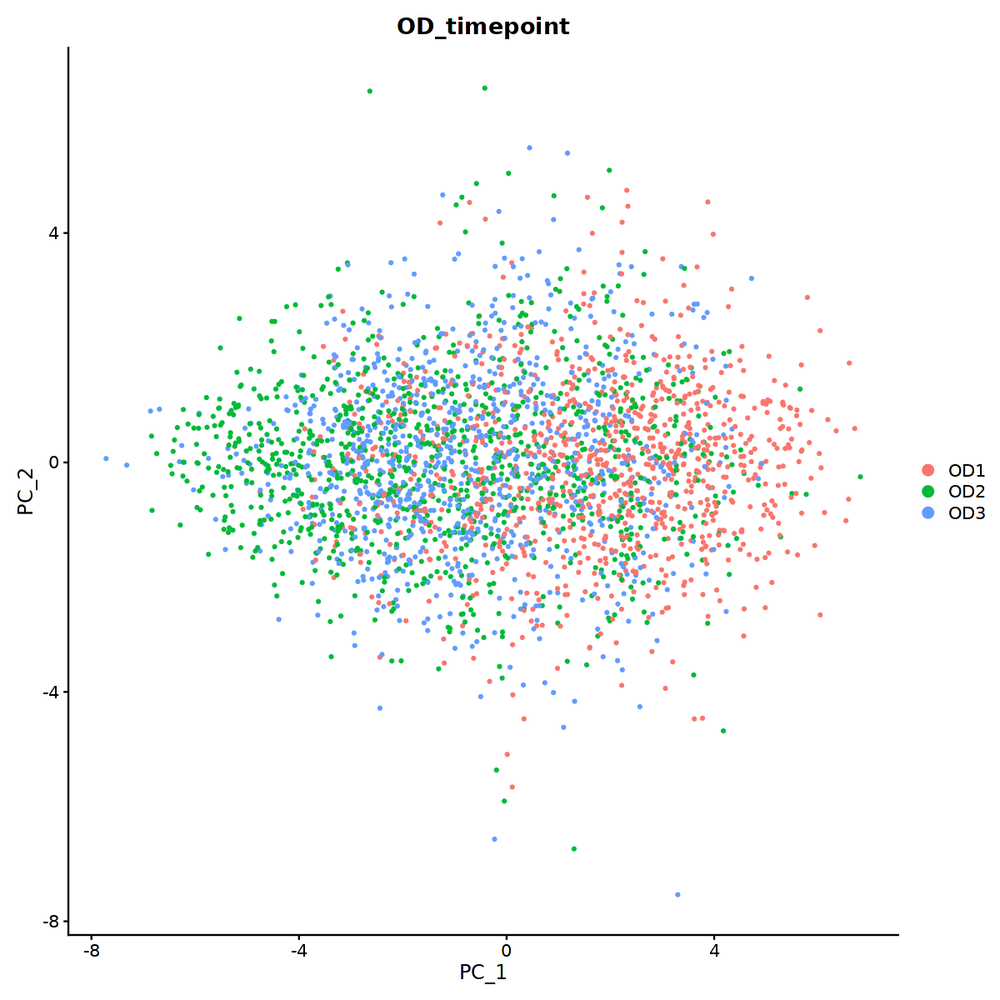

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"
PC_ 1 
Positive:  QLH64-19225, QLH64-02935, fusA, QLH64-23140, QLH64-00420, QLH64-05400, QLH64-26960, icd, rpoC, QLH64-12125 
	   QLH64-09610, gap, QLH64-13720, QLH64-13705, infC, QLH64-22540, acnB, QLH64-07480, QLH64-12435, QLH64-13710 
	   QLH64-27060, QLH64-00845, infB, ppsA, QLH64-30060, ftsZ, gltA, rpsB, QLH64-00430, QLH64-13730 
Negative:  QLH64-24105, QLH64-02630, gluQRS, QLH64-01365, QLH64-05945, QLH64-12900, choX_1, QLH64-20285, QLH64-30160, QLH64-03320 
	   QLH64-07875, QLH64-29715, QLH64-14500, QLH64-11285, QLH64-15845, QLH64-01295, QLH64-06820, QLH64-08660, QLH64-27515, QLH64-26395 
	   QLH64-24590, QLH64-10750, QLH64-20500, QLH64-09150, gbcA, QLH64-10570, QLH64-12340, QLH64-28180, QLH64-29555, truA 
PC_ 2 
Positive:  hemN_1, QLH64-13690, QLH64-22455, fur, hisF, QLH64-10420, minC, treS, recF, QLH64-03730 
	

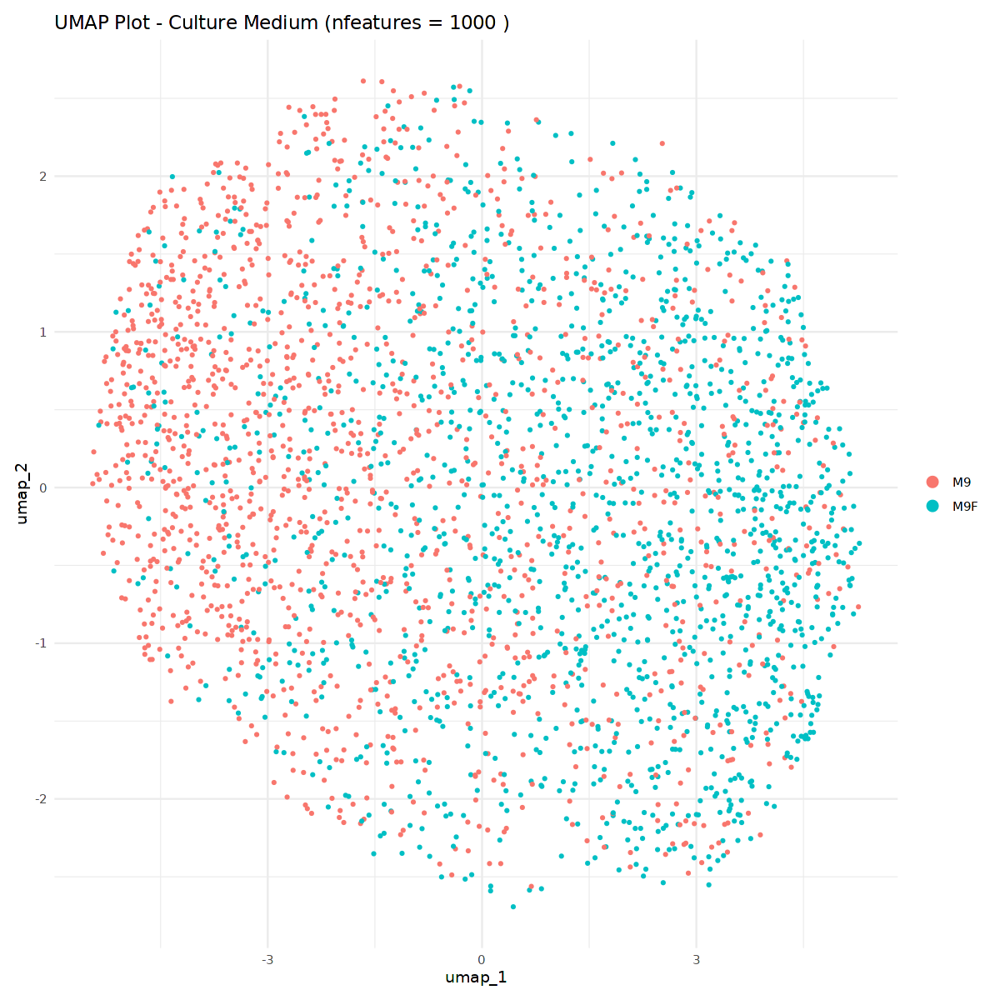

Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


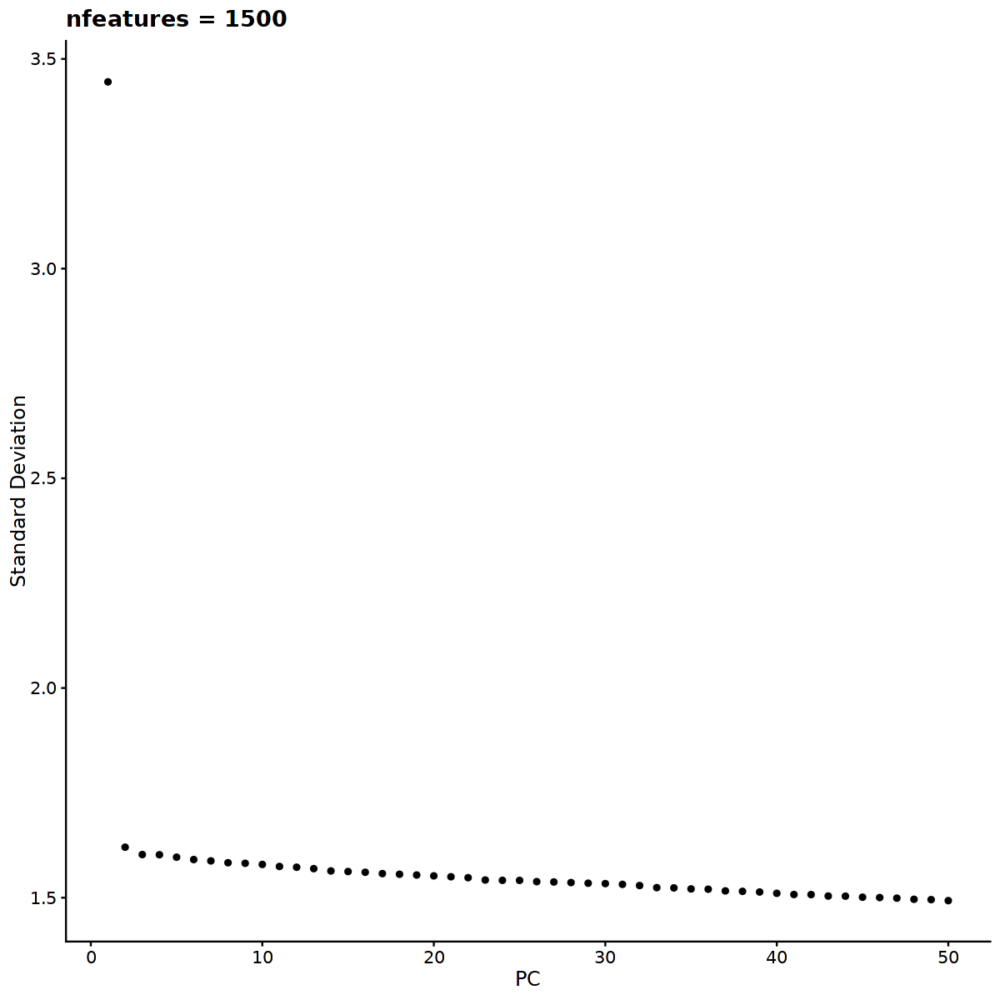

NULL


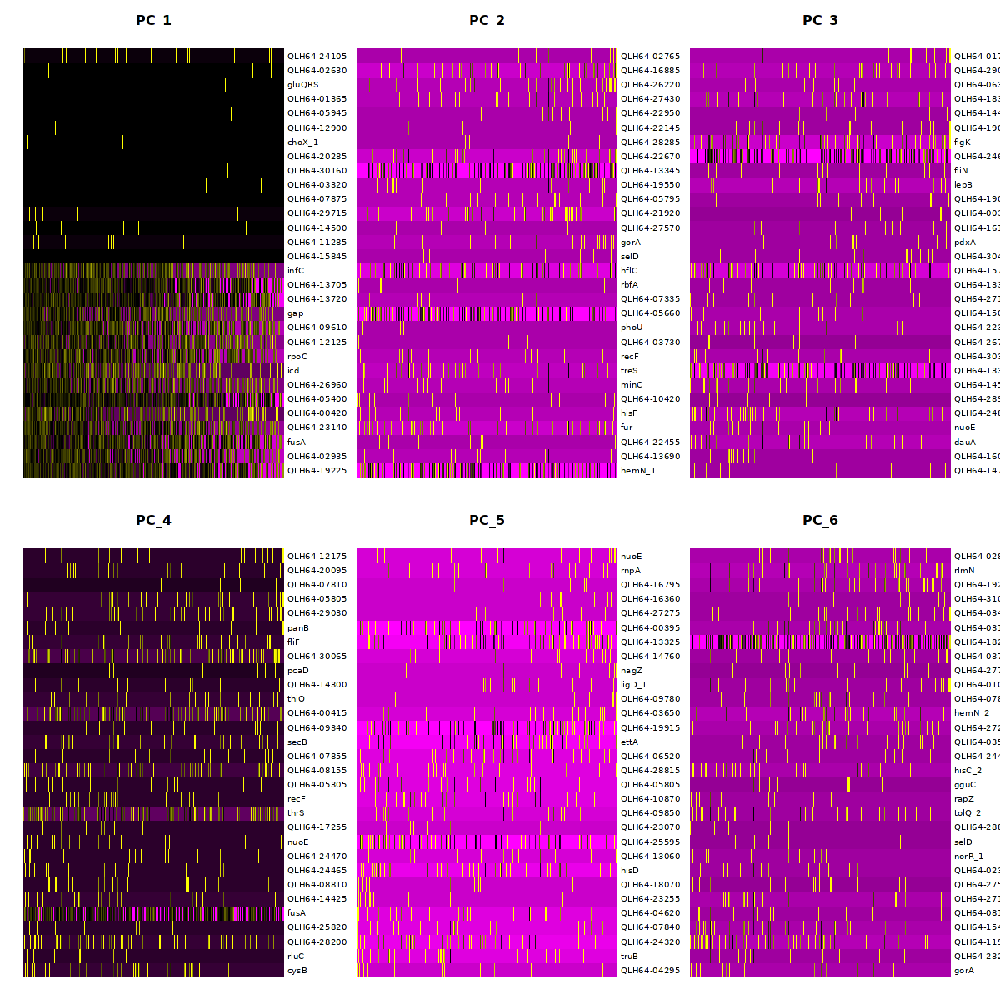

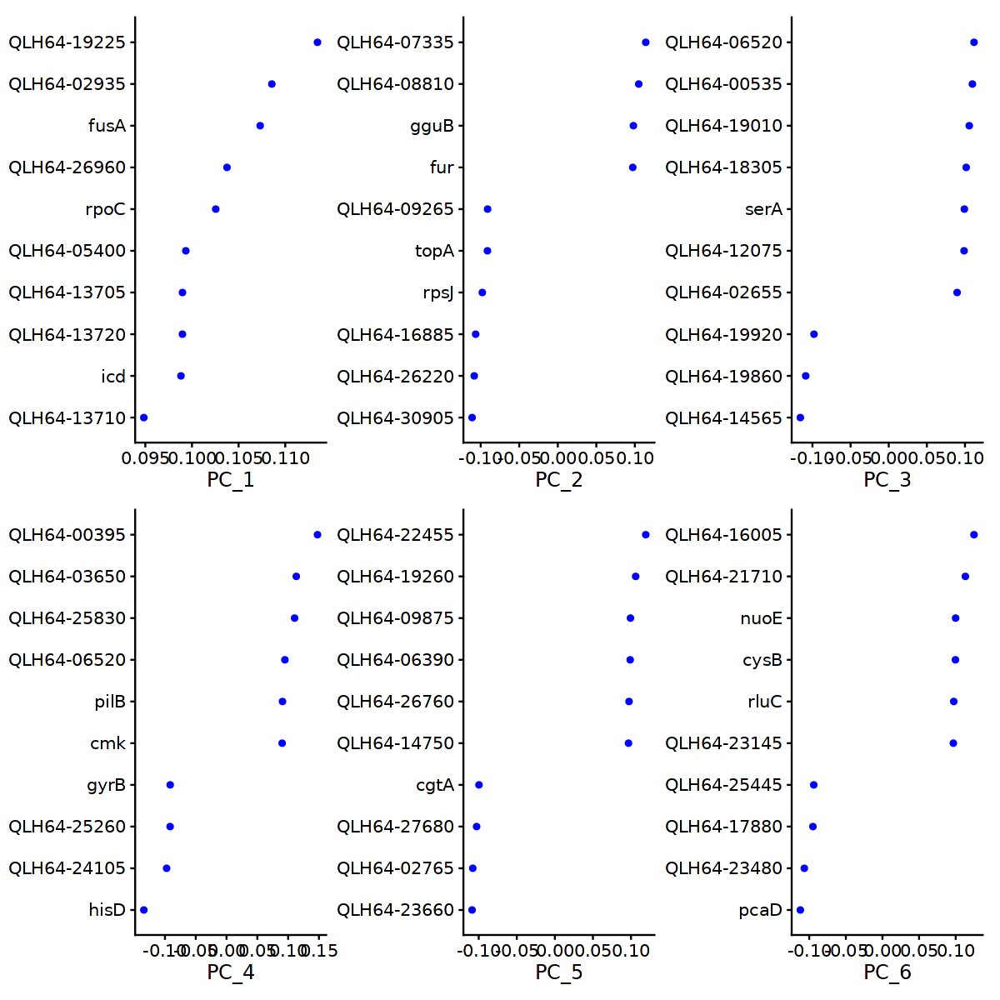

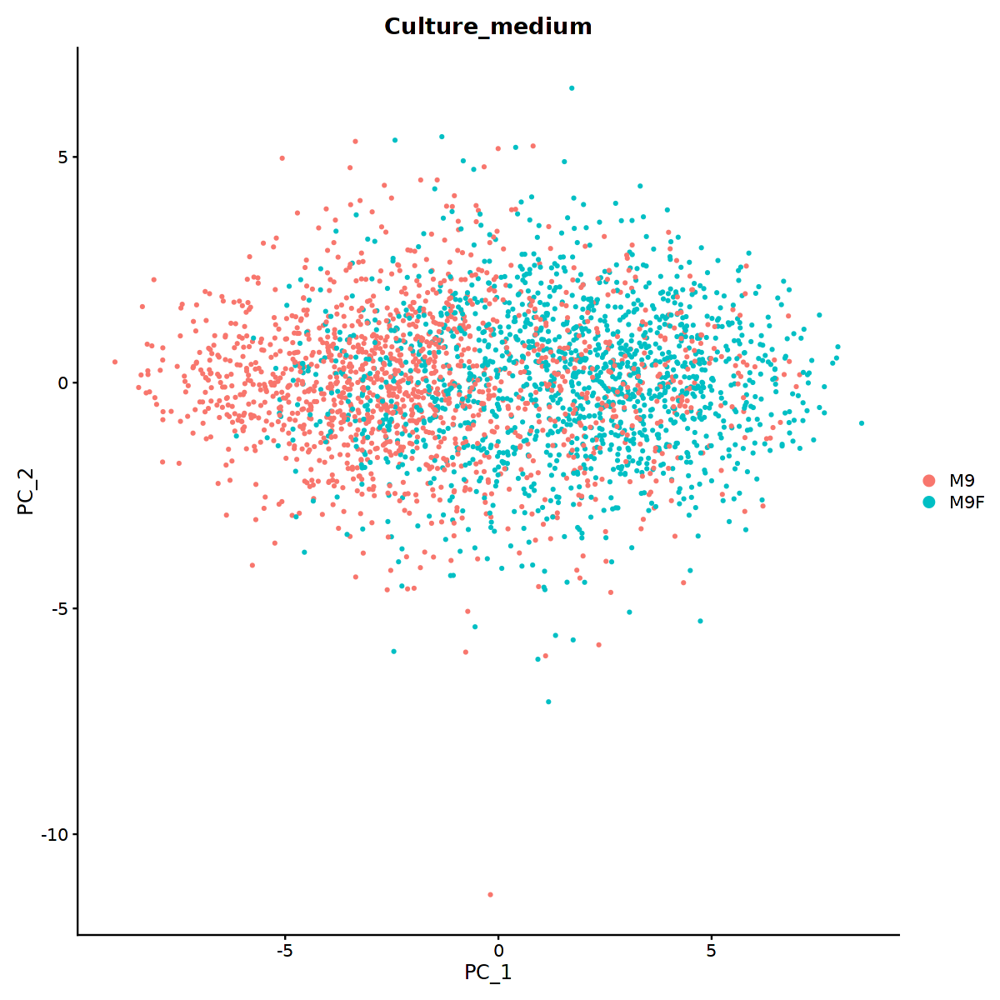

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 95123

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7124
Number of communities: 3
Elapsed time: 0 seconds


14:35:56 UMAP embedding parameters a = 0.9922 b = 1.112

14:35:56 Read 2934 rows and found 10 numeric columns

14:35:56 Using Annoy for neighbor search, n_neighbors = 30

14:35:56 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:35:57 Writing NN index file to temp file /tmp/RtmpoxfOPx/file3bc36e17643

14:35:57 Searching Annoy index using 1 thread, search_k = 3000

14:35:58 Annoy recall = 100%

14:35:59 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:36:01 Initializing from normalized Laplacian + noise (using RSpectra)

14:36:01 Commencing optimization for 500 epochs, with 119480 positive edges

14:36:01 Using rng type: pcg

14:36:04 Optimization finished



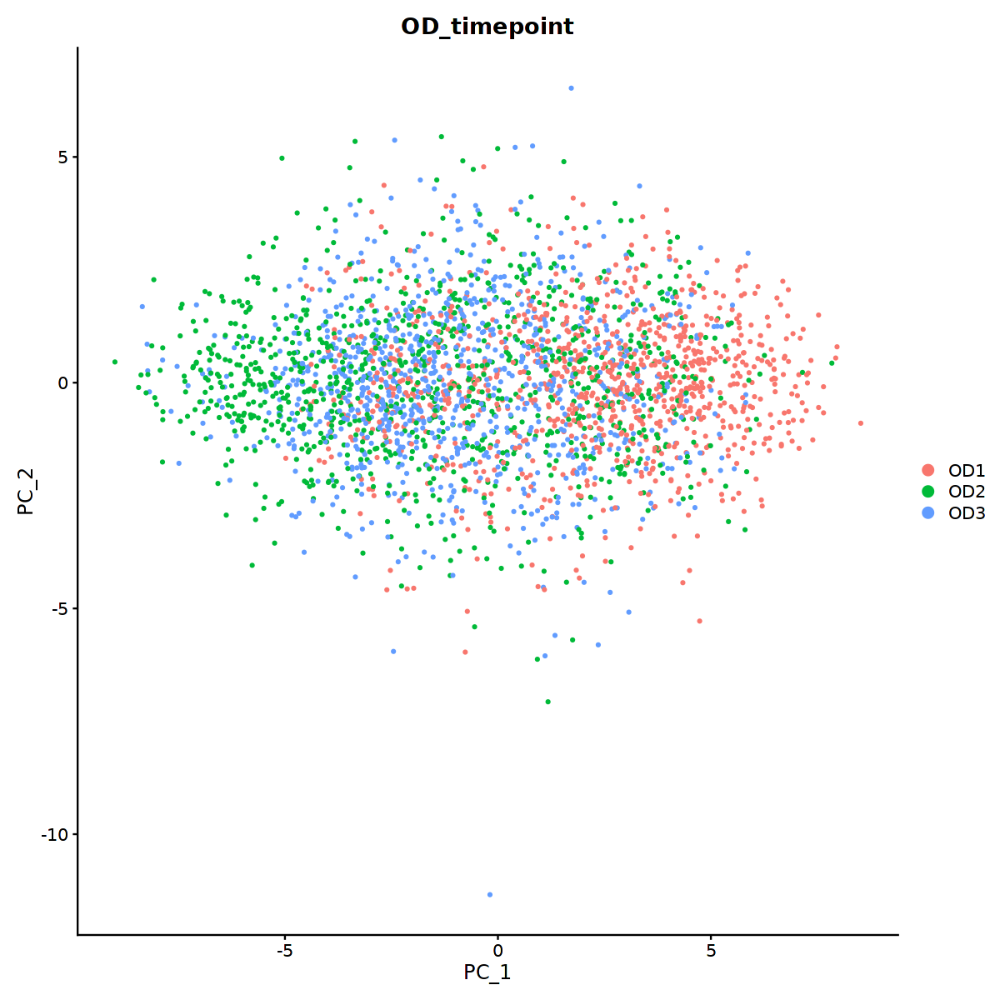

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"
PC_ 1 
Positive:  QLH64-19225, QLH64-05310, aceE, QLH64-02935, QLH64-00420, atpD, QLH64-23140, fusA, ccoN_2, rpoC 
	   icd, QLH64-26960, QLH64-05400, QLH64-12125, raiA, rplN, QLH64-09610, QLH64-13720, gap, rplB 
	   QLH64-03465, QLH64-07480, QLH64-13705, infC, oprI, acnB, QLH64-22540, QLH64-13710, QLH64-12435, QLH64-27060 
Negative:  QLH64-24105, yacG, QLH64-28305, ccmD, QLH64-02320, QLH64-03265, QLH64-16715, QLH64-18880, QLH64-07650, QLH64-00360 
	   gluQRS, QLH64-06955, QLH64-09535, QLH64-23370, QLH64-15900, QLH64-01365, QLH64-17215, QLH64-17200, QLH64-05945, QLH64-06945 
	   QLH64-22115, QLH64-02630, QLH64-01455, QLH64-07610, QLH64-12875, QLH64-14890, QLH64-14575, QLH64-30225, QLH64-23410, QLH64-08090 
PC_ 2 
Positive:  trpA, QLH64-12175, QLH64-05120, thiO, nadC, ubiG, QLH64-08840, QLH64-30400, QLH64-30385, QLH64-07

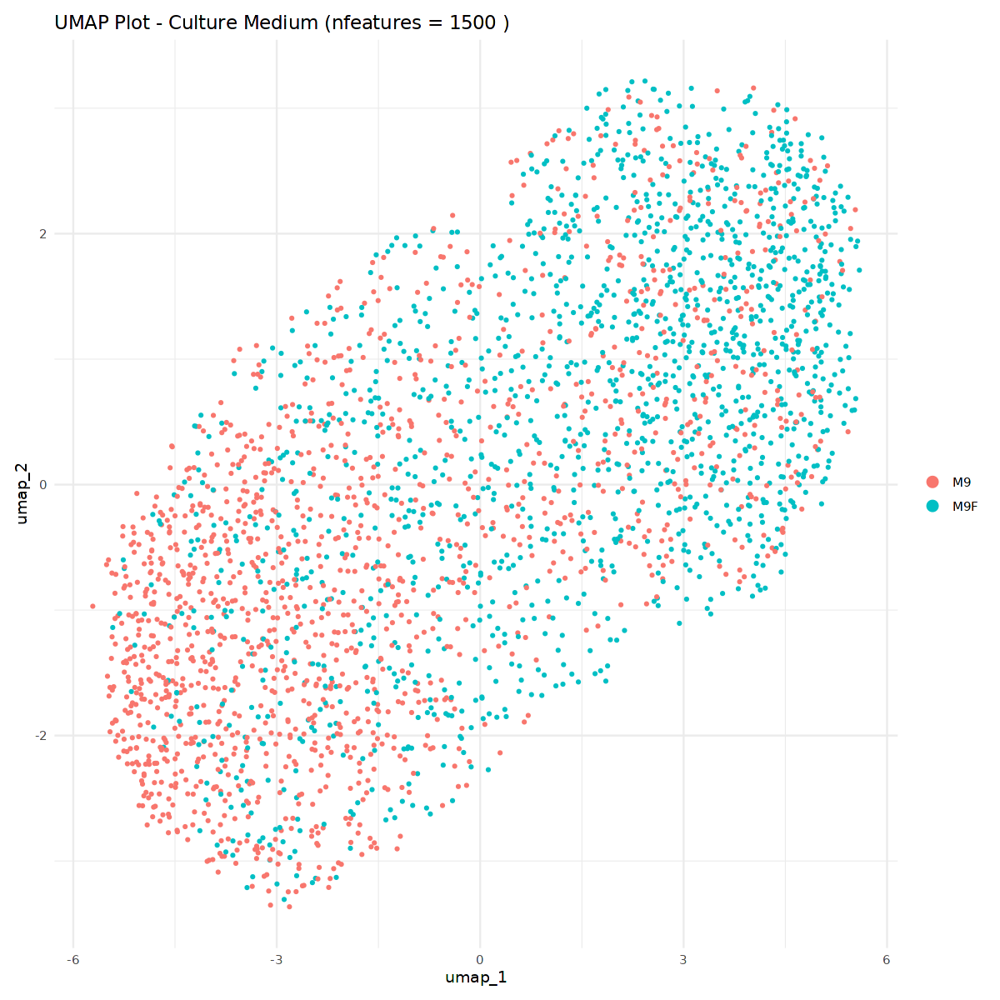

Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


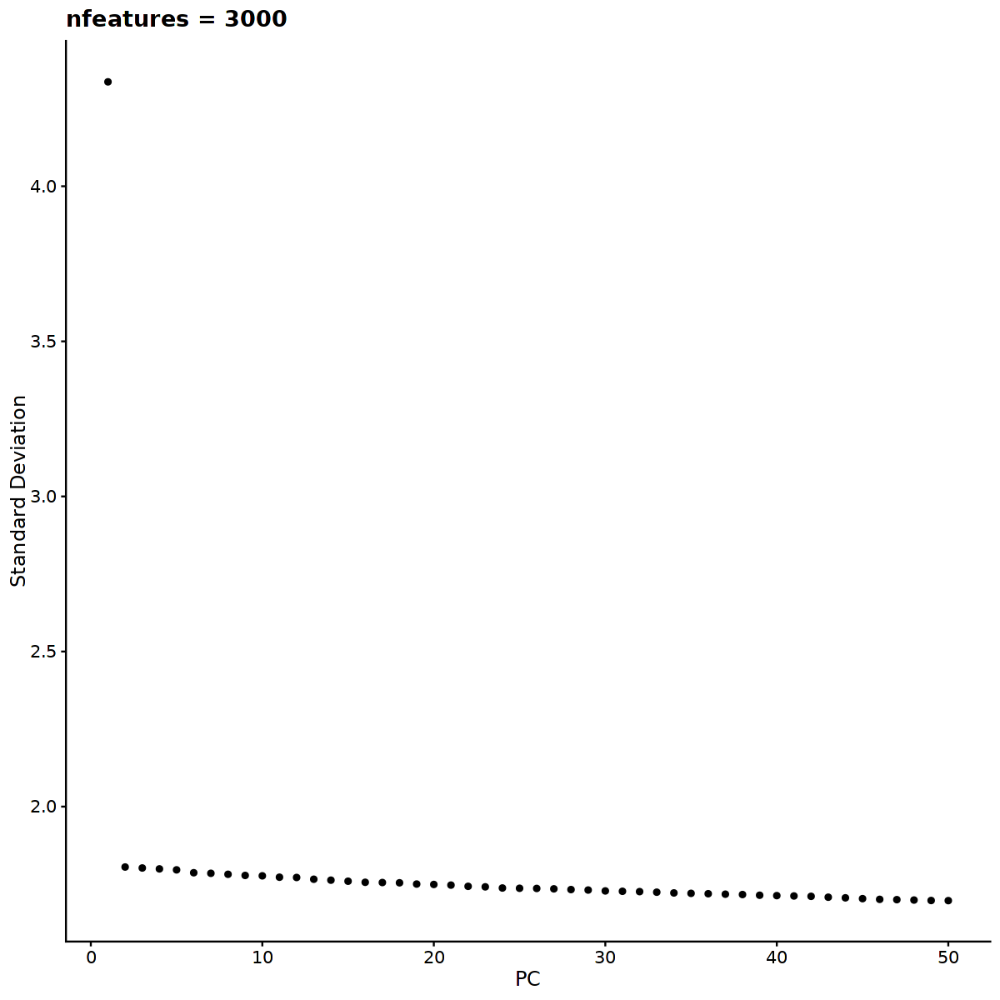

NULL


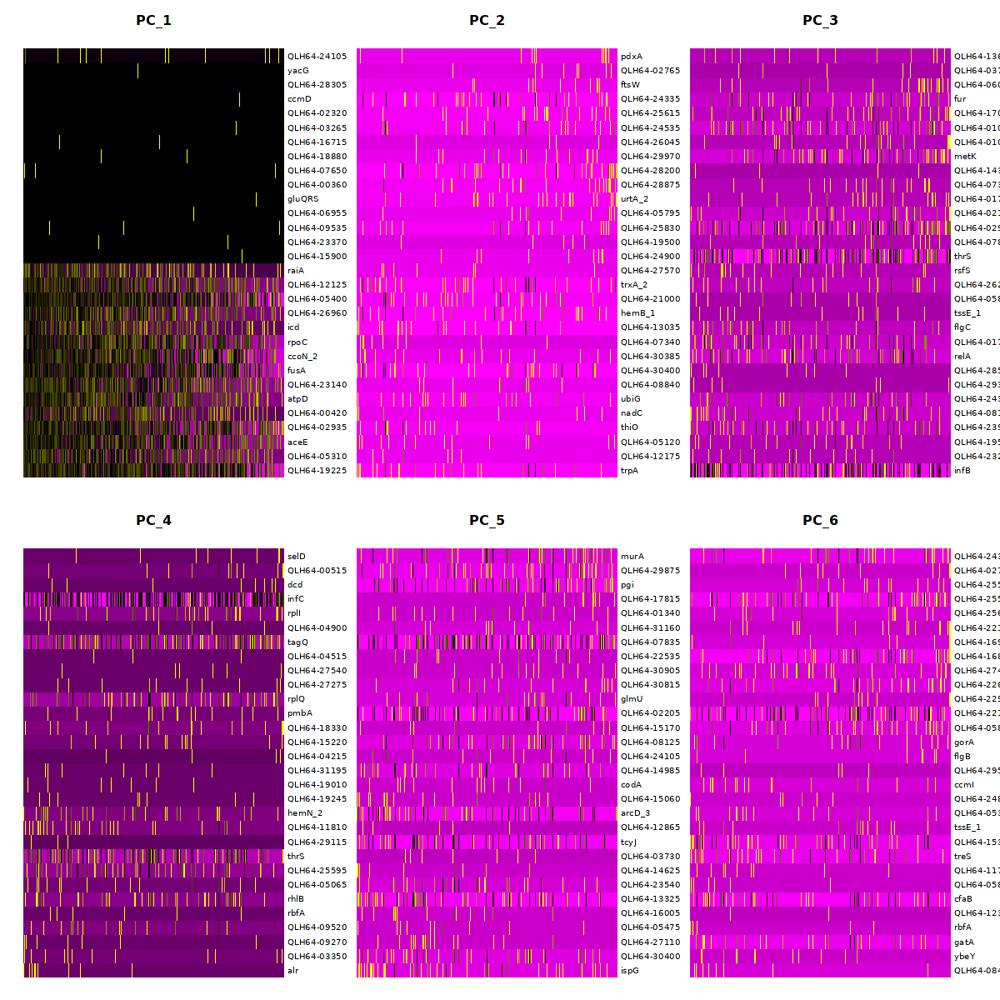

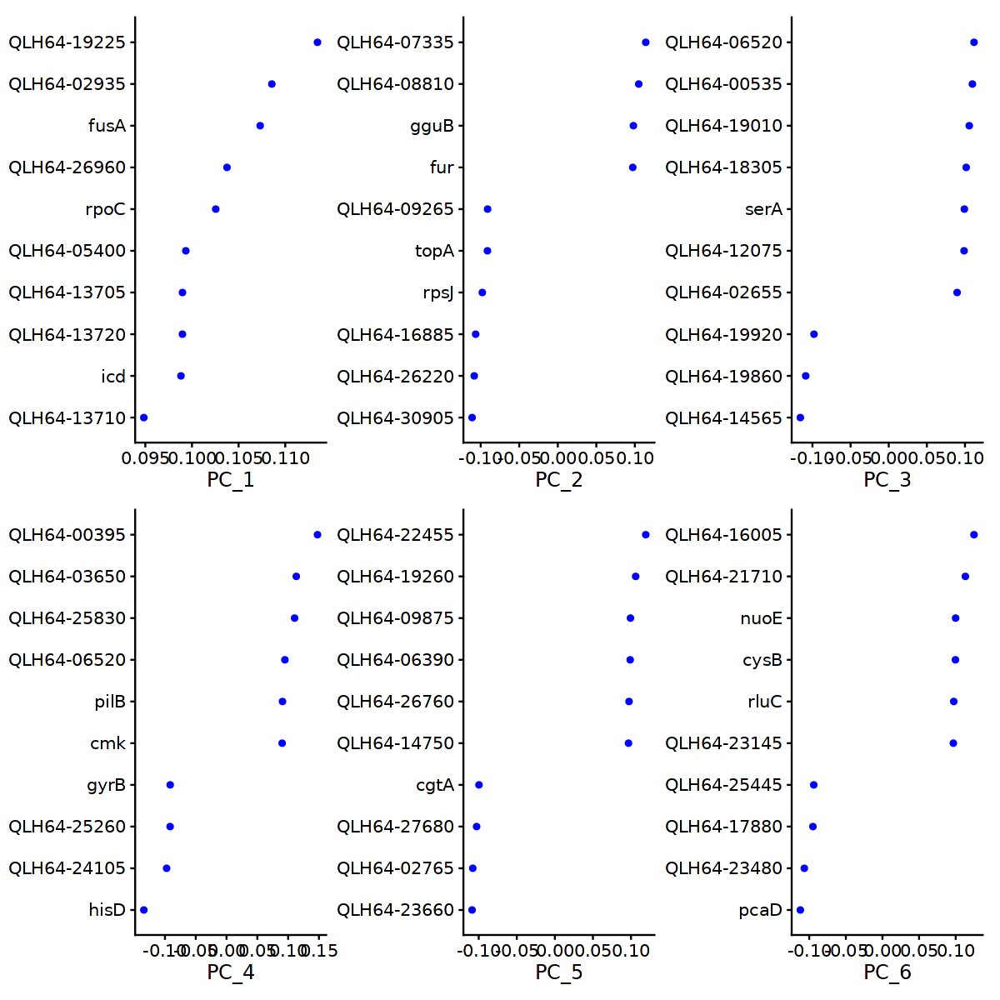

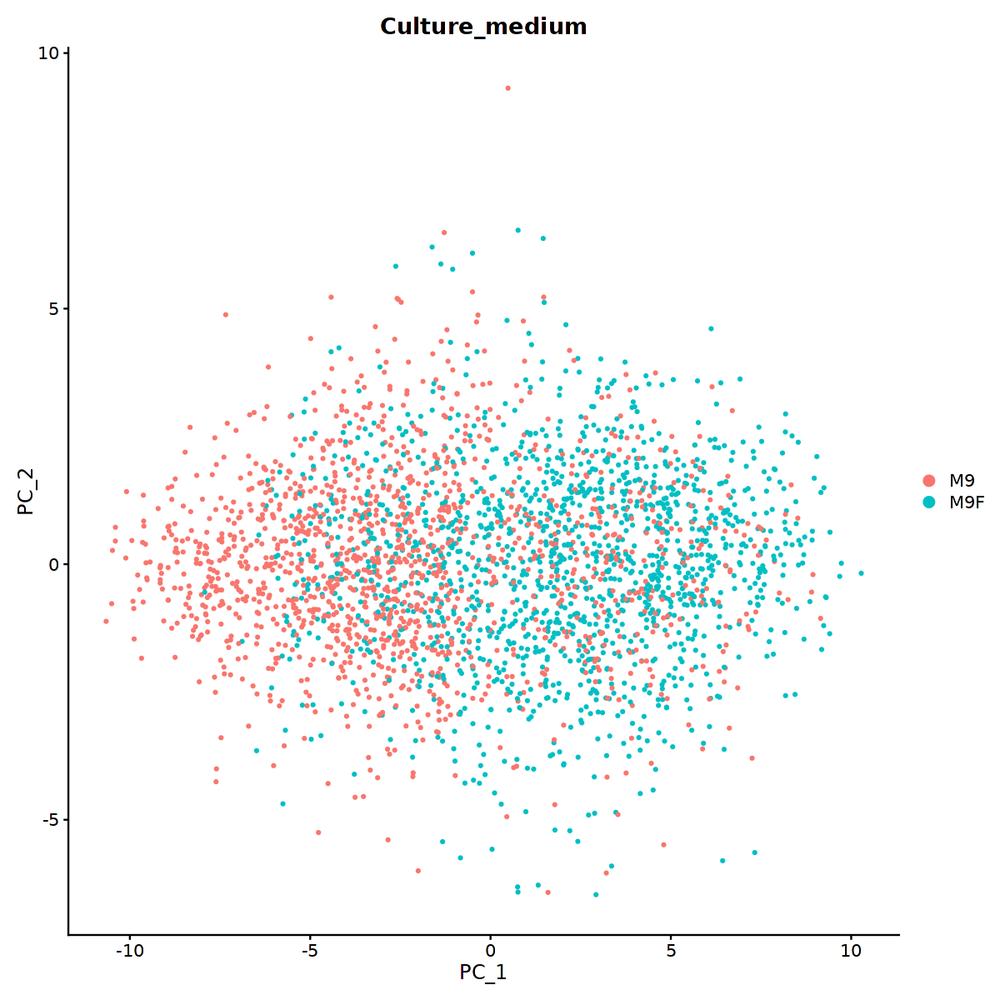

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 95698

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7277
Number of communities: 3
Elapsed time: 0 seconds


14:36:21 UMAP embedding parameters a = 0.9922 b = 1.112

14:36:21 Read 2934 rows and found 10 numeric columns

14:36:21 Using Annoy for neighbor search, n_neighbors = 30

14:36:21 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:36:22 Writing NN index file to temp file /tmp/RtmpoxfOPx/file3bc2234b739

14:36:22 Searching Annoy index using 1 thread, search_k = 3000

14:36:23 Annoy recall = 100%

14:36:24 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:36:25 Initializing from normalized Laplacian + noise (using RSpectra)

14:36:25 Commencing optimization for 500 epochs, with 123114 positive edges

14:36:25 Using rng type: pcg

14:36:28 Optimization finished



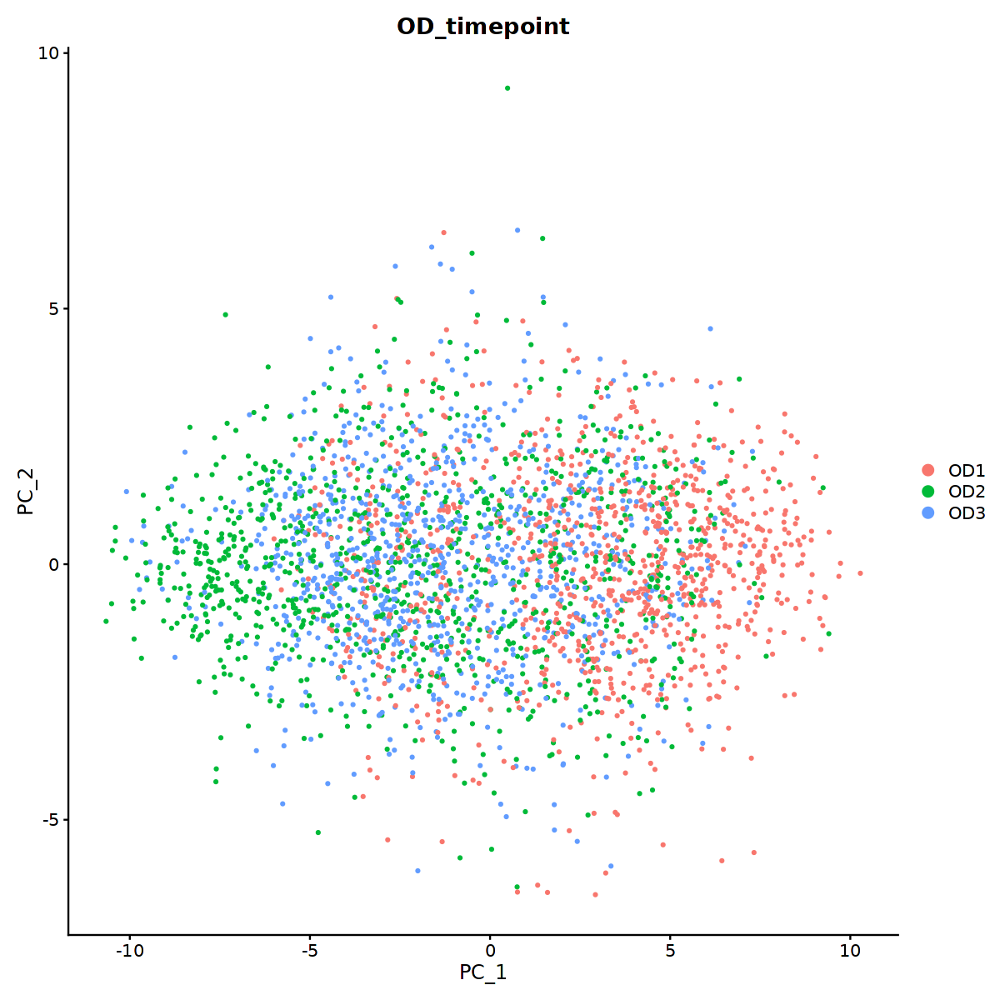

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"
PC_ 1 
Positive:  QLH64-19985, QLH64-24105, ccmD, yacG, pqqD, QLH64-01880, QLH64-02320, QLH64-28305, QLH64-07650, ttcA 
	   gluQRS, QLH64-06945, QLH64-15270, QLH64-03265, QLH64-18880, QLH64-00360, QLH64-06955, QLH64-15045, QLH64-01365, QLH64-05945 
	   QLH64-01820, QLH64-07240, tssE_2, QLH64-16715, QLH64-15900, QLH64-21340, QLH64-01455, QLH64-17200, QLH64-11075, QLH64-05160 
Negative:  QLH64-19225, QLH64-05310, QLH64-16050, QLH64-02935, aceE, atpD, fusA, QLH64-00420, QLH64-23140, ccoN_2 
	   rpoC, QLH64-26960, rpoB, icd, QLH64-12125, tuf_1, QLH64-00840, glnA, clpA, QLH64-05400 
	   QLH64-13720, QLH64-00425, QLH64-09610, gap, rplN, QLH64-19865, raiA, QLH64-03465, QLH64-07480, infC 
PC_ 2 
Positive:  QLH64-21750, fliM, QLH64-24335, truB, QLH64-24300, QLH64-24430, QLH64-19035, QLH64-10810, QLH64-14565, QLH64-14950 
	   QL

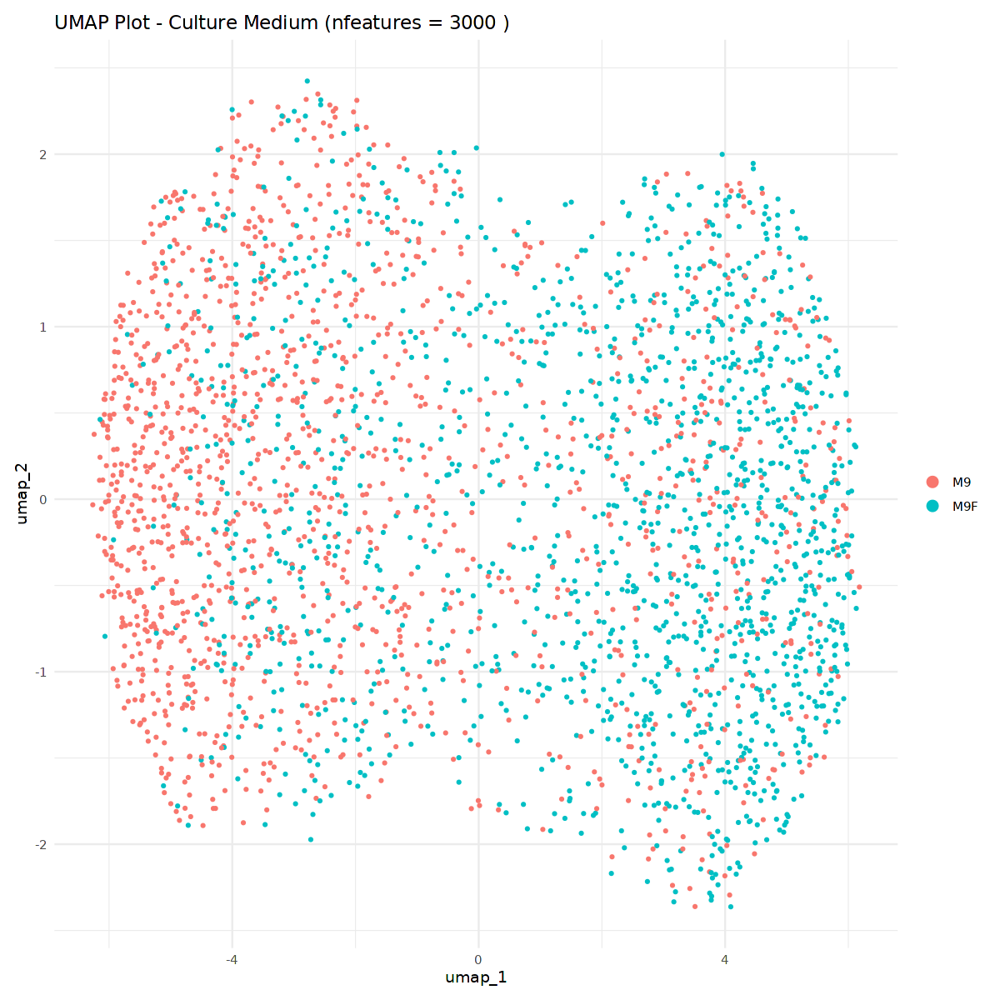

Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


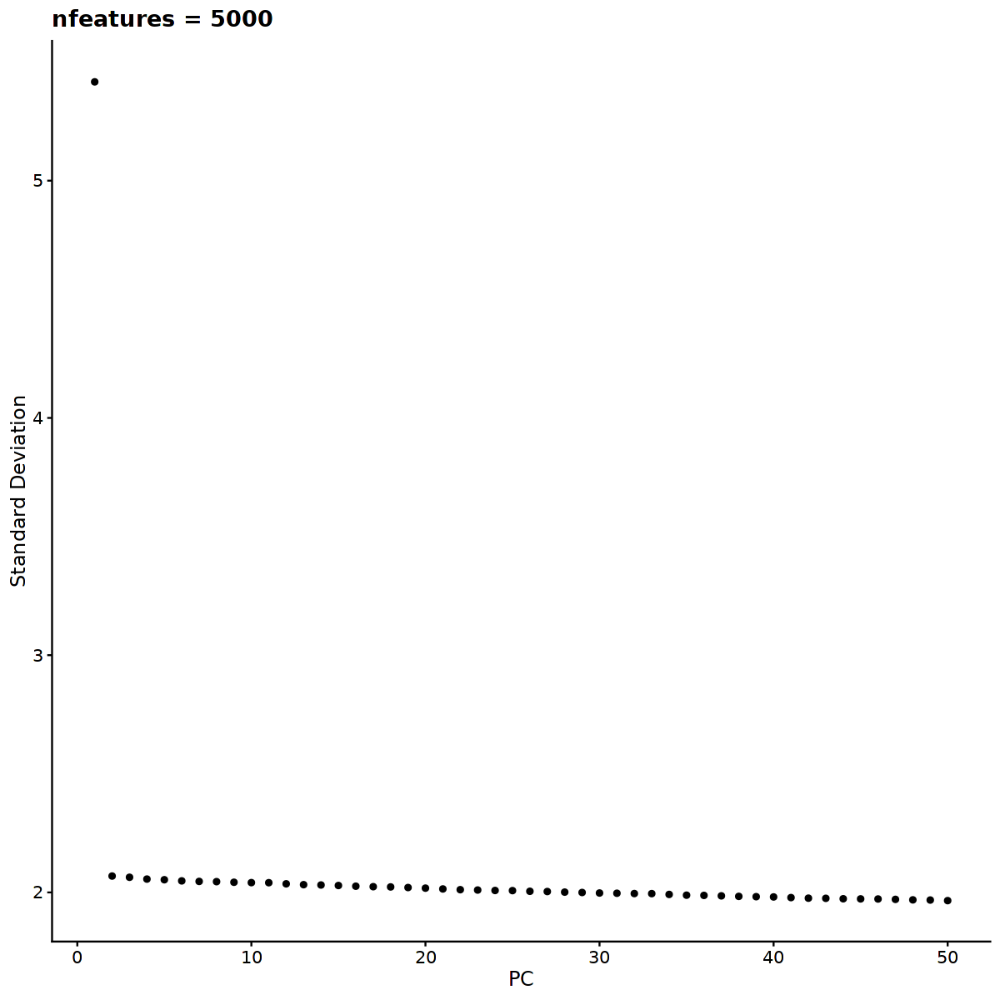

NULL


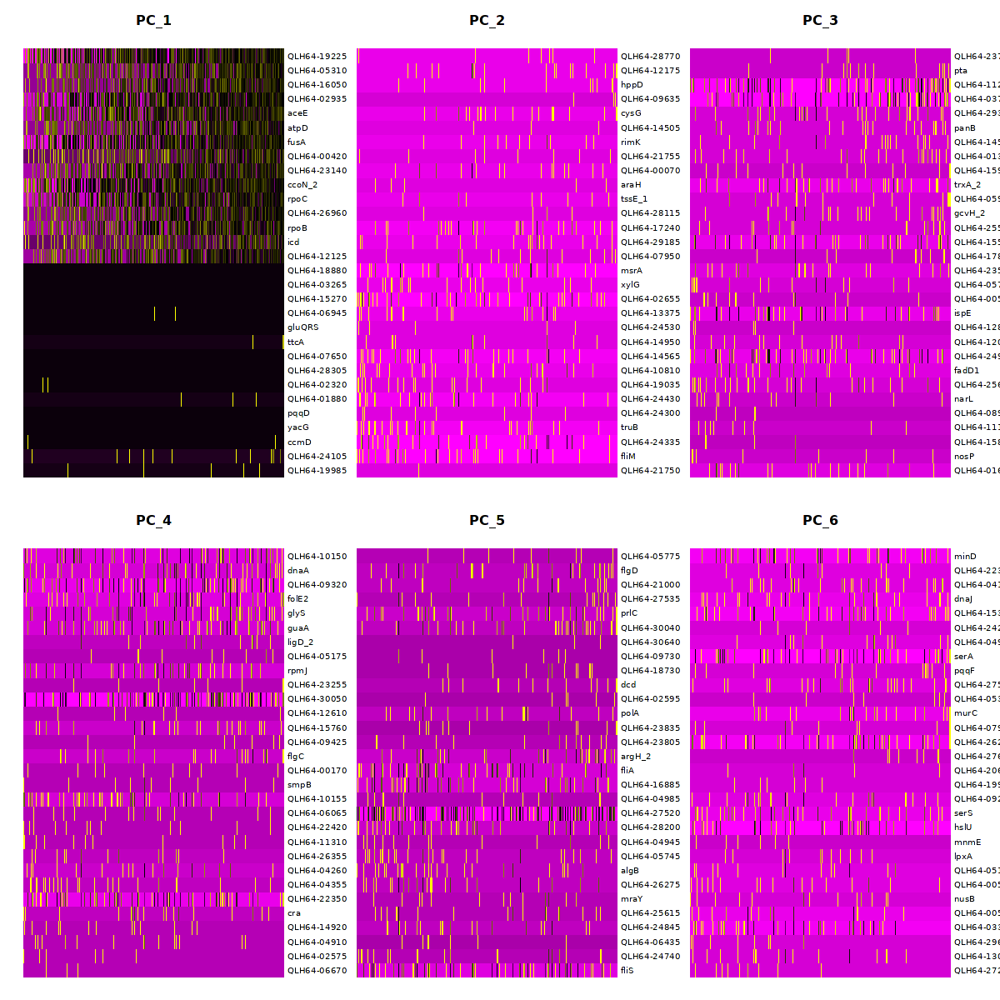

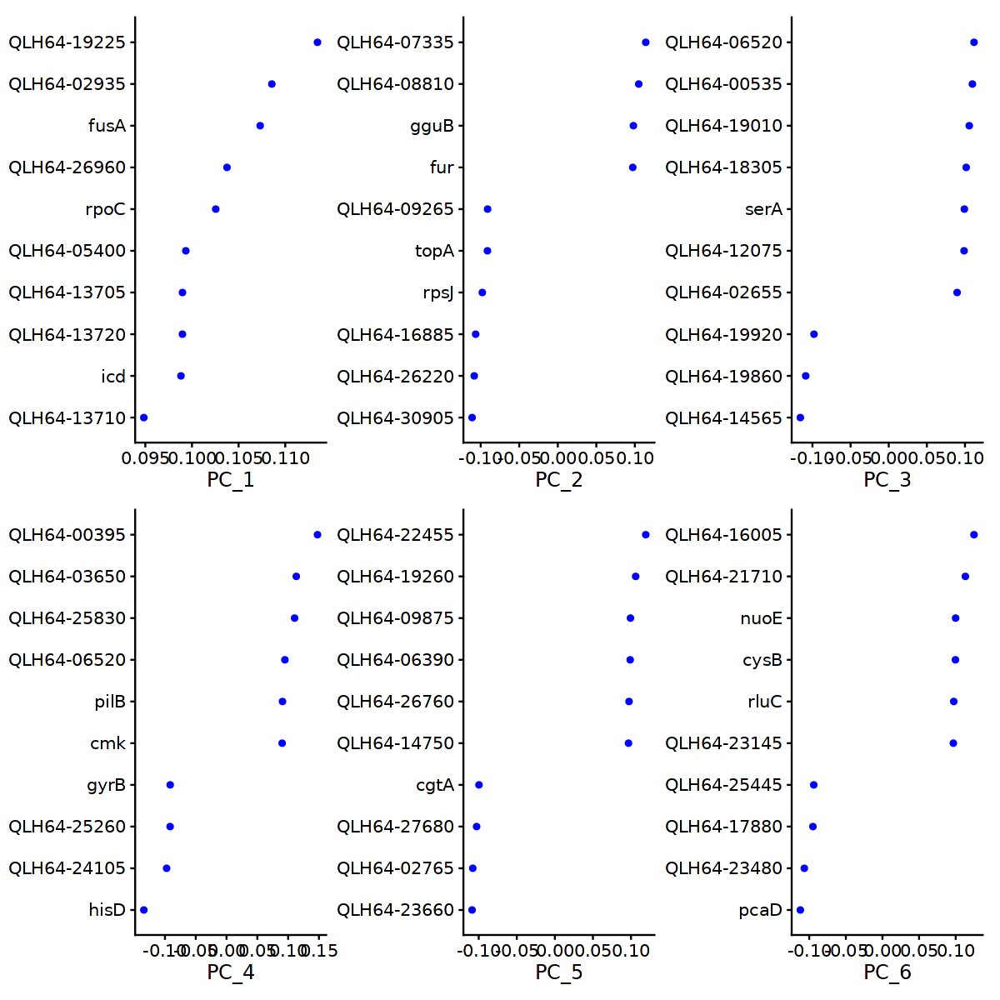

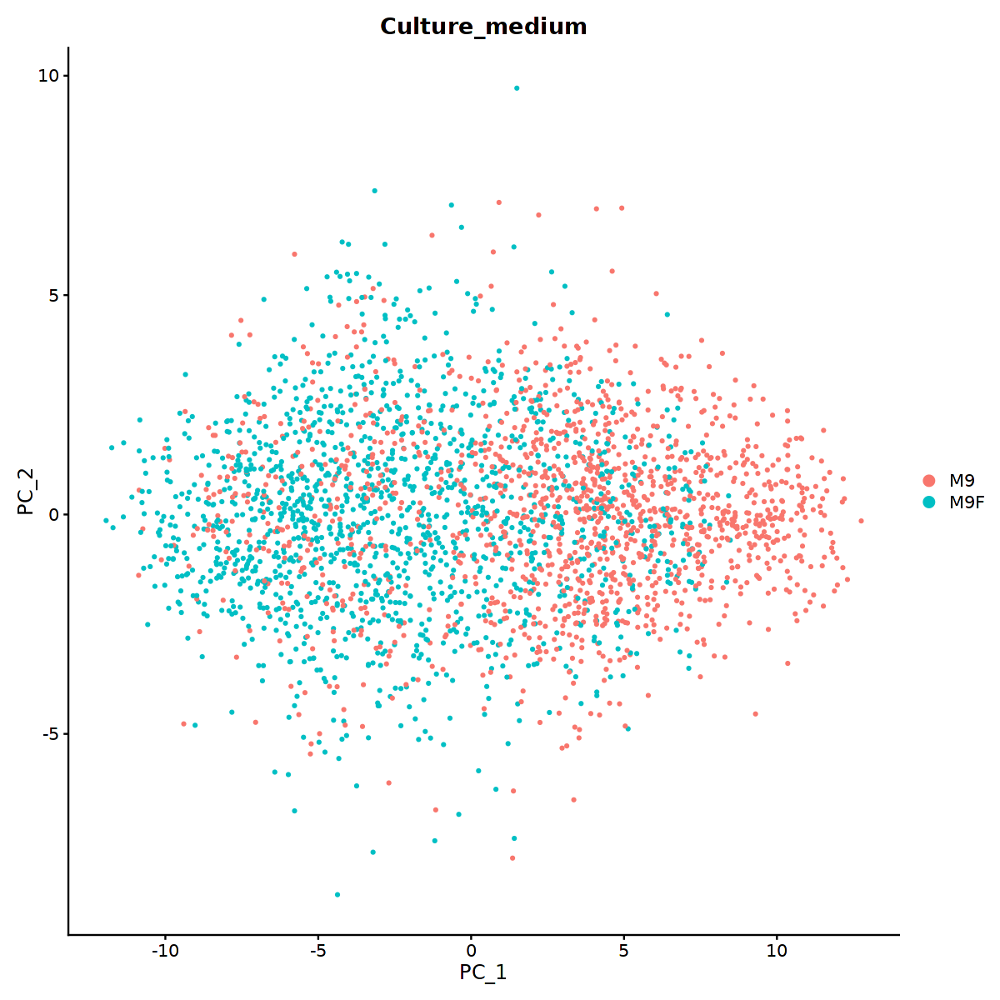

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 97138

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7439
Number of communities: 3
Elapsed time: 0 seconds


14:36:53 UMAP embedding parameters a = 0.9922 b = 1.112

14:36:53 Read 2934 rows and found 10 numeric columns

14:36:53 Using Annoy for neighbor search, n_neighbors = 30

14:36:53 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:36:54 Writing NN index file to temp file /tmp/RtmpoxfOPx/file3bc9b309a3

14:36:54 Searching Annoy index using 1 thread, search_k = 3000

14:36:55 Annoy recall = 100%

14:36:57 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:36:58 Initializing from normalized Laplacian + noise (using RSpectra)

14:36:58 Commencing optimization for 500 epochs, with 126914 positive edges

14:36:58 Using rng type: pcg

14:37:01 Optimization finished



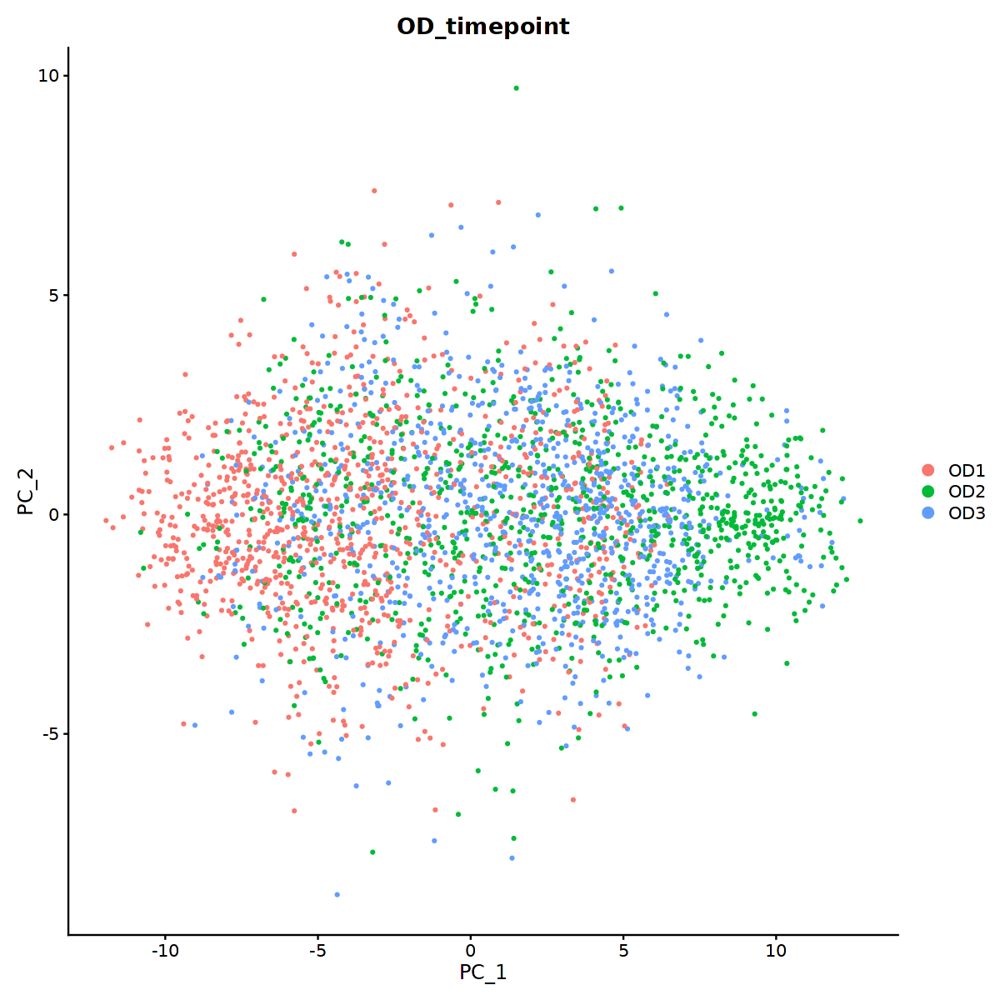

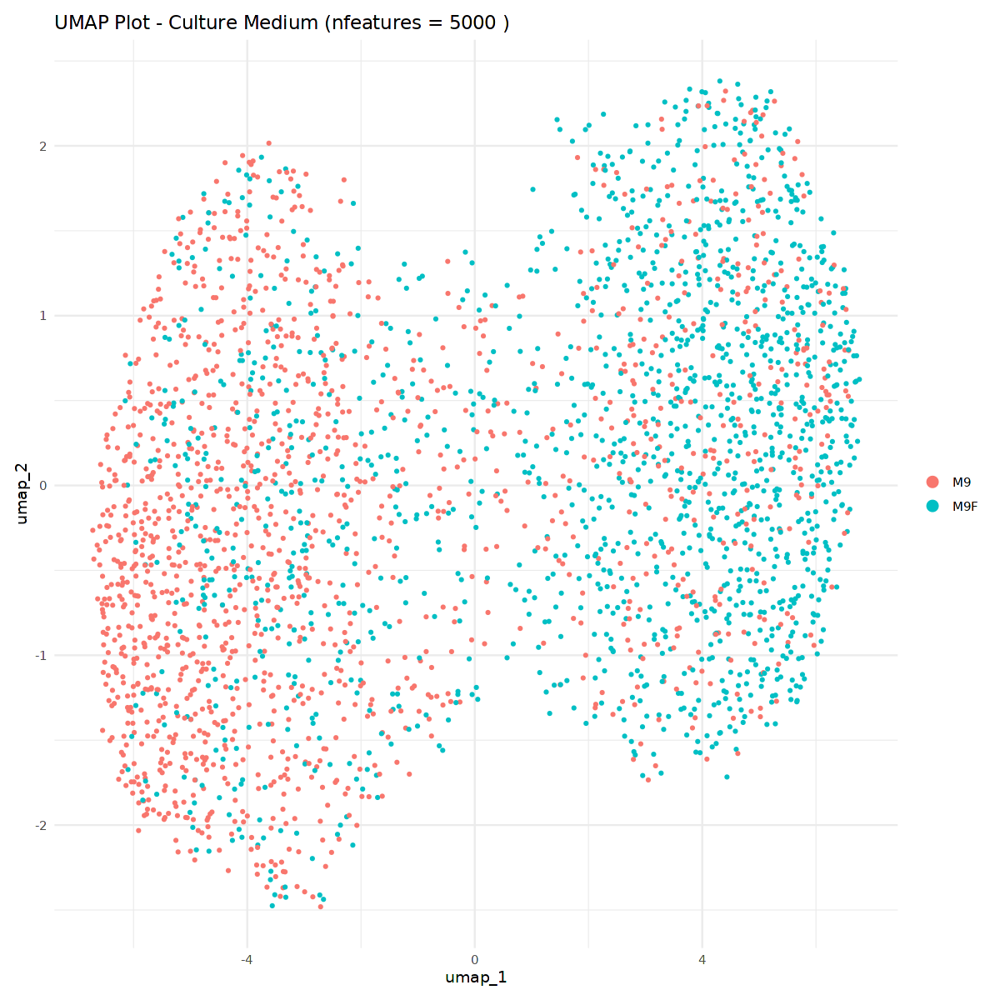

In [184]:
for (n in c(200, 500, 1000, 1500, 3000, 5000)) {
  seu_tmp <- FindVariableFeatures(seurat_obj, nfeatures = n)
  seu_tmp <- ScaleData(seu_tmp)
  seu_tmp <- RunPCA(seu_tmp)
  
  print(ElbowPlot(seu_tmp, 50) + ggtitle(paste("nfeatures =", n)))
  print( DimHeatmap(seu_tmp, dims = 1:6, cells = 4000, balanced = TRUE, ncol = 3))
  print(VizDimLoadings(seurat_obj, dims = 1:6, reduction = "pca", ncol = 3, nfeature=10))
  print(DimPlot(seu_tmp, reduction = "pca", dims = 1:2, group.by = "Culture_medium"))
  print(DimPlot(seu_tmp, reduction = "pca", dims = 1:2, group.by = "OD_timepoint"))
  seu_tmp <- FindNeighbors(seu_tmp, dims = 1:10)
  seu_tmp <- FindClusters(seu_tmp, resolution = 0.5)
  seu_tmp <- RunUMAP(seu_tmp, dims = 1:10)
  print(DimPlot(seu_tmp, reduction = "umap", group.by = "Culture_medium") +
          ggtitle(paste("UMAP Plot - Culture Medium (nfeatures =", n, ")")) +
          theme_minimal())
}

Merci pour la précision — c’est un signe important ! Si la première composante principale (PC1) explique quasiment toute la variance, voici comment l’interpréter, surtout dans un contexte scRNA-seq bactérien :

⸻

🧠 1. Ce que cela signifie :

⚠️ Hypothèse : PC1 explique 80–90 % ou + de la variance

Cela peut indiquer :

a) Effet technique dominant
	•	Batch effect (date d’extraction, condition, etc.)
	•	Library size (cellules avec plus/moins de transcrits)
	•	Nombre total de gènes détectés (richesse)
	•	Contamination (ex. : ARN ribosomique restant ou ARN exogène)

→ À vérifier via FeatureScatter() ou DimPlot() avec nCount_RNA, percent.mt, etc.

b) Séparation très nette d’un facteur biologique
	•	Exemple : stress vs non-stress, condition A vs B très différente
	•	Possible si tu as 2 populations très hétérogènes (ex. glucose vs fer limitant)

c) Pas assez de gènes informatifs → un seul axe capte tout
	•	Si tu sélectionnes trop peu de features, ou des gènes peu variables (ex. tous très bas ou très forts)
	•	Cela peut être un artefact du choix de nfeatures

⸻

🔬 2. Comment tester ce qui se passe ?

✅ a) Vérifie l’influence de la couverture :

FeatureScatter(seurat_object, feature1 = "nCount_RNA", feature2 = "PC_1")

Si c’est corrélé → effet technique.

✅ b) Colorie UMAP/PCA par métadonnées :

DimPlot(seurat_object, reduction = "pca", group.by = "condition")  # ou "batch", etc.

Si PC1 sépare très clairement tes conditions → signal biologique fort (c’est bon !)

⸻

🛠️ 3. Que faire ensuite ?

Situation	Action recommandée
PC1 = batch effect (ou autre facteur tech.)	Régresses avec ScaleData(..., vars.to.regress = c("nCount_RNA", ...))
PC1 = biologie (conditions bien séparées)	👍 Tu peux continuer l’analyse avec 10–20 PCs
PC1 = artefact de sélection (trop peu de gènes)	Teste avec plus de nfeatures (ex : 1000 → 2000)


⸻

🔁 Exemple pour corriger l’effet technique :

seurat_object <- ScaleData(
  seurat_object,
  vars.to.regress = c("nCount_RNA", "percent.mt")  # ou autre variable technique
)
seurat_object <- RunPCA(seurat_object)
ElbowPlot(seurat_object)


⸻

Souhaites-tu que je t’aide à explorer ça étape par étape avec ton objet Seurat (variables à régresser, gènes variables, etc.) ?

==== nfeatures = 200 ====

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  QLH64-00395, ndk, QLH64-05905, folE2, QLH64-14565, QLH64-12130, QLH64-03850, QLH64-25565, topA, QLH64-11810 
	   QLH64-27880, QLH64-22035, hldE, fur, cysD, QLH64-16785, QLH64-00295, gshA, QLH64-19260, QLH64-17430 
	   cysB, QLH64-06375, QLH64-22005, QLH64-00515, QLH64-03590, QLH64-27175, QLH64-15200, QLH64-18745, QLH64-16790, QLH64-10155 
Negative:  QLH64-03825, choX_1, QLH64-14525, cobA_1, QLH64-30010, QLH64-08635, QLH64-24590, QLH64-09505, QLH64-08330, QLH64-04585 
	   QLH64-10530, QLH64-08350, QLH64-31240, QLH64-25710, QLH64-13525, QLH64-23710, QLH64-20890, QLH64-24145, QLH64-13385, QLH64-17505 
	   QLH64-12320, QLH64-02630, QLH64-05540, QLH64-19895, QLH64-02665, QLH64-23730, QLH64-17820, QLH64-14640, QLH64-14995, QLH64-02635 
PC_ 2 
Positive:  astE, QLH64-10155, QLH64-03850, prs, QLH64-24875, QLH64-29395, QLH64-17255, QLH64-03215, QLH64-25565, folE2 
	   QLH64

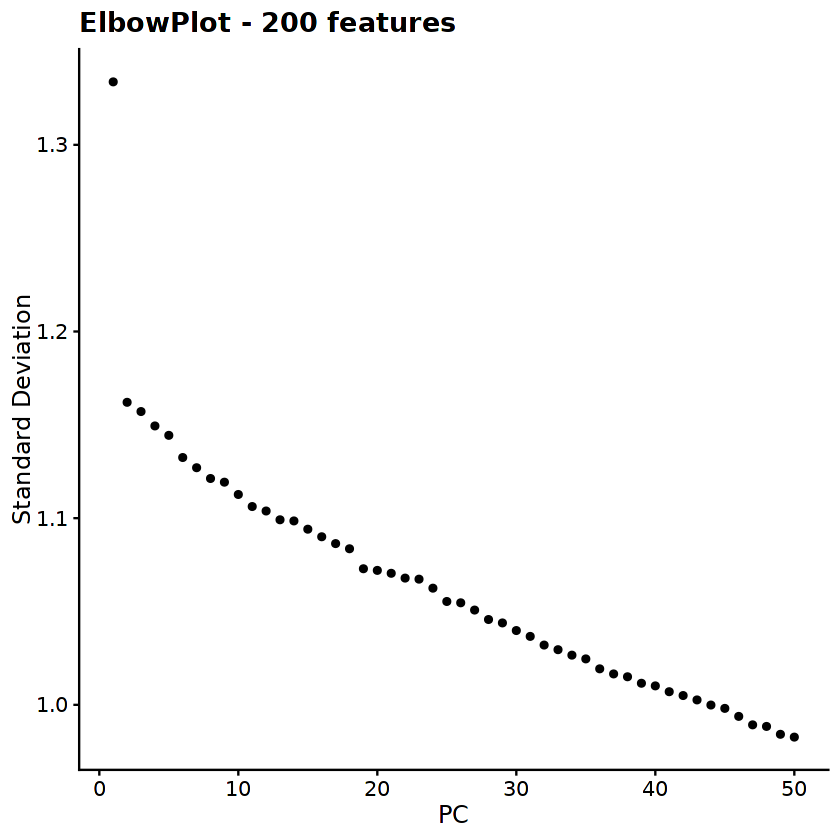

NULL


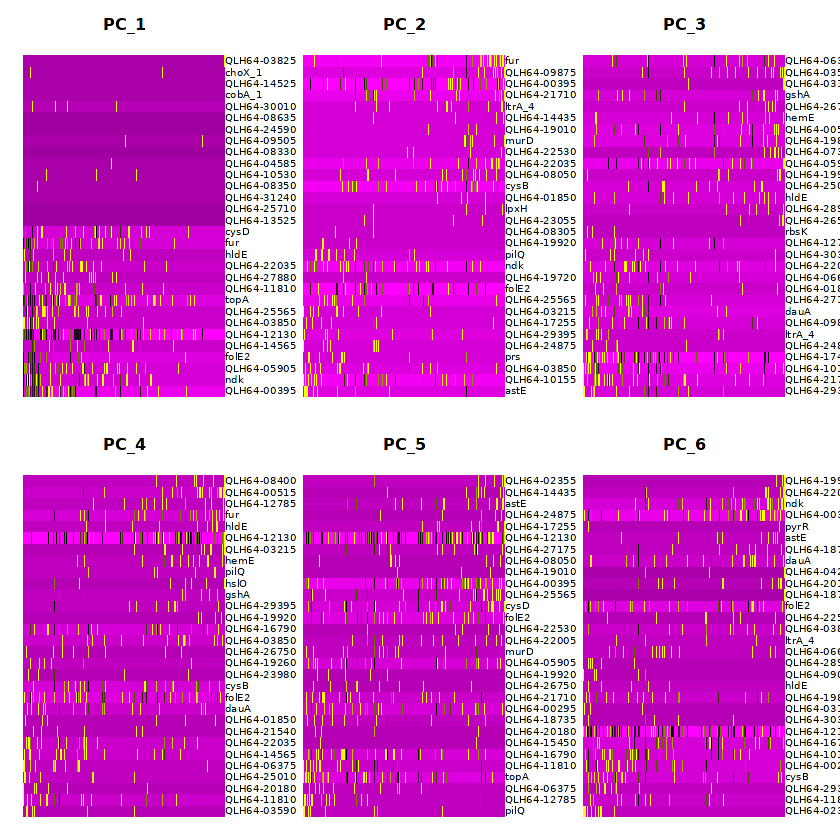

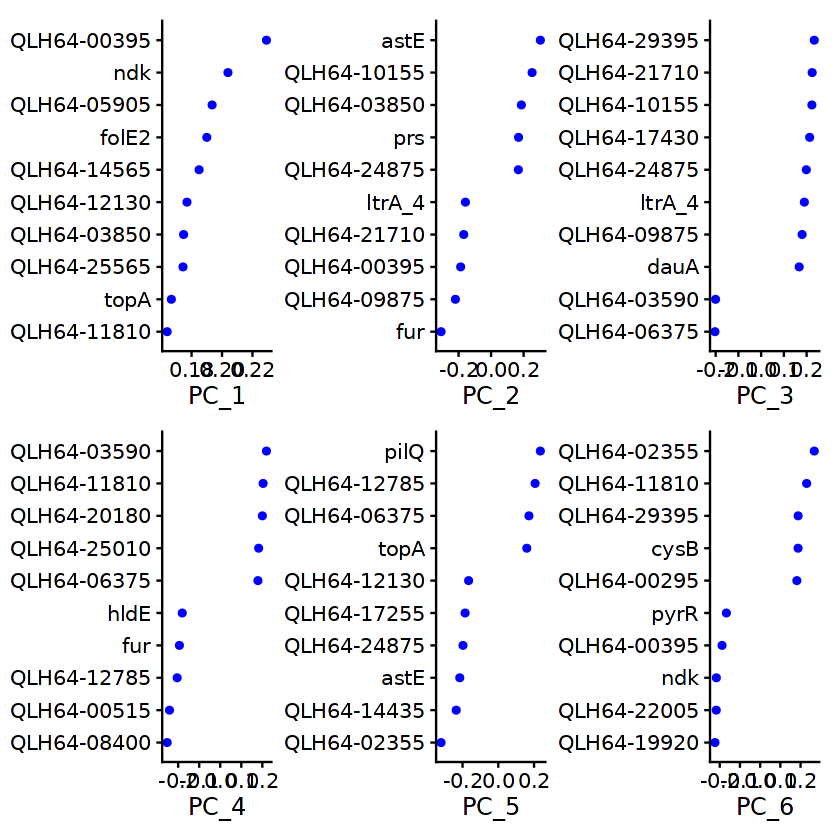

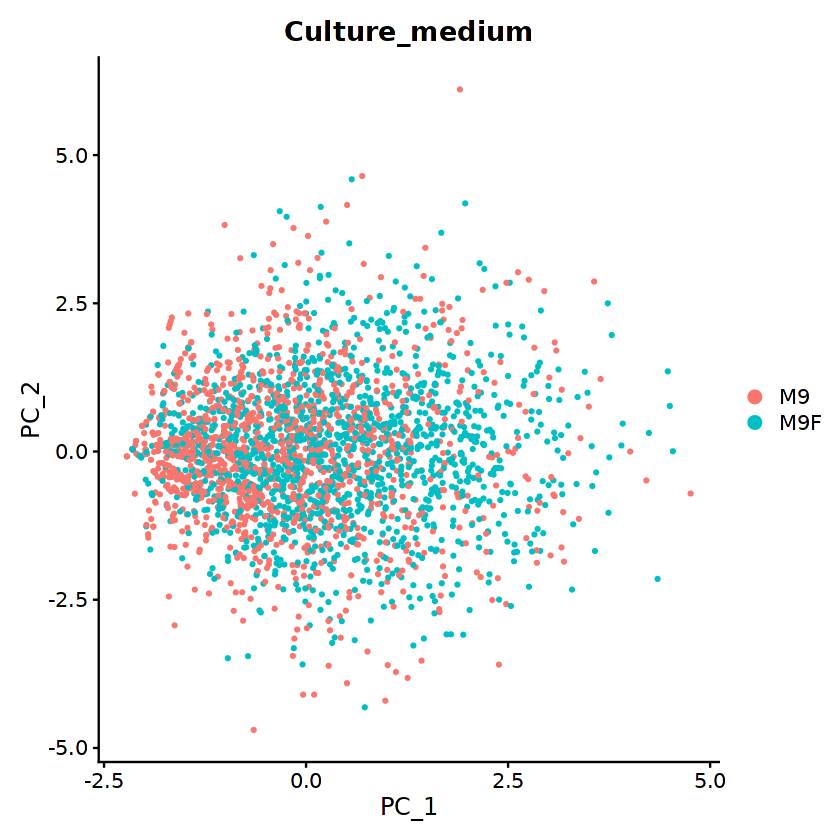

>> nfeatures: 200 | dims: dims_1_5 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 94508

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8495
Number of communities: 3
Elapsed time: 0 seconds


Warning message:
"The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session"
14:55:04 UMAP embedding parameters a = 0.9922 b = 1.112

14:55:04 Read 2934 rows and found 5 numeric columns

14:55:04 Using Annoy for neighbor search, n_neighbors = 30

14:55:04 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:55:05 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100201a8e0ae

14:55:05 Searching Annoy index using 1 thread, search_k = 3000

14:55:06 Annoy recall = 95.23%

14:55:07 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors 

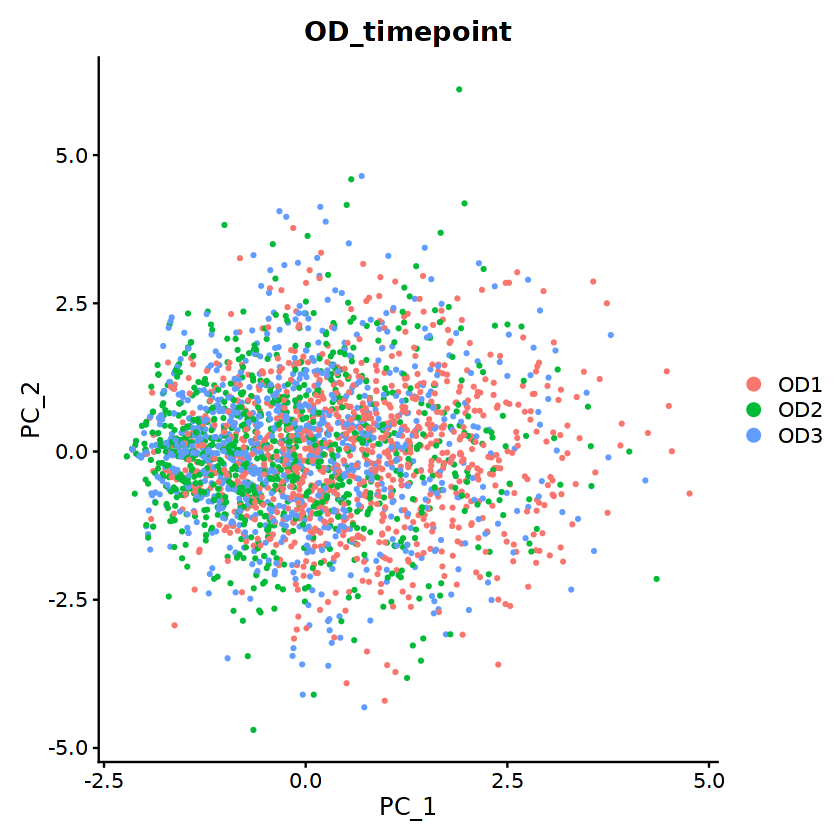

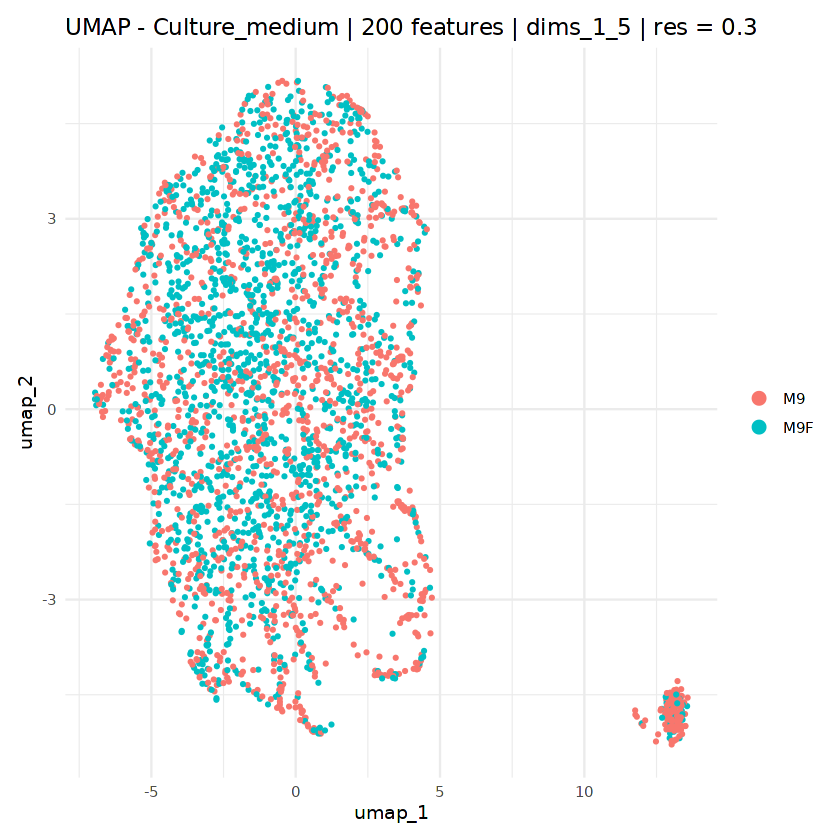

>> nfeatures: 200 | dims: dims_1_5 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 94508

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7655
Number of communities: 5
Elapsed time: 0 seconds


14:55:15 UMAP embedding parameters a = 0.9922 b = 1.112

14:55:15 Read 2934 rows and found 5 numeric columns

14:55:15 Using Annoy for neighbor search, n_neighbors = 30

14:55:15 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:55:15 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002069e40721

14:55:15 Searching Annoy index using 1 thread, search_k = 3000

14:55:16 Annoy recall = 95.23%

14:55:17 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:55:17 173 smooth knn distance failures

14:55:18 Initializing from normalized Laplacian + noise (using RSpectra)

14:55:18 Commencing optimization for 500 epochs, with 101596 positive edges

14:55:18 Using rng type: pcg

14:55:22 Optimization finished



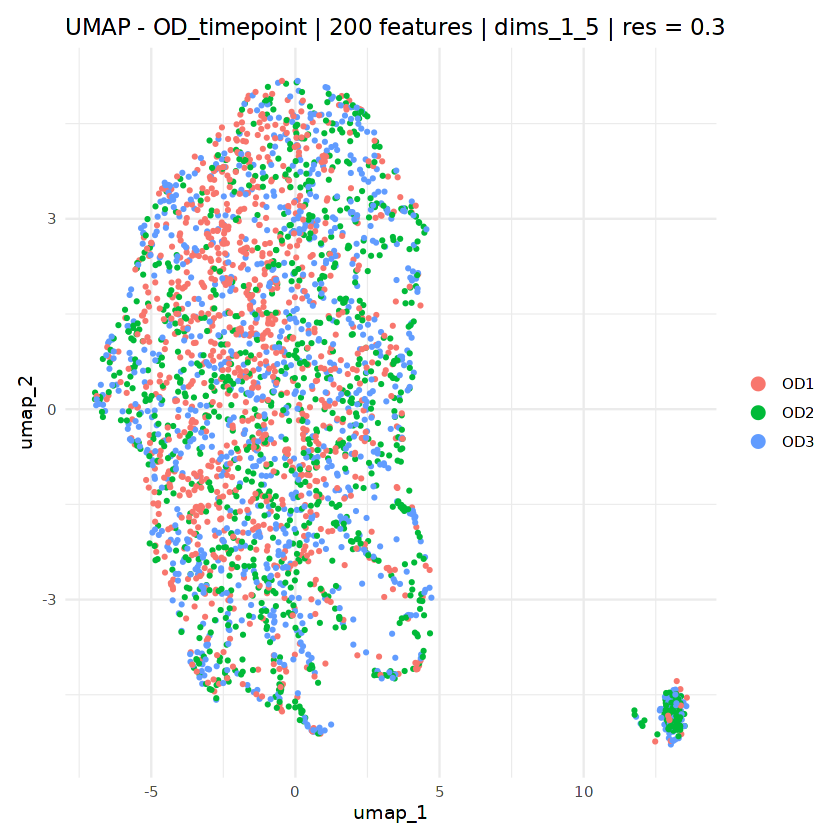

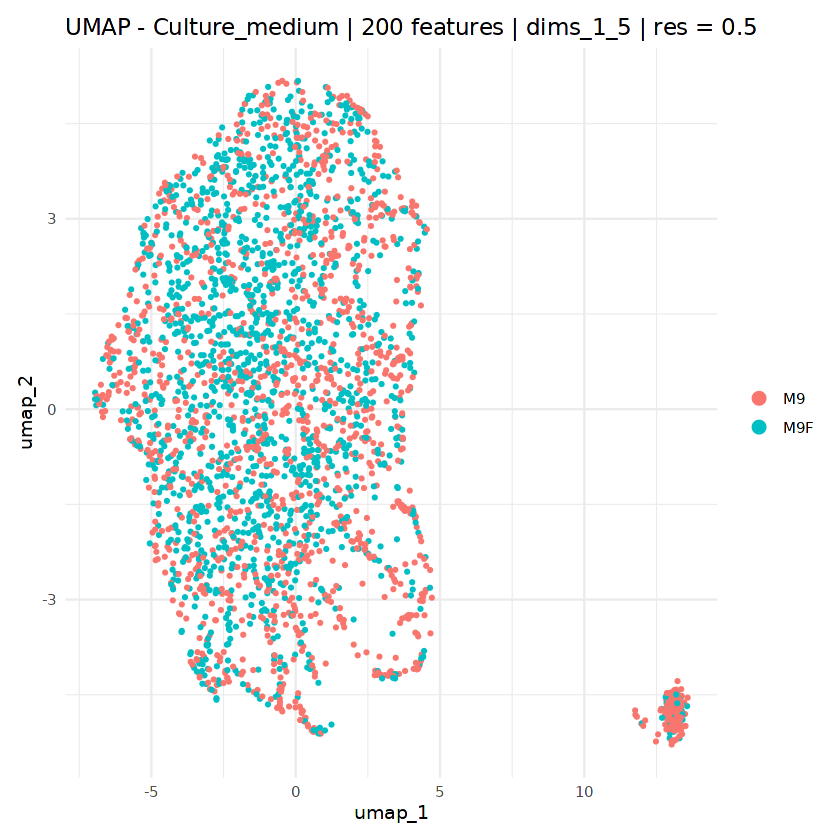

>> nfeatures: 200 | dims: dims_1_5 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 94508

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6645
Number of communities: 8
Elapsed time: 0 seconds


14:55:24 UMAP embedding parameters a = 0.9922 b = 1.112

14:55:24 Read 2934 rows and found 5 numeric columns

14:55:24 Using Annoy for neighbor search, n_neighbors = 30

14:55:24 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:55:25 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100204c3b6919

14:55:25 Searching Annoy index using 1 thread, search_k = 3000

14:55:25 Annoy recall = 95.23%

14:55:26 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:55:26 173 smooth knn distance failures

14:55:27 Initializing from normalized Laplacian + noise (using RSpectra)

14:55:27 Commencing optimization for 500 epochs, with 101596 positive edges

14:55:27 Using rng type: pcg

14:55:30 Optimization finished



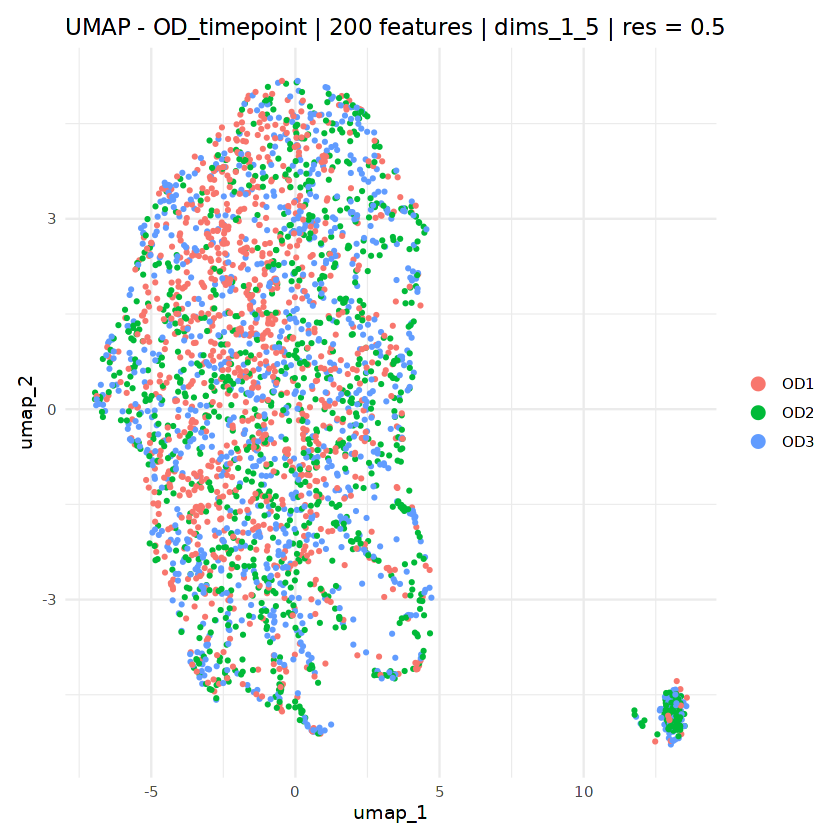

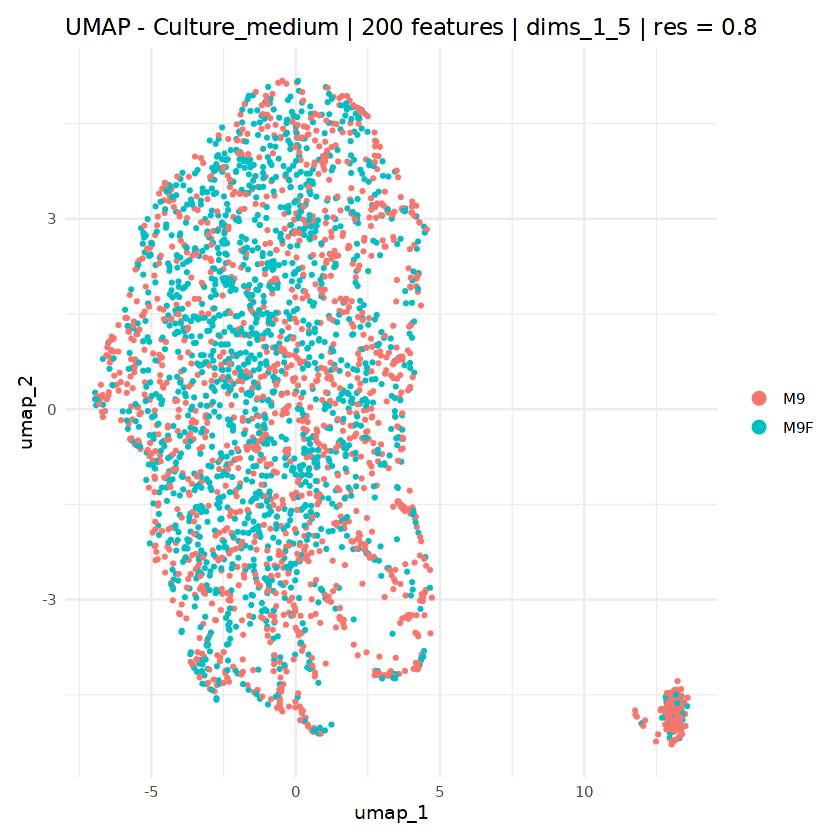

>> nfeatures: 200 | dims: dims_1_5 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 94508

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6000
Number of communities: 10
Elapsed time: 0 seconds


14:55:32 UMAP embedding parameters a = 0.9922 b = 1.112

14:55:32 Read 2934 rows and found 5 numeric columns

14:55:32 Using Annoy for neighbor search, n_neighbors = 30

14:55:32 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:55:33 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020758b68af

14:55:33 Searching Annoy index using 1 thread, search_k = 3000

14:55:34 Annoy recall = 95.23%

14:55:34 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:55:35 173 smooth knn distance failures

14:55:35 Initializing from normalized Laplacian + noise (using RSpectra)

14:55:36 Commencing optimization for 500 epochs, with 101596 positive edges

14:55:36 Using rng type: pcg

14:55:39 Optimization finished



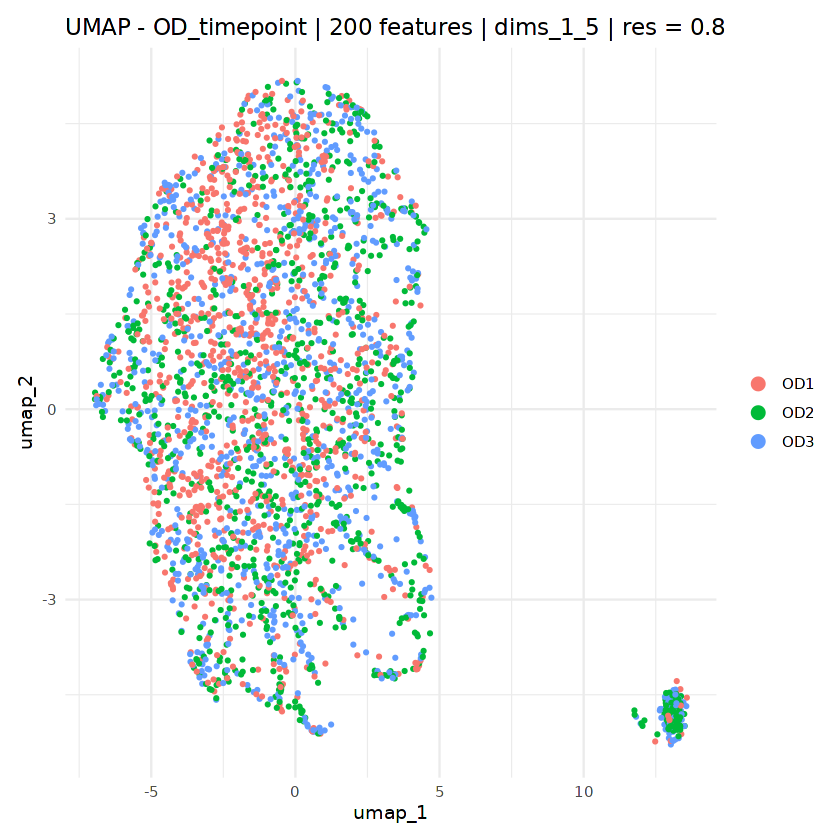

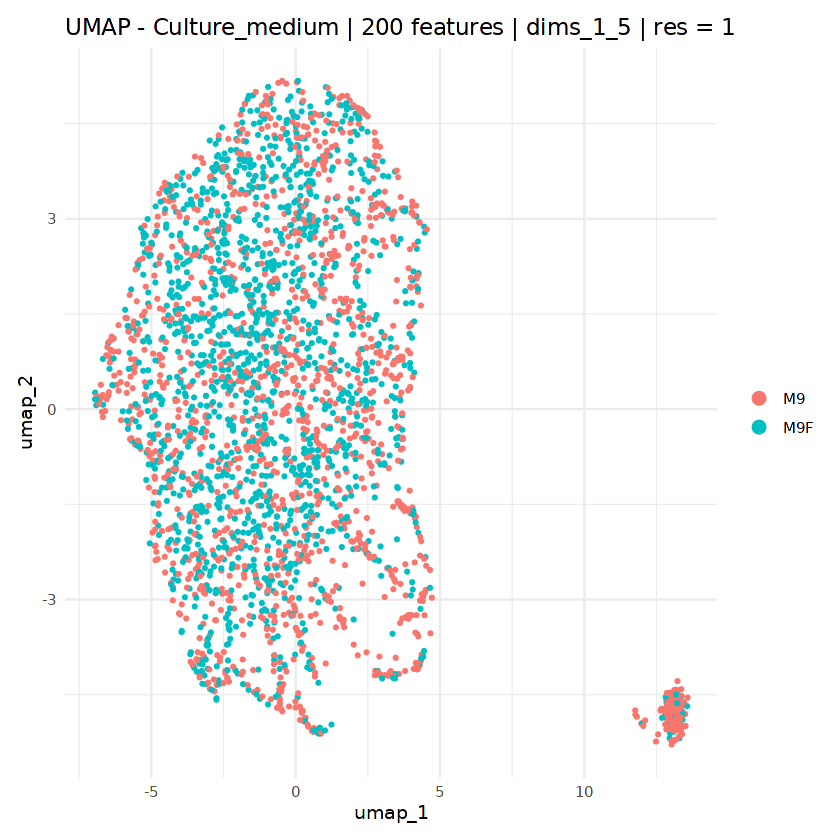

>> nfeatures: 200 | dims: dims_1_10 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 97384

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8454
Number of communities: 4
Elapsed time: 0 seconds


14:55:41 UMAP embedding parameters a = 0.9922 b = 1.112

14:55:41 Read 2934 rows and found 10 numeric columns

14:55:41 Using Annoy for neighbor search, n_neighbors = 30

14:55:41 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:55:42 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002074d9433d

14:55:42 Searching Annoy index using 1 thread, search_k = 3000

14:55:43 Annoy recall = 95.23%

14:55:44 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:55:44 175 smooth knn distance failures

14:55:45 Initializing from normalized Laplacian + noise (using RSpectra)

14:55:45 Commencing optimization for 500 epochs, with 104410 positive edges

14:55:45 Using rng type: pcg

14:55:50 Optimization finished



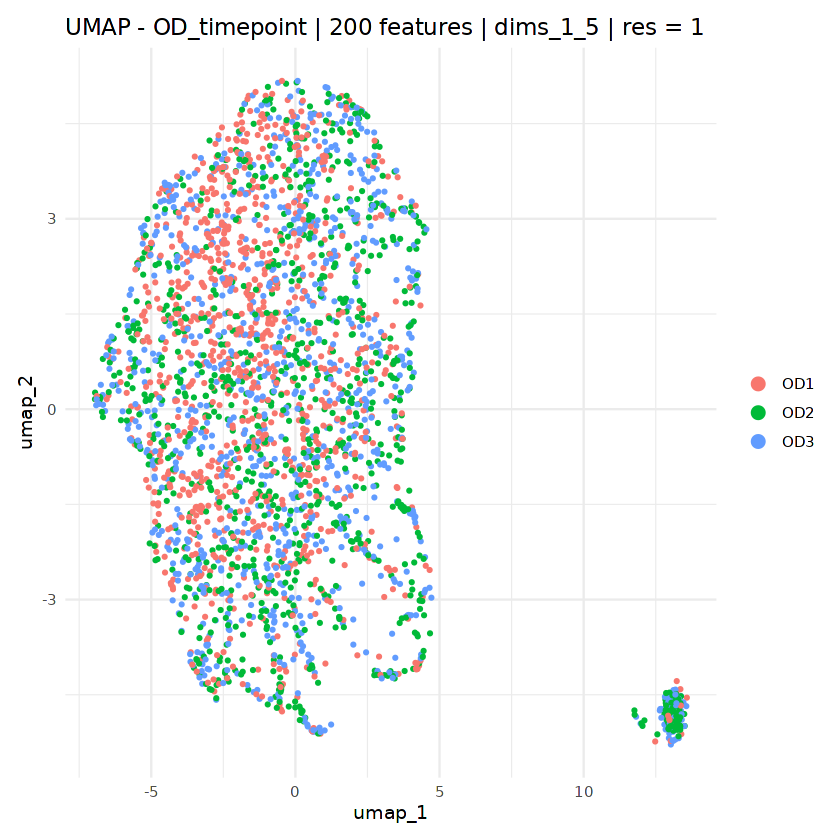

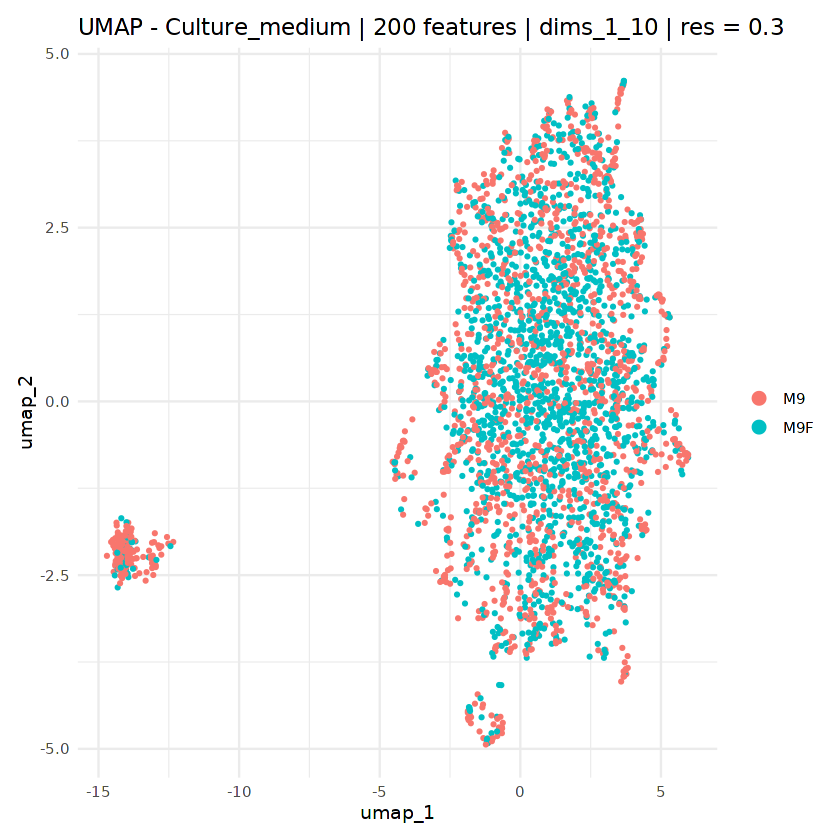

>> nfeatures: 200 | dims: dims_1_10 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 97384

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7499
Number of communities: 5
Elapsed time: 0 seconds


14:55:53 UMAP embedding parameters a = 0.9922 b = 1.112

14:55:53 Read 2934 rows and found 10 numeric columns

14:55:53 Using Annoy for neighbor search, n_neighbors = 30

14:55:53 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:55:54 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002030d739fd

14:55:54 Searching Annoy index using 1 thread, search_k = 3000

14:55:55 Annoy recall = 95.23%

14:55:56 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:55:56 175 smooth knn distance failures

14:55:57 Initializing from normalized Laplacian + noise (using RSpectra)

14:55:57 Commencing optimization for 500 epochs, with 104410 positive edges

14:55:57 Using rng type: pcg

14:56:01 Optimization finished



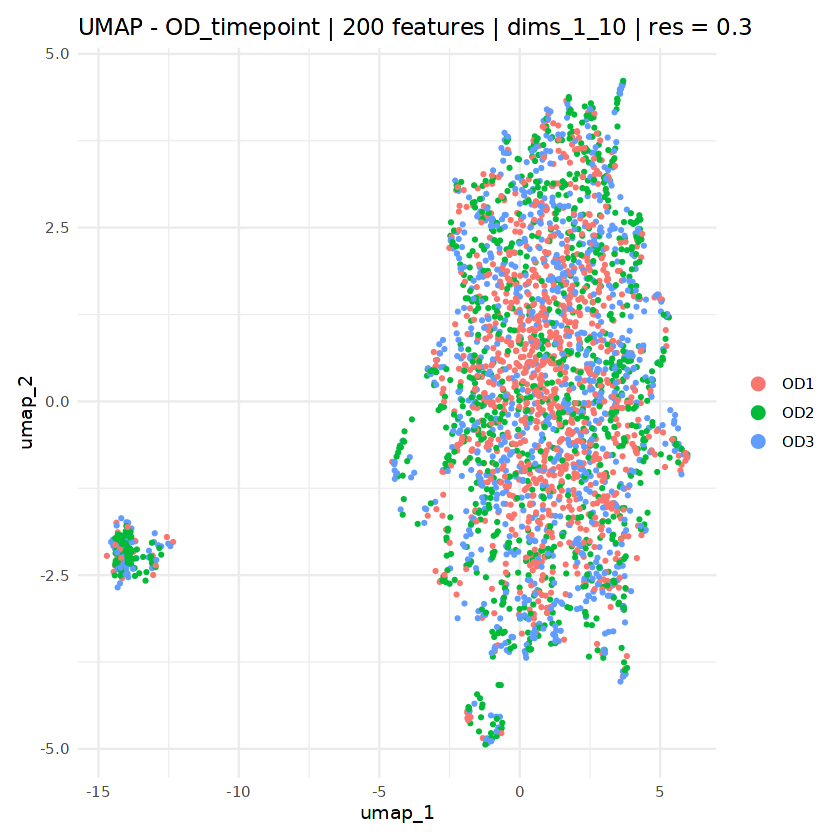

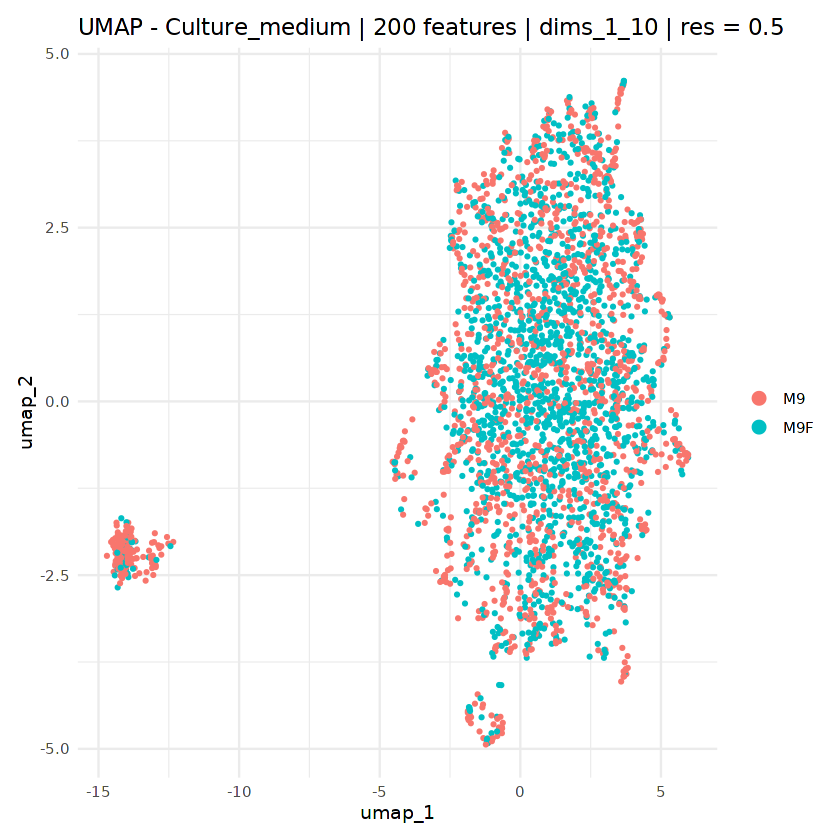

>> nfeatures: 200 | dims: dims_1_10 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 97384

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6201
Number of communities: 8
Elapsed time: 0 seconds


14:56:04 UMAP embedding parameters a = 0.9922 b = 1.112

14:56:04 Read 2934 rows and found 10 numeric columns

14:56:04 Using Annoy for neighbor search, n_neighbors = 30

14:56:04 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:56:04 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100202a919dbf

14:56:04 Searching Annoy index using 1 thread, search_k = 3000

14:56:05 Annoy recall = 95.23%

14:56:06 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:56:06 175 smooth knn distance failures

14:56:08 Initializing from normalized Laplacian + noise (using RSpectra)

14:56:08 Commencing optimization for 500 epochs, with 104410 positive edges

14:56:08 Using rng type: pcg

14:56:12 Optimization finished



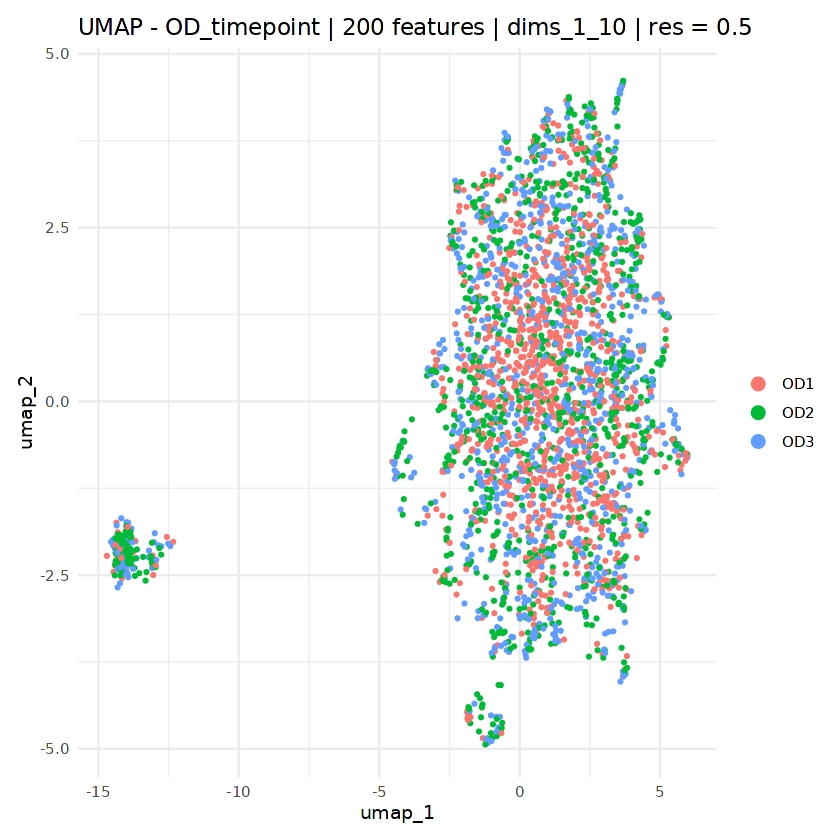

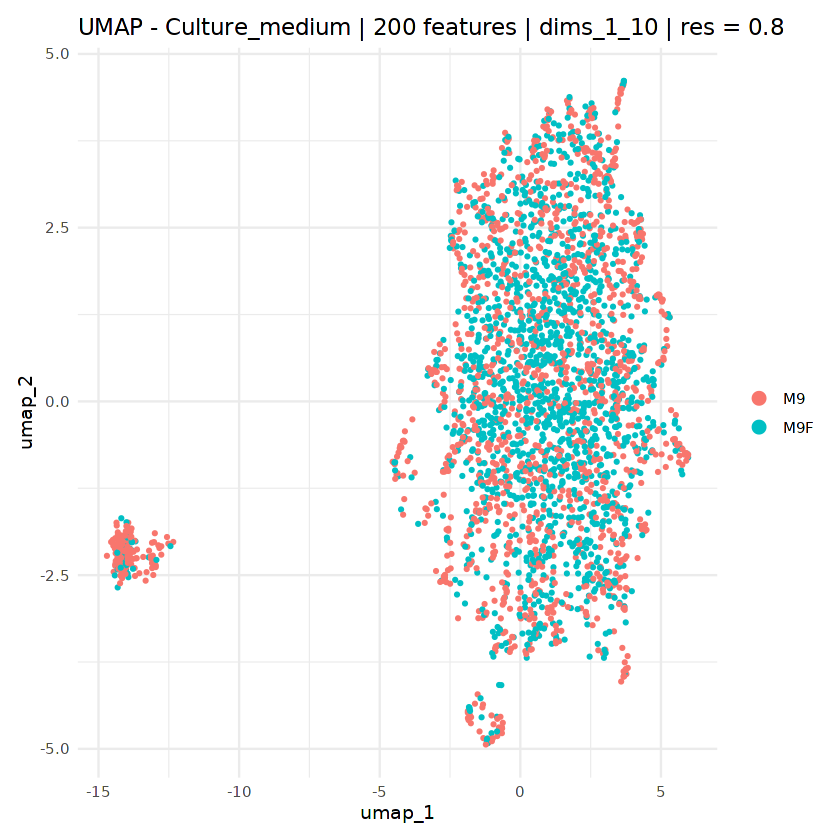

>> nfeatures: 200 | dims: dims_1_10 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 97384

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5414
Number of communities: 9
Elapsed time: 0 seconds


14:56:14 UMAP embedding parameters a = 0.9922 b = 1.112

14:56:14 Read 2934 rows and found 10 numeric columns

14:56:14 Using Annoy for neighbor search, n_neighbors = 30

14:56:14 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:56:15 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020665e5aed

14:56:15 Searching Annoy index using 1 thread, search_k = 3000

14:56:16 Annoy recall = 95.23%

14:56:17 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:56:17 175 smooth knn distance failures

14:56:18 Initializing from normalized Laplacian + noise (using RSpectra)

14:56:18 Commencing optimization for 500 epochs, with 104410 positive edges

14:56:18 Using rng type: pcg

14:56:22 Optimization finished



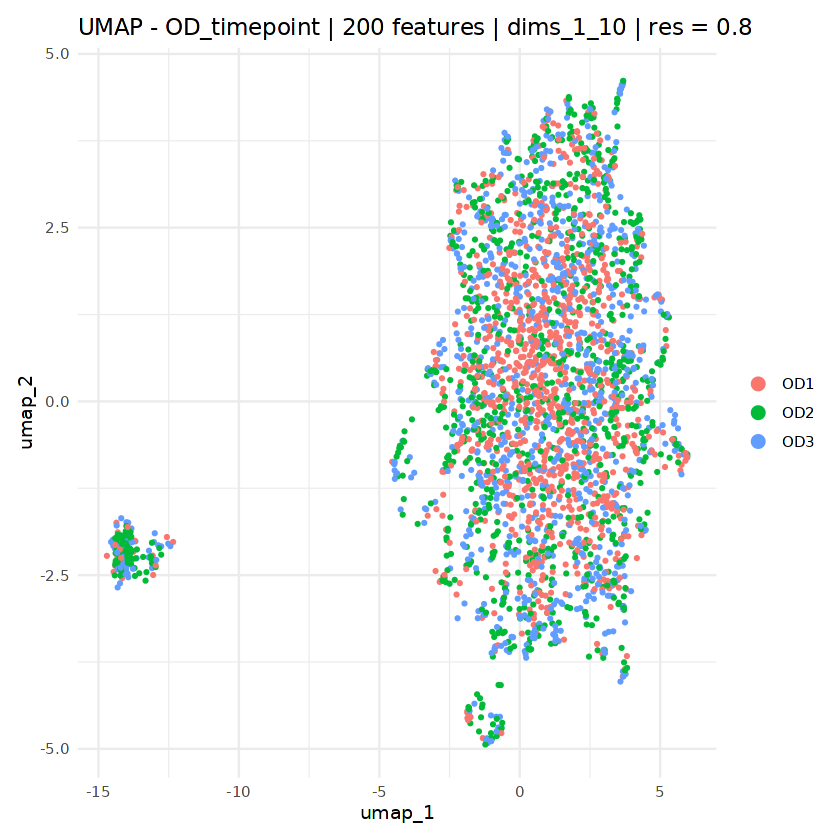

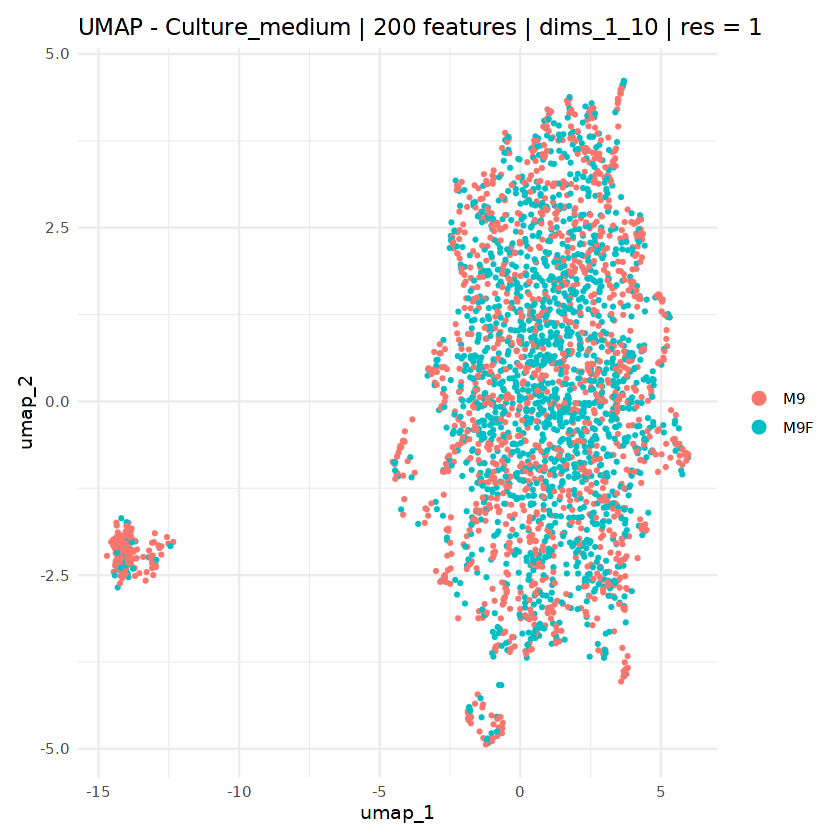

>> nfeatures: 200 | dims: dims_1_15 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 102419

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8440
Number of communities: 3
Elapsed time: 0 seconds


14:56:25 UMAP embedding parameters a = 0.9922 b = 1.112

14:56:25 Read 2934 rows and found 15 numeric columns

14:56:25 Using Annoy for neighbor search, n_neighbors = 30

14:56:25 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:56:26 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100205a15459b

14:56:26 Searching Annoy index using 1 thread, search_k = 3000

14:56:26 Annoy recall = 95.23%

14:56:28 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:56:28 178 smooth knn distance failures

14:56:29 Initializing from normalized Laplacian + noise (using RSpectra)

14:56:29 Commencing optimization for 500 epochs, with 106884 positive edges

14:56:29 Using rng type: pcg

14:56:33 Optimization finished



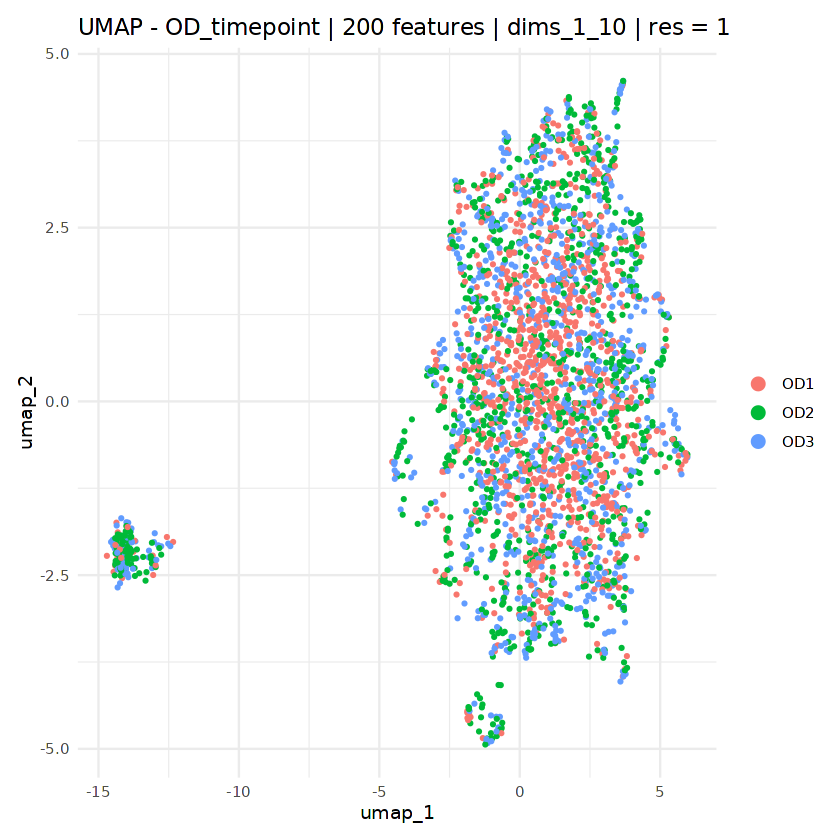

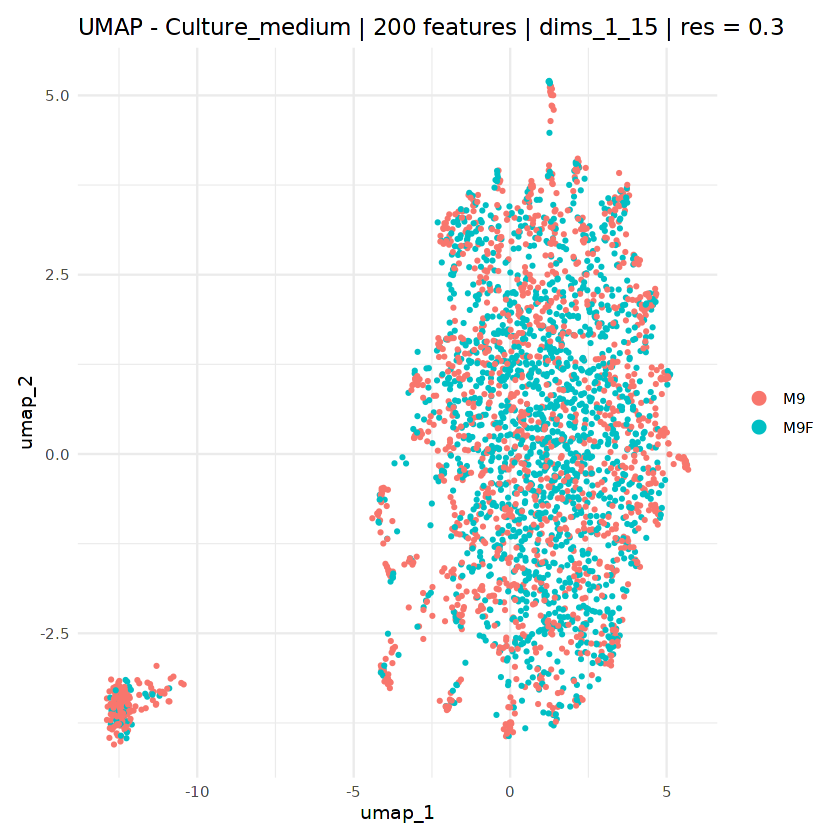

>> nfeatures: 200 | dims: dims_1_15 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 102419

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7498
Number of communities: 5
Elapsed time: 0 seconds


14:56:36 UMAP embedding parameters a = 0.9922 b = 1.112

14:56:36 Read 2934 rows and found 15 numeric columns

14:56:36 Using Annoy for neighbor search, n_neighbors = 30

14:56:36 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:56:36 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100202b9b1380

14:56:36 Searching Annoy index using 1 thread, search_k = 3000

14:56:37 Annoy recall = 95.23%

14:56:38 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:56:38 178 smooth knn distance failures

14:56:39 Initializing from normalized Laplacian + noise (using RSpectra)

14:56:39 Commencing optimization for 500 epochs, with 106884 positive edges

14:56:39 Using rng type: pcg

14:56:43 Optimization finished



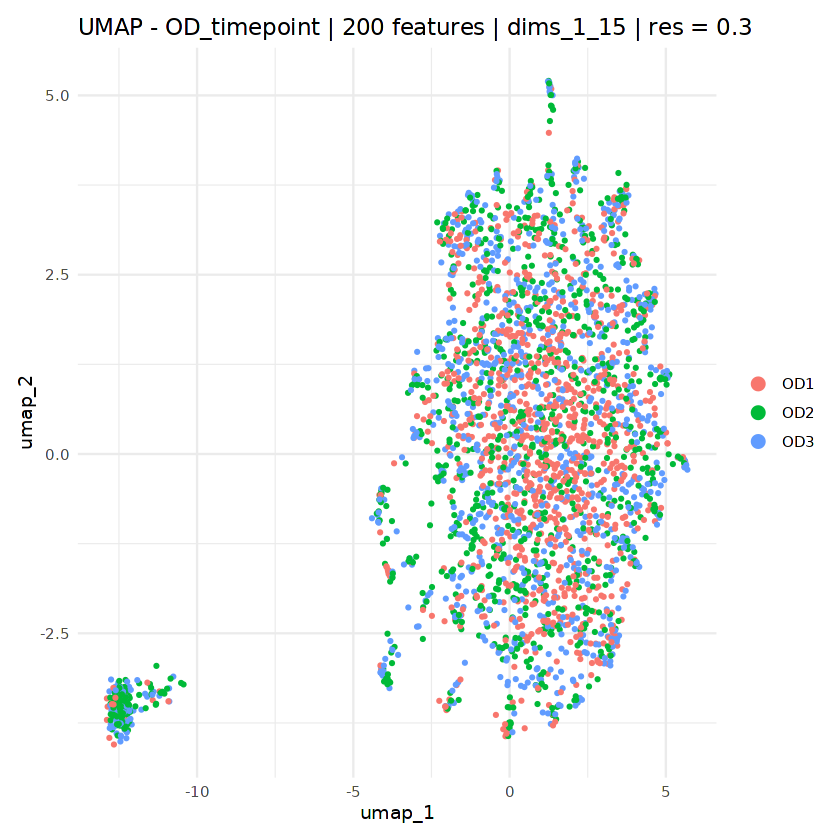

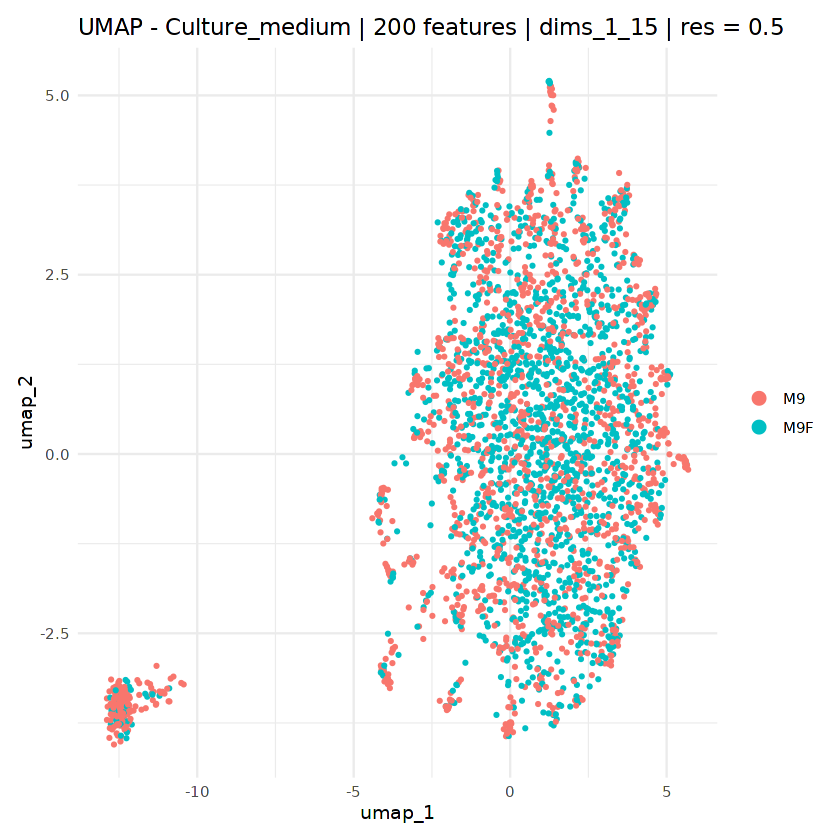

>> nfeatures: 200 | dims: dims_1_15 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 102419

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6259
Number of communities: 9
Elapsed time: 0 seconds


14:56:45 UMAP embedding parameters a = 0.9922 b = 1.112

14:56:45 Read 2934 rows and found 15 numeric columns

14:56:45 Using Annoy for neighbor search, n_neighbors = 30

14:56:45 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:56:46 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020bae1af2

14:56:46 Searching Annoy index using 1 thread, search_k = 3000

14:56:47 Annoy recall = 95.23%

14:56:48 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:56:48 178 smooth knn distance failures

14:56:49 Initializing from normalized Laplacian + noise (using RSpectra)

14:56:49 Commencing optimization for 500 epochs, with 106884 positive edges

14:56:49 Using rng type: pcg

14:56:53 Optimization finished



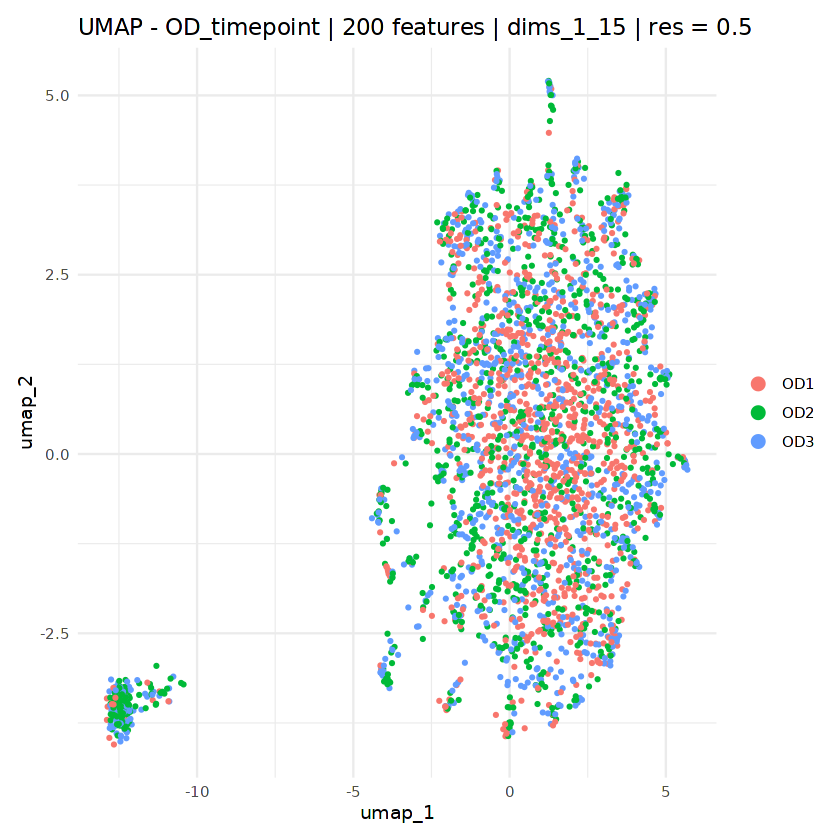

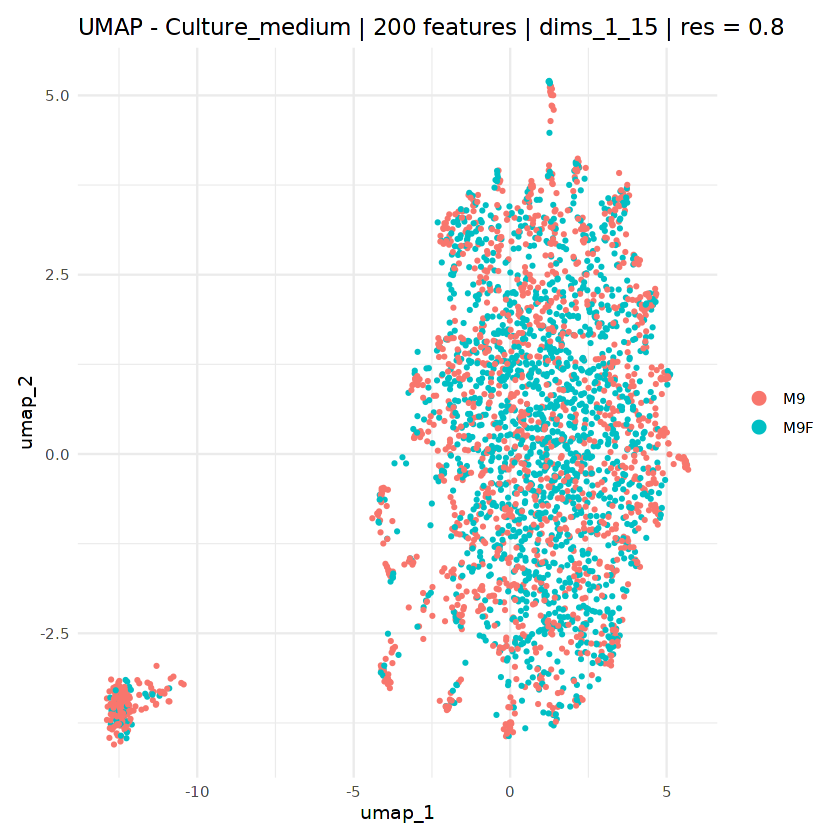

>> nfeatures: 200 | dims: dims_1_15 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 102419

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5502
Number of communities: 11
Elapsed time: 0 seconds


14:56:55 UMAP embedding parameters a = 0.9922 b = 1.112

14:56:55 Read 2934 rows and found 15 numeric columns

14:56:55 Using Annoy for neighbor search, n_neighbors = 30

14:56:55 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:56:56 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002031b2bcc3

14:56:56 Searching Annoy index using 1 thread, search_k = 3000

14:56:57 Annoy recall = 95.23%

14:56:58 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:56:58 178 smooth knn distance failures

14:56:59 Initializing from normalized Laplacian + noise (using RSpectra)

14:56:59 Commencing optimization for 500 epochs, with 106884 positive edges

14:56:59 Using rng type: pcg

14:57:02 Optimization finished



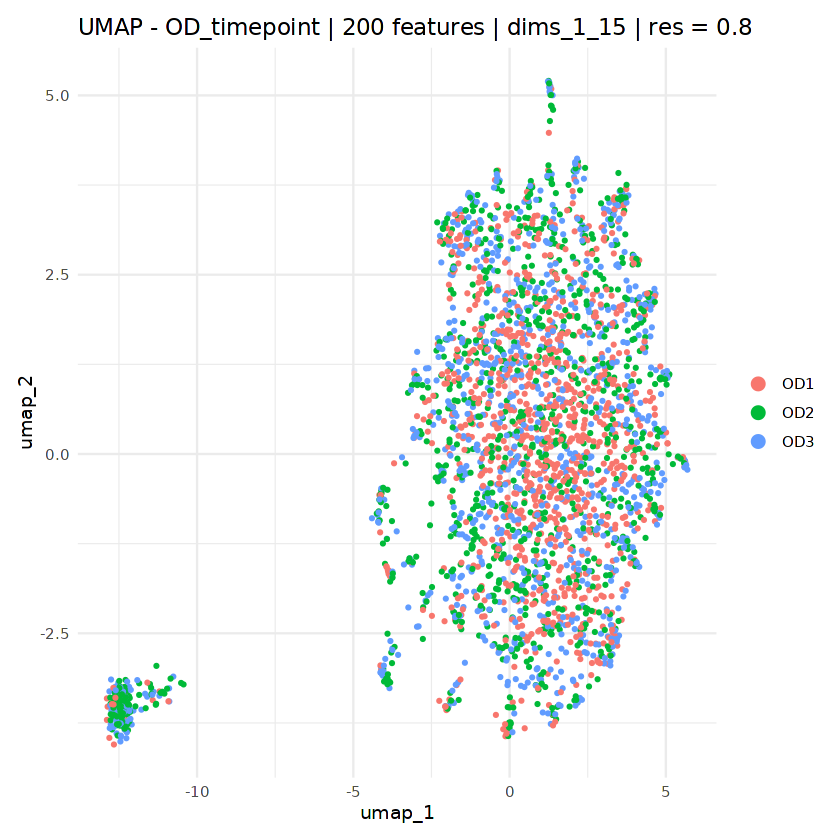

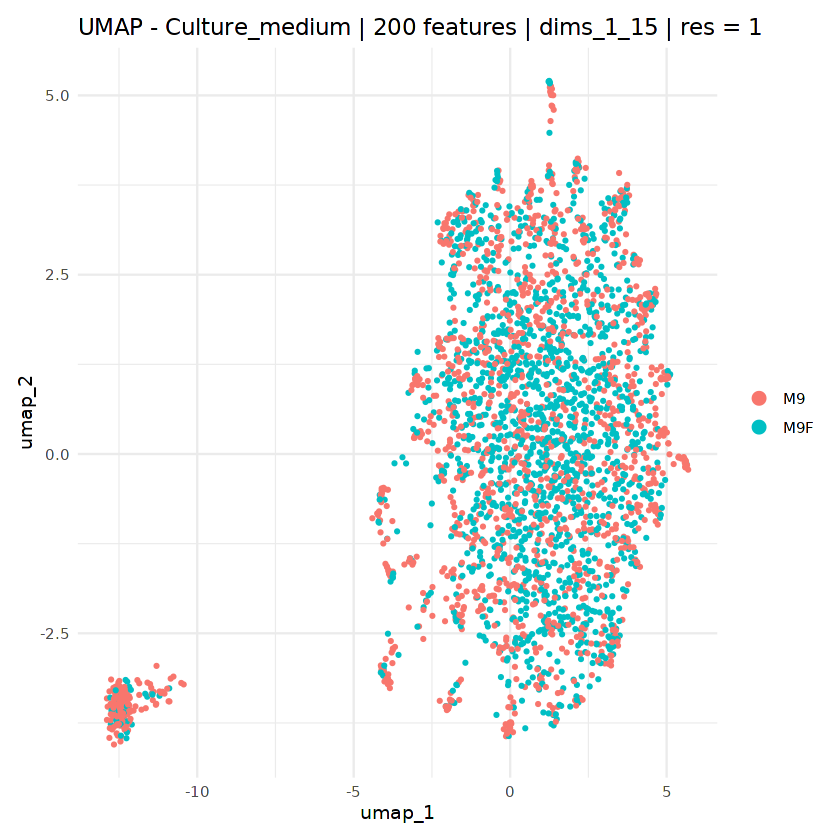

==== nfeatures = 500 ====

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  QLH64-19225, fusA, QLH64-02935, rpoC, QLH64-13720, QLH64-05400, QLH64-07480, QLH64-24685, secA, QLH64-12130 
	   QLH64-04320, QLH64-18250, galU, QLH64-12160, QLH64-27520, ppa, serA, QLH64-04480, QLH64-23145, folE2 
	   QLH64-00395, fabB, QLH64-29815, rplI, pgi, QLH64-13350, ndk, QLH64-11810, QLH64-13325, QLH64-05080 
Negative:  QLH64-02630, choX_1, QLH64-12580, QLH64-12900, cobA_1, QLH64-24590, QLH64-30870, QLH64-03825, QLH64-09870, chrA 
	   QLH64-02635, QLH64-22455, QLH64-08635, QLH64-17820, QLH64-13385, QLH64-20890, QLH64-23730, QLH64-14525, QLH64-08330, QLH64-07745 
	   QLH64-18655, QLH64-29715, QLH64-00325, QLH64-15415, QLH64-28035, QLH64-04585, QLH64-07545, QLH64-26175, QLH64-03320, pgeF 
PC_ 2 
Positive:  hemE, QLH64-13945, QLH64-00515, QLH64-03130, QLH64-02360, cysB, QLH64-06375, pilB, QLH64-17100, pyrC 
	   QLH64-23690, QLH64-10590, uvrD, QLH64-23695, QLH

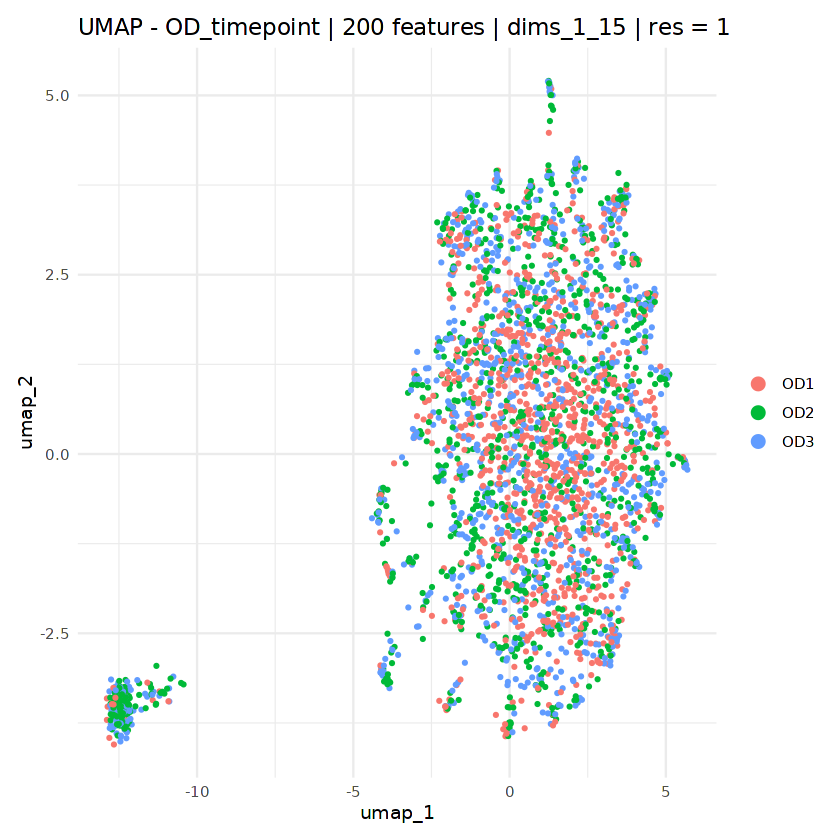

Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


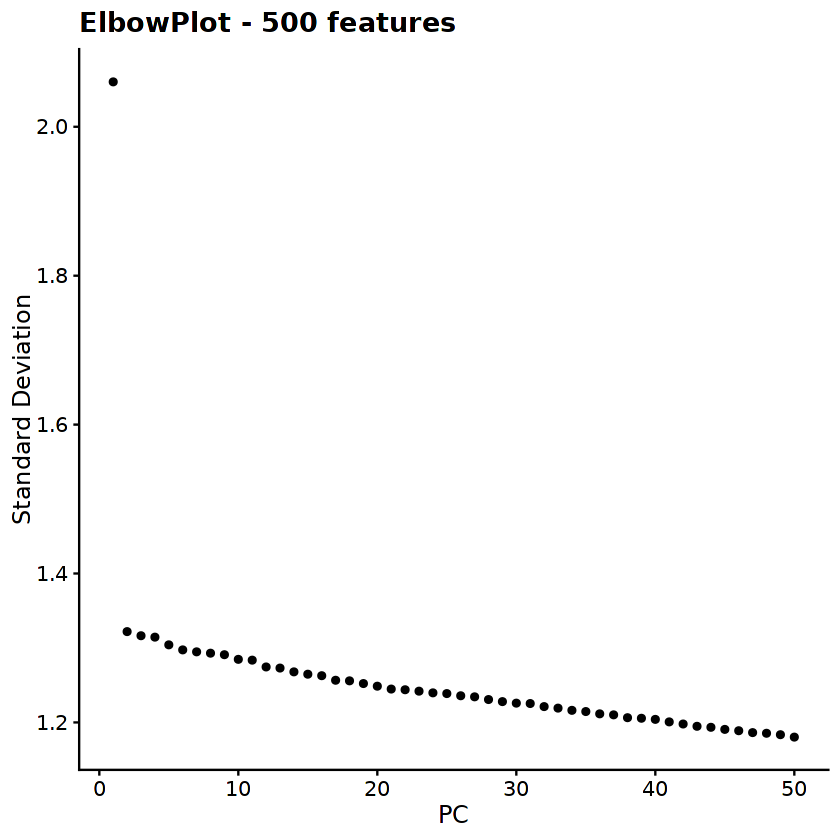

NULL


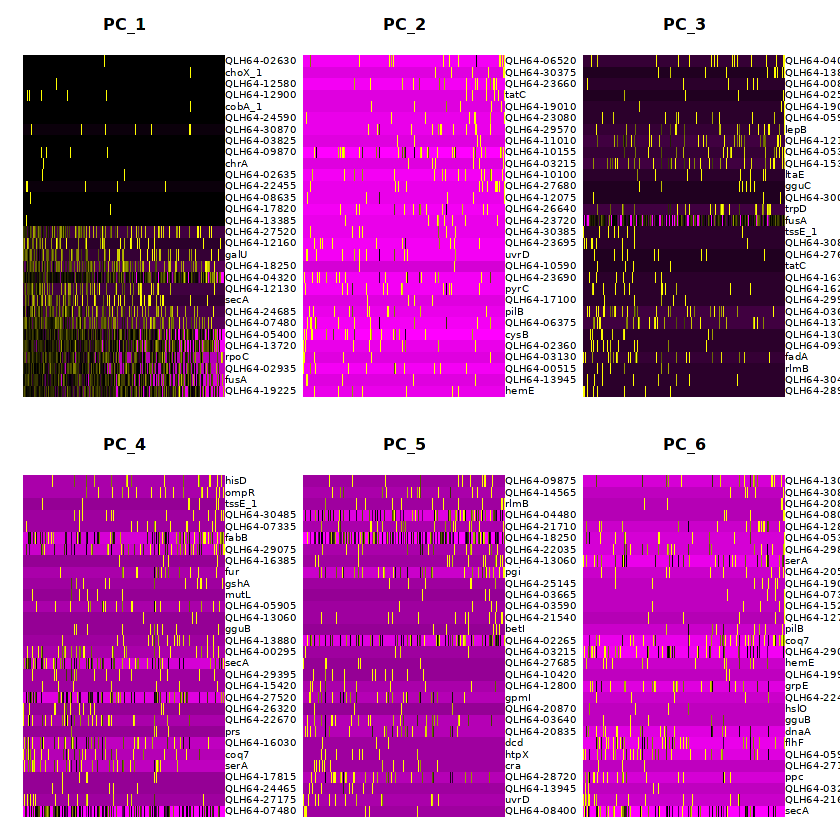

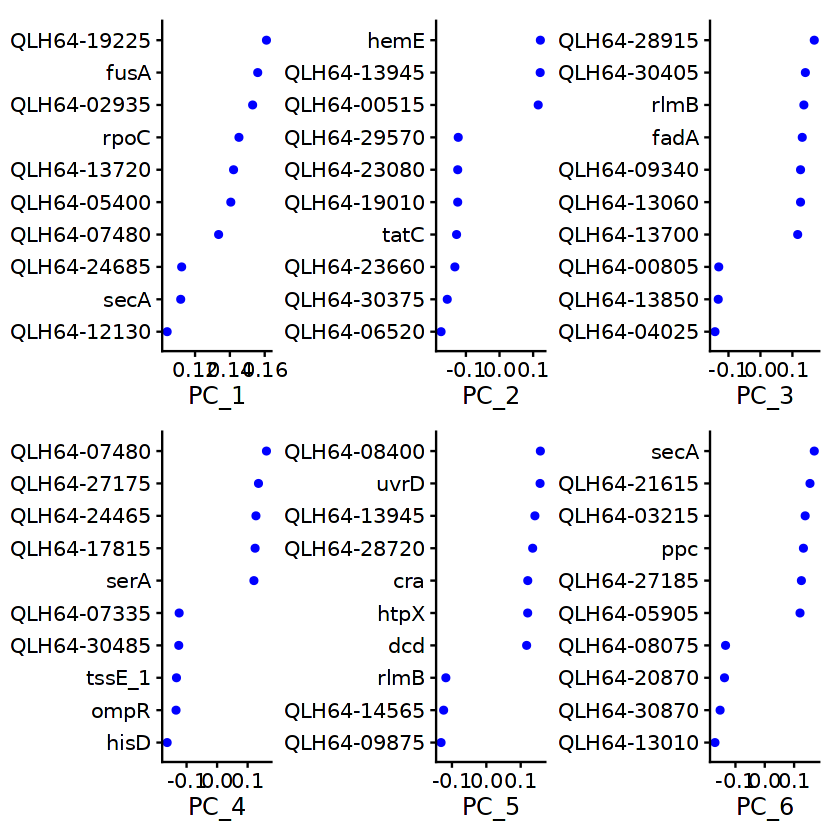

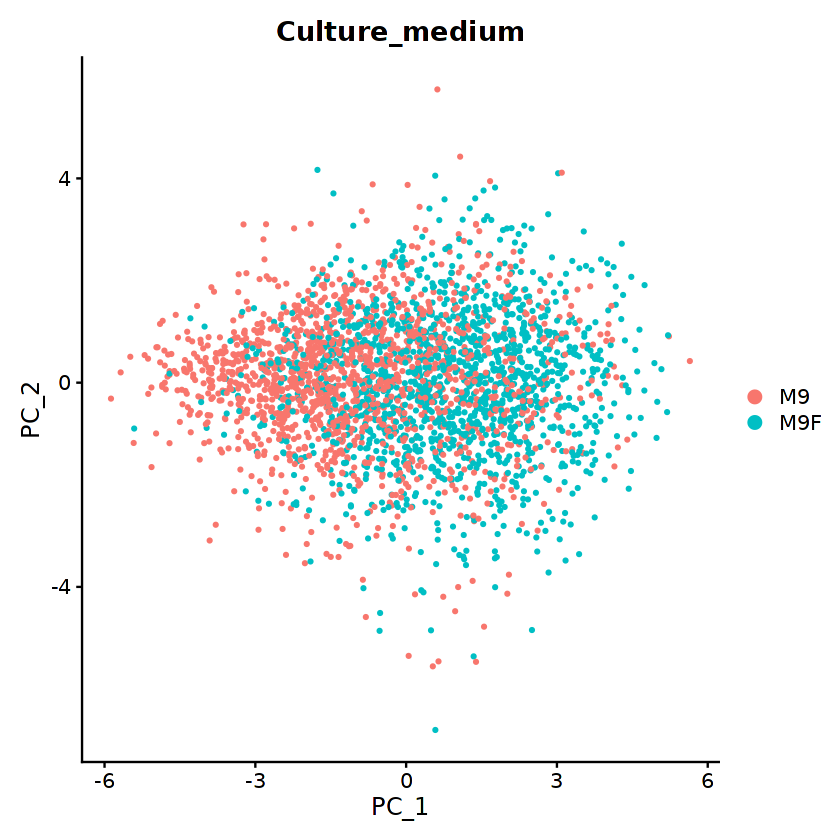

>> nfeatures: 500 | dims: dims_1_5 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 85273

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7843
Number of communities: 2
Elapsed time: 0 seconds


14:57:11 UMAP embedding parameters a = 0.9922 b = 1.112

14:57:11 Read 2934 rows and found 5 numeric columns

14:57:11 Using Annoy for neighbor search, n_neighbors = 30

14:57:11 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:57:12 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020463257ad

14:57:12 Searching Annoy index using 1 thread, search_k = 3000

14:57:13 Annoy recall = 100%

14:57:14 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:57:15 Initializing from normalized Laplacian + noise (using RSpectra)

14:57:15 Commencing optimization for 500 epochs, with 101064 positive edges

14:57:15 Using rng type: pcg

14:57:18 Optimization finished



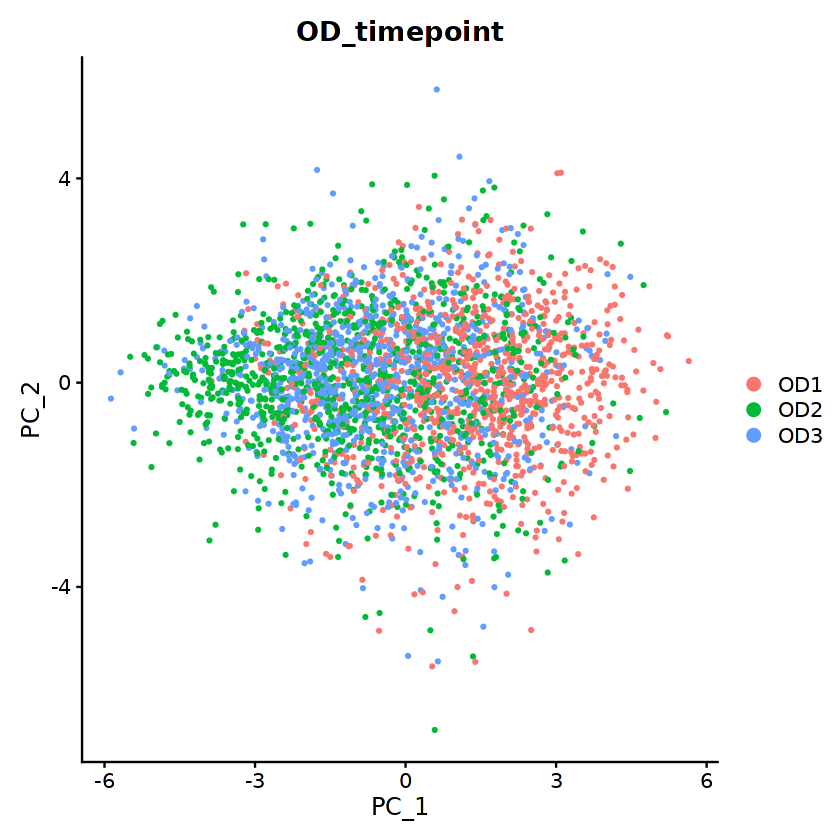

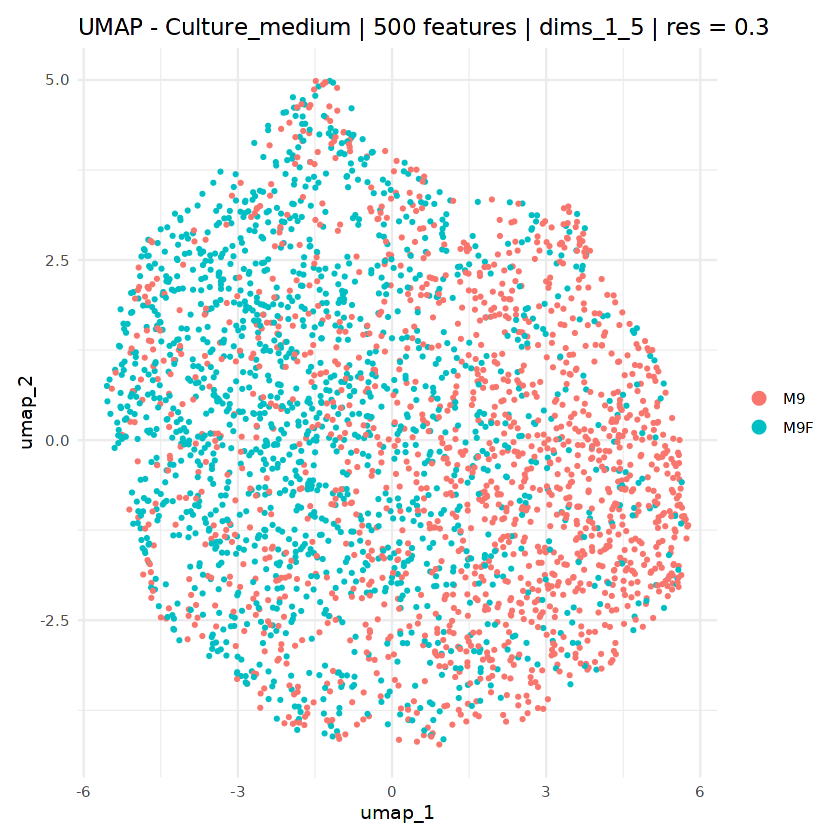

>> nfeatures: 500 | dims: dims_1_5 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 85273

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7245
Number of communities: 6
Elapsed time: 0 seconds


14:57:21 UMAP embedding parameters a = 0.9922 b = 1.112

14:57:21 Read 2934 rows and found 5 numeric columns

14:57:21 Using Annoy for neighbor search, n_neighbors = 30

14:57:21 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:57:22 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002077a4ebc

14:57:22 Searching Annoy index using 1 thread, search_k = 3000

14:57:23 Annoy recall = 100%

14:57:24 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:57:25 Initializing from normalized Laplacian + noise (using RSpectra)

14:57:25 Commencing optimization for 500 epochs, with 101064 positive edges

14:57:25 Using rng type: pcg

14:57:28 Optimization finished



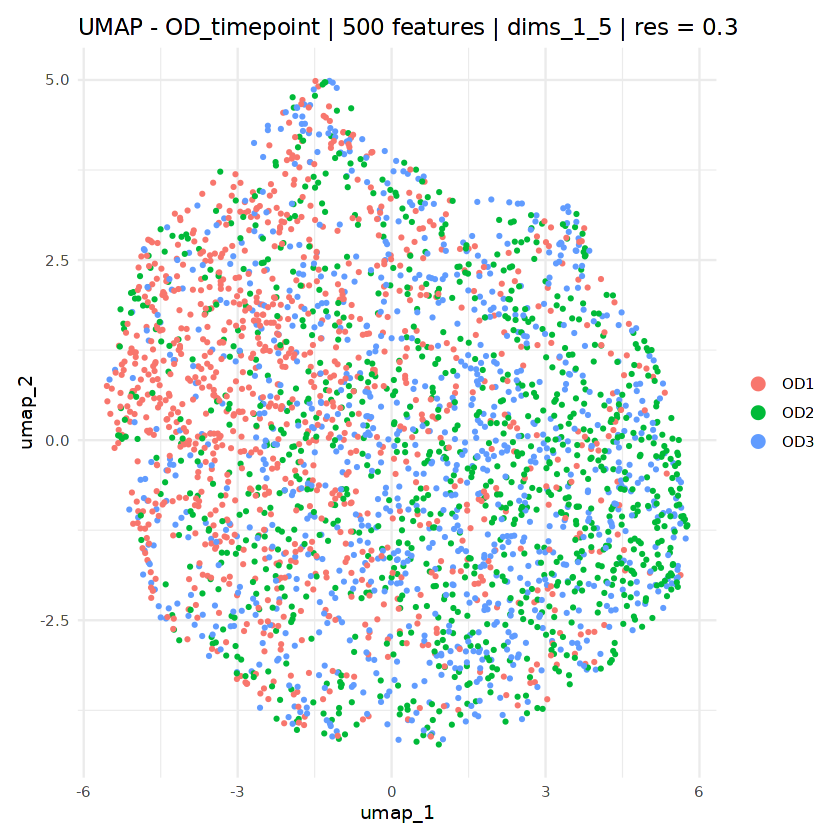

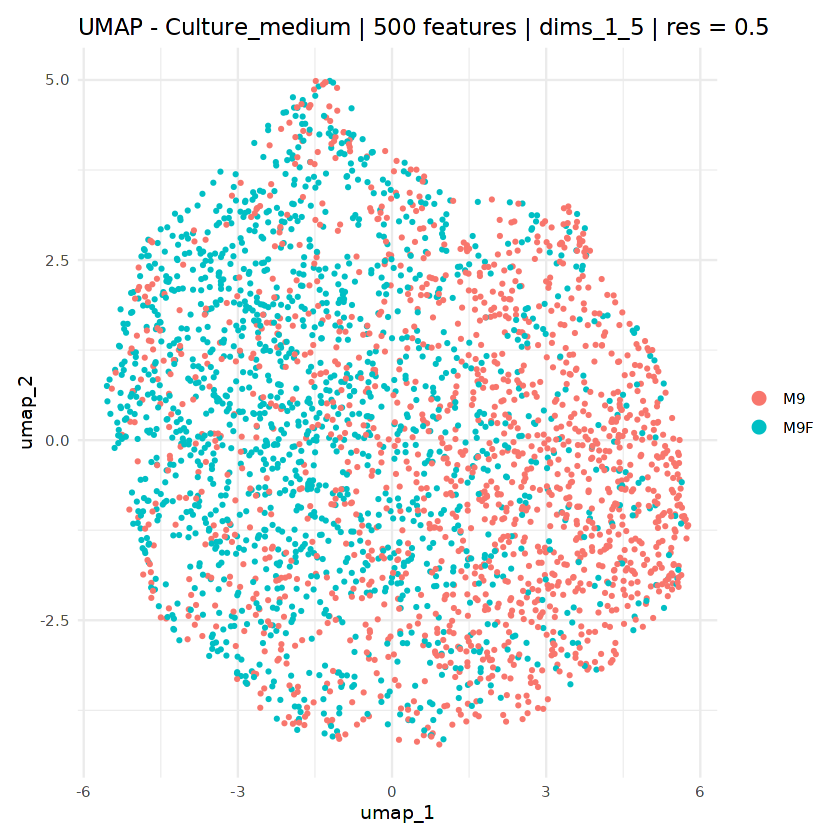

>> nfeatures: 500 | dims: dims_1_5 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 85273

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6784
Number of communities: 9
Elapsed time: 0 seconds


14:57:30 UMAP embedding parameters a = 0.9922 b = 1.112

14:57:30 Read 2934 rows and found 5 numeric columns

14:57:30 Using Annoy for neighbor search, n_neighbors = 30

14:57:30 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:57:31 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100202c461082

14:57:31 Searching Annoy index using 1 thread, search_k = 3000

14:57:32 Annoy recall = 100%

14:57:33 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:57:34 Initializing from normalized Laplacian + noise (using RSpectra)

14:57:35 Commencing optimization for 500 epochs, with 101064 positive edges

14:57:35 Using rng type: pcg

14:57:38 Optimization finished



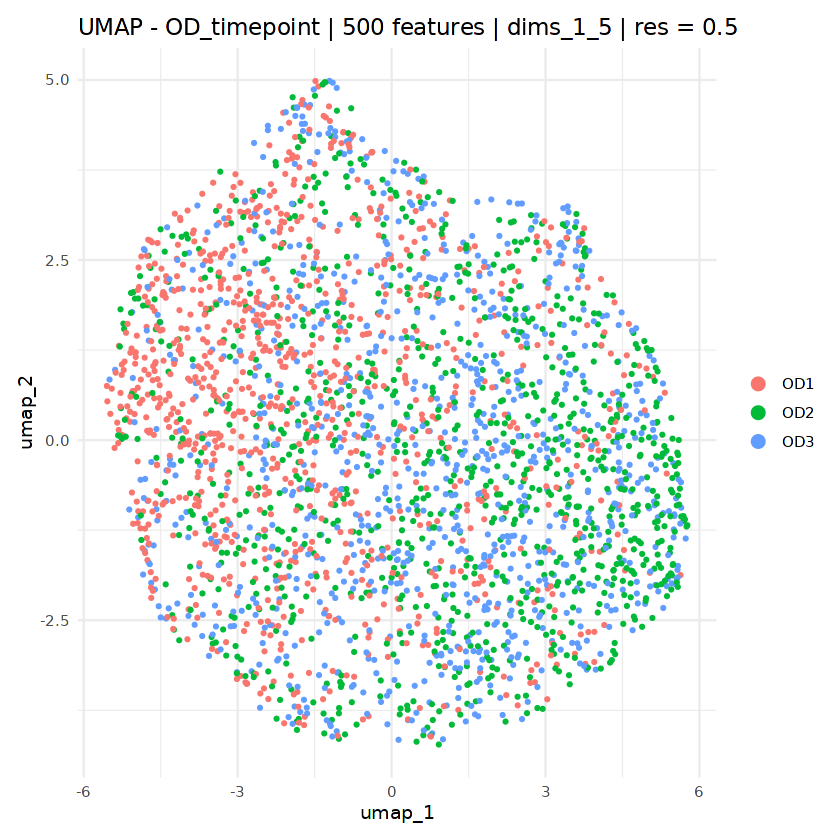

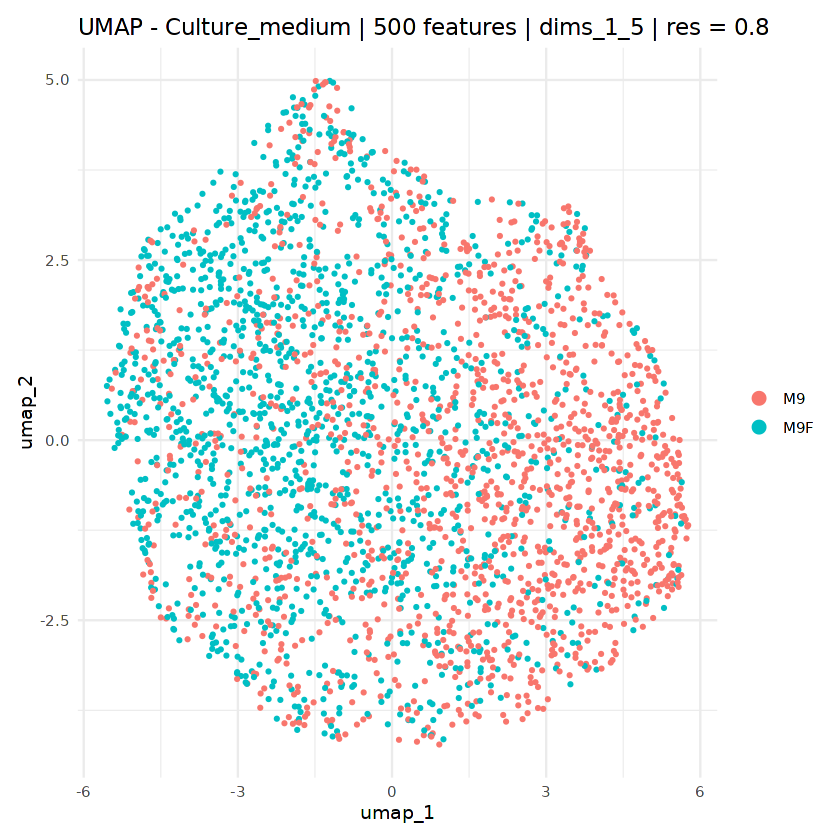

>> nfeatures: 500 | dims: dims_1_5 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 85273

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6552
Number of communities: 11
Elapsed time: 0 seconds


14:57:40 UMAP embedding parameters a = 0.9922 b = 1.112

14:57:40 Read 2934 rows and found 5 numeric columns

14:57:40 Using Annoy for neighbor search, n_neighbors = 30

14:57:40 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:57:41 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100204bc463be

14:57:41 Searching Annoy index using 1 thread, search_k = 3000

14:57:42 Annoy recall = 100%

14:57:43 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:57:44 Initializing from normalized Laplacian + noise (using RSpectra)

14:57:44 Commencing optimization for 500 epochs, with 101064 positive edges

14:57:44 Using rng type: pcg

14:57:47 Optimization finished



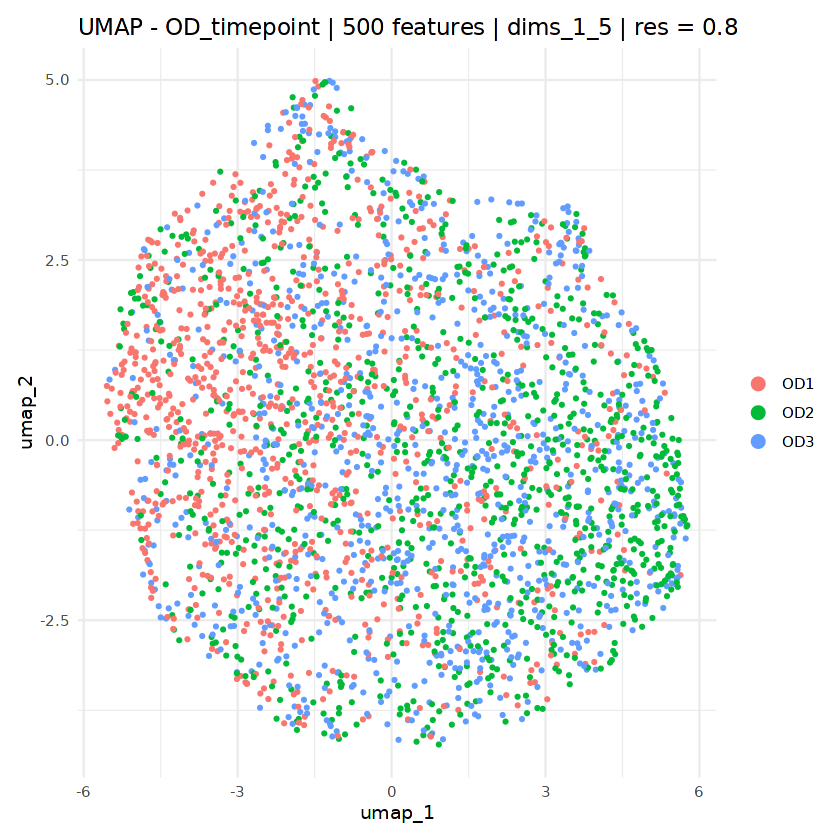

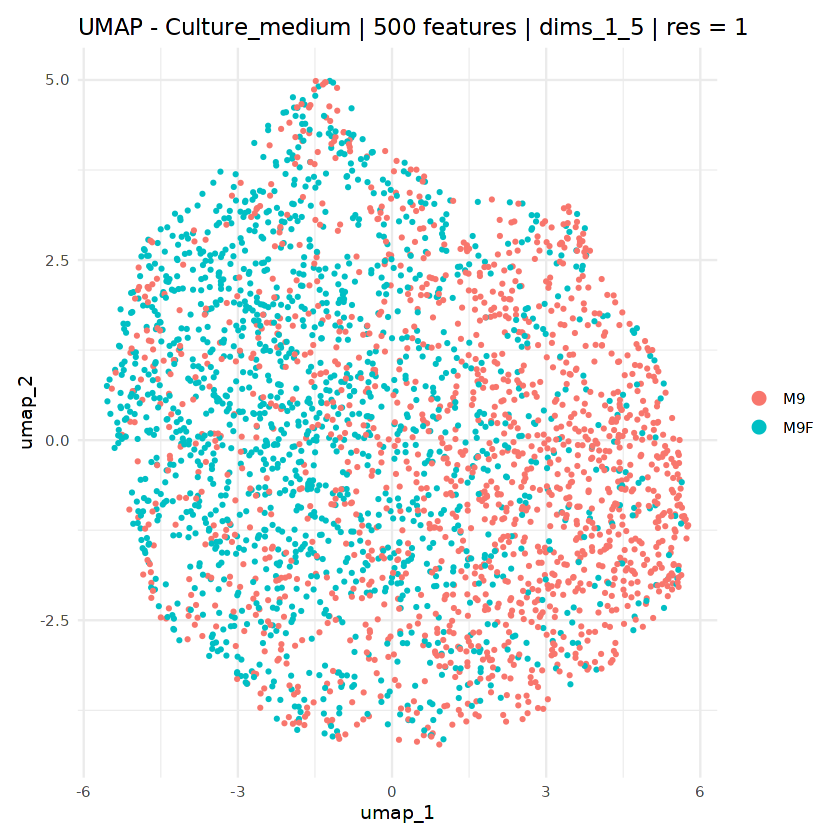

>> nfeatures: 500 | dims: dims_1_10 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 92519

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7666
Number of communities: 2
Elapsed time: 0 seconds


14:57:51 UMAP embedding parameters a = 0.9922 b = 1.112

14:57:51 Read 2934 rows and found 10 numeric columns

14:57:51 Using Annoy for neighbor search, n_neighbors = 30

14:57:51 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:57:52 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100205e9af6e

14:57:52 Searching Annoy index using 1 thread, search_k = 3000

14:57:53 Annoy recall = 100%

14:57:54 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:57:55 Initializing from normalized Laplacian + noise (using RSpectra)

14:57:55 Commencing optimization for 500 epochs, with 108628 positive edges

14:57:55 Using rng type: pcg

14:57:59 Optimization finished



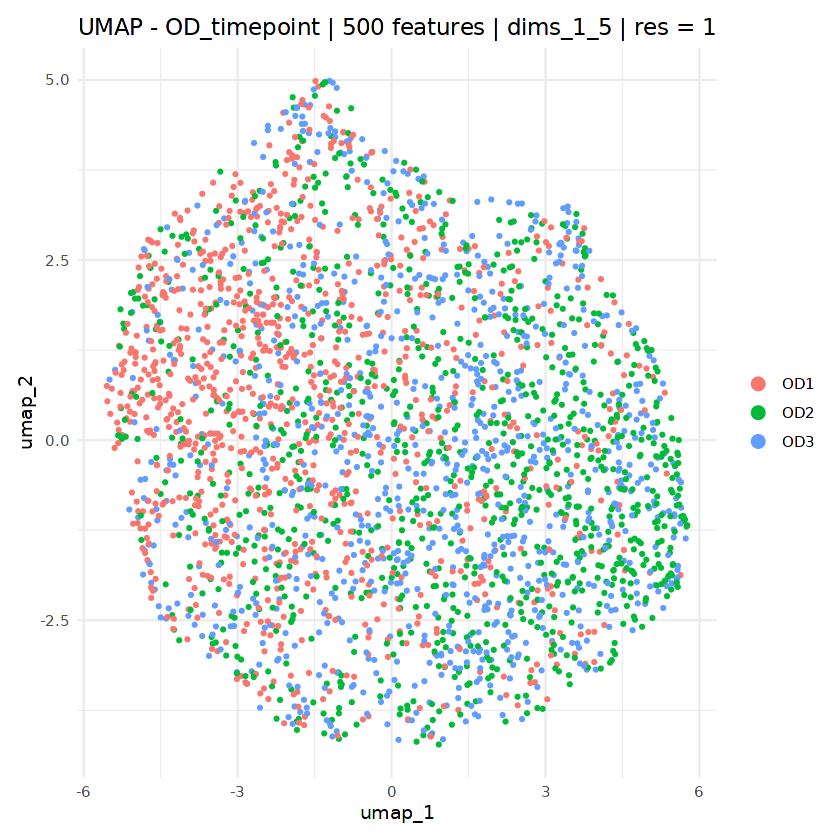

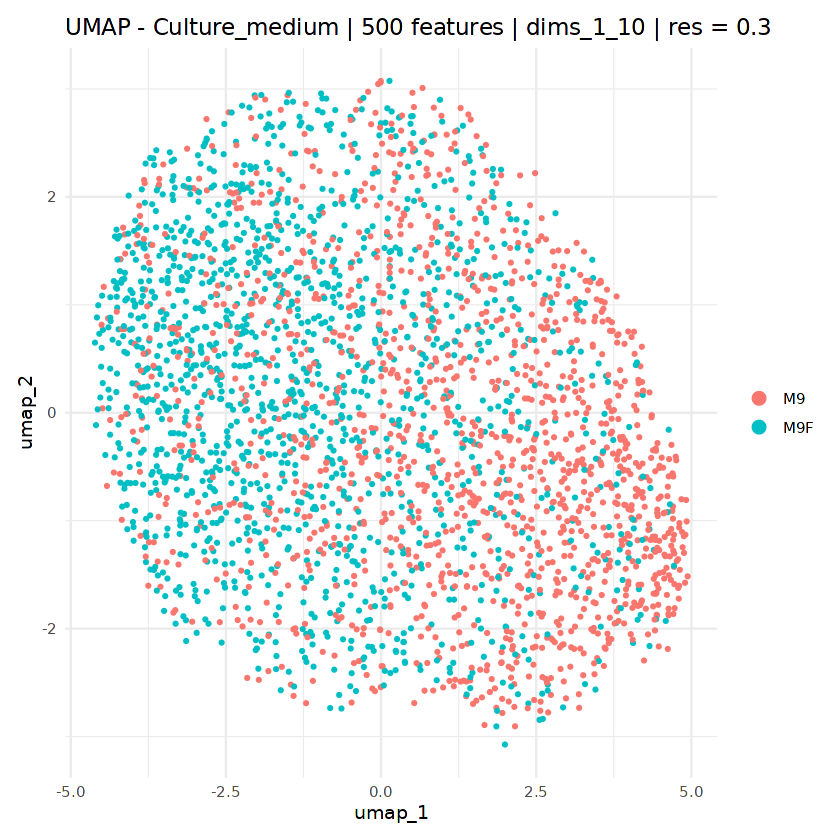

>> nfeatures: 500 | dims: dims_1_10 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 92519

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6766
Number of communities: 3
Elapsed time: 0 seconds


14:58:02 UMAP embedding parameters a = 0.9922 b = 1.112

14:58:02 Read 2934 rows and found 10 numeric columns

14:58:02 Using Annoy for neighbor search, n_neighbors = 30

14:58:02 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:58:02 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100207a817128

14:58:02 Searching Annoy index using 1 thread, search_k = 3000

14:58:03 Annoy recall = 100%

14:58:04 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:58:05 Initializing from normalized Laplacian + noise (using RSpectra)

14:58:05 Commencing optimization for 500 epochs, with 108628 positive edges

14:58:05 Using rng type: pcg

14:58:09 Optimization finished



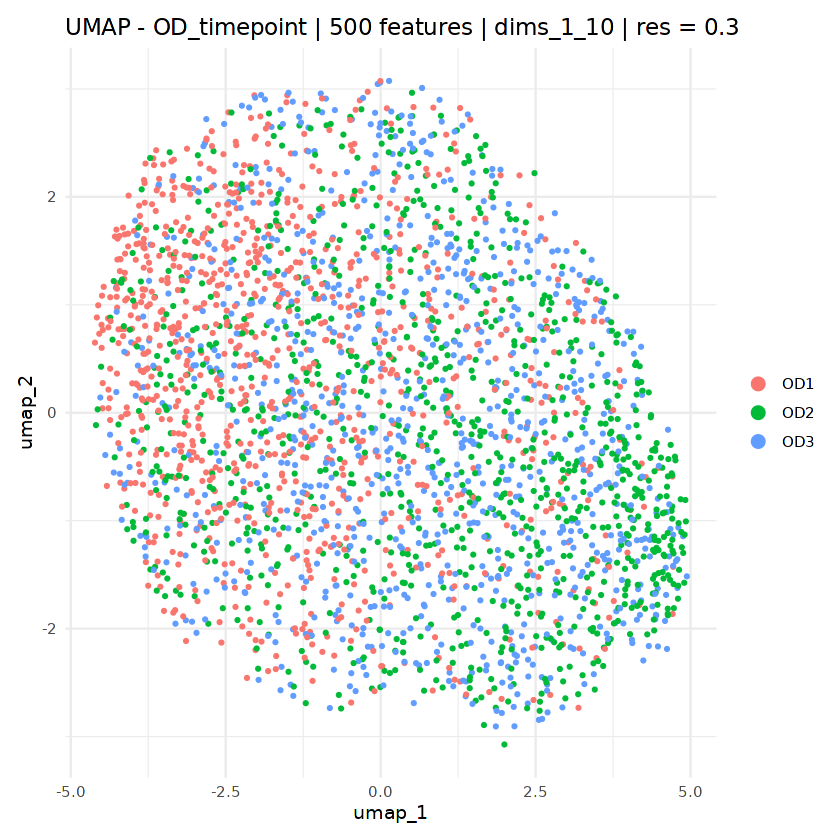

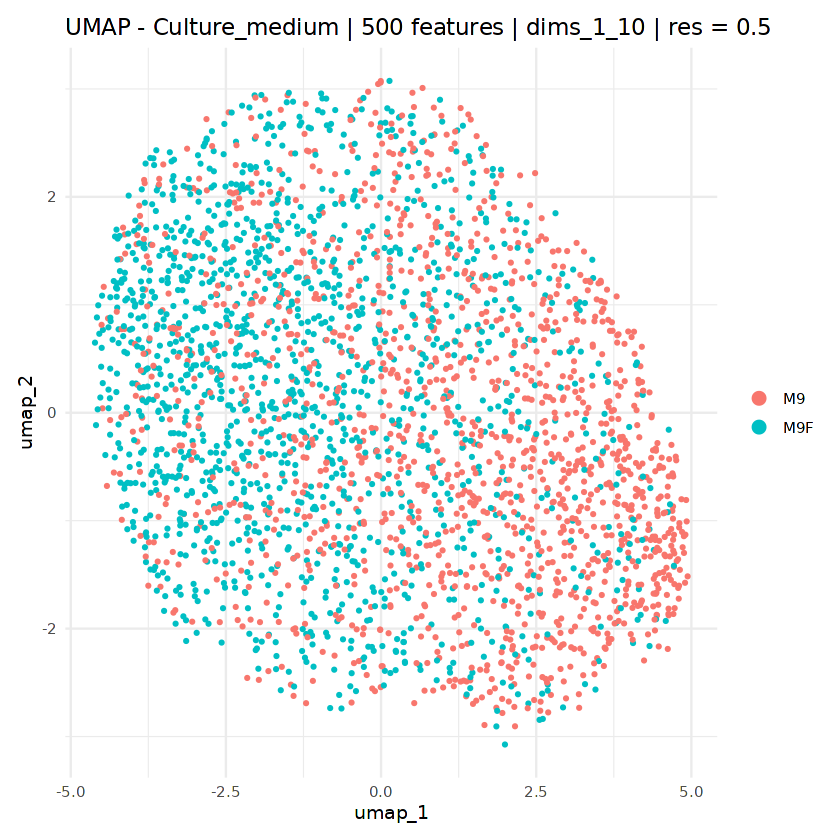

>> nfeatures: 500 | dims: dims_1_10 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 92519

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5823
Number of communities: 5
Elapsed time: 0 seconds


14:58:12 UMAP embedding parameters a = 0.9922 b = 1.112

14:58:12 Read 2934 rows and found 10 numeric columns

14:58:12 Using Annoy for neighbor search, n_neighbors = 30

14:58:12 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:58:13 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002048c2815d

14:58:13 Searching Annoy index using 1 thread, search_k = 3000

14:58:14 Annoy recall = 100%

14:58:15 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:58:17 Initializing from normalized Laplacian + noise (using RSpectra)

14:58:17 Commencing optimization for 500 epochs, with 108628 positive edges

14:58:17 Using rng type: pcg

14:58:20 Optimization finished



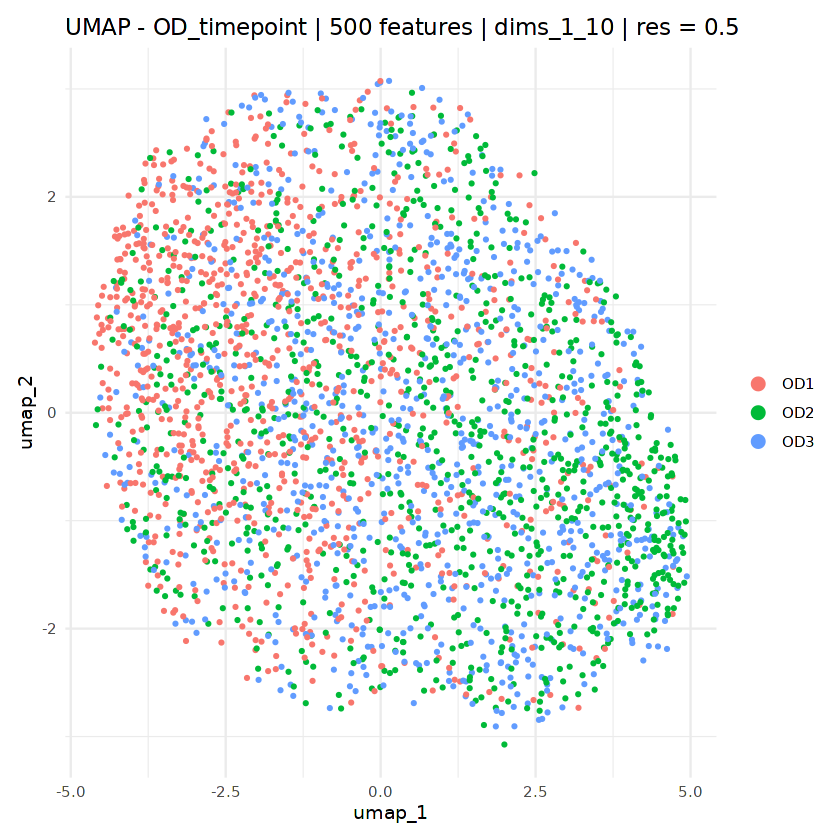

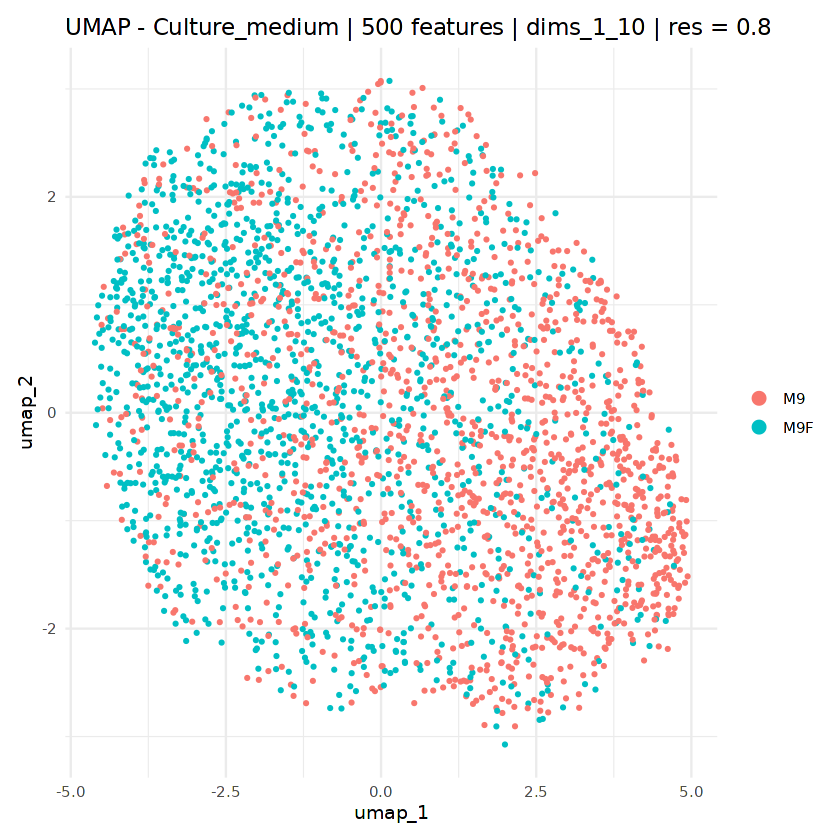

>> nfeatures: 500 | dims: dims_1_10 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 92519

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5409
Number of communities: 8
Elapsed time: 0 seconds


14:58:23 UMAP embedding parameters a = 0.9922 b = 1.112

14:58:23 Read 2934 rows and found 10 numeric columns

14:58:23 Using Annoy for neighbor search, n_neighbors = 30

14:58:23 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:58:23 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100206aee67d7

14:58:23 Searching Annoy index using 1 thread, search_k = 3000

14:58:24 Annoy recall = 100%

14:58:25 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:58:26 Initializing from normalized Laplacian + noise (using RSpectra)

14:58:26 Commencing optimization for 500 epochs, with 108628 positive edges

14:58:26 Using rng type: pcg

14:58:29 Optimization finished



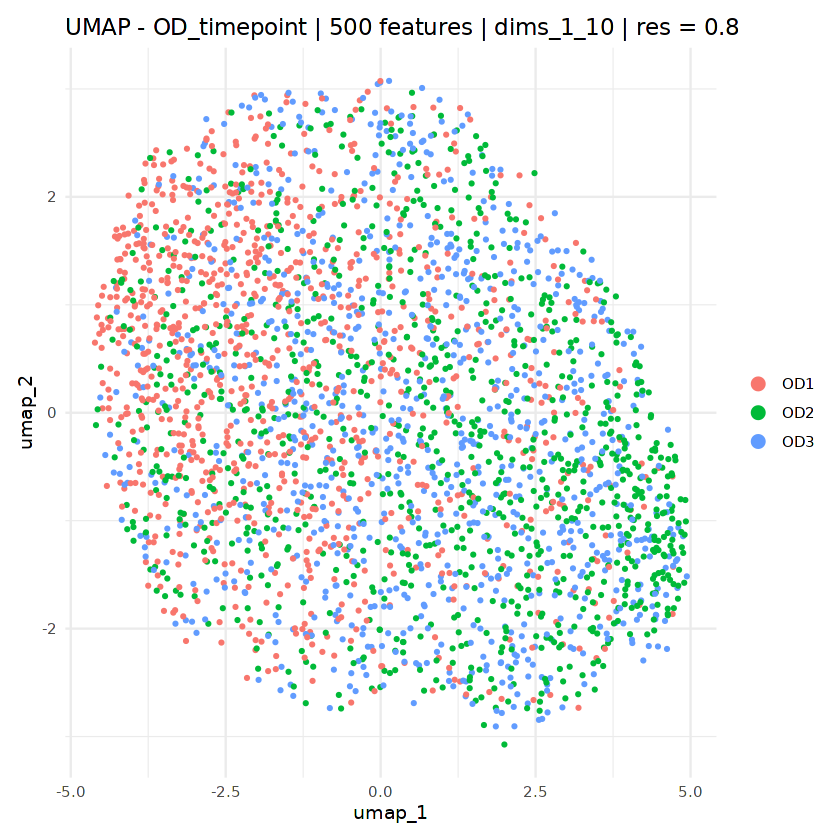

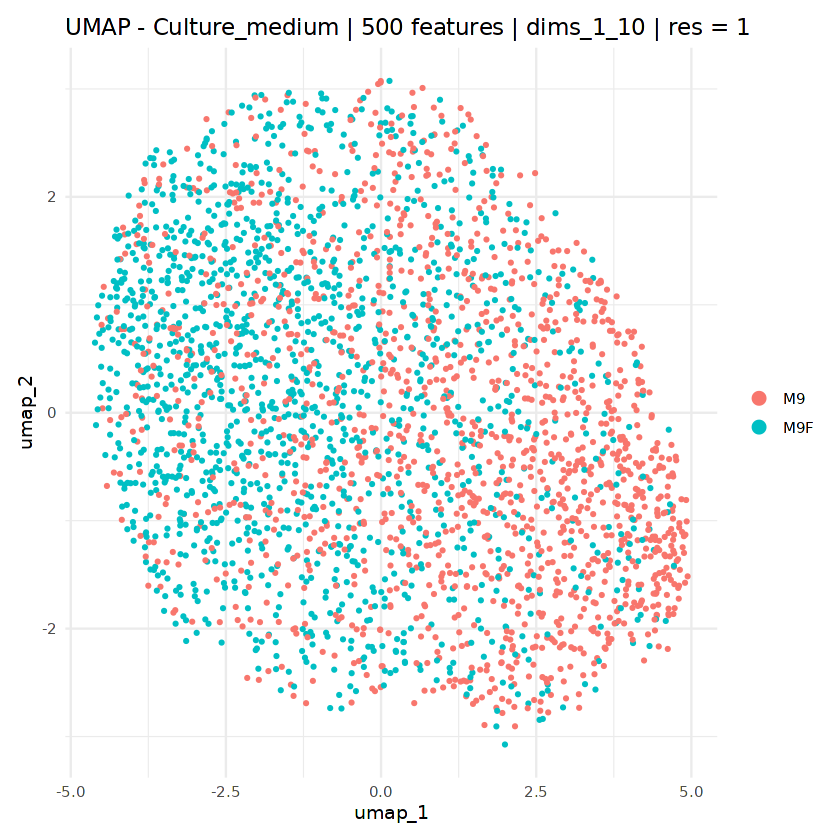

>> nfeatures: 500 | dims: dims_1_15 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103783

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7799
Number of communities: 2
Elapsed time: 0 seconds


14:58:32 UMAP embedding parameters a = 0.9922 b = 1.112

14:58:32 Read 2934 rows and found 15 numeric columns

14:58:32 Using Annoy for neighbor search, n_neighbors = 30

14:58:32 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:58:33 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002053faeb6d

14:58:33 Searching Annoy index using 1 thread, search_k = 3000

14:58:34 Annoy recall = 100%

14:58:35 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:58:36 Initializing from normalized Laplacian + noise (using RSpectra)

14:58:36 Commencing optimization for 500 epochs, with 110350 positive edges

14:58:36 Using rng type: pcg

14:58:40 Optimization finished



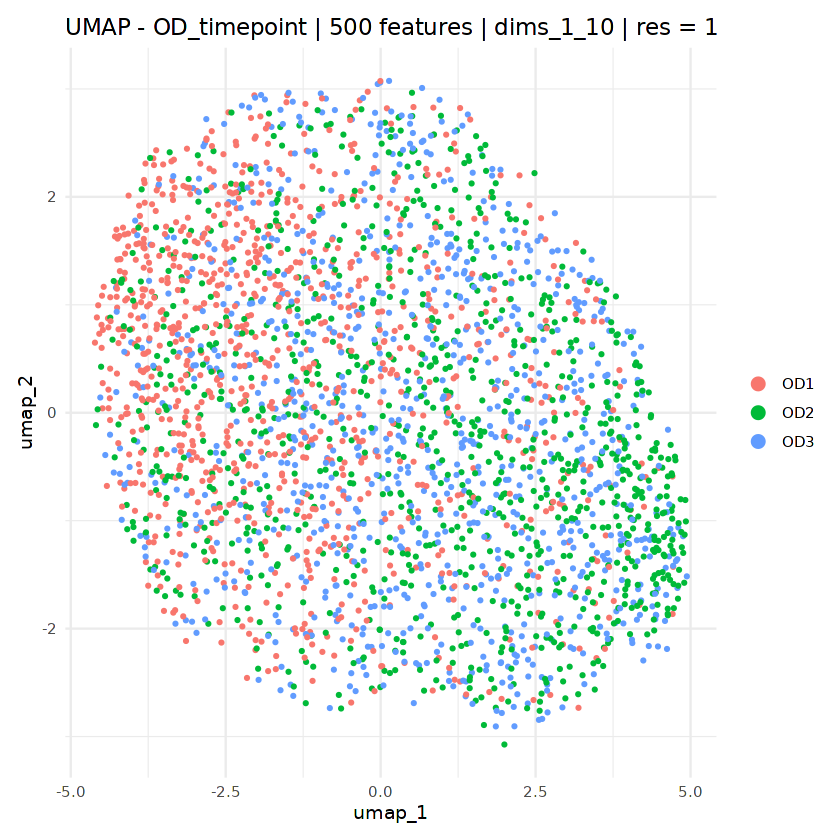

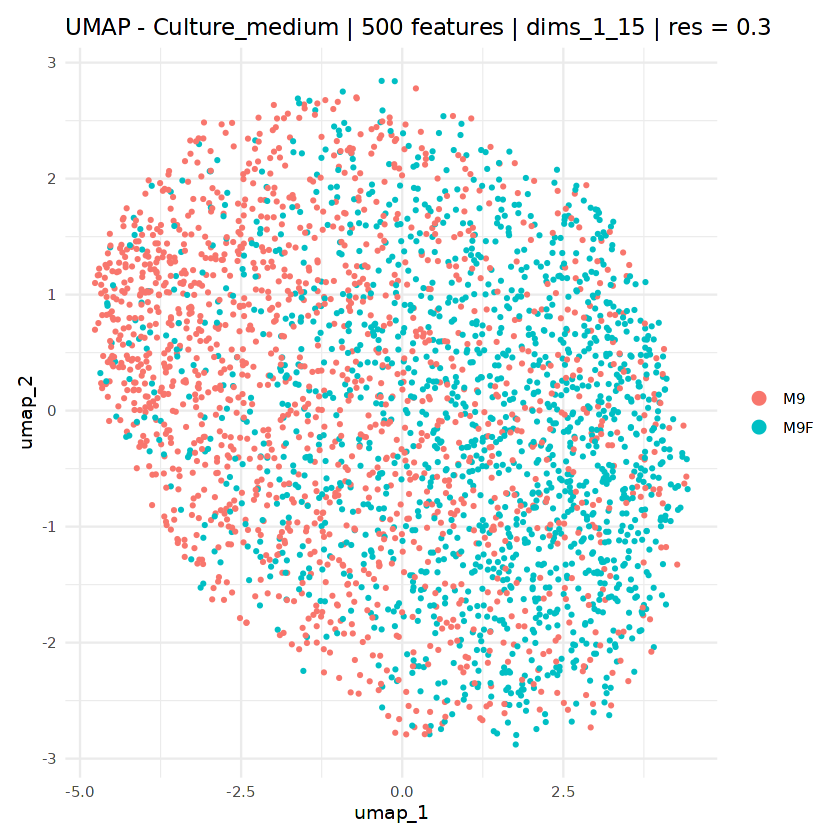

>> nfeatures: 500 | dims: dims_1_15 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103783

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6814
Number of communities: 3
Elapsed time: 0 seconds


14:58:43 UMAP embedding parameters a = 0.9922 b = 1.112

14:58:43 Read 2934 rows and found 15 numeric columns

14:58:43 Using Annoy for neighbor search, n_neighbors = 30

14:58:43 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:58:44 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020764ba90c

14:58:44 Searching Annoy index using 1 thread, search_k = 3000

14:58:44 Annoy recall = 100%

14:58:45 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:58:46 Initializing from normalized Laplacian + noise (using RSpectra)

14:58:46 Commencing optimization for 500 epochs, with 110350 positive edges

14:58:46 Using rng type: pcg

14:58:50 Optimization finished



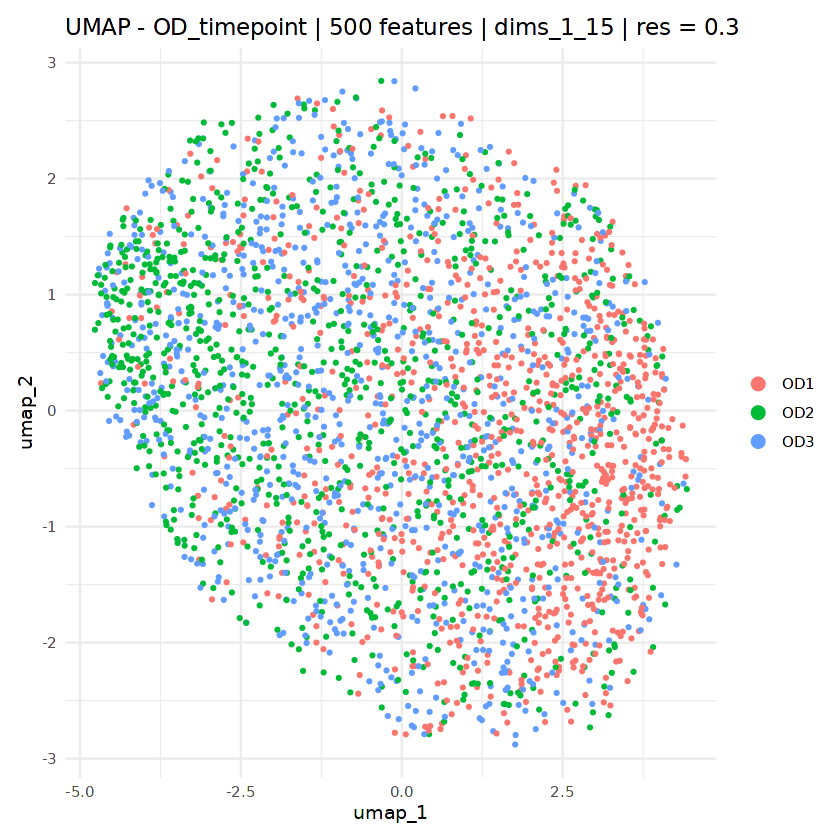

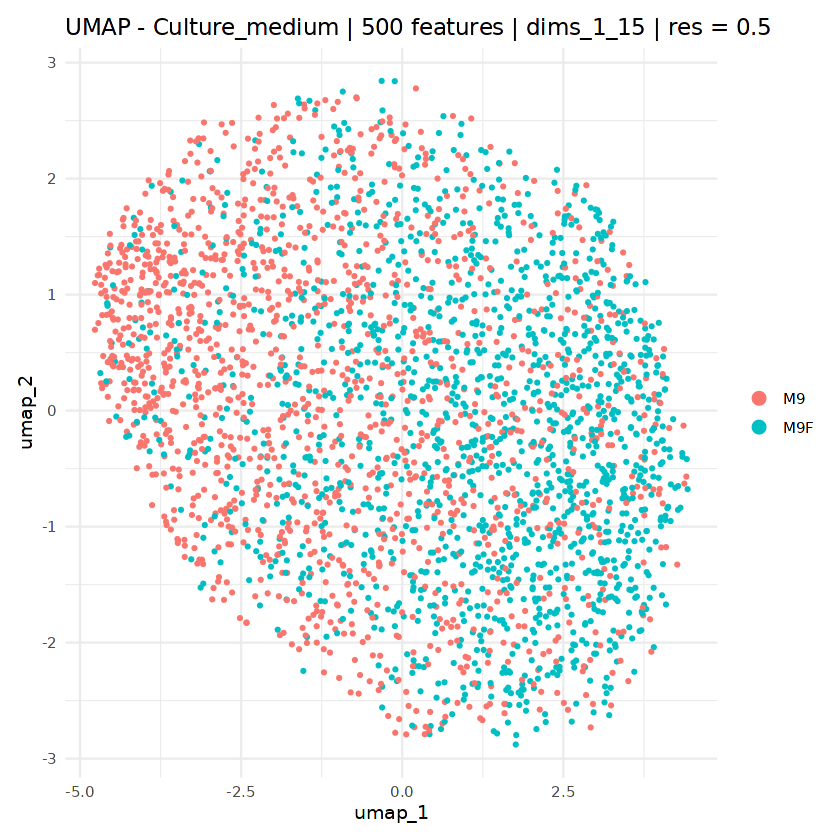

>> nfeatures: 500 | dims: dims_1_15 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103783

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5777
Number of communities: 4
Elapsed time: 0 seconds


14:58:53 UMAP embedding parameters a = 0.9922 b = 1.112

14:58:53 Read 2934 rows and found 15 numeric columns

14:58:53 Using Annoy for neighbor search, n_neighbors = 30

14:58:53 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:58:54 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002025a0c995

14:58:54 Searching Annoy index using 1 thread, search_k = 3000

14:58:55 Annoy recall = 100%

14:58:58 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:59:00 Initializing from normalized Laplacian + noise (using RSpectra)

14:59:00 Commencing optimization for 500 epochs, with 110350 positive edges

14:59:00 Using rng type: pcg

14:59:03 Optimization finished



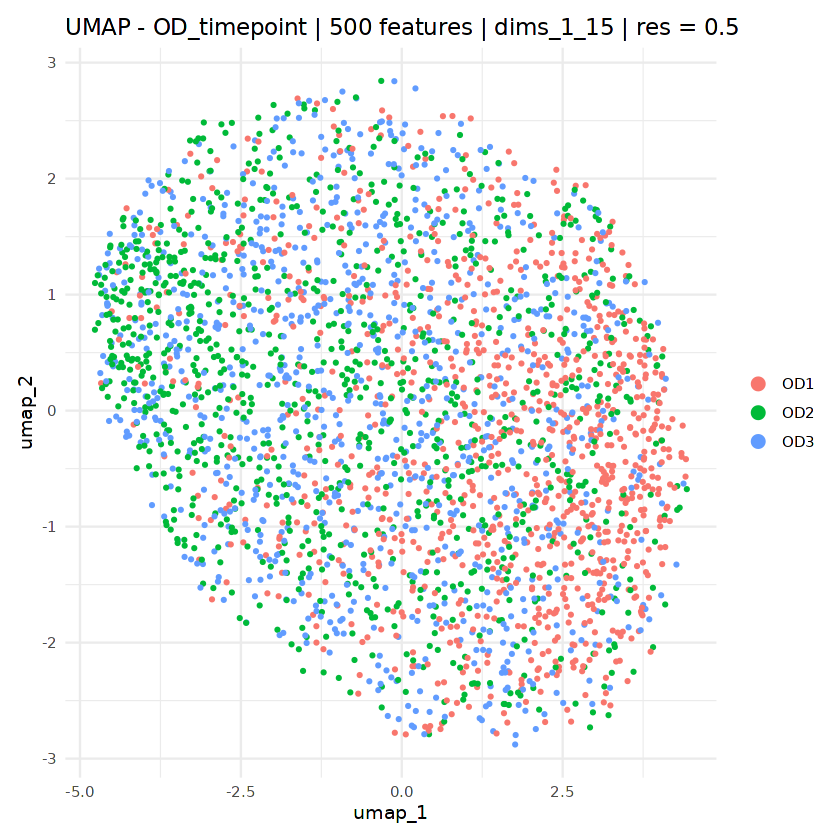

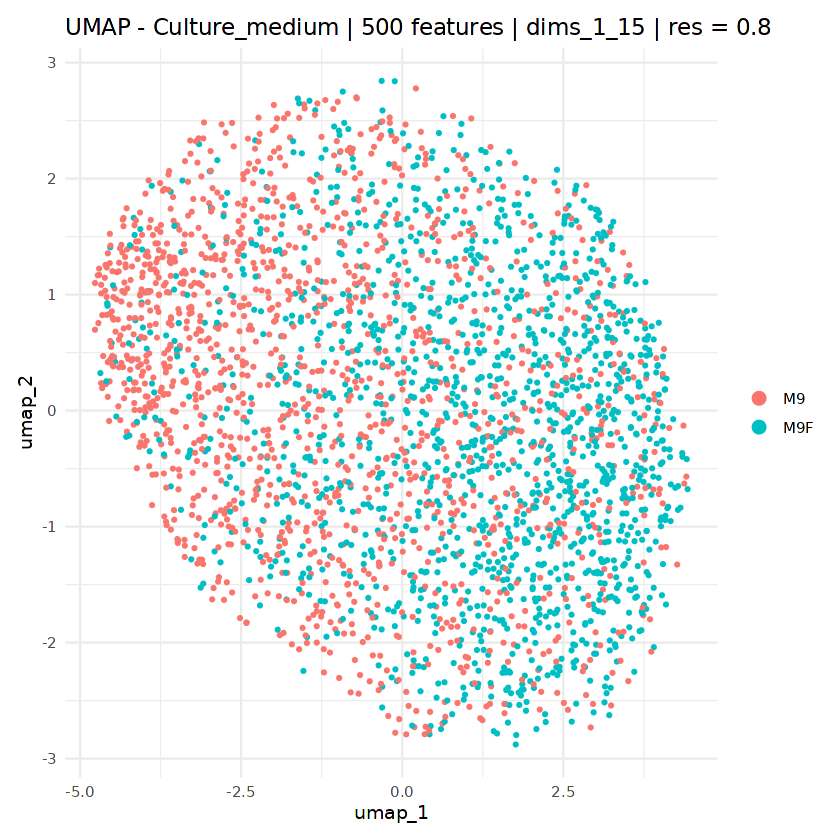

>> nfeatures: 500 | dims: dims_1_15 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103783

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5188
Number of communities: 5
Elapsed time: 0 seconds


14:59:06 UMAP embedding parameters a = 0.9922 b = 1.112

14:59:06 Read 2934 rows and found 15 numeric columns

14:59:06 Using Annoy for neighbor search, n_neighbors = 30

14:59:06 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:59:07 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100206b8805a1

14:59:07 Searching Annoy index using 1 thread, search_k = 3000

14:59:08 Annoy recall = 100%

14:59:09 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:59:10 Initializing from normalized Laplacian + noise (using RSpectra)

14:59:10 Commencing optimization for 500 epochs, with 110350 positive edges

14:59:10 Using rng type: pcg

14:59:13 Optimization finished



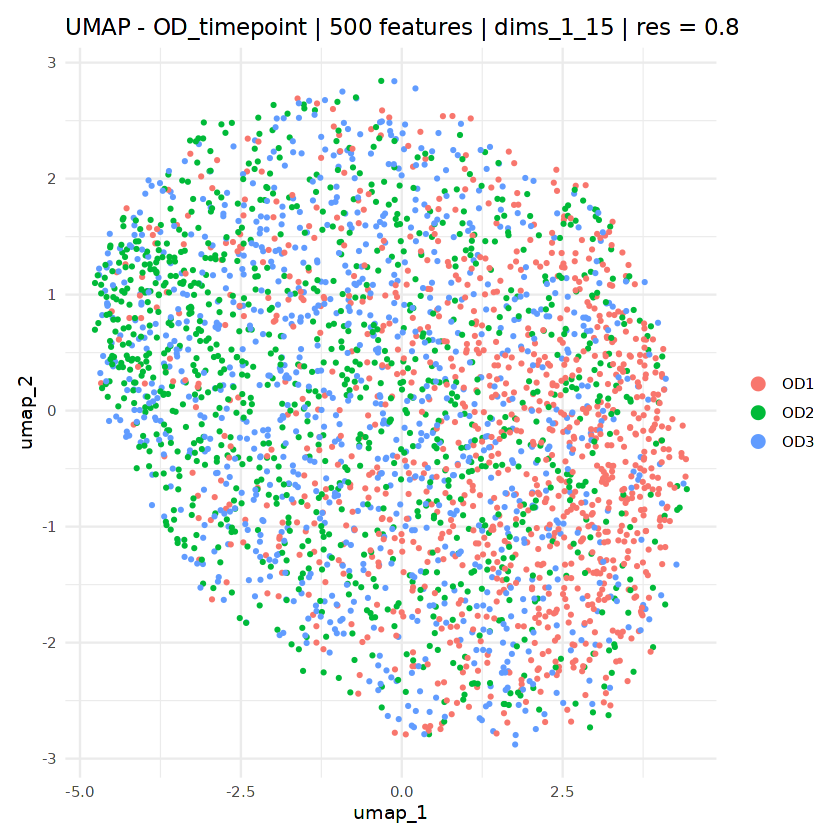

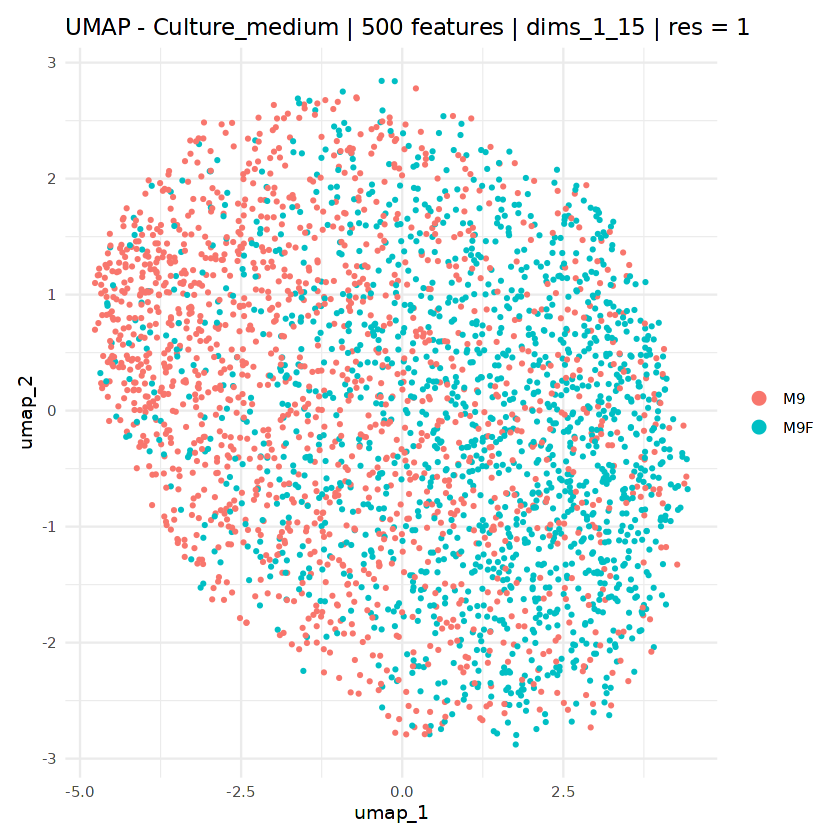

==== nfeatures = 1000 ====

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  QLH64-19225, QLH64-02935, fusA, QLH64-26960, rpoC, QLH64-05400, QLH64-13705, QLH64-13720, icd, QLH64-13710 
	   QLH64-07480, QLH64-30060, rpsB, rplL, QLH64-19800, gltA, QLH64-31045, secA, QLH64-04320, QLH64-12185 
	   QLH64-24685, gltB, QLH64-12130, sdhA, QLH64-13080, tcyJ, leuA_2, QLH64-18250, QLH64-13345, QLH64-04480 
Negative:  QLH64-24105, gluQRS, QLH64-01365, QLH64-02630, choX_1, QLH64-05945, QLH64-30160, QLH64-20285, QLH64-15845, QLH64-06820 
	   QLH64-20500, QLH64-14500, QLH64-04220, QLH64-07875, gbcA, QLH64-26395, QLH64-10750, QLH64-08660, QLH64-09150, QLH64-00325 
	   QLH64-10570, QLH64-12960, QLH64-28180, QLH64-27515, QLH64-24355, QLH64-01295, QLH64-12340, QLH64-29715, QLH64-12900, QLH64-15415 
PC_ 2 
Positive:  QLH64-07335, QLH64-08810, gguB, fur, QLH64-02870, hldE, treS, QLH64-25445, iscR, hisC_2 
	   QLH64-13880, hisD, ftsY, QLH64-24695, QLH64-13700,

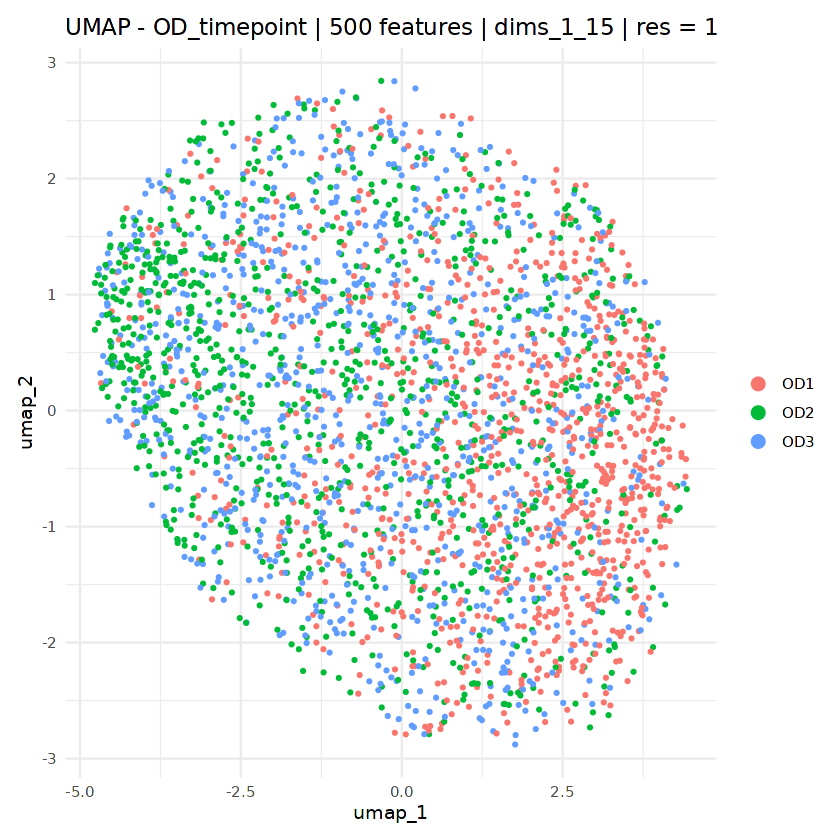

Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


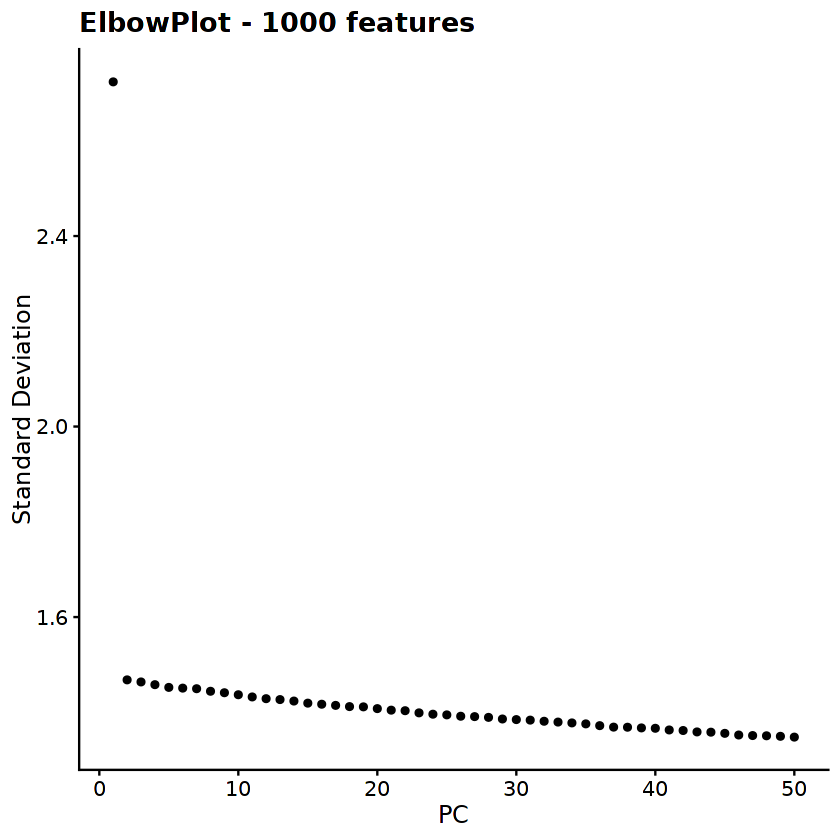

NULL


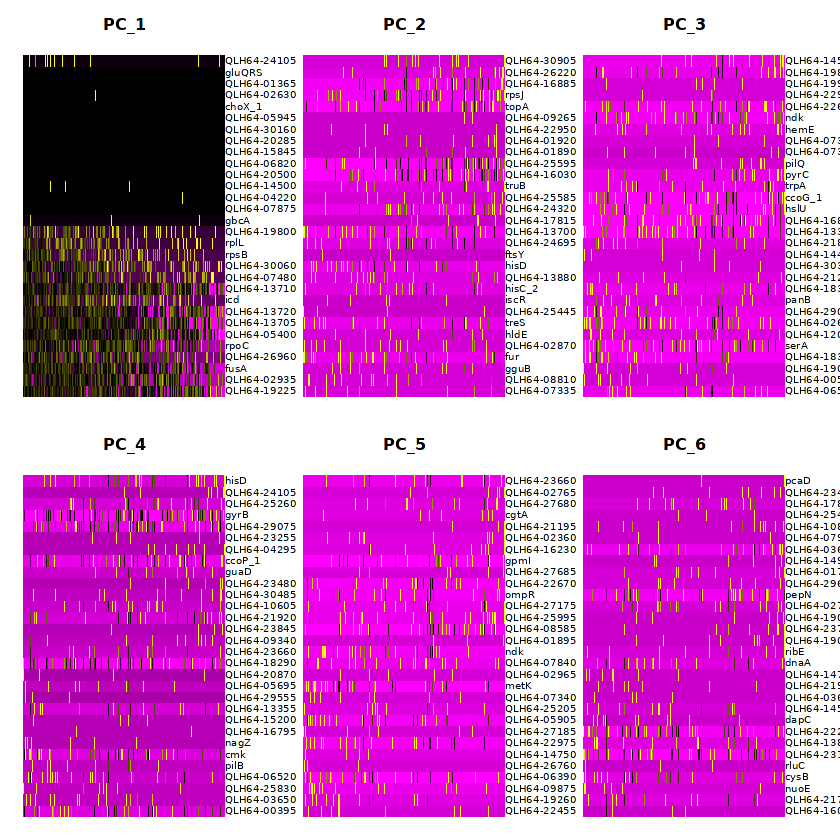

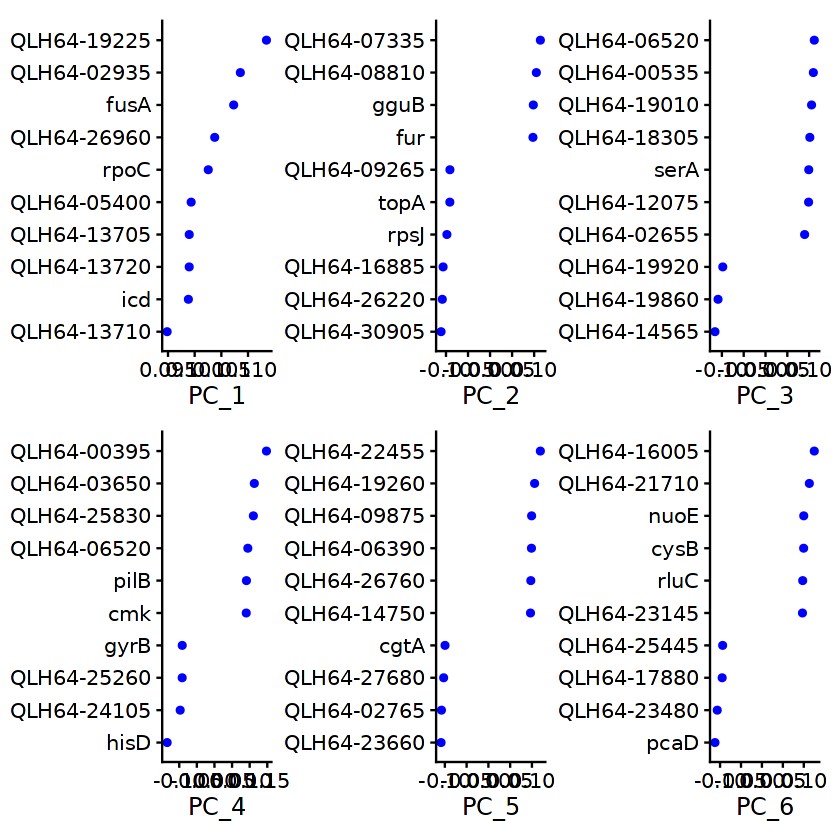

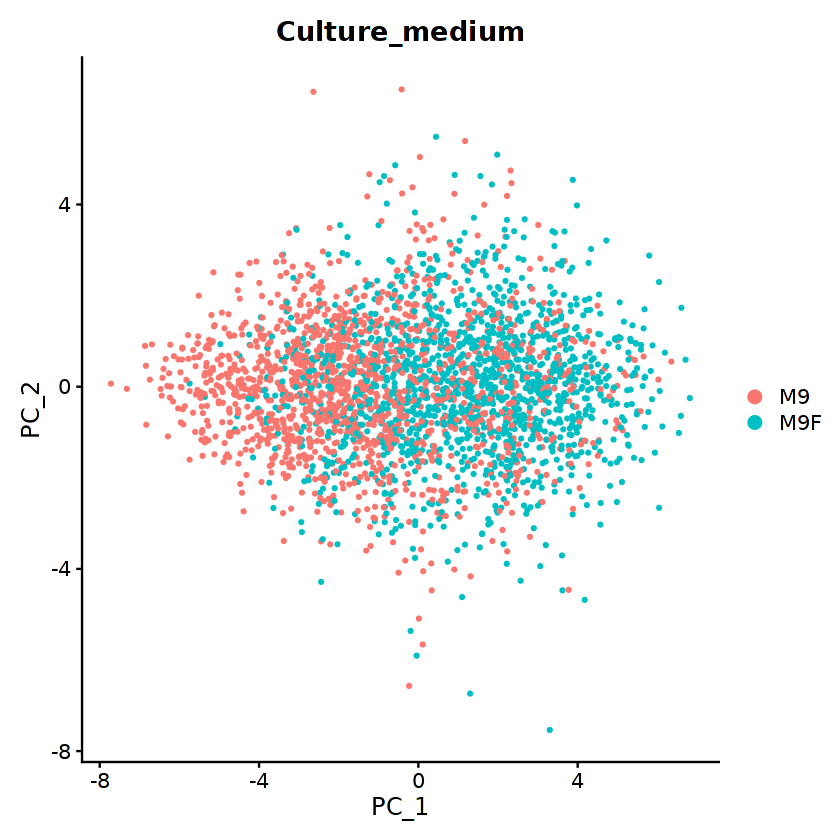

>> nfeatures: 1000 | dims: dims_1_5 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 86090

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7956
Number of communities: 3
Elapsed time: 0 seconds


14:59:27 UMAP embedding parameters a = 0.9922 b = 1.112

14:59:27 Read 2934 rows and found 5 numeric columns

14:59:27 Using Annoy for neighbor search, n_neighbors = 30

14:59:27 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:59:29 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020780badef

14:59:29 Searching Annoy index using 1 thread, search_k = 3000

14:59:30 Annoy recall = 100%

14:59:31 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:59:32 Initializing from normalized Laplacian + noise (using RSpectra)

14:59:32 Commencing optimization for 500 epochs, with 103788 positive edges

14:59:32 Using rng type: pcg

14:59:35 Optimization finished



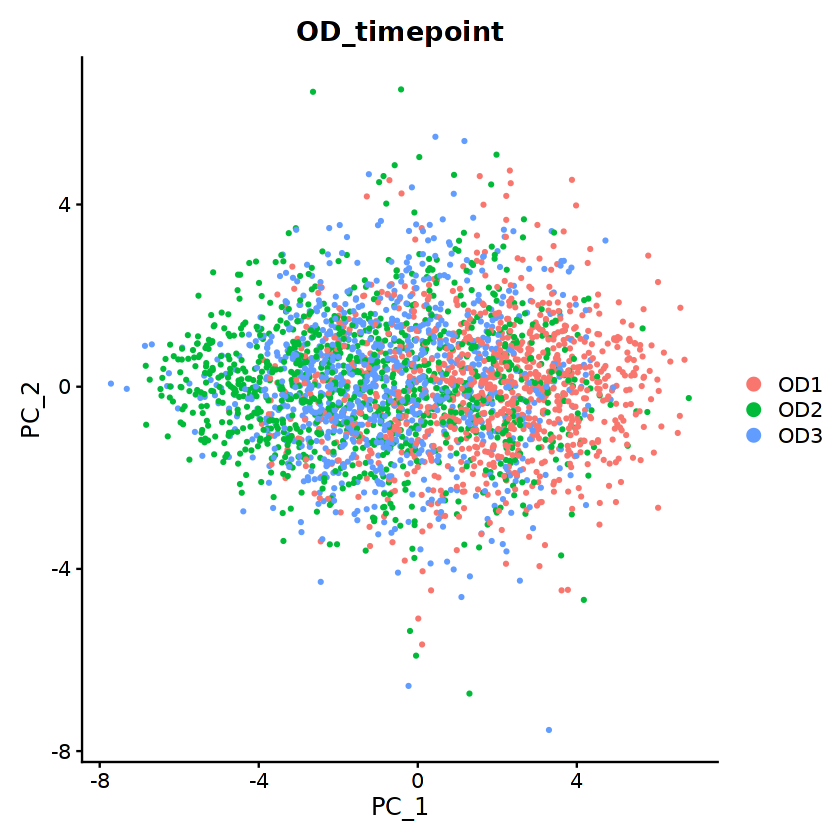

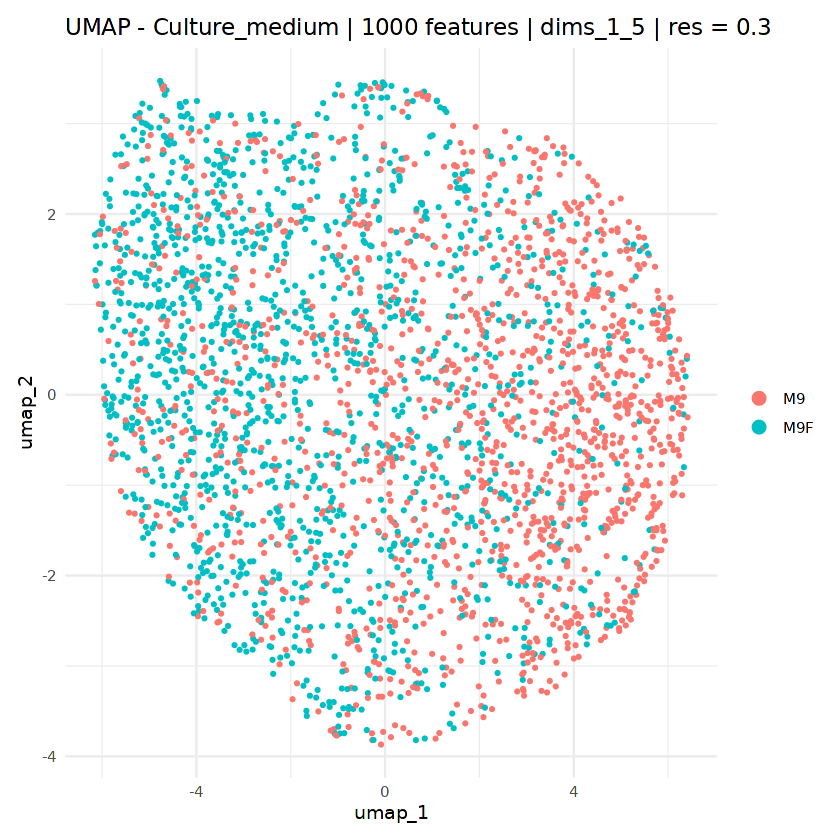

>> nfeatures: 1000 | dims: dims_1_5 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 86090

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7264
Number of communities: 5
Elapsed time: 0 seconds


14:59:38 UMAP embedding parameters a = 0.9922 b = 1.112

14:59:38 Read 2934 rows and found 5 numeric columns

14:59:38 Using Annoy for neighbor search, n_neighbors = 30

14:59:38 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:59:39 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020bfdfbaf

14:59:39 Searching Annoy index using 1 thread, search_k = 3000

14:59:40 Annoy recall = 100%

14:59:41 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:59:42 Initializing from normalized Laplacian + noise (using RSpectra)

14:59:42 Commencing optimization for 500 epochs, with 103788 positive edges

14:59:42 Using rng type: pcg

14:59:45 Optimization finished



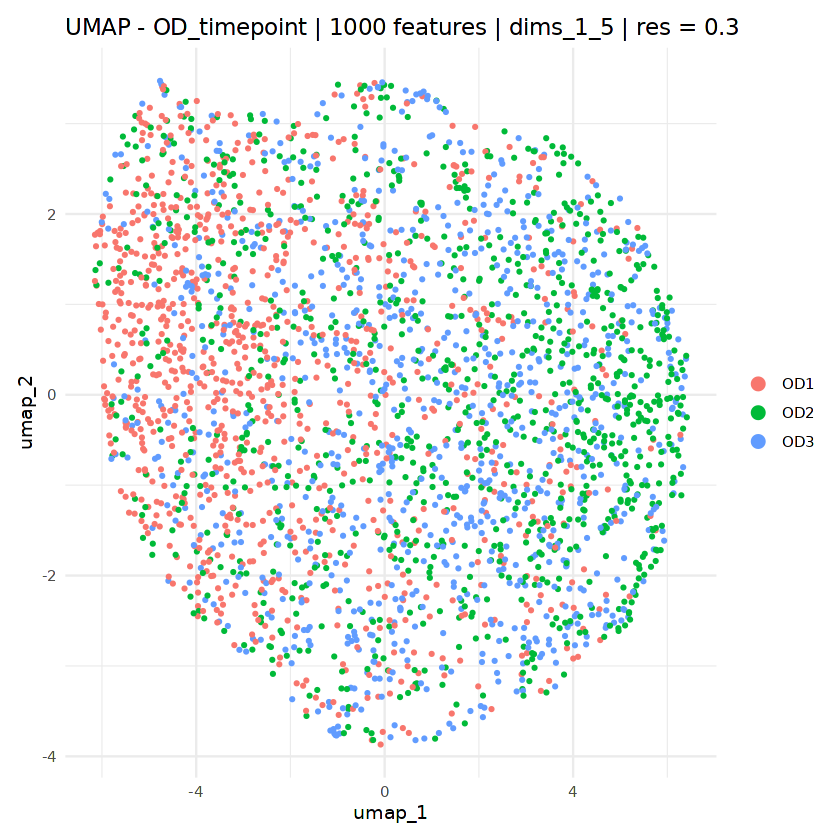

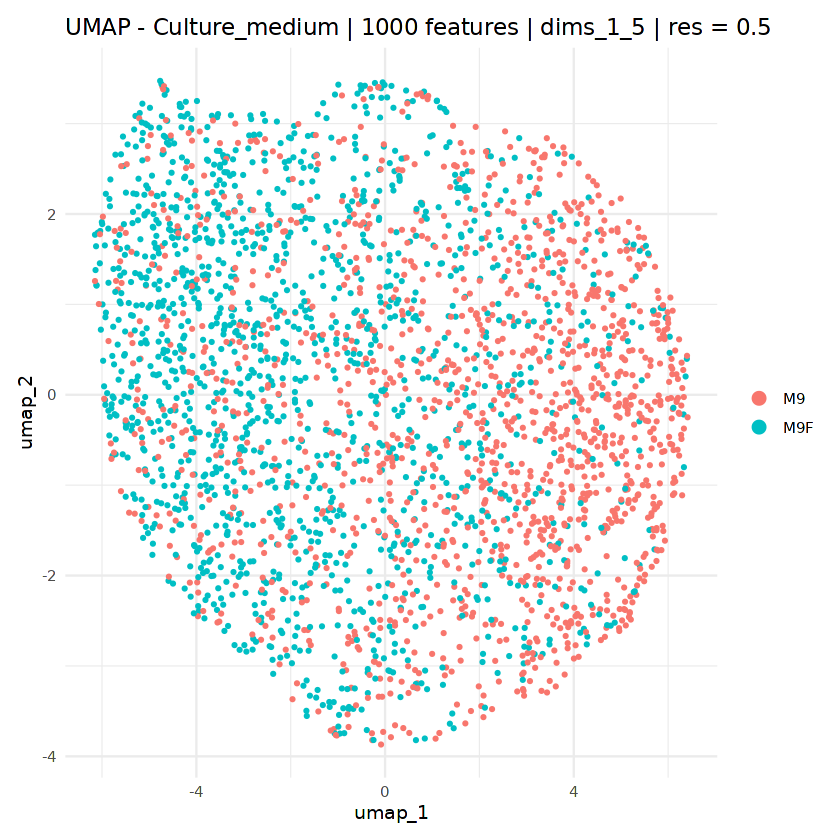

>> nfeatures: 1000 | dims: dims_1_5 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 86090

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6737
Number of communities: 9
Elapsed time: 0 seconds


14:59:49 UMAP embedding parameters a = 0.9922 b = 1.112

14:59:49 Read 2934 rows and found 5 numeric columns

14:59:49 Using Annoy for neighbor search, n_neighbors = 30

14:59:49 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:59:50 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020b9b25a6

14:59:50 Searching Annoy index using 1 thread, search_k = 3000

14:59:51 Annoy recall = 100%

14:59:52 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:59:54 Initializing from normalized Laplacian + noise (using RSpectra)

14:59:54 Commencing optimization for 500 epochs, with 103788 positive edges

14:59:54 Using rng type: pcg

14:59:57 Optimization finished



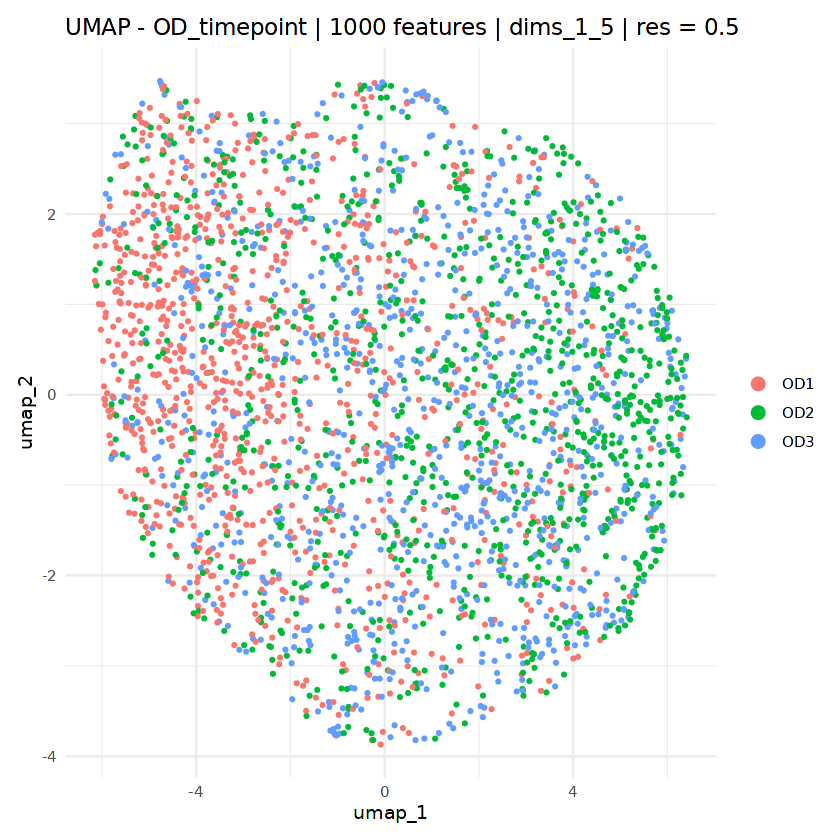

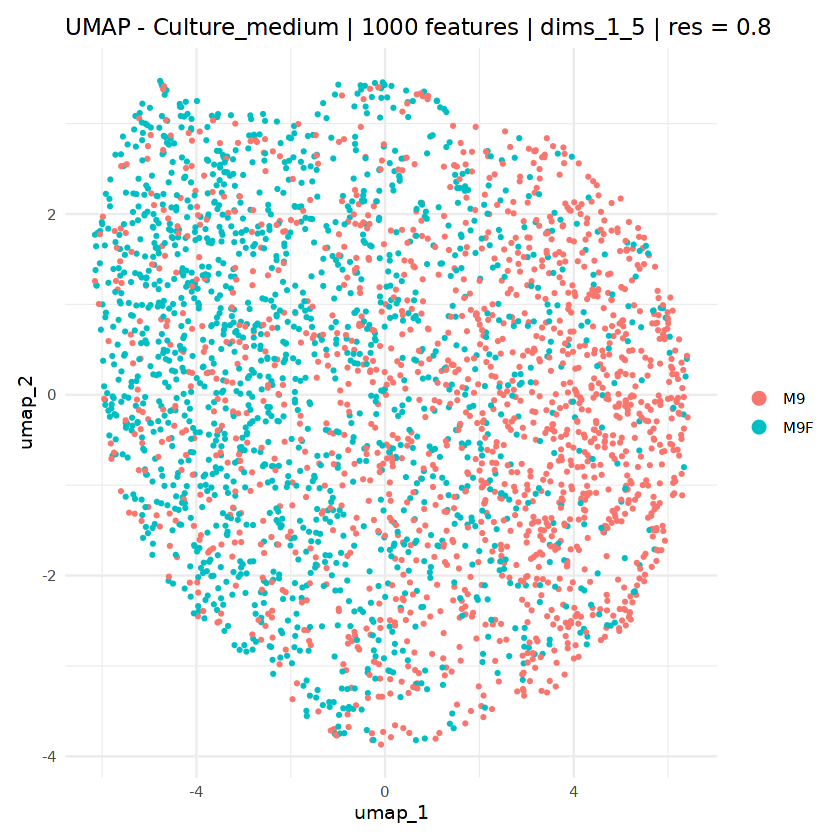

>> nfeatures: 1000 | dims: dims_1_5 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 86090

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6502
Number of communities: 12
Elapsed time: 0 seconds


15:00:00 UMAP embedding parameters a = 0.9922 b = 1.112

15:00:00 Read 2934 rows and found 5 numeric columns

15:00:00 Using Annoy for neighbor search, n_neighbors = 30

15:00:00 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:00:01 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002043e199d8

15:00:01 Searching Annoy index using 1 thread, search_k = 3000

15:00:02 Annoy recall = 100%

15:00:03 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:00:05 Initializing from normalized Laplacian + noise (using RSpectra)

15:00:05 Commencing optimization for 500 epochs, with 103788 positive edges

15:00:05 Using rng type: pcg

15:00:08 Optimization finished



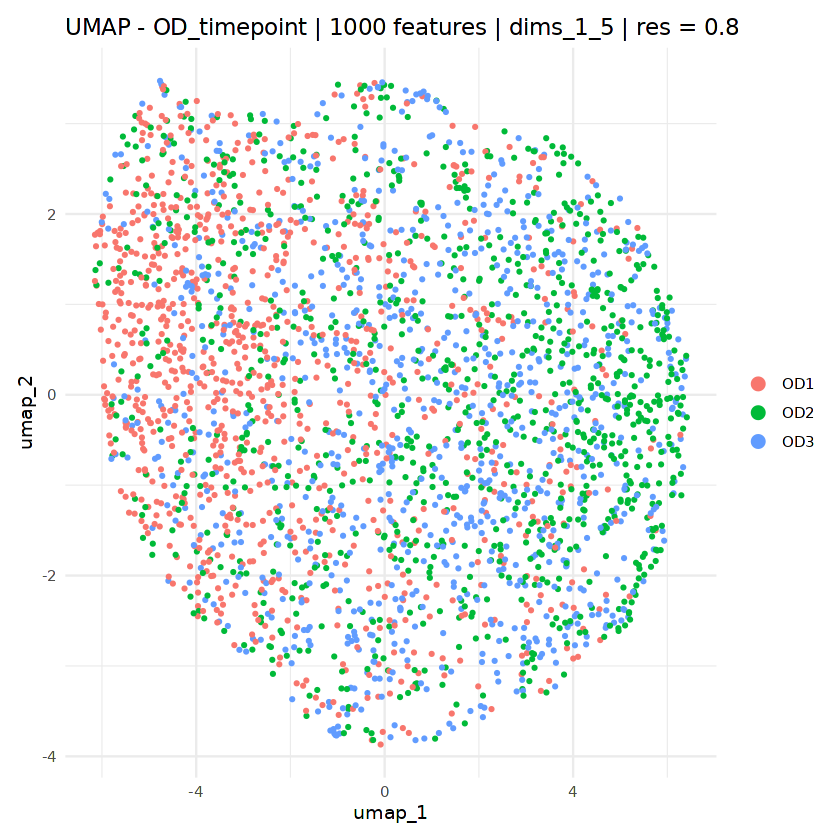

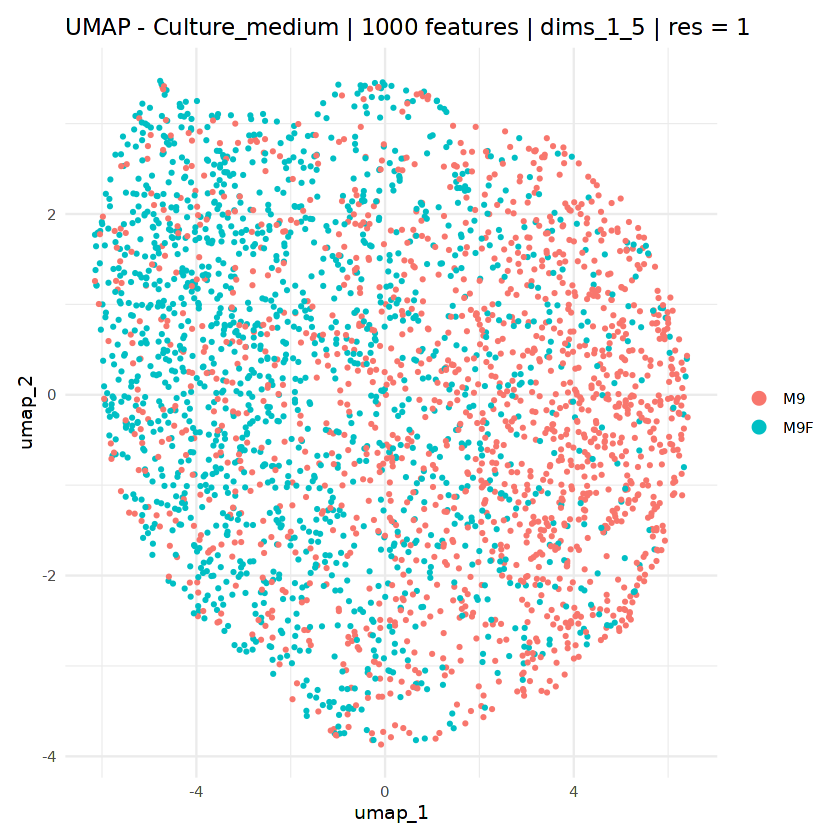

>> nfeatures: 1000 | dims: dims_1_10 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 92330

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7830
Number of communities: 2
Elapsed time: 0 seconds


15:00:11 UMAP embedding parameters a = 0.9922 b = 1.112

15:00:11 Read 2934 rows and found 10 numeric columns

15:00:11 Using Annoy for neighbor search, n_neighbors = 30

15:00:11 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:00:13 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002033c6f4c3

15:00:13 Searching Annoy index using 1 thread, search_k = 3000

15:00:13 Annoy recall = 100%

15:00:14 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:00:16 Initializing from normalized Laplacian + noise (using RSpectra)

15:00:16 Commencing optimization for 500 epochs, with 114016 positive edges

15:00:16 Using rng type: pcg

15:00:19 Optimization finished



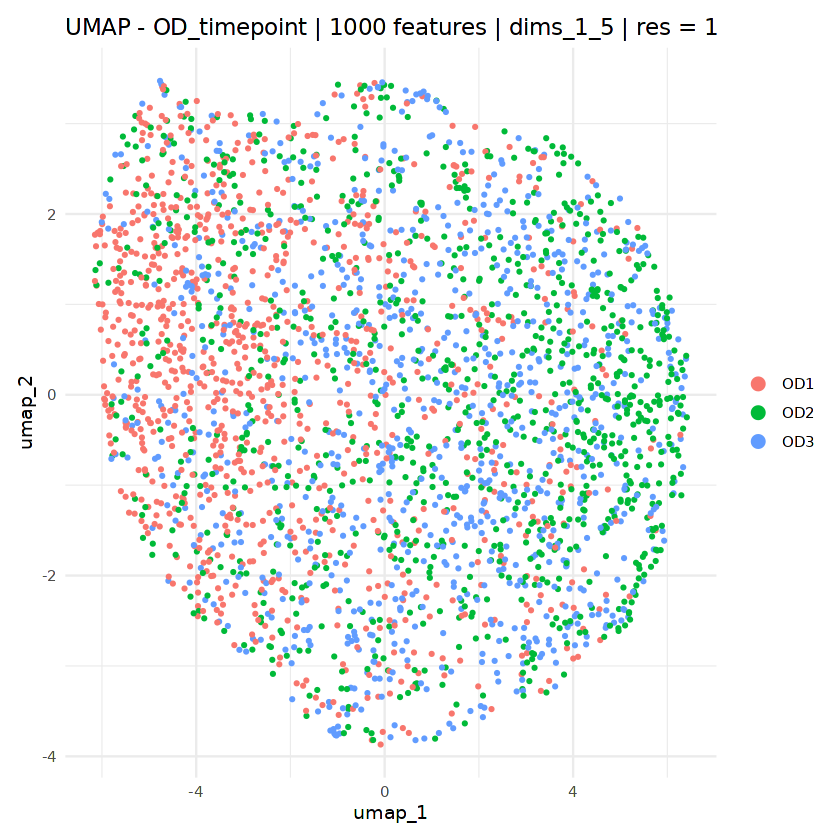

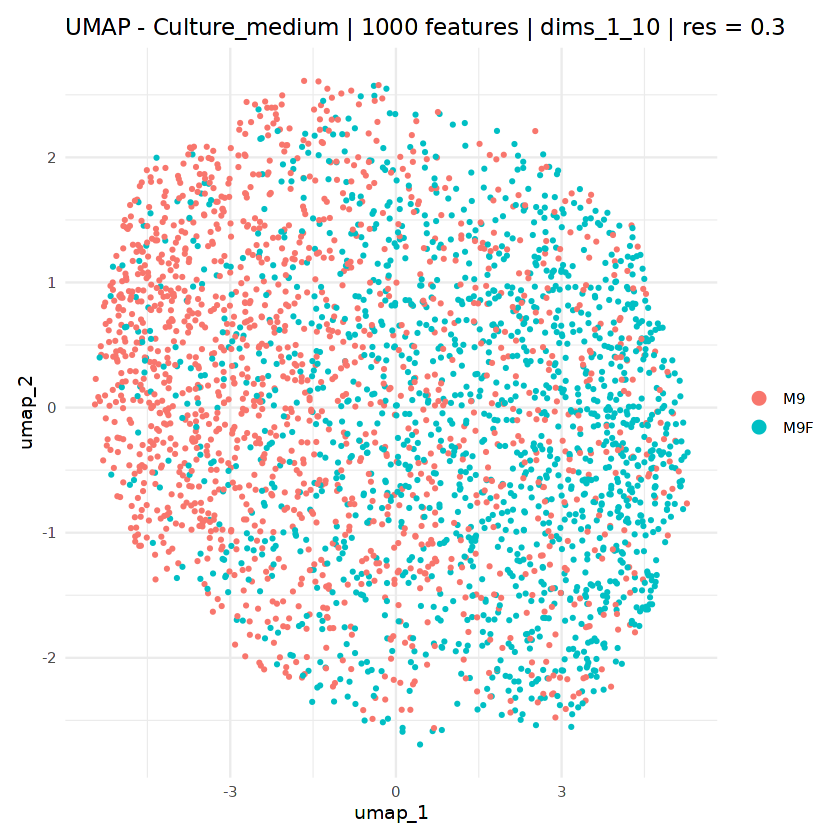

>> nfeatures: 1000 | dims: dims_1_10 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 92330

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6905
Number of communities: 3
Elapsed time: 0 seconds


15:00:22 UMAP embedding parameters a = 0.9922 b = 1.112

15:00:22 Read 2934 rows and found 10 numeric columns

15:00:22 Using Annoy for neighbor search, n_neighbors = 30

15:00:22 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:00:23 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100201a0e2e63

15:00:23 Searching Annoy index using 1 thread, search_k = 3000

15:00:24 Annoy recall = 100%

15:00:25 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:00:26 Initializing from normalized Laplacian + noise (using RSpectra)

15:00:26 Commencing optimization for 500 epochs, with 114016 positive edges

15:00:26 Using rng type: pcg

15:00:29 Optimization finished



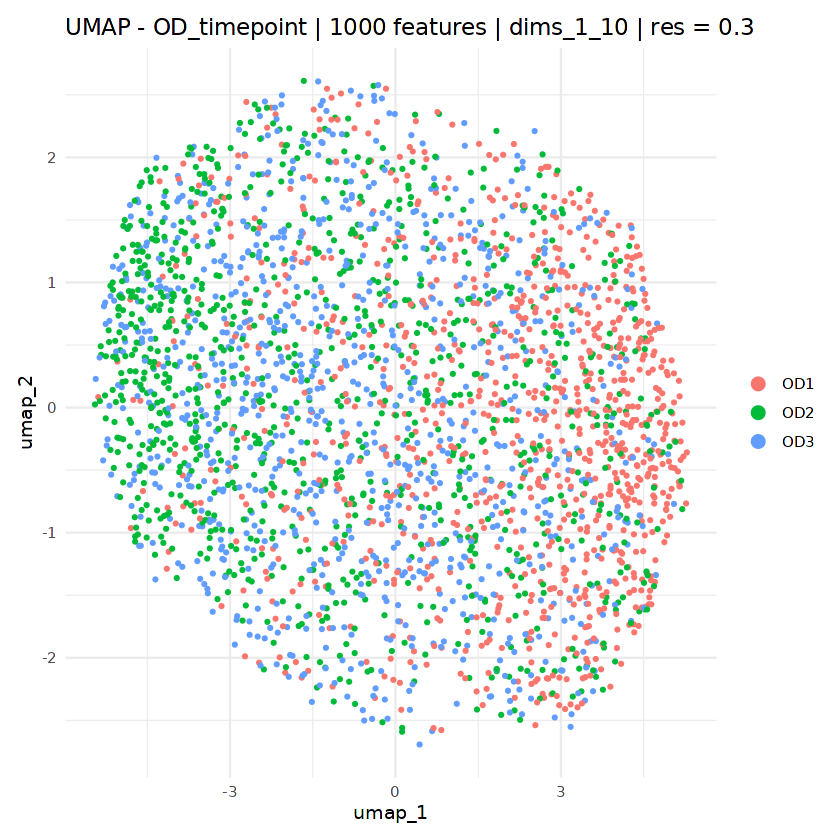

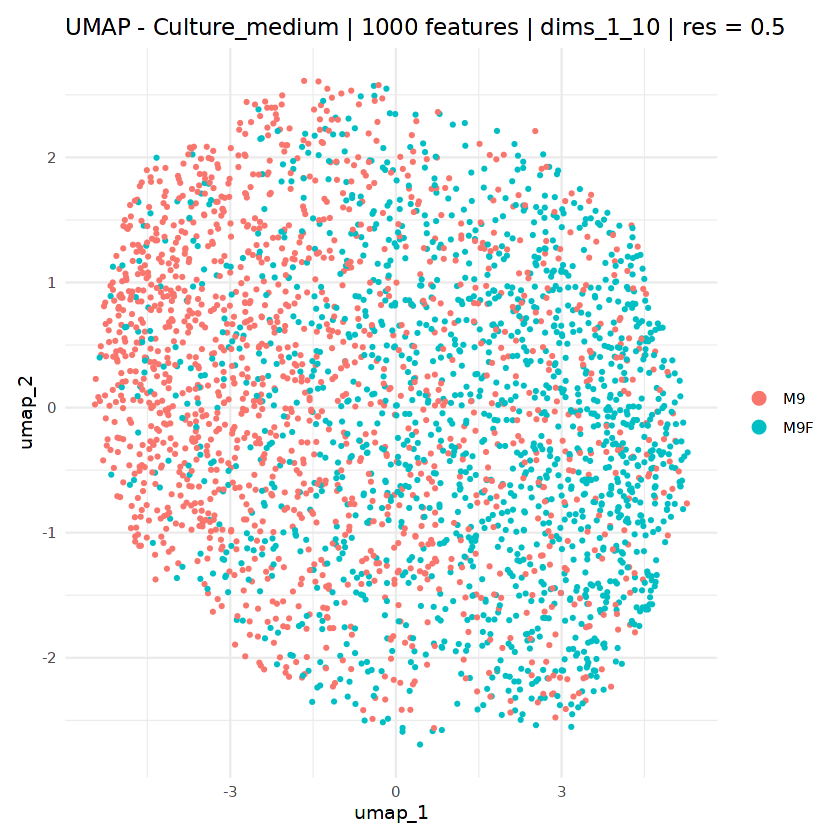

>> nfeatures: 1000 | dims: dims_1_10 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 92330

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5902
Number of communities: 4
Elapsed time: 0 seconds


15:00:33 UMAP embedding parameters a = 0.9922 b = 1.112

15:00:33 Read 2934 rows and found 10 numeric columns

15:00:33 Using Annoy for neighbor search, n_neighbors = 30

15:00:33 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:00:34 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100204bedc1d1

15:00:34 Searching Annoy index using 1 thread, search_k = 3000

15:00:35 Annoy recall = 100%

15:00:36 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:00:37 Initializing from normalized Laplacian + noise (using RSpectra)

15:00:37 Commencing optimization for 500 epochs, with 114016 positive edges

15:00:37 Using rng type: pcg

15:00:41 Optimization finished



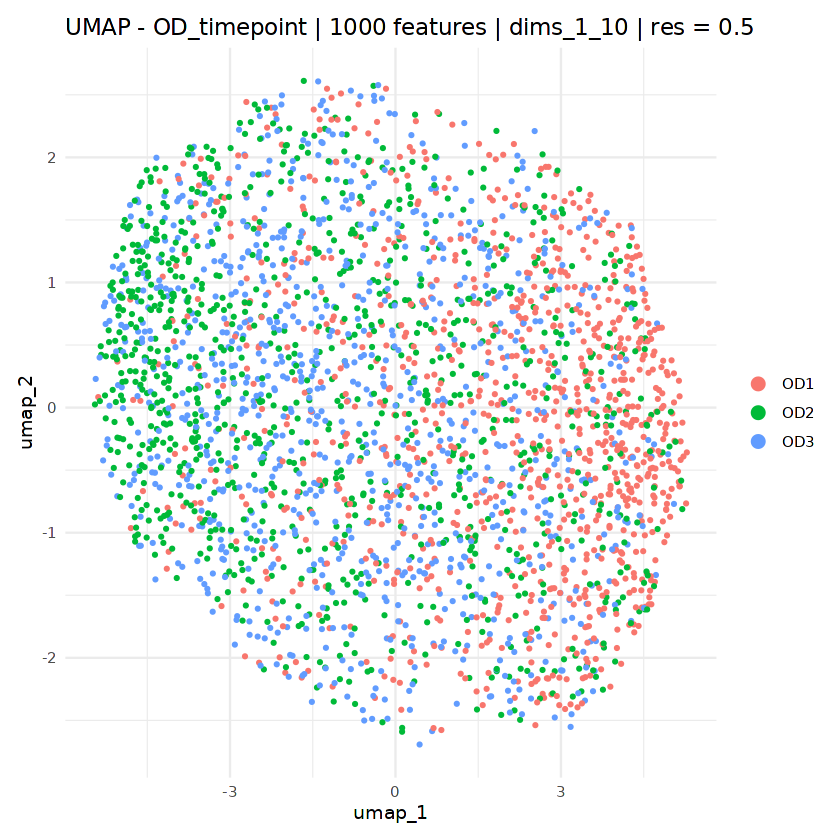

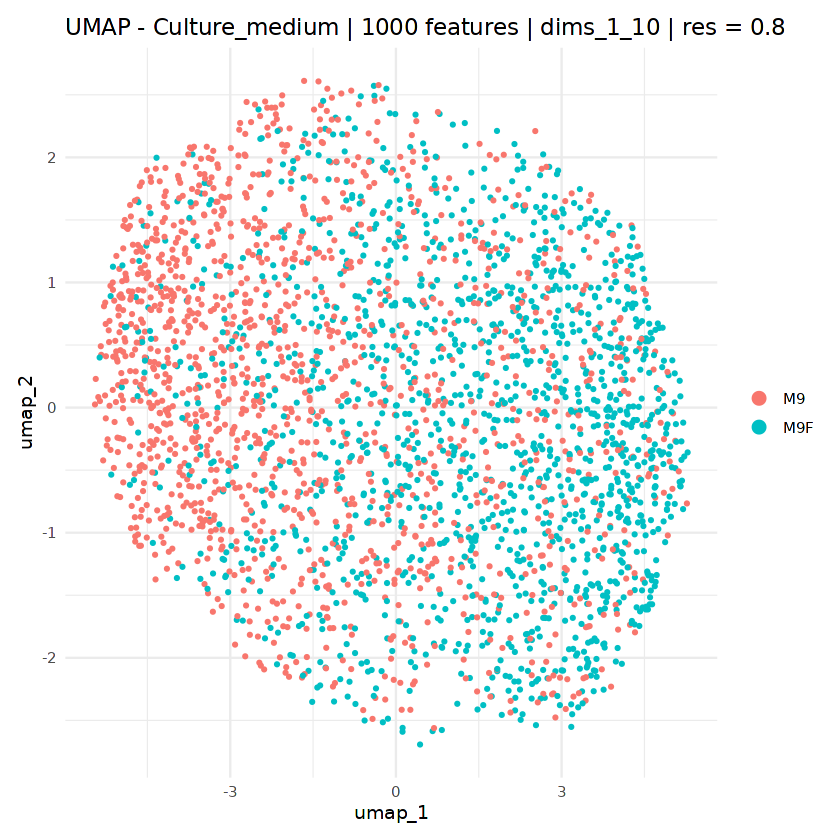

>> nfeatures: 1000 | dims: dims_1_10 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 92330

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5452
Number of communities: 6
Elapsed time: 0 seconds


15:00:45 UMAP embedding parameters a = 0.9922 b = 1.112

15:00:45 Read 2934 rows and found 10 numeric columns

15:00:45 Using Annoy for neighbor search, n_neighbors = 30

15:00:45 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:00:46 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100207c2e65bd

15:00:46 Searching Annoy index using 1 thread, search_k = 3000

15:00:47 Annoy recall = 100%

15:00:49 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:00:50 Initializing from normalized Laplacian + noise (using RSpectra)

15:00:50 Commencing optimization for 500 epochs, with 114016 positive edges

15:00:50 Using rng type: pcg

15:00:54 Optimization finished



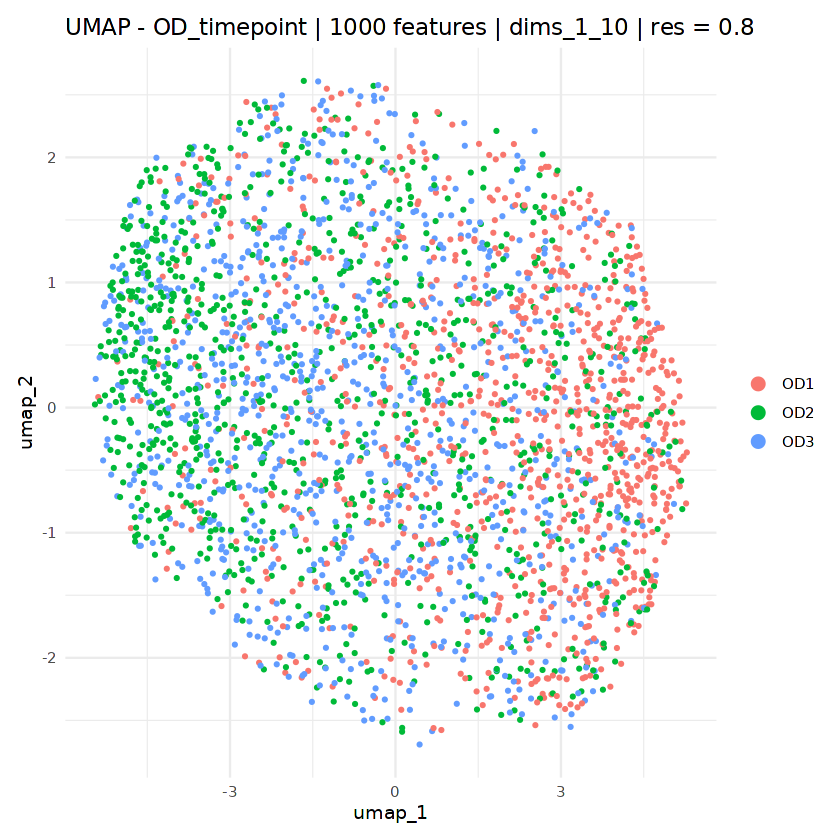

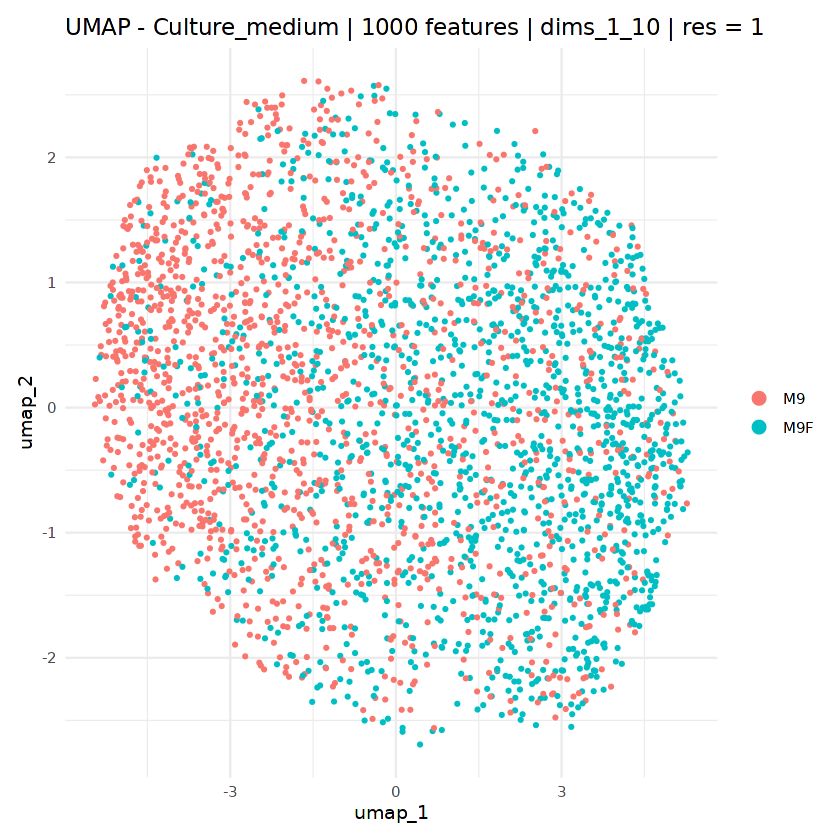

>> nfeatures: 1000 | dims: dims_1_15 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103298

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7986
Number of communities: 2
Elapsed time: 0 seconds


15:00:58 UMAP embedding parameters a = 0.9922 b = 1.112

15:00:58 Read 2934 rows and found 15 numeric columns

15:00:58 Using Annoy for neighbor search, n_neighbors = 30

15:00:58 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:00:59 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100205c125f06

15:00:59 Searching Annoy index using 1 thread, search_k = 3000

15:01:00 Annoy recall = 100%

15:01:01 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:01:03 Initializing from normalized Laplacian + noise (using RSpectra)

15:01:03 Commencing optimization for 500 epochs, with 117716 positive edges

15:01:03 Using rng type: pcg

15:01:06 Optimization finished



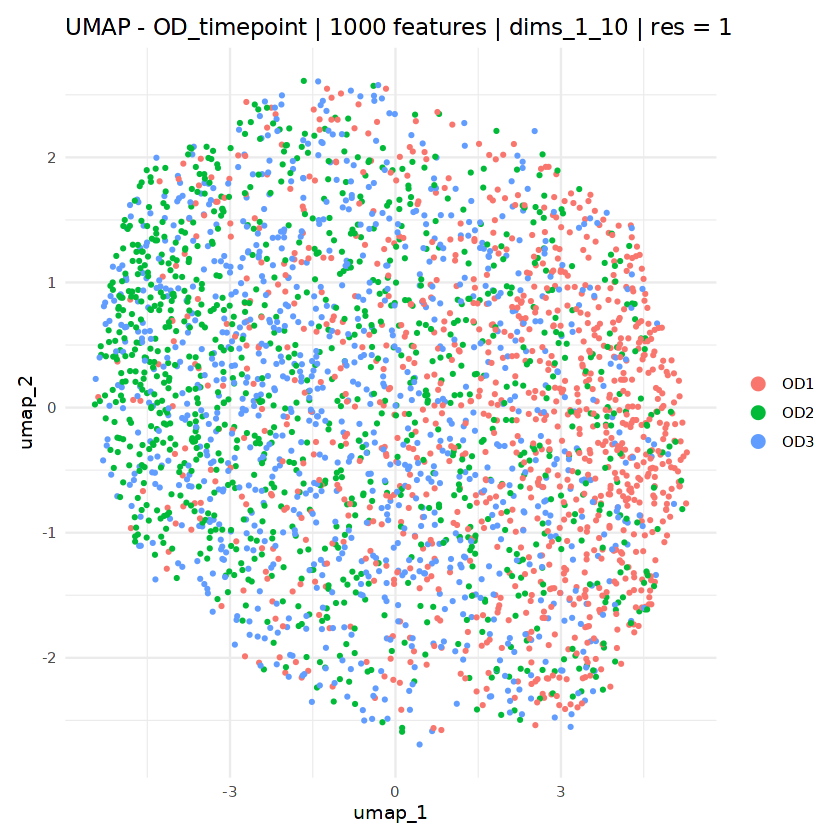

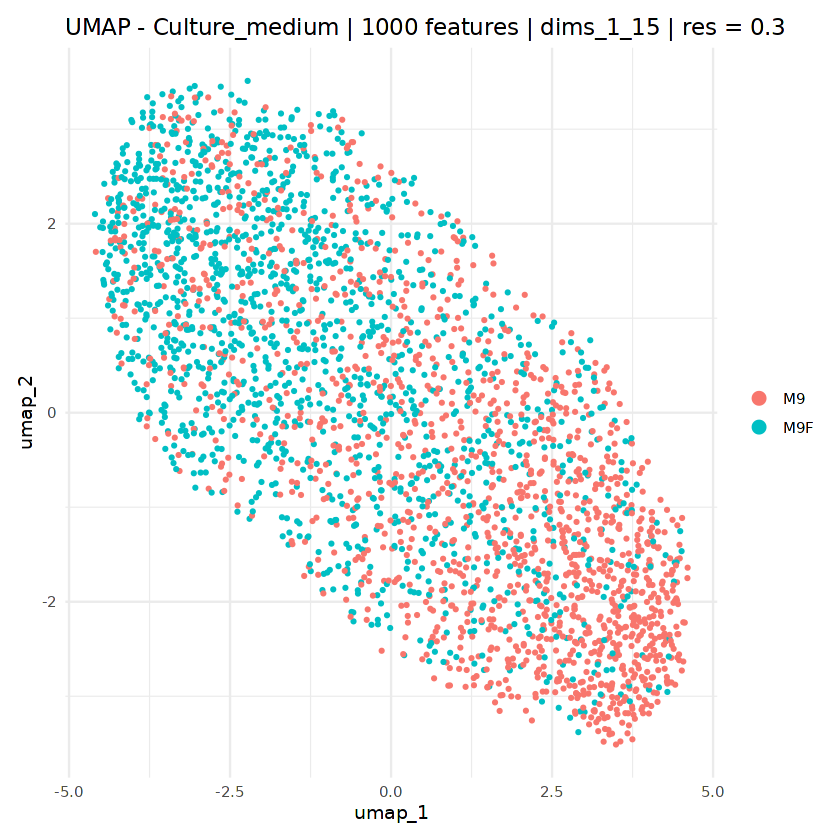

>> nfeatures: 1000 | dims: dims_1_15 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103298

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6983
Number of communities: 2
Elapsed time: 0 seconds


15:01:09 UMAP embedding parameters a = 0.9922 b = 1.112

15:01:09 Read 2934 rows and found 15 numeric columns

15:01:09 Using Annoy for neighbor search, n_neighbors = 30

15:01:09 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:01:10 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002042c8cc37

15:01:10 Searching Annoy index using 1 thread, search_k = 3000

15:01:11 Annoy recall = 100%

15:01:12 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:01:15 Initializing from normalized Laplacian + noise (using RSpectra)

15:01:15 Commencing optimization for 500 epochs, with 117716 positive edges

15:01:15 Using rng type: pcg

15:01:18 Optimization finished



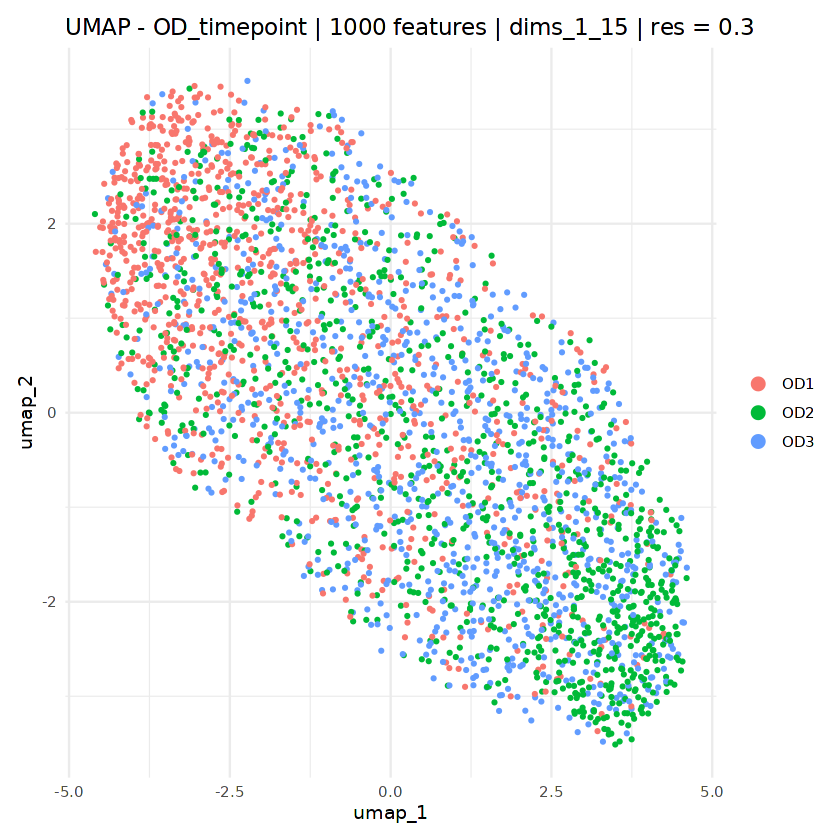

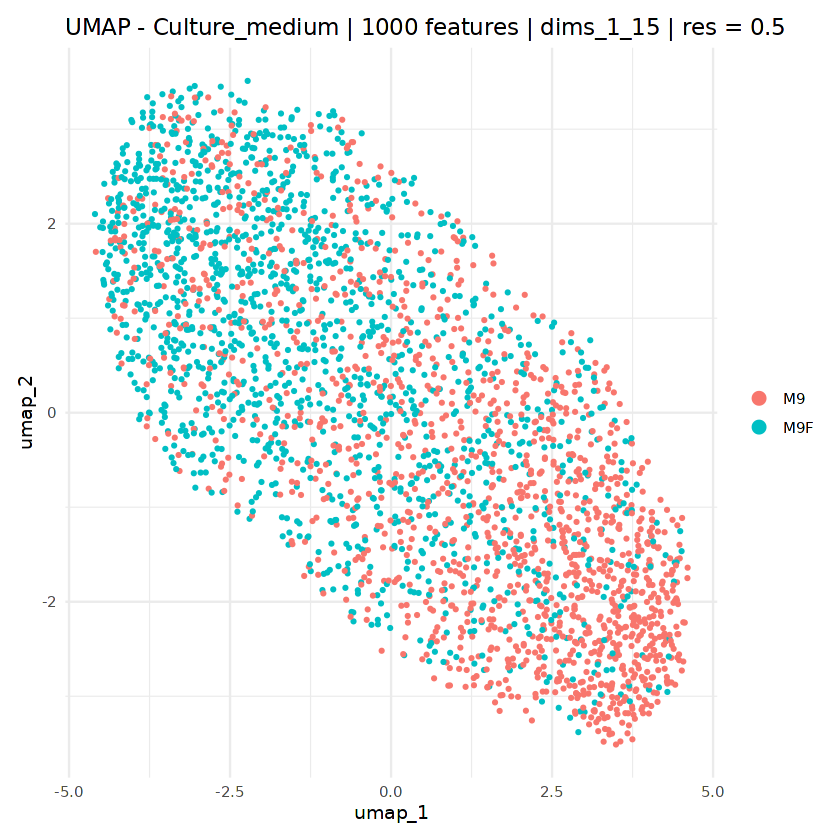

>> nfeatures: 1000 | dims: dims_1_15 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103298

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5905
Number of communities: 3
Elapsed time: 0 seconds


15:01:22 UMAP embedding parameters a = 0.9922 b = 1.112

15:01:22 Read 2934 rows and found 15 numeric columns

15:01:22 Using Annoy for neighbor search, n_neighbors = 30

15:01:22 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:01:23 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020543ca87e

15:01:23 Searching Annoy index using 1 thread, search_k = 3000

15:01:24 Annoy recall = 100%

15:01:25 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:01:26 Initializing from normalized Laplacian + noise (using RSpectra)

15:01:26 Commencing optimization for 500 epochs, with 117716 positive edges

15:01:26 Using rng type: pcg

15:01:29 Optimization finished



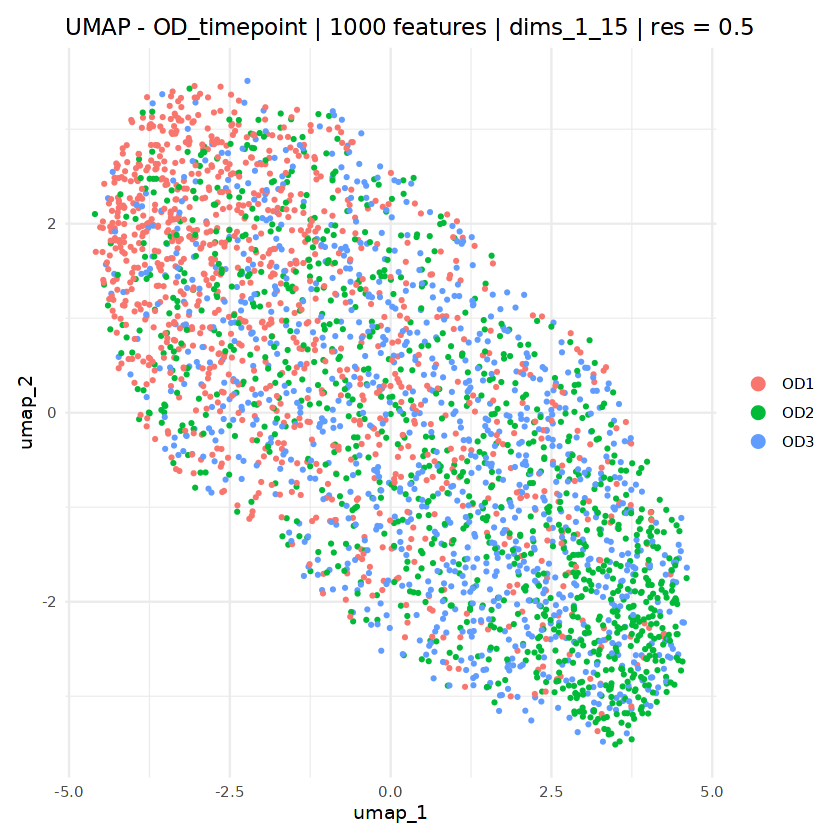

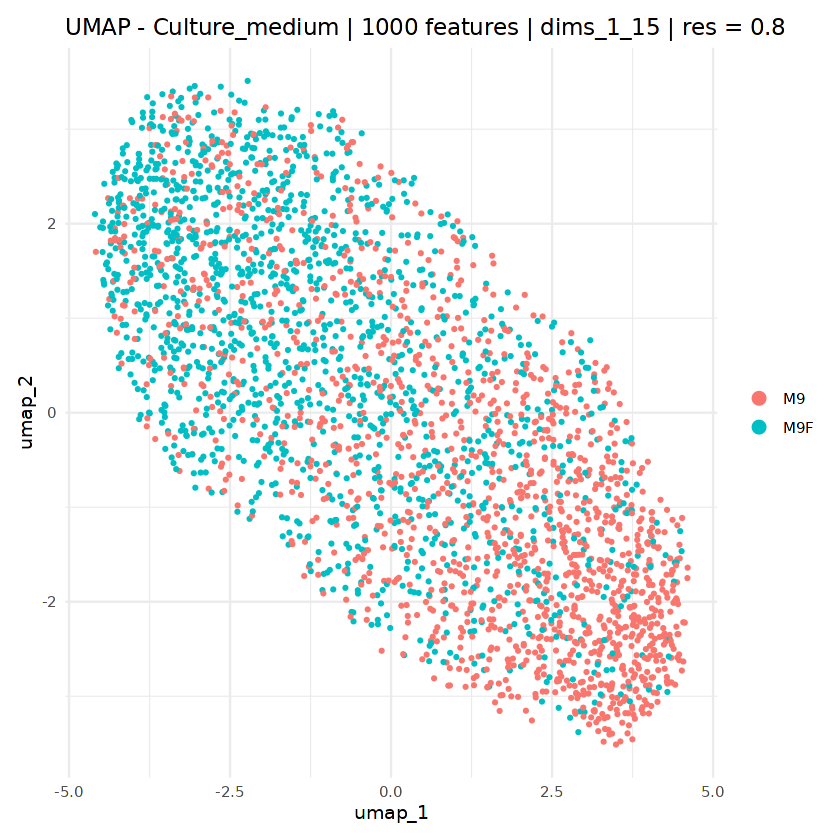

>> nfeatures: 1000 | dims: dims_1_15 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103298

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5292
Number of communities: 4
Elapsed time: 0 seconds


15:01:34 UMAP embedding parameters a = 0.9922 b = 1.112

15:01:34 Read 2934 rows and found 15 numeric columns

15:01:34 Using Annoy for neighbor search, n_neighbors = 30

15:01:34 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:01:35 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002078ff7ba4

15:01:35 Searching Annoy index using 1 thread, search_k = 3000

15:01:36 Annoy recall = 100%

15:01:37 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:01:38 Initializing from normalized Laplacian + noise (using RSpectra)

15:01:38 Commencing optimization for 500 epochs, with 117716 positive edges

15:01:38 Using rng type: pcg

15:01:41 Optimization finished



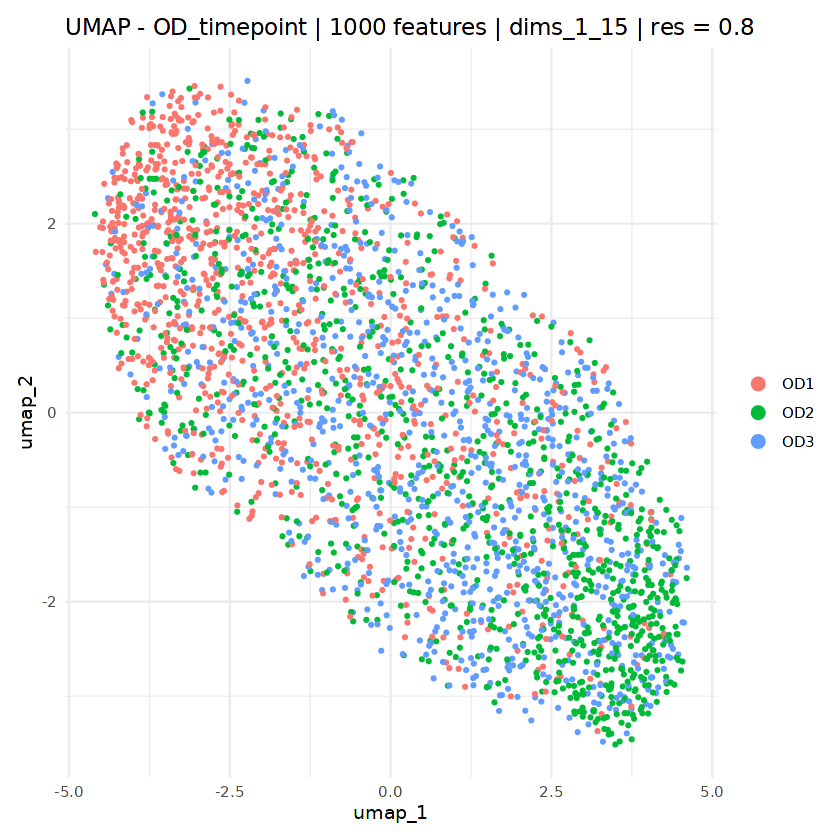

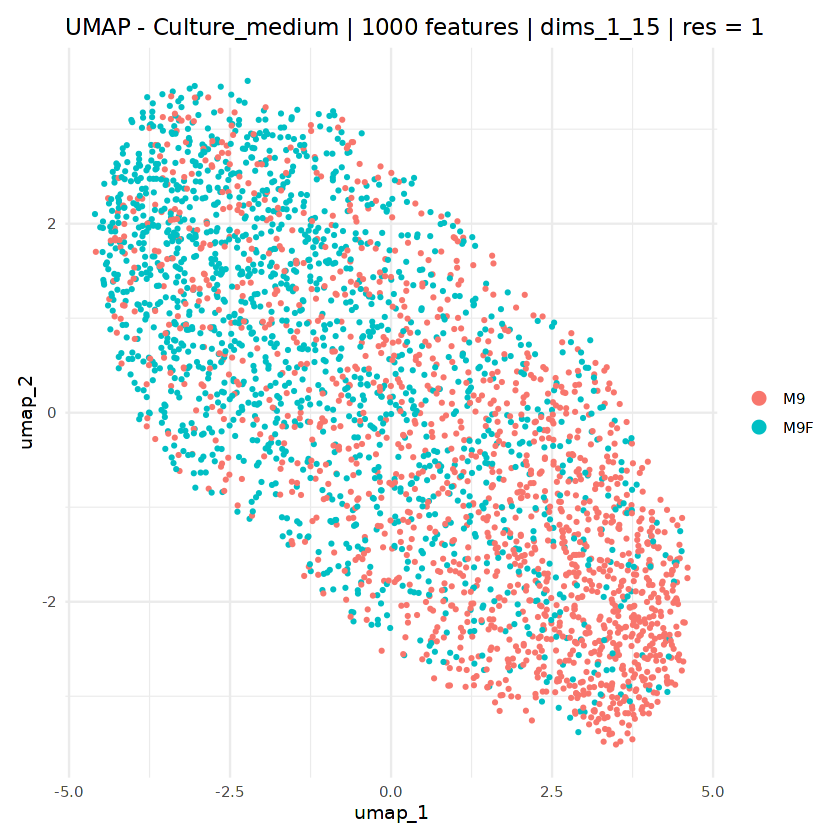

==== nfeatures = 1500 ====

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  QLH64-19225, QLH64-02935, fusA, QLH64-23140, QLH64-00420, QLH64-05400, QLH64-26960, icd, rpoC, QLH64-12125 
	   QLH64-09610, gap, QLH64-13720, QLH64-13705, infC, QLH64-22540, acnB, QLH64-07480, QLH64-12435, QLH64-13710 
	   QLH64-27060, QLH64-00845, infB, ppsA, QLH64-30060, ftsZ, gltA, rpsB, QLH64-00430, QLH64-13730 
Negative:  QLH64-24105, QLH64-02630, gluQRS, QLH64-01365, QLH64-05945, QLH64-12900, choX_1, QLH64-20285, QLH64-30160, QLH64-03320 
	   QLH64-07875, QLH64-29715, QLH64-14500, QLH64-11285, QLH64-15845, QLH64-01295, QLH64-06820, QLH64-08660, QLH64-27515, QLH64-26395 
	   QLH64-24590, QLH64-10750, QLH64-20500, QLH64-09150, gbcA, QLH64-10570, QLH64-12340, QLH64-28180, QLH64-29555, truA 
PC_ 2 
Positive:  hemN_1, QLH64-13690, QLH64-22455, fur, hisF, QLH64-10420, minC, treS, recF, QLH64-03730 
	   phoU, QLH64-05660, QLH64-07335, rbfA, hflC, QLH64-05465, hsl

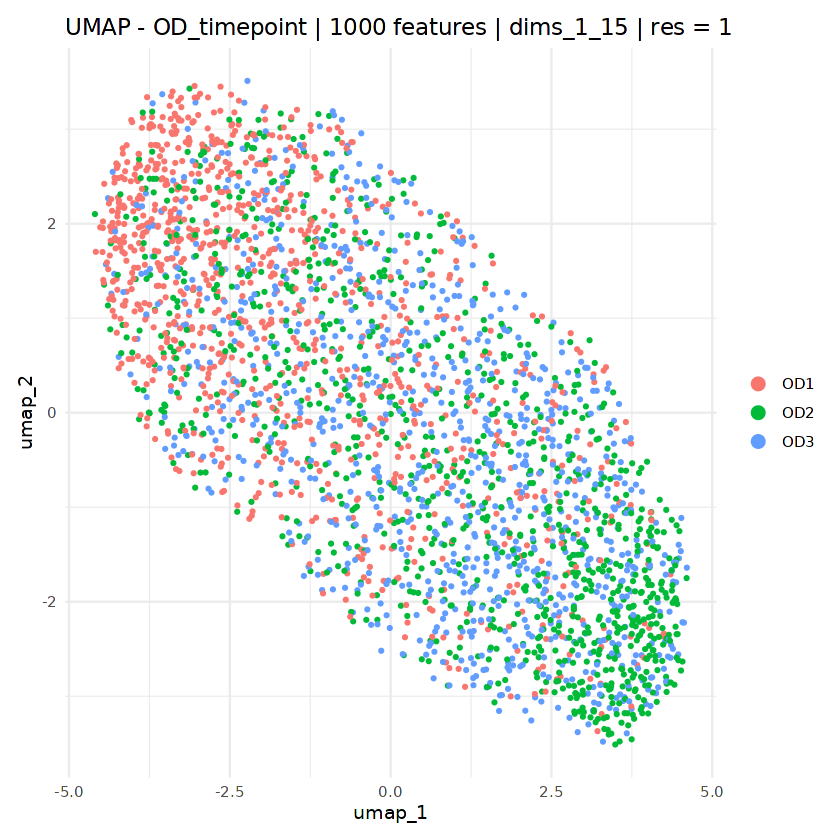

Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


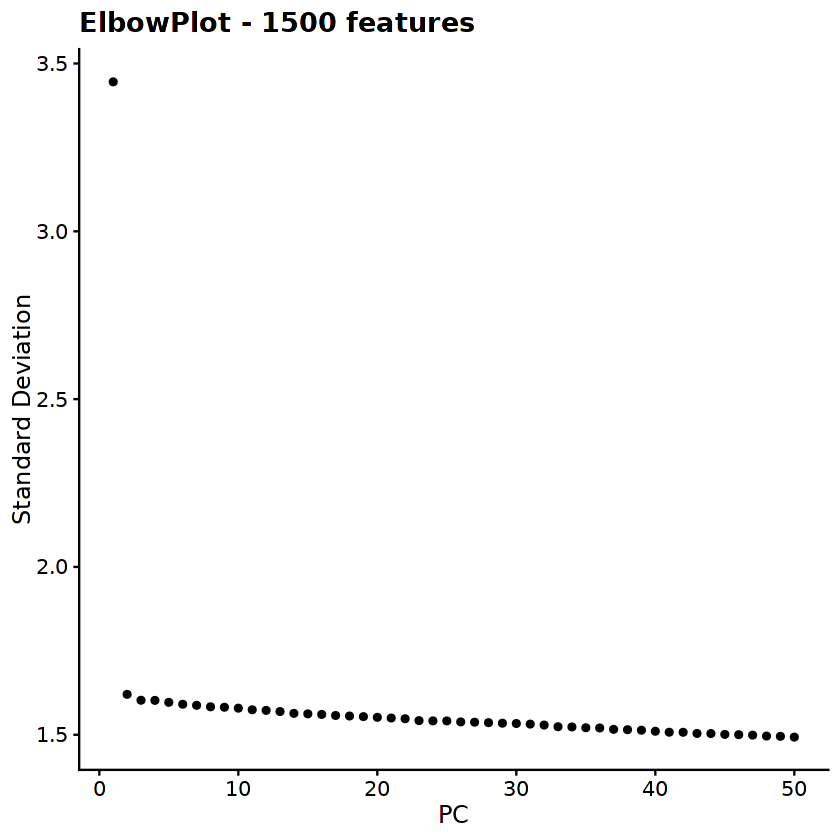

NULL


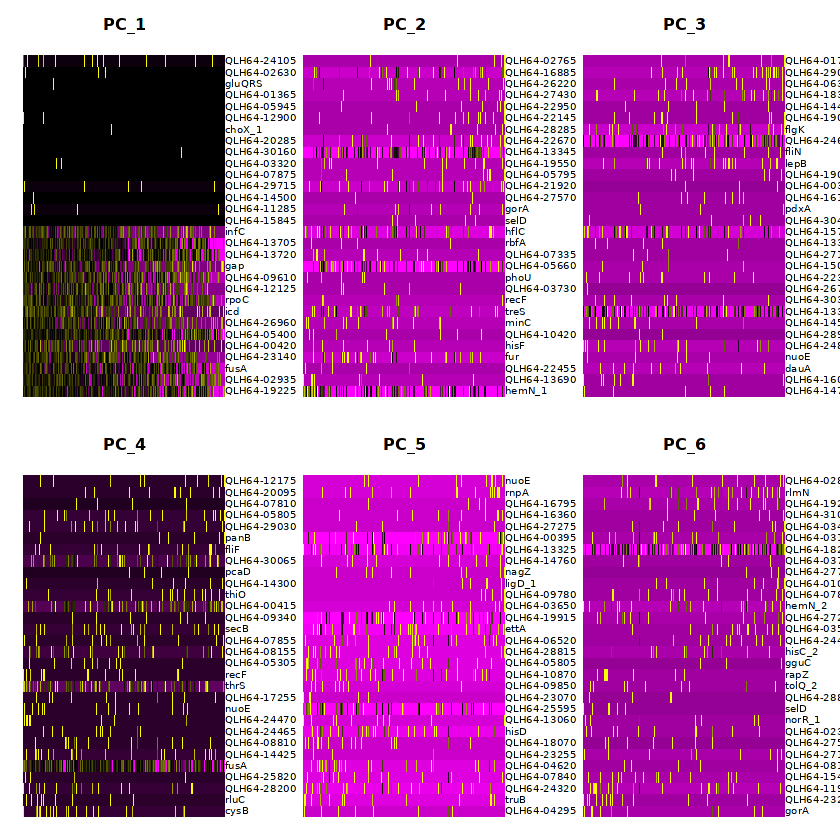

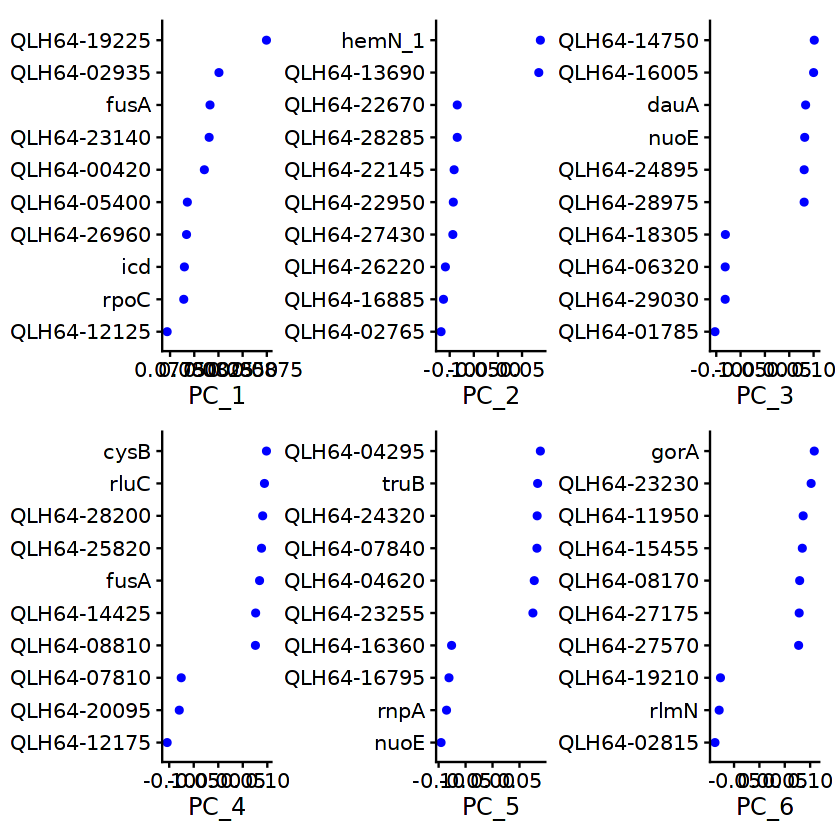

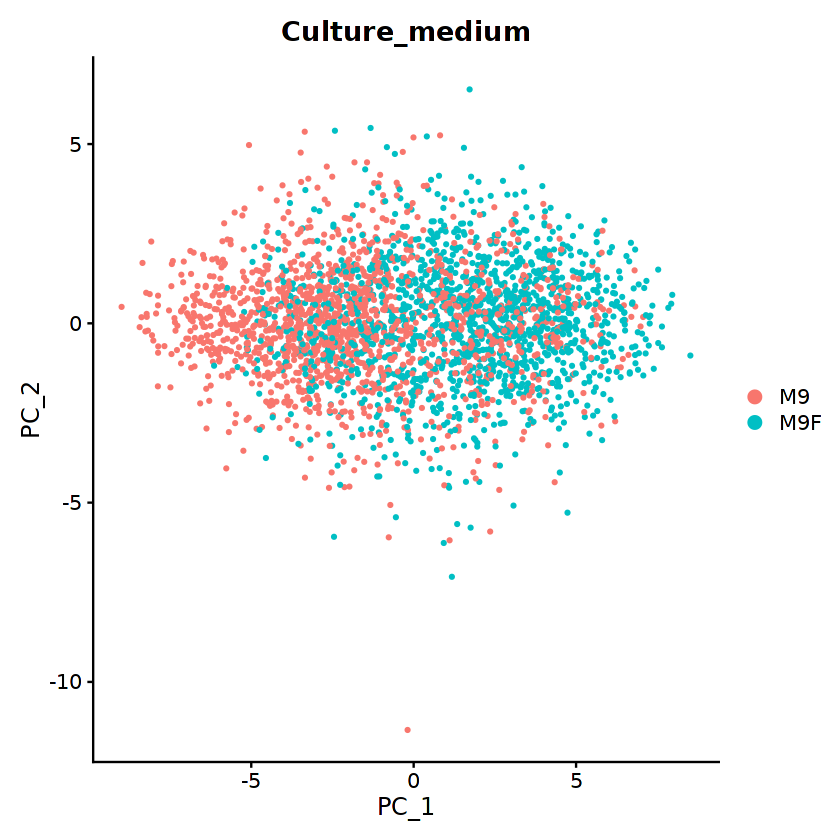

>> nfeatures: 1500 | dims: dims_1_5 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 85817

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8085
Number of communities: 2
Elapsed time: 0 seconds


15:02:00 UMAP embedding parameters a = 0.9922 b = 1.112

15:02:00 Read 2934 rows and found 5 numeric columns

15:02:00 Using Annoy for neighbor search, n_neighbors = 30

15:02:00 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:02:02 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020674ab40b

15:02:02 Searching Annoy index using 1 thread, search_k = 3000

15:02:03 Annoy recall = 100%

15:02:06 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:02:09 Initializing from normalized Laplacian + noise (using RSpectra)

15:02:09 Commencing optimization for 500 epochs, with 106876 positive edges

15:02:09 Using rng type: pcg

15:02:12 Optimization finished



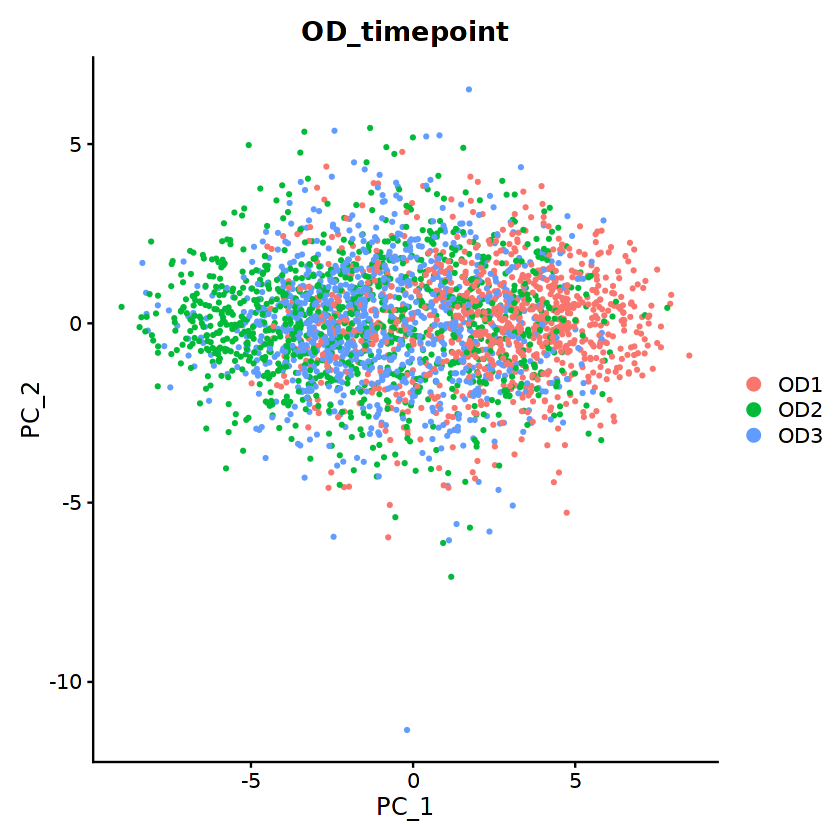

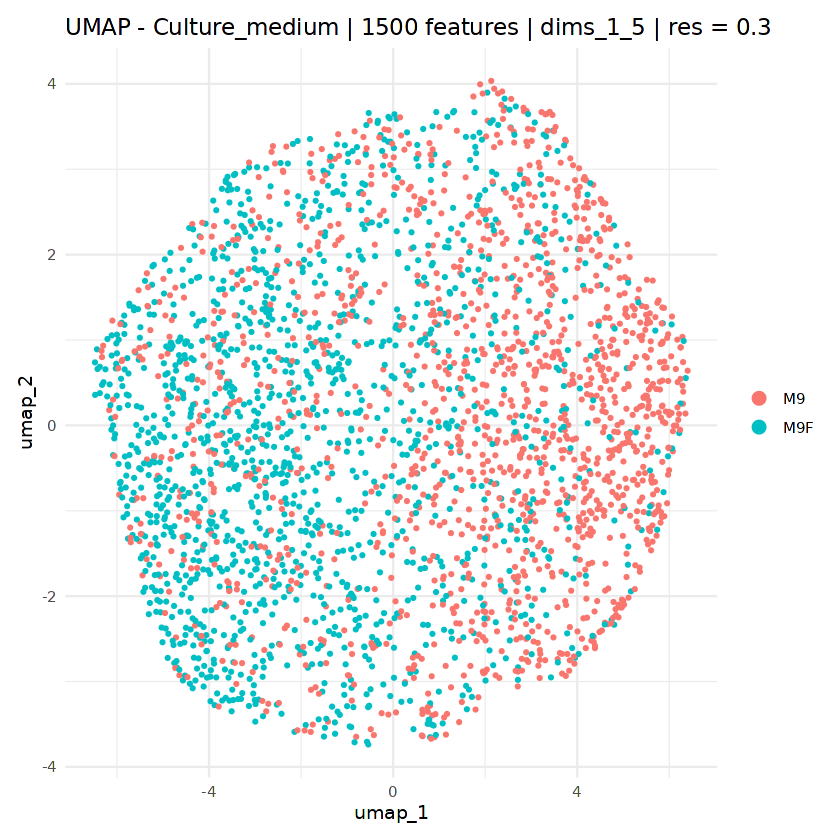

>> nfeatures: 1500 | dims: dims_1_5 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 85817

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7412
Number of communities: 4
Elapsed time: 0 seconds


15:02:15 UMAP embedding parameters a = 0.9922 b = 1.112

15:02:15 Read 2934 rows and found 5 numeric columns

15:02:15 Using Annoy for neighbor search, n_neighbors = 30

15:02:16 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:02:17 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020720fb183

15:02:17 Searching Annoy index using 1 thread, search_k = 3000

15:02:18 Annoy recall = 100%

15:02:19 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:02:21 Initializing from normalized Laplacian + noise (using RSpectra)

15:02:21 Commencing optimization for 500 epochs, with 106876 positive edges

15:02:21 Using rng type: pcg

15:02:24 Optimization finished



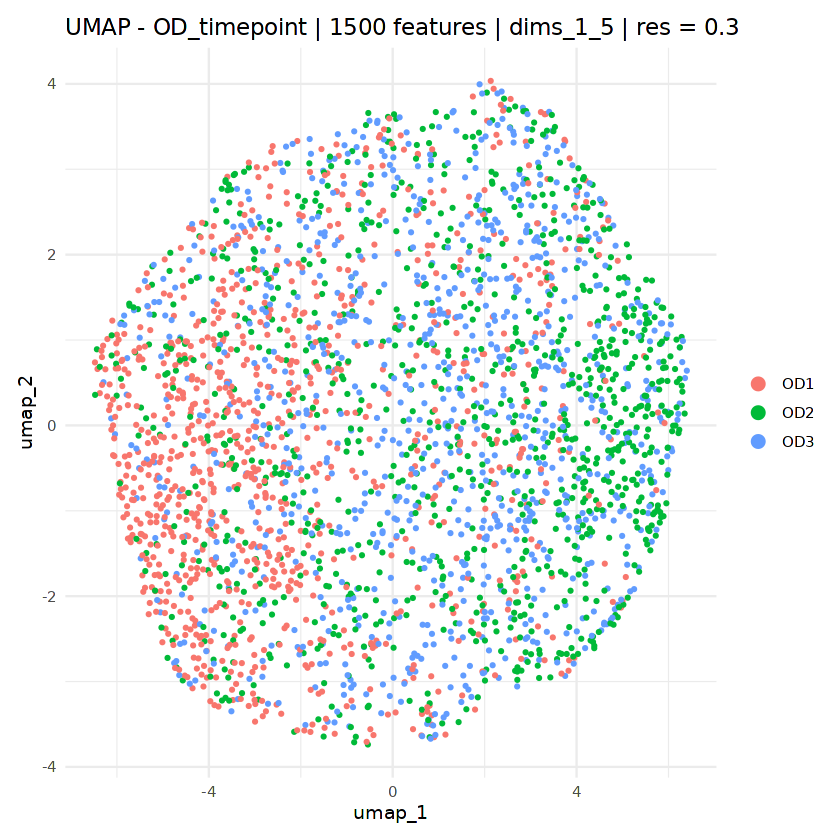

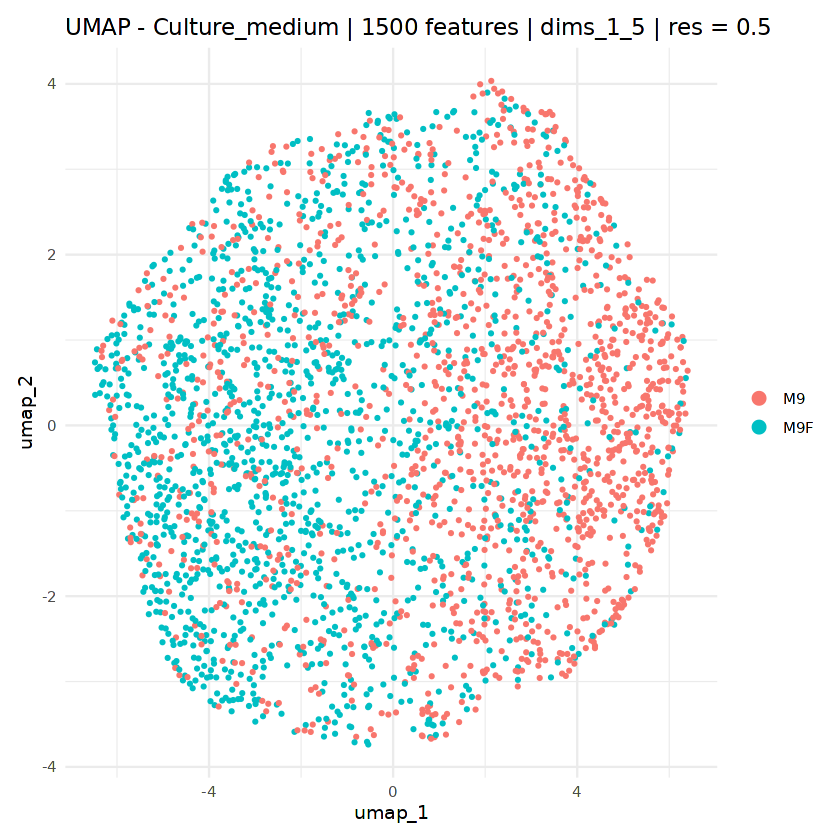

>> nfeatures: 1500 | dims: dims_1_5 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 85817

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6904
Number of communities: 9
Elapsed time: 0 seconds


15:02:27 UMAP embedding parameters a = 0.9922 b = 1.112

15:02:27 Read 2934 rows and found 5 numeric columns

15:02:27 Using Annoy for neighbor search, n_neighbors = 30

15:02:27 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:02:29 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002025f30dbc

15:02:29 Searching Annoy index using 1 thread, search_k = 3000

15:02:30 Annoy recall = 100%

15:02:31 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:02:33 Initializing from normalized Laplacian + noise (using RSpectra)

15:02:33 Commencing optimization for 500 epochs, with 106876 positive edges

15:02:33 Using rng type: pcg

15:02:36 Optimization finished



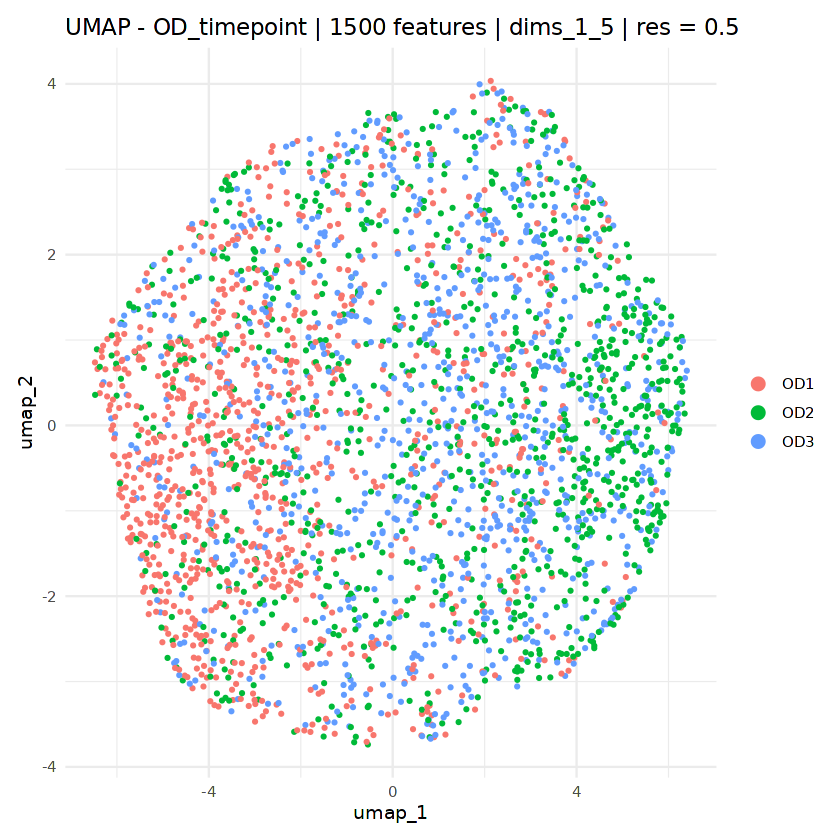

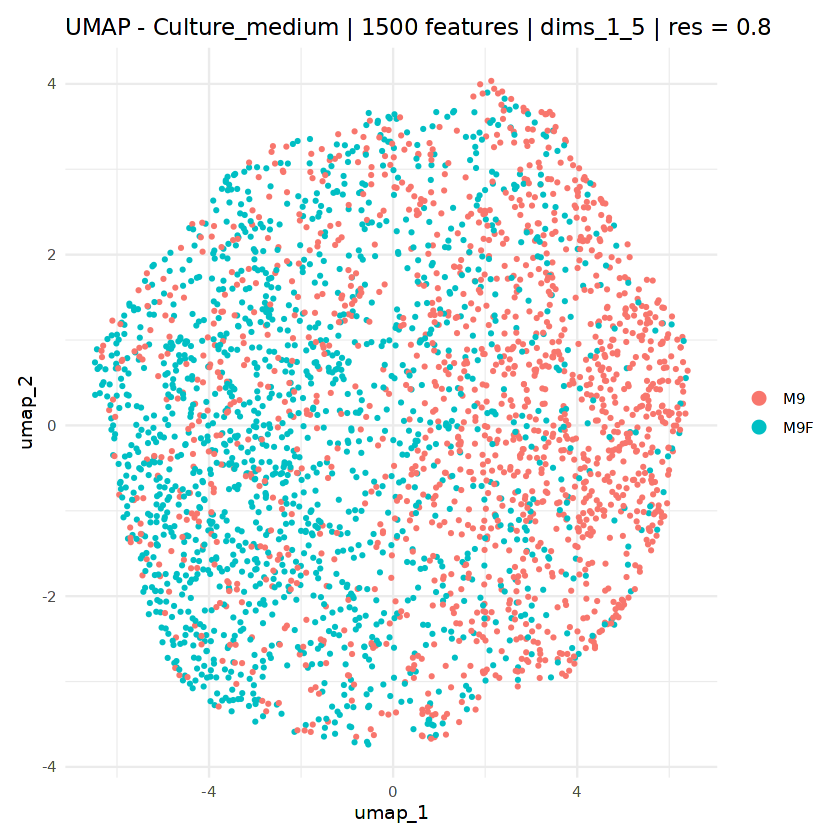

>> nfeatures: 1500 | dims: dims_1_5 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 85817

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6671
Number of communities: 11
Elapsed time: 0 seconds


15:02:40 UMAP embedding parameters a = 0.9922 b = 1.112

15:02:40 Read 2934 rows and found 5 numeric columns

15:02:40 Using Annoy for neighbor search, n_neighbors = 30

15:02:40 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:02:42 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100202932a219

15:02:42 Searching Annoy index using 1 thread, search_k = 3000

15:02:43 Annoy recall = 100%

15:02:45 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:02:46 Initializing from normalized Laplacian + noise (using RSpectra)

15:02:46 Commencing optimization for 500 epochs, with 106876 positive edges

15:02:46 Using rng type: pcg

15:02:49 Optimization finished



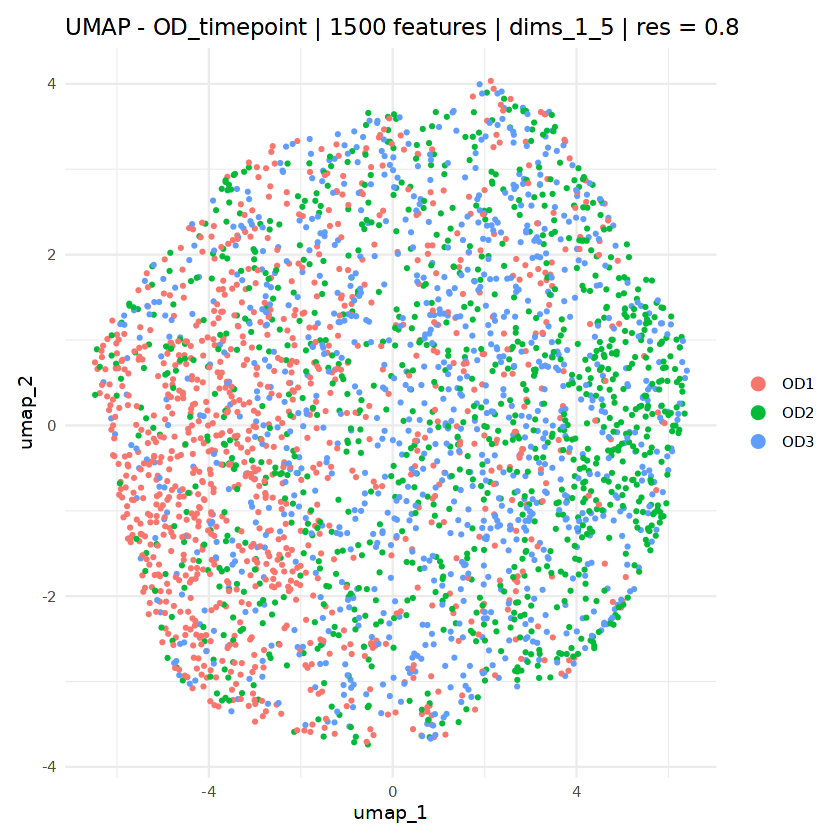

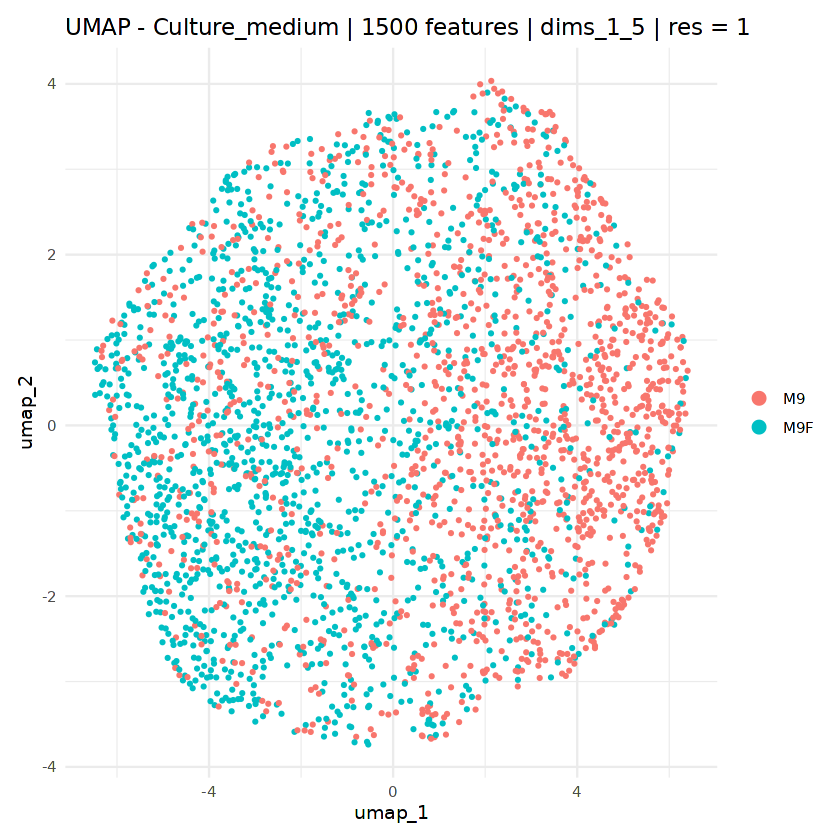

>> nfeatures: 1500 | dims: dims_1_10 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 95123

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8057
Number of communities: 2
Elapsed time: 0 seconds


15:02:53 UMAP embedding parameters a = 0.9922 b = 1.112

15:02:53 Read 2934 rows and found 10 numeric columns

15:02:53 Using Annoy for neighbor search, n_neighbors = 30

15:02:53 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:02:55 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020739fa66e

15:02:55 Searching Annoy index using 1 thread, search_k = 3000

15:02:55 Annoy recall = 100%

15:02:57 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:02:58 Initializing from normalized Laplacian + noise (using RSpectra)

15:02:58 Commencing optimization for 500 epochs, with 119480 positive edges

15:02:58 Using rng type: pcg

15:03:02 Optimization finished



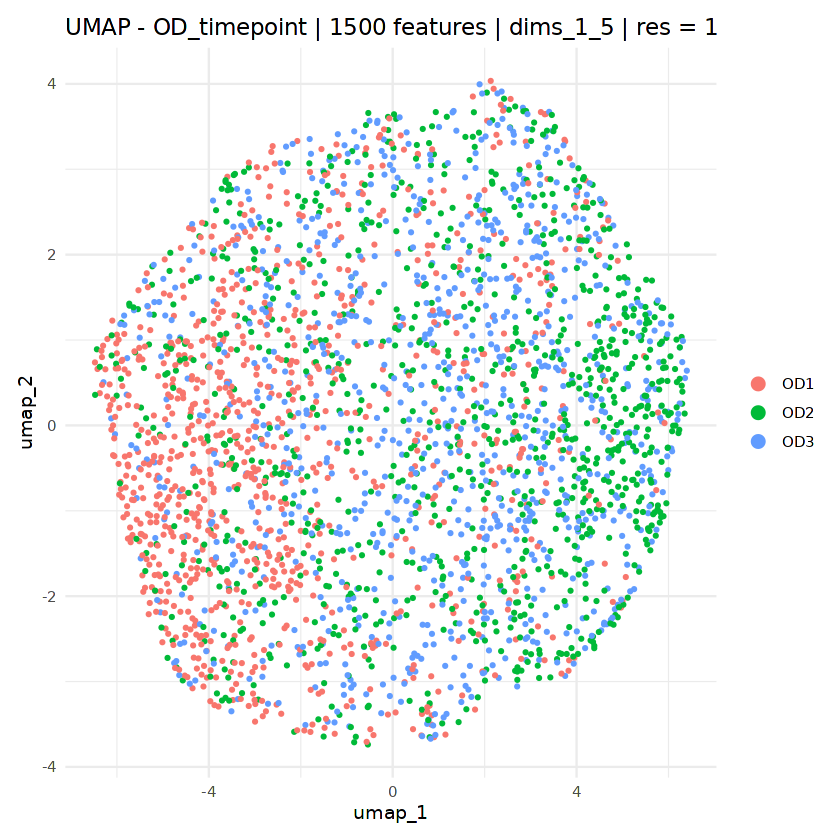

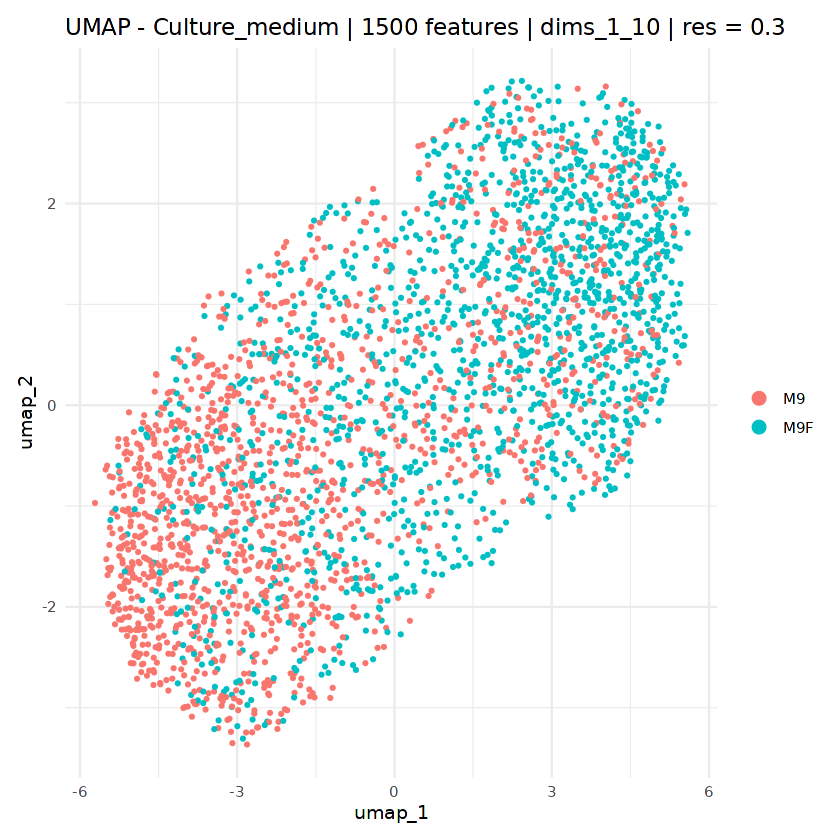

>> nfeatures: 1500 | dims: dims_1_10 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 95123

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7124
Number of communities: 3
Elapsed time: 0 seconds


15:03:06 UMAP embedding parameters a = 0.9922 b = 1.112

15:03:06 Read 2934 rows and found 10 numeric columns

15:03:06 Using Annoy for neighbor search, n_neighbors = 30

15:03:06 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:03:08 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002028b8585b

15:03:08 Searching Annoy index using 1 thread, search_k = 3000

15:03:08 Annoy recall = 100%

15:03:10 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:03:11 Initializing from normalized Laplacian + noise (using RSpectra)

15:03:11 Commencing optimization for 500 epochs, with 119480 positive edges

15:03:11 Using rng type: pcg

15:03:15 Optimization finished



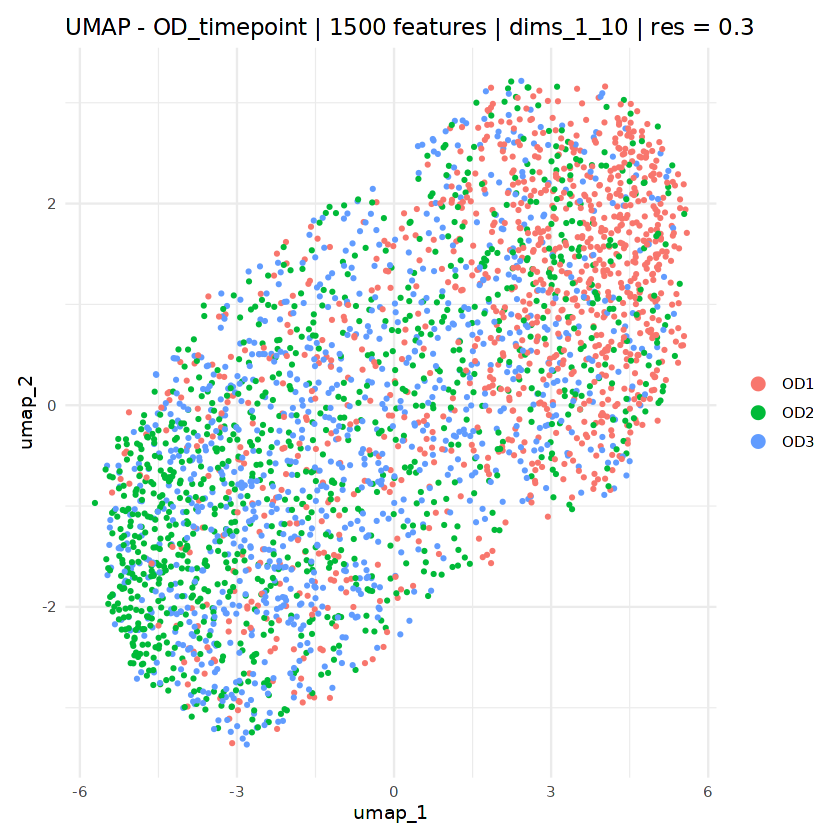

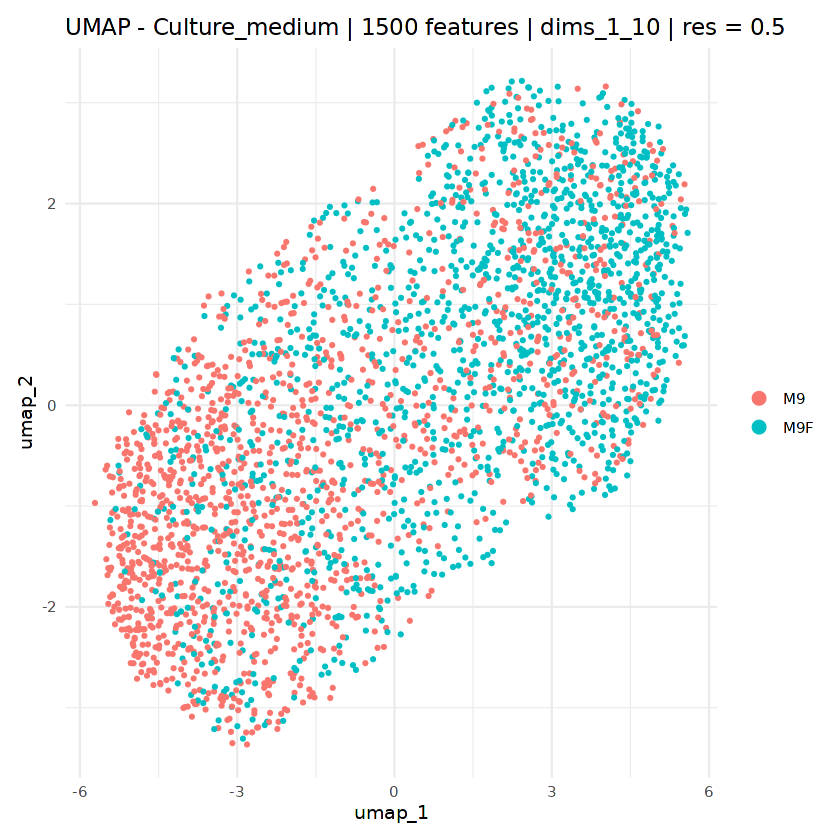

>> nfeatures: 1500 | dims: dims_1_10 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 95123

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6216
Number of communities: 4
Elapsed time: 0 seconds


15:03:19 UMAP embedding parameters a = 0.9922 b = 1.112

15:03:20 Read 2934 rows and found 10 numeric columns

15:03:20 Using Annoy for neighbor search, n_neighbors = 30

15:03:20 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:03:21 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100202ada981c

15:03:21 Searching Annoy index using 1 thread, search_k = 3000

15:03:21 Annoy recall = 100%

15:03:23 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:03:24 Initializing from normalized Laplacian + noise (using RSpectra)

15:03:24 Commencing optimization for 500 epochs, with 119480 positive edges

15:03:24 Using rng type: pcg

15:03:27 Optimization finished



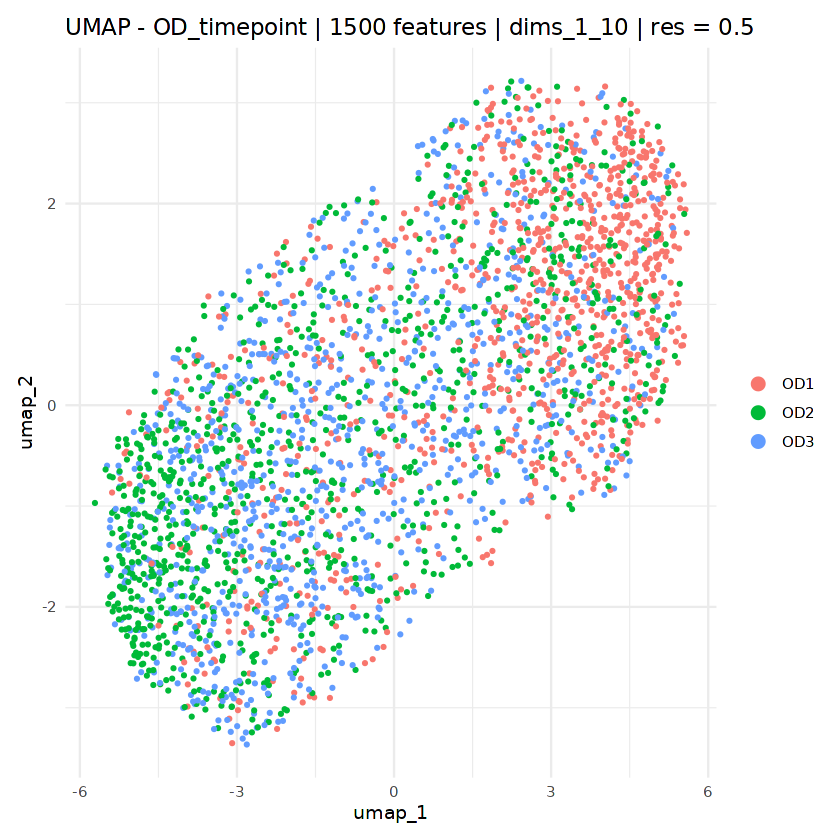

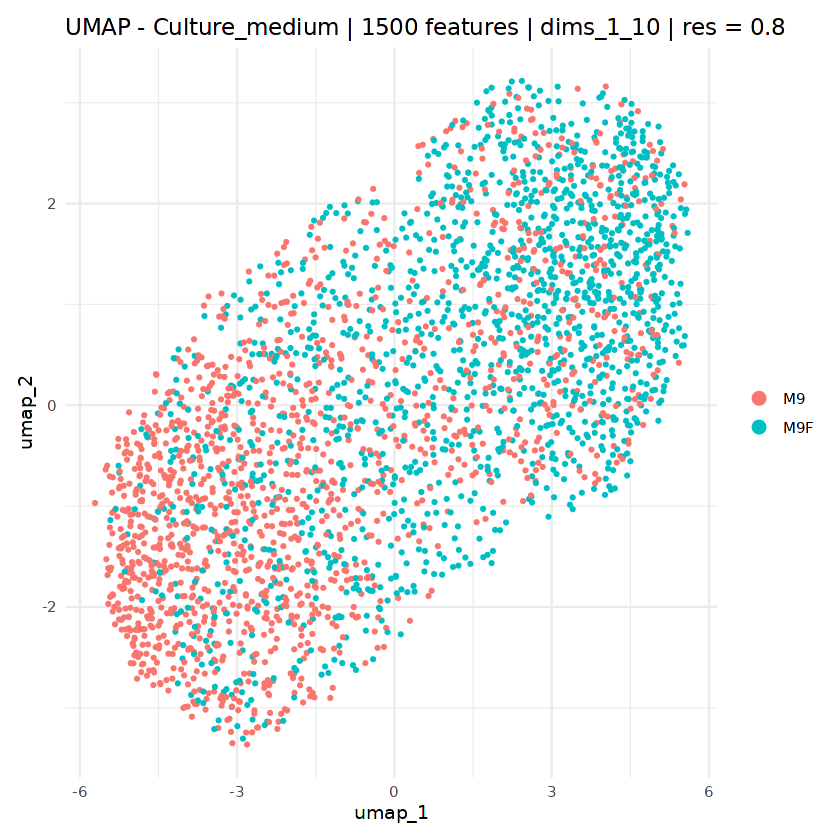

>> nfeatures: 1500 | dims: dims_1_10 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 95123

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5677
Number of communities: 5
Elapsed time: 0 seconds


15:03:31 UMAP embedding parameters a = 0.9922 b = 1.112

15:03:31 Read 2934 rows and found 10 numeric columns

15:03:31 Using Annoy for neighbor search, n_neighbors = 30

15:03:31 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:03:32 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100204500c559

15:03:32 Searching Annoy index using 1 thread, search_k = 3000

15:03:33 Annoy recall = 100%

15:03:34 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:03:36 Initializing from normalized Laplacian + noise (using RSpectra)

15:03:36 Commencing optimization for 500 epochs, with 119480 positive edges

15:03:36 Using rng type: pcg

15:03:39 Optimization finished



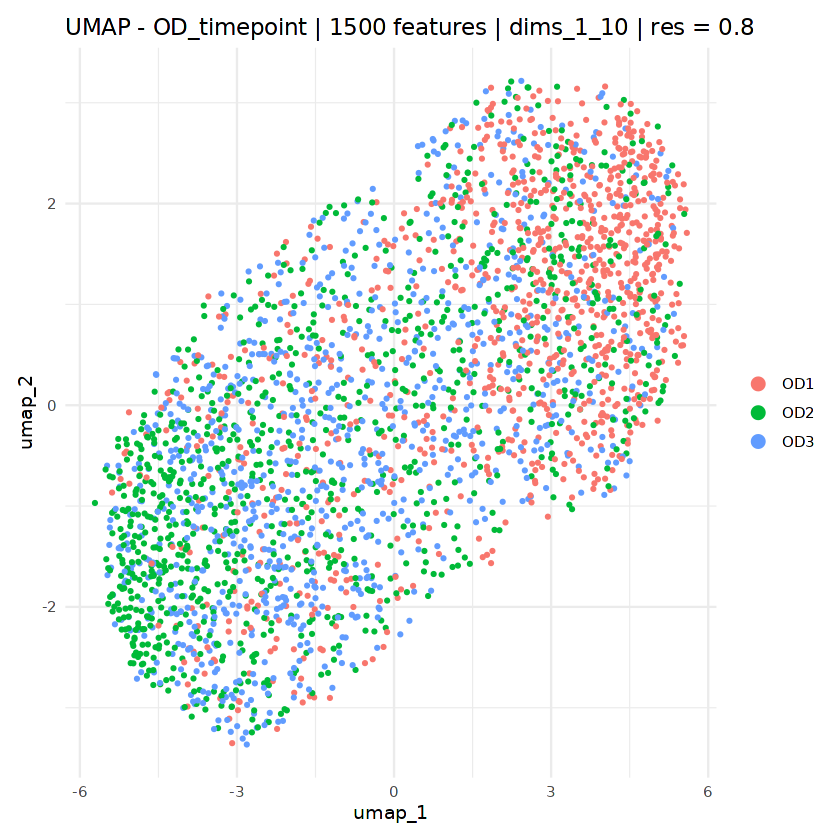

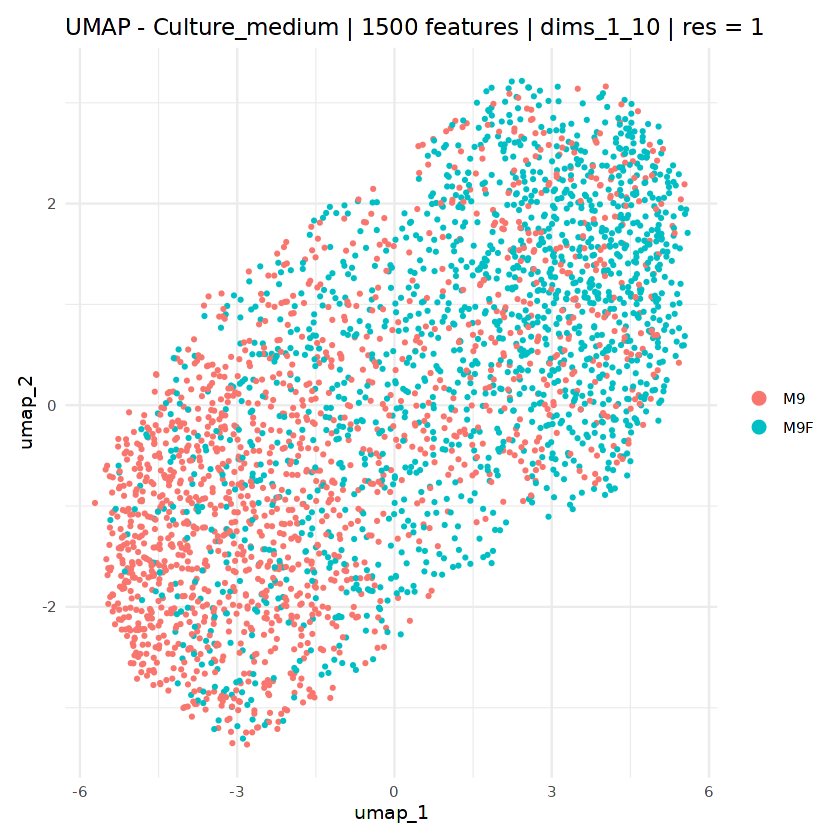

>> nfeatures: 1500 | dims: dims_1_15 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103870

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8203
Number of communities: 2
Elapsed time: 0 seconds


15:03:44 UMAP embedding parameters a = 0.9922 b = 1.112

15:03:44 Read 2934 rows and found 15 numeric columns

15:03:44 Using Annoy for neighbor search, n_neighbors = 30

15:03:44 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:03:45 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020a7b6d99

15:03:45 Searching Annoy index using 1 thread, search_k = 3000

15:03:46 Annoy recall = 100%

15:03:48 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:03:49 Initializing from normalized Laplacian + noise (using RSpectra)

15:03:49 Commencing optimization for 500 epochs, with 124388 positive edges

15:03:49 Using rng type: pcg

15:03:53 Optimization finished



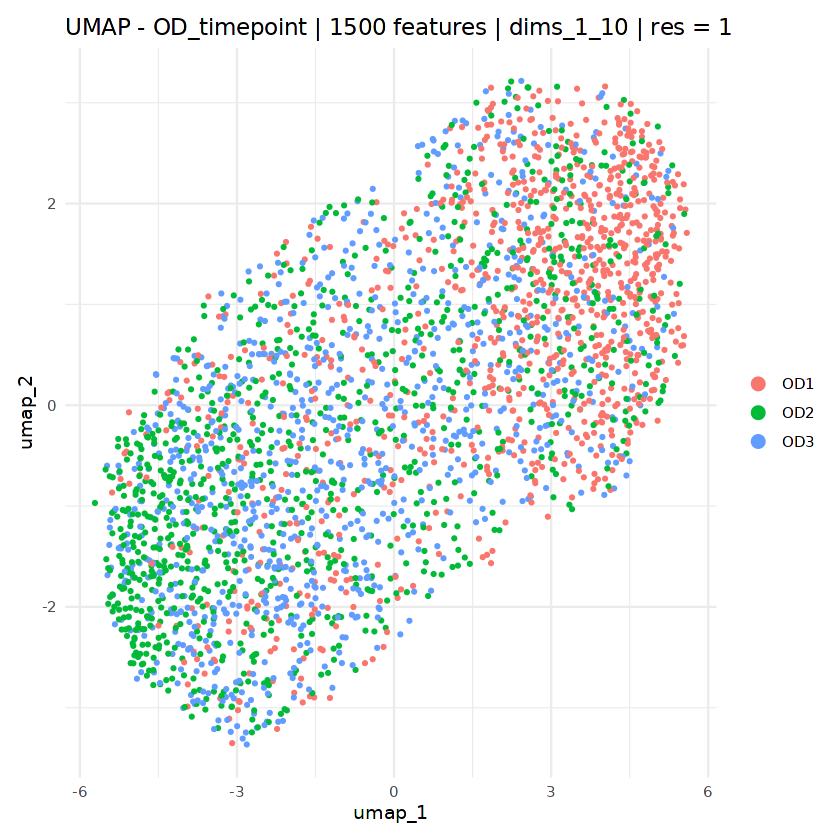

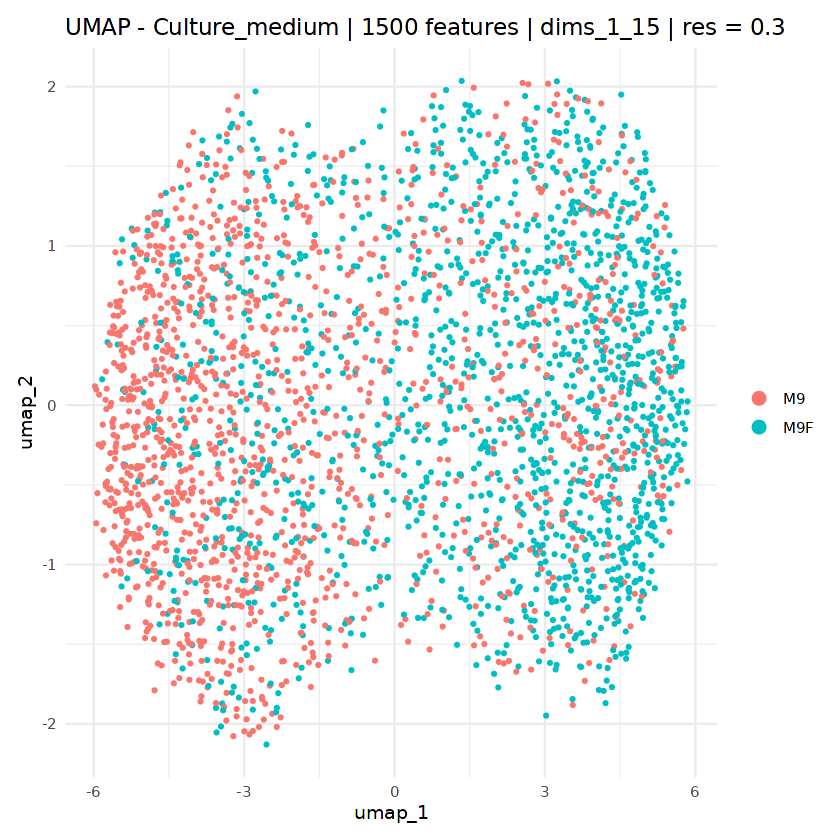

>> nfeatures: 1500 | dims: dims_1_15 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103870

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7236
Number of communities: 3
Elapsed time: 0 seconds


15:03:57 UMAP embedding parameters a = 0.9922 b = 1.112

15:03:57 Read 2934 rows and found 15 numeric columns

15:03:57 Using Annoy for neighbor search, n_neighbors = 30

15:03:57 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:03:59 Writing NN index file to temp file /tmp/RtmpLpoVWr/file10020c8a52c7

15:03:59 Searching Annoy index using 1 thread, search_k = 3000

15:03:59 Annoy recall = 100%

15:04:01 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:04:02 Initializing from normalized Laplacian + noise (using RSpectra)

15:04:03 Commencing optimization for 500 epochs, with 124388 positive edges

15:04:03 Using rng type: pcg

15:04:06 Optimization finished



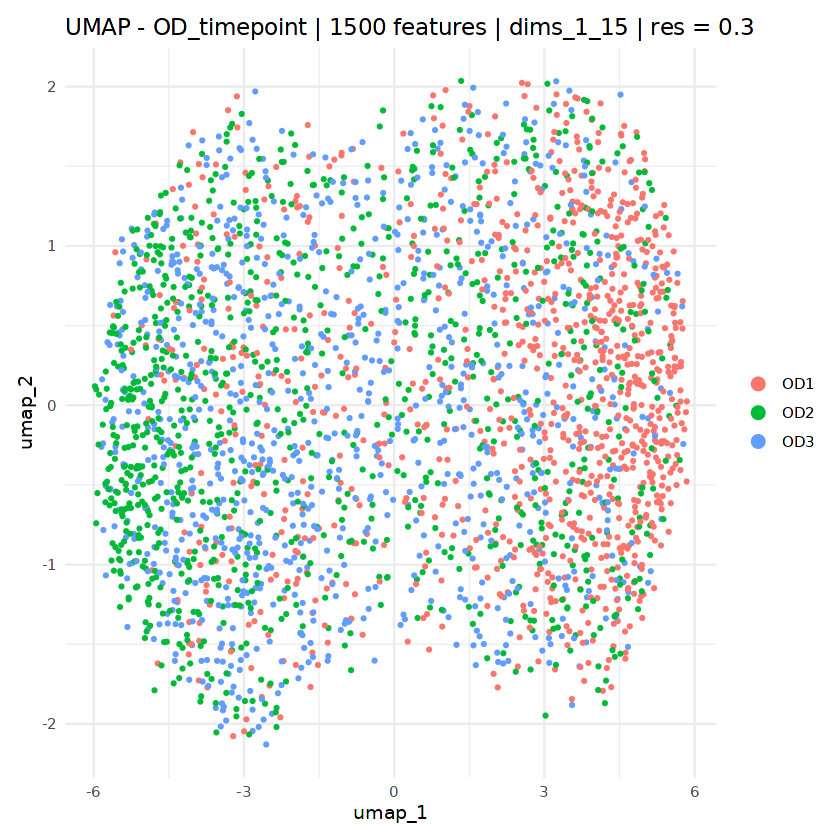

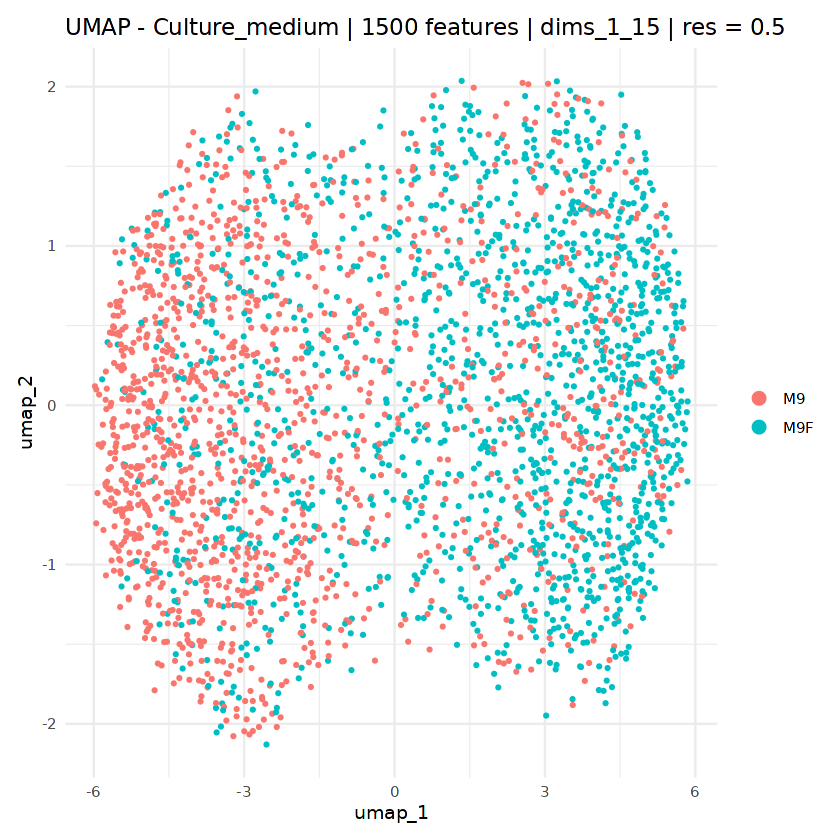

>> nfeatures: 1500 | dims: dims_1_15 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103870

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6301
Number of communities: 4
Elapsed time: 0 seconds


15:04:10 UMAP embedding parameters a = 0.9922 b = 1.112

15:04:10 Read 2934 rows and found 15 numeric columns

15:04:10 Using Annoy for neighbor search, n_neighbors = 30

15:04:10 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:04:11 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002062db499d

15:04:12 Searching Annoy index using 1 thread, search_k = 3000

15:04:12 Annoy recall = 100%

15:04:14 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:04:15 Initializing from normalized Laplacian + noise (using RSpectra)

15:04:15 Commencing optimization for 500 epochs, with 124388 positive edges

15:04:15 Using rng type: pcg

15:04:18 Optimization finished



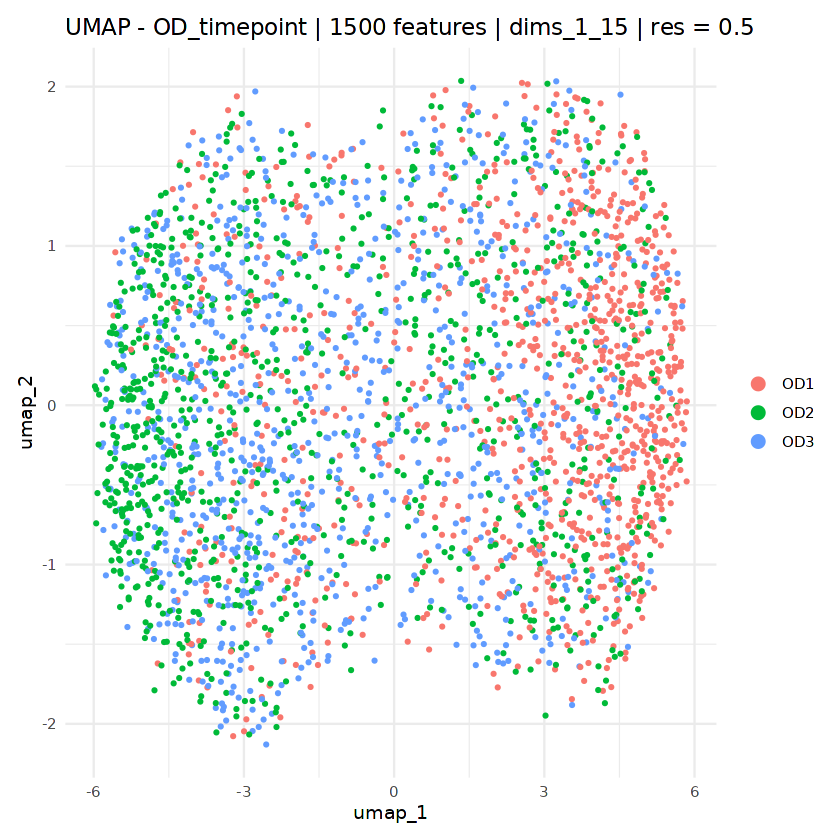

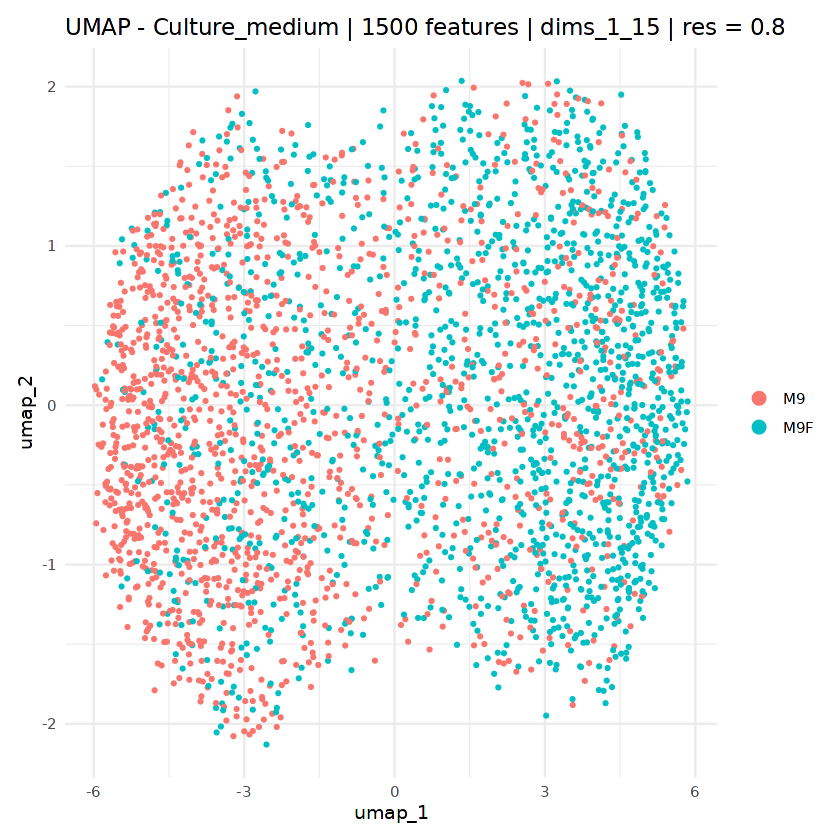

>> nfeatures: 1500 | dims: dims_1_15 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 103870

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5761
Number of communities: 4
Elapsed time: 0 seconds


15:04:23 UMAP embedding parameters a = 0.9922 b = 1.112

15:04:23 Read 2934 rows and found 15 numeric columns

15:04:23 Using Annoy for neighbor search, n_neighbors = 30

15:04:23 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:04:24 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002072439486

15:04:24 Searching Annoy index using 1 thread, search_k = 3000

15:04:25 Annoy recall = 100%

15:04:26 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:04:27 Initializing from normalized Laplacian + noise (using RSpectra)

15:04:28 Commencing optimization for 500 epochs, with 124388 positive edges

15:04:28 Using rng type: pcg

15:04:31 Optimization finished



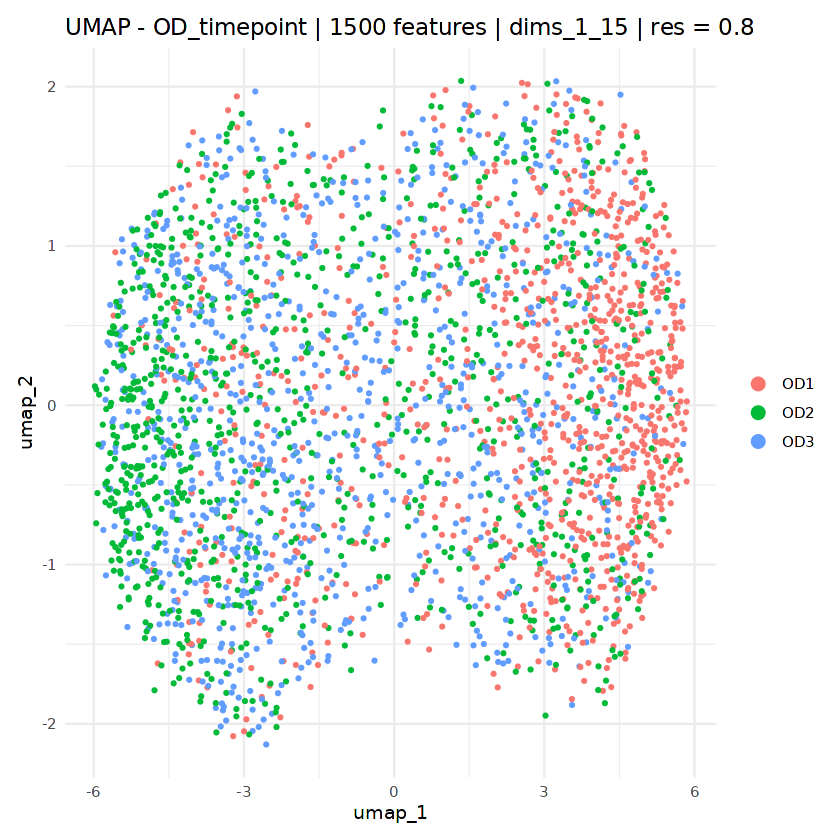

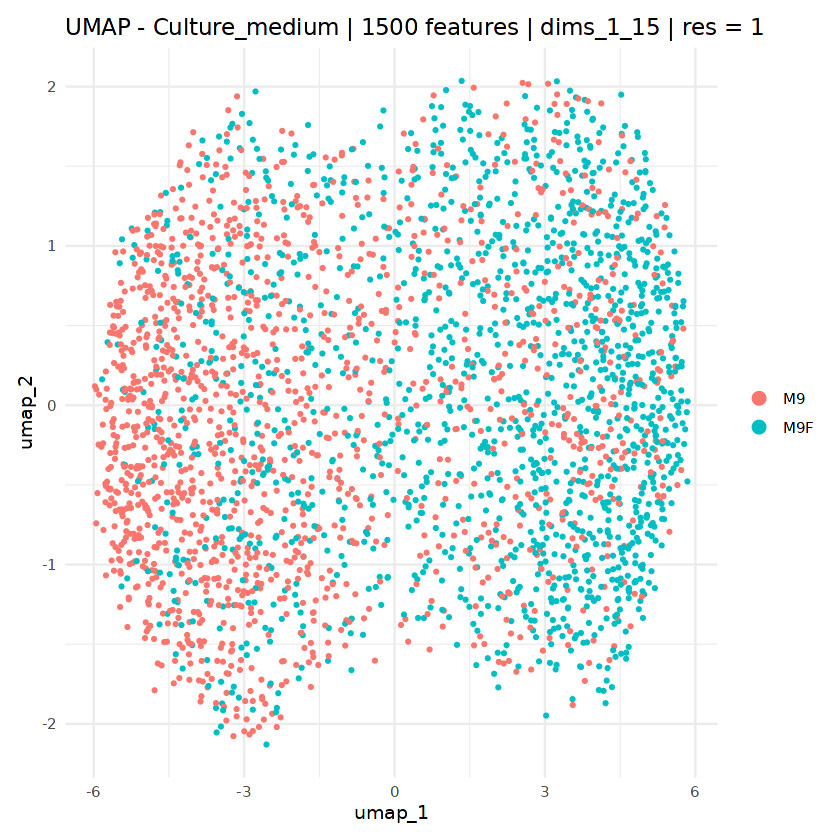

==== nfeatures = 3000 ====

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  QLH64-19225, QLH64-05310, aceE, QLH64-02935, QLH64-00420, atpD, QLH64-23140, fusA, ccoN_2, rpoC 
	   icd, QLH64-26960, QLH64-05400, QLH64-12125, raiA, rplN, QLH64-09610, QLH64-13720, gap, rplB 
	   QLH64-03465, QLH64-07480, QLH64-13705, infC, oprI, acnB, QLH64-22540, QLH64-13710, QLH64-12435, QLH64-27060 
Negative:  QLH64-24105, yacG, QLH64-28305, ccmD, QLH64-02320, QLH64-03265, QLH64-16715, QLH64-18880, QLH64-07650, QLH64-00360 
	   gluQRS, QLH64-06955, QLH64-09535, QLH64-23370, QLH64-15900, QLH64-01365, QLH64-17215, QLH64-17200, QLH64-05945, QLH64-06945 
	   QLH64-22115, QLH64-02630, QLH64-01455, QLH64-07610, QLH64-12875, QLH64-14890, QLH64-14575, QLH64-30225, QLH64-23410, QLH64-08090 
PC_ 2 
Positive:  trpA, QLH64-12175, QLH64-05120, thiO, nadC, ubiG, QLH64-08840, QLH64-30400, QLH64-30385, QLH64-07340 
	   QLH64-13035, hemB_1, QLH64-21000, trxA_2, QLH64-27570,

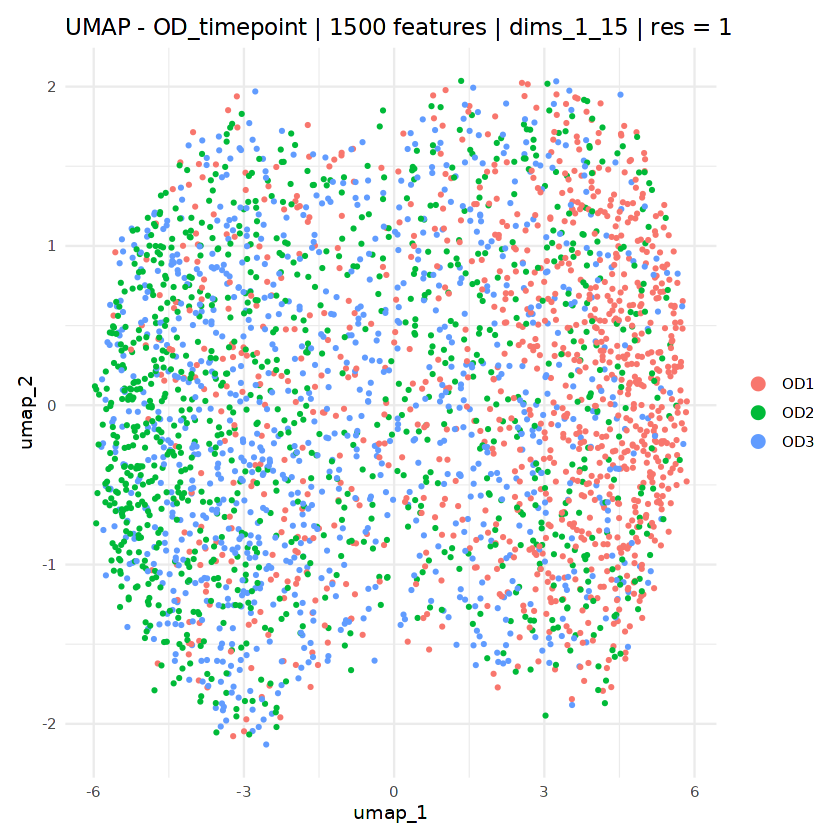

Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."
Warning message:
"Requested number is larger than the number of available items (2934). Setting to 2934."


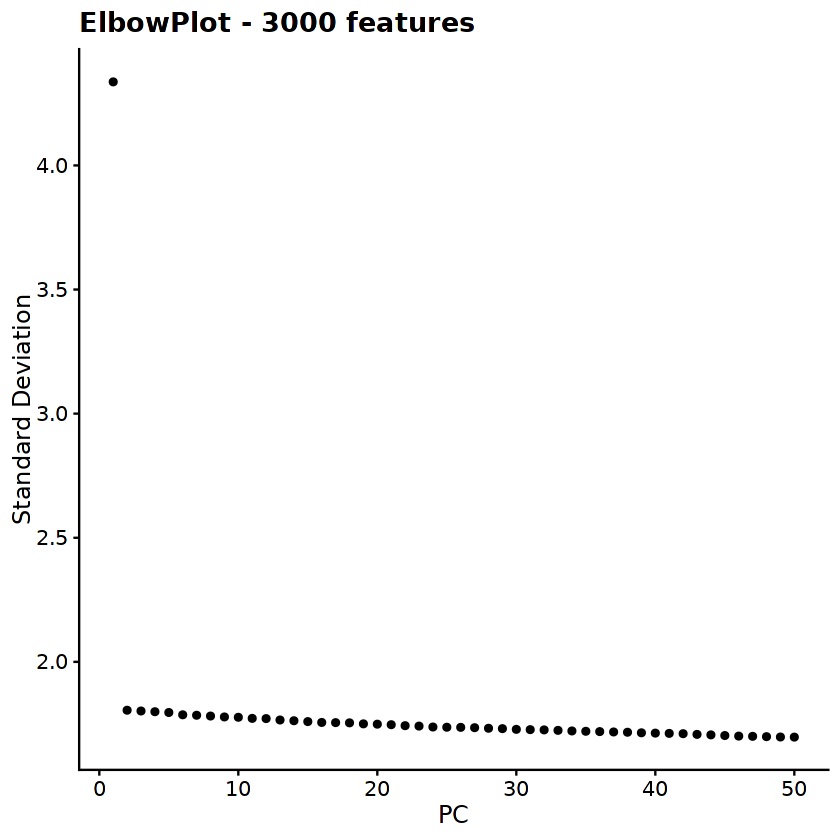

NULL


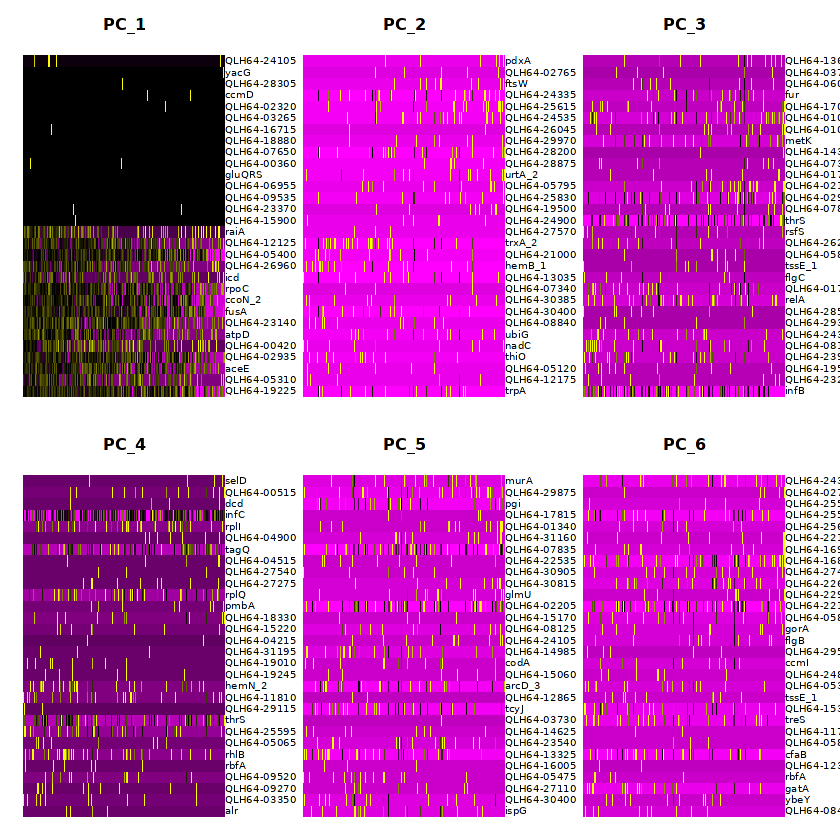

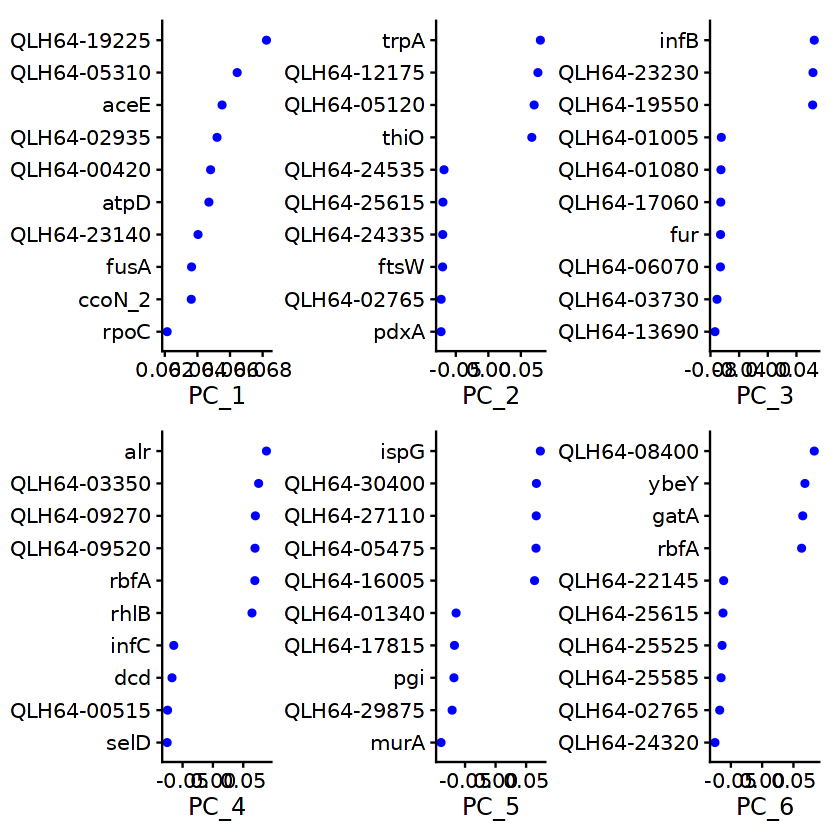

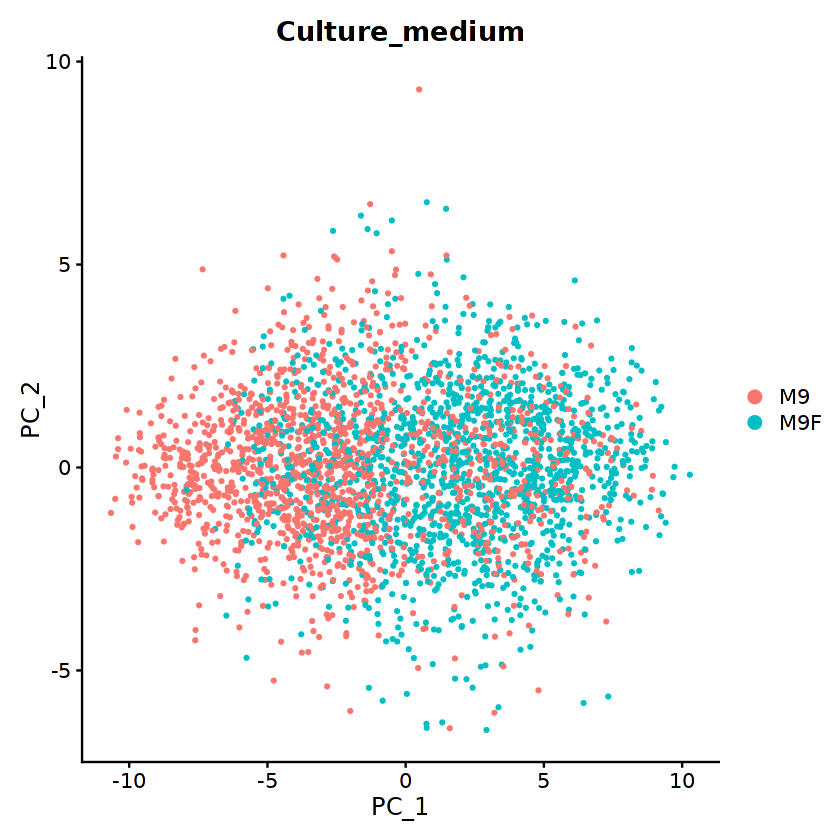

>> nfeatures: 3000 | dims: dims_1_5 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 86212

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8216
Number of communities: 3
Elapsed time: 0 seconds


15:05:05 UMAP embedding parameters a = 0.9922 b = 1.112

15:05:05 Read 2934 rows and found 5 numeric columns

15:05:05 Using Annoy for neighbor search, n_neighbors = 30

15:05:05 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:05:07 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002059d2e09e

15:05:07 Searching Annoy index using 1 thread, search_k = 3000

15:05:09 Annoy recall = 100%

15:05:14 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:05:38 Initializing from normalized Laplacian + noise (using RSpectra)

15:05:39 Commencing optimization for 500 epochs, with 108714 positive edges

15:05:39 Using rng type: pcg

15:05:44 Optimization finished



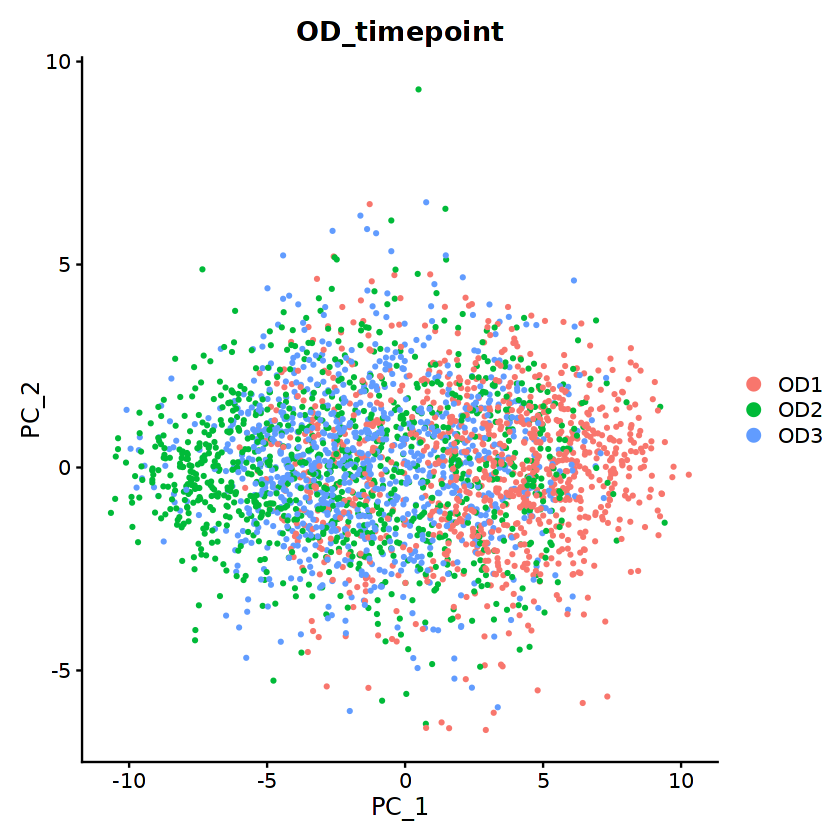

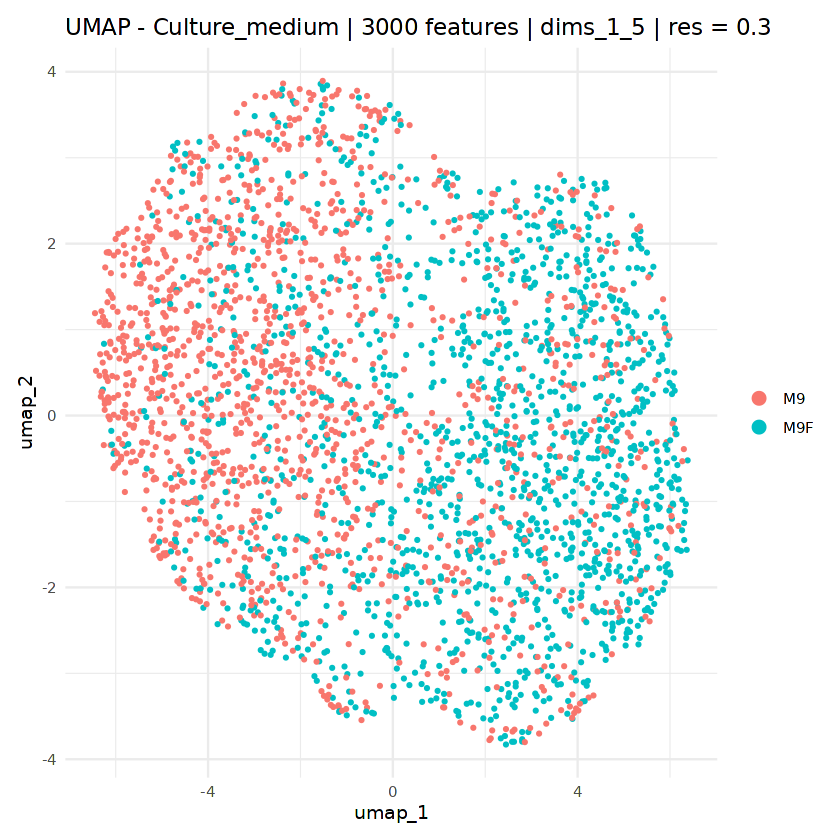

>> nfeatures: 3000 | dims: dims_1_5 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 86212

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7576
Number of communities: 4
Elapsed time: 0 seconds


15:05:53 UMAP embedding parameters a = 0.9922 b = 1.112

15:05:53 Read 2934 rows and found 5 numeric columns

15:05:53 Using Annoy for neighbor search, n_neighbors = 30

15:05:53 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:05:59 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100206d6c4b5f

15:05:59 Searching Annoy index using 1 thread, search_k = 3000

15:06:00 Annoy recall = 100%

15:06:03 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:06:08 Initializing from normalized Laplacian + noise (using RSpectra)

15:06:08 Commencing optimization for 500 epochs, with 108714 positive edges

15:06:08 Using rng type: pcg

15:06:12 Optimization finished



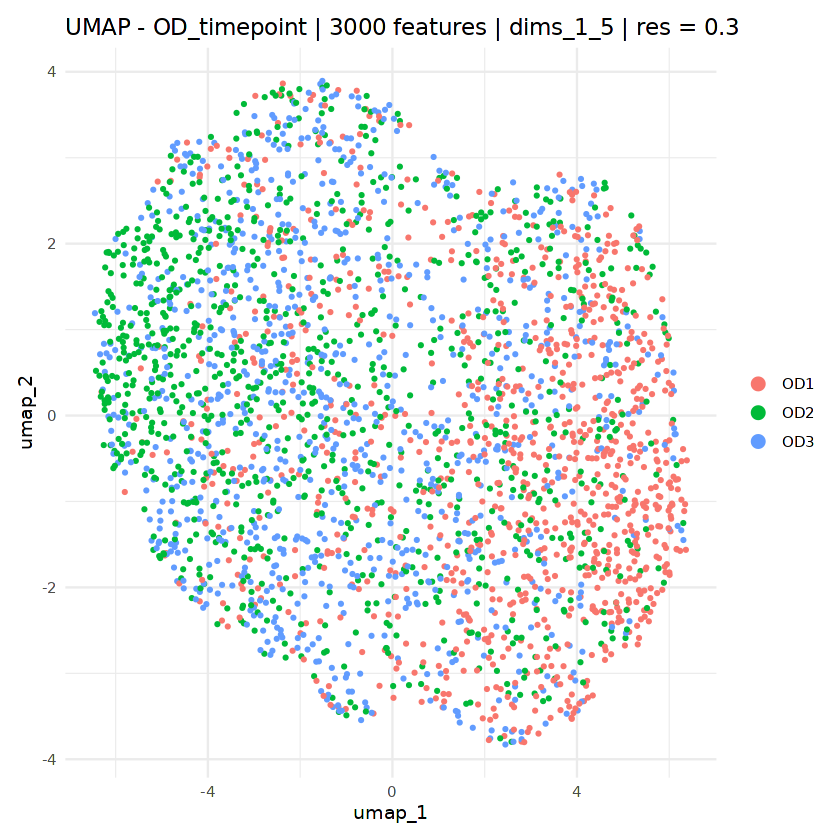

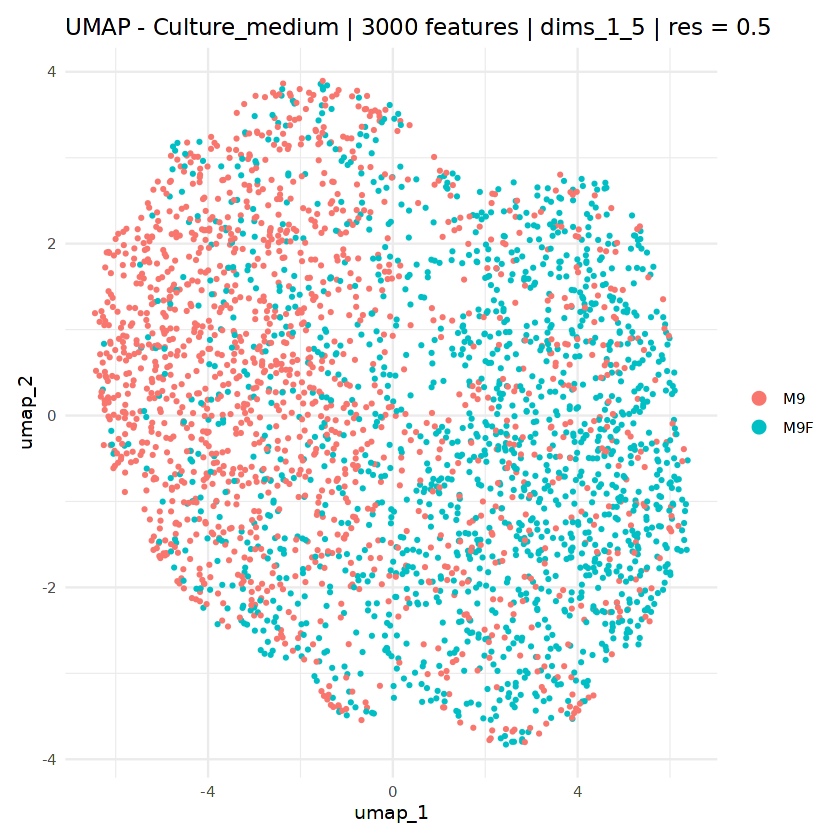

>> nfeatures: 3000 | dims: dims_1_5 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 86212

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6925
Number of communities: 8
Elapsed time: 0 seconds


15:06:21 UMAP embedding parameters a = 0.9922 b = 1.112

15:06:21 Read 2934 rows and found 5 numeric columns

15:06:21 Using Annoy for neighbor search, n_neighbors = 30

15:06:22 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:06:24 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100206c132ba0

15:06:24 Searching Annoy index using 1 thread, search_k = 3000

15:06:25 Annoy recall = 100%

15:21:30 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:21:38 Initializing from normalized Laplacian + noise (using RSpectra)

15:21:38 Commencing optimization for 500 epochs, with 108714 positive edges

15:21:38 Using rng type: pcg

15:21:42 Optimization finished



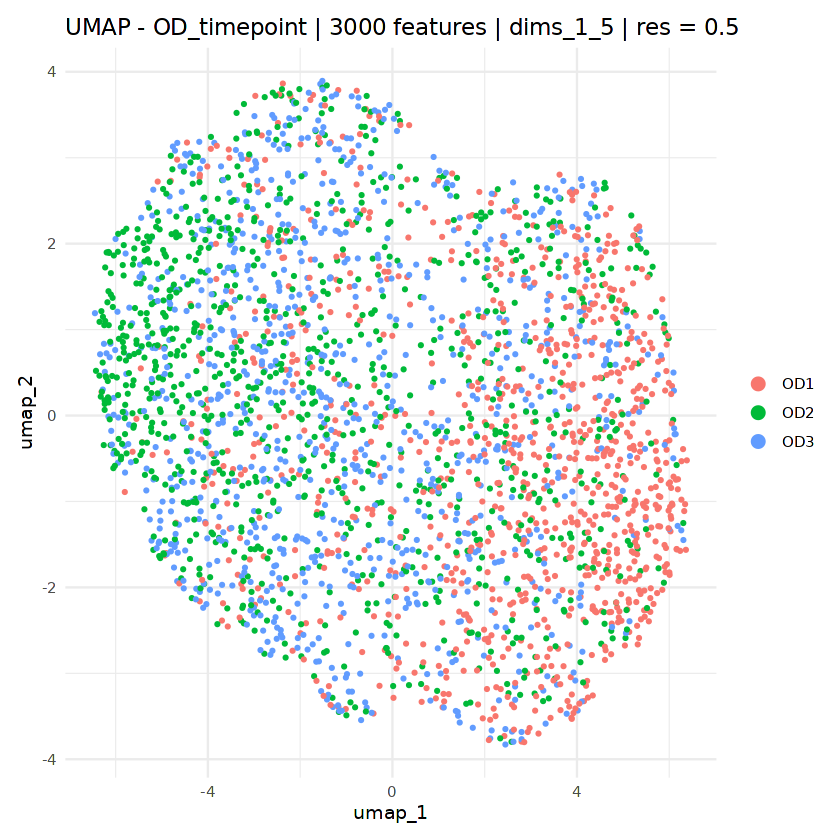

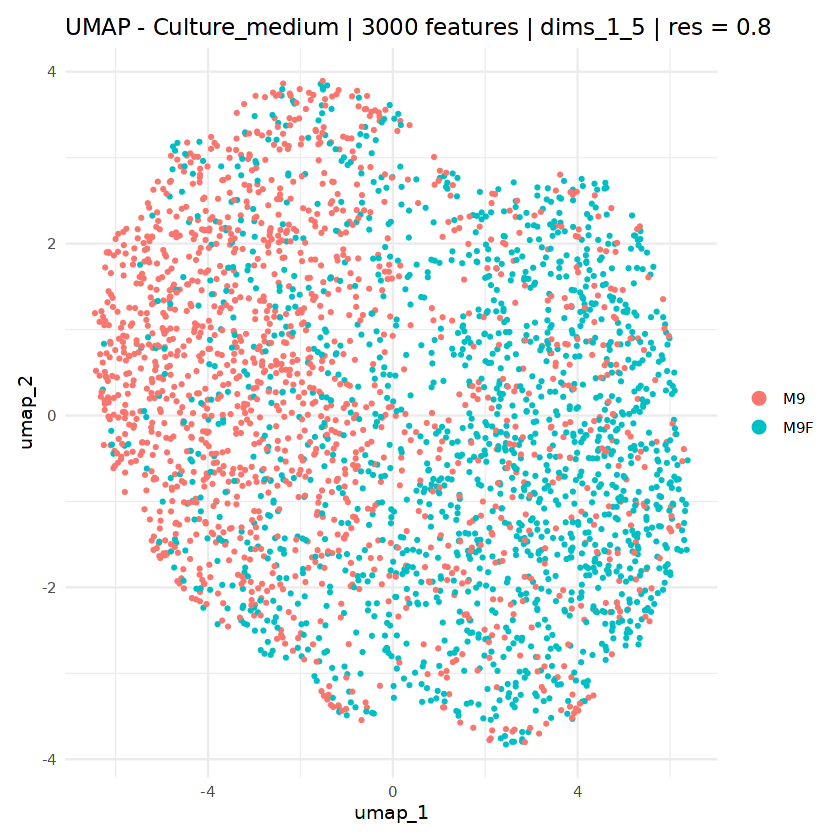

>> nfeatures: 3000 | dims: dims_1_5 | resolution: 1

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 86212

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6693
Number of communities: 11
Elapsed time: 0 seconds


15:21:47 UMAP embedding parameters a = 0.9922 b = 1.112

15:21:47 Read 2934 rows and found 5 numeric columns

15:21:47 Using Annoy for neighbor search, n_neighbors = 30

15:21:47 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:21:49 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100207a301985

15:21:49 Searching Annoy index using 1 thread, search_k = 3000

15:21:50 Annoy recall = 100%

15:21:52 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:21:54 Initializing from normalized Laplacian + noise (using RSpectra)

15:21:54 Commencing optimization for 500 epochs, with 108714 positive edges

15:21:54 Using rng type: pcg

15:21:57 Optimization finished



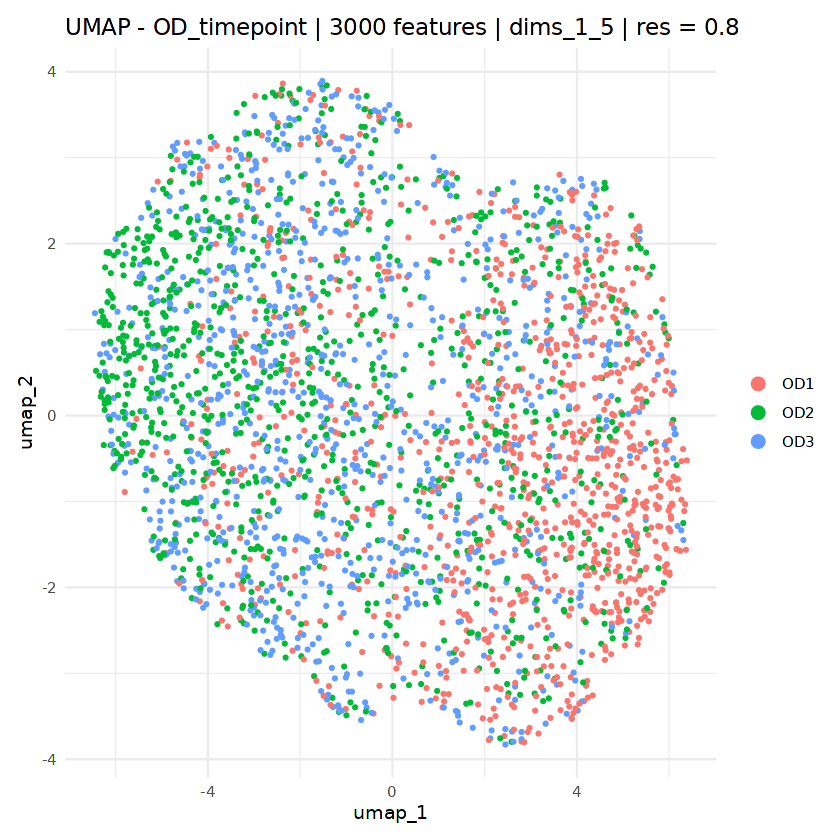

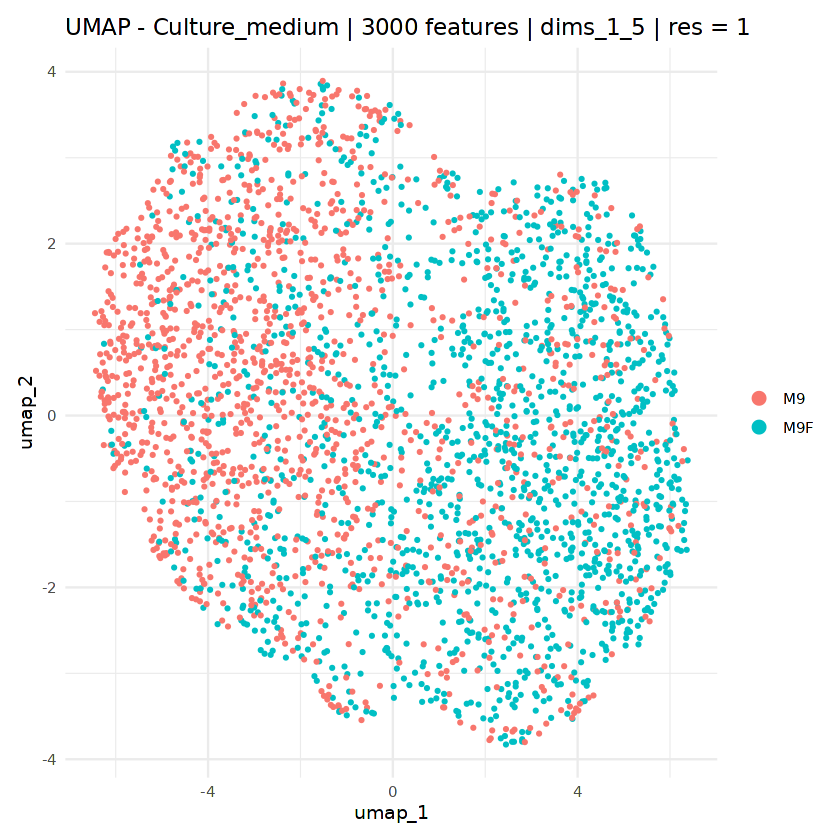

>> nfeatures: 3000 | dims: dims_1_10 | resolution: 0.3

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 95698

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8155
Number of communities: 2
Elapsed time: 0 seconds


15:22:55 UMAP embedding parameters a = 0.9922 b = 1.112

15:22:55 Read 2934 rows and found 10 numeric columns

15:22:55 Using Annoy for neighbor search, n_neighbors = 30

15:22:55 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:22:57 Writing NN index file to temp file /tmp/RtmpLpoVWr/file100203b324c3b

15:22:57 Searching Annoy index using 1 thread, search_k = 3000

15:22:58 Annoy recall = 100%

15:22:59 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:23:02 Initializing from normalized Laplacian + noise (using RSpectra)

15:23:02 Commencing optimization for 500 epochs, with 123114 positive edges

15:23:02 Using rng type: pcg

15:23:06 Optimization finished



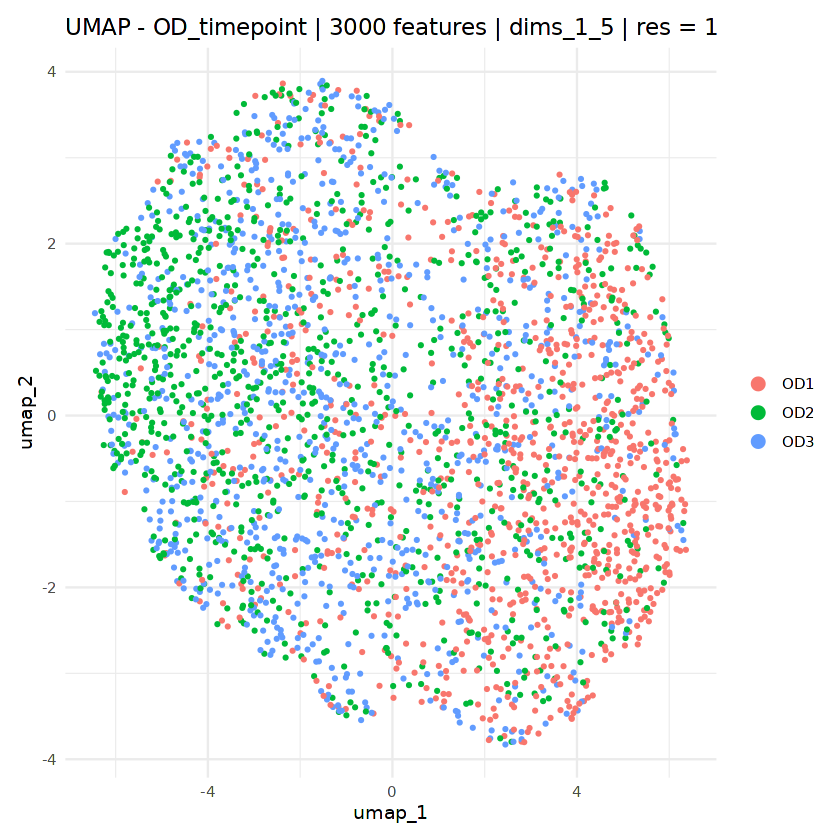

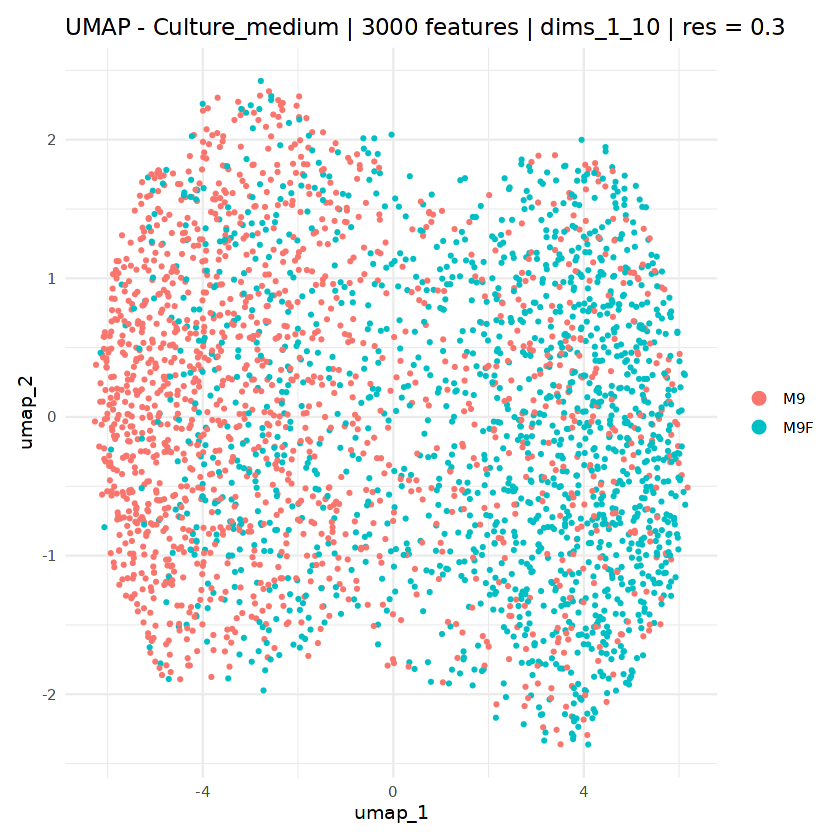

>> nfeatures: 3000 | dims: dims_1_10 | resolution: 0.5

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 95698

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7277
Number of communities: 3
Elapsed time: 0 seconds


15:23:09 UMAP embedding parameters a = 0.9922 b = 1.112

15:23:09 Read 2934 rows and found 10 numeric columns

15:23:09 Using Annoy for neighbor search, n_neighbors = 30

15:23:09 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:23:10 Writing NN index file to temp file /tmp/RtmpLpoVWr/file1002034f3c372

15:23:10 Searching Annoy index using 1 thread, search_k = 3000

15:23:11 Annoy recall = 100%

15:23:14 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:48:55 Initializing from normalized Laplacian + noise (using RSpectra)

15:48:55 Commencing optimization for 500 epochs, with 123114 positive edges

15:48:55 Using rng type: pcg

15:49:21 Optimization finished



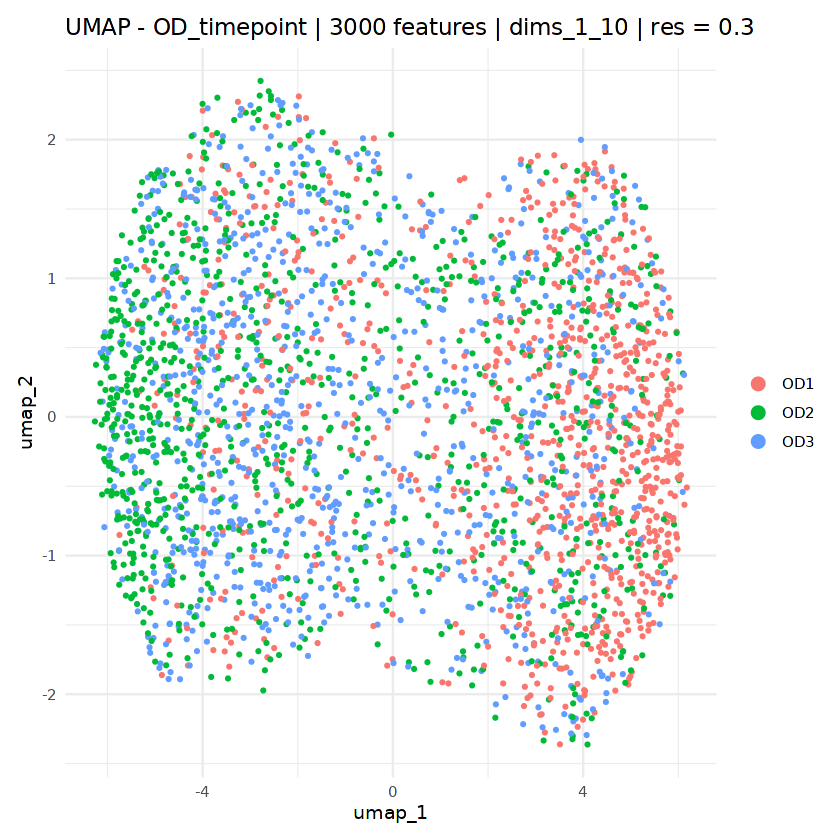

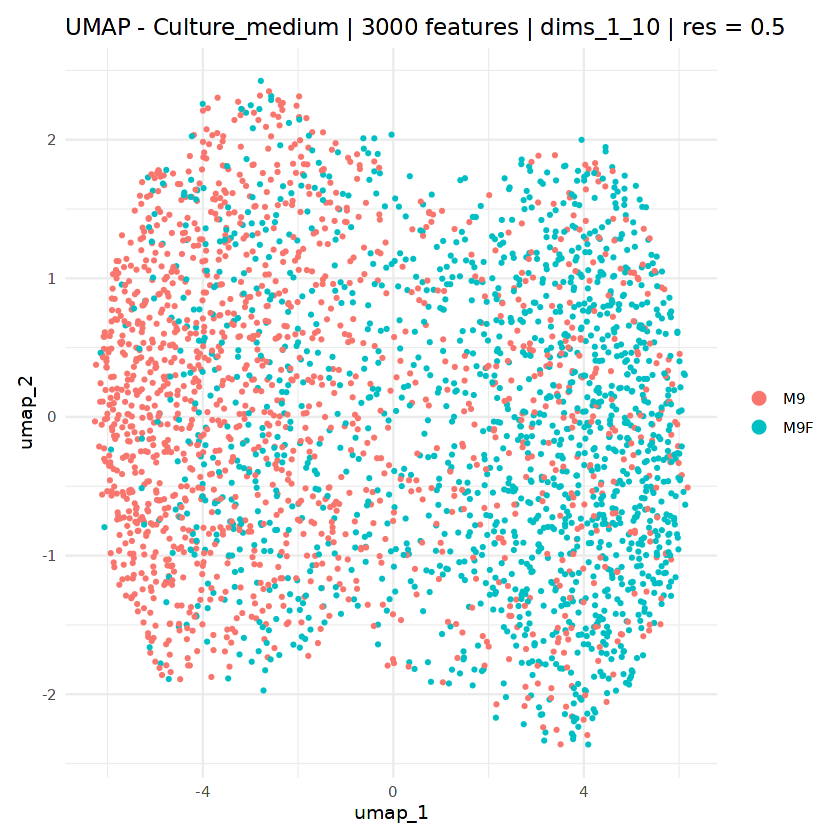

>> nfeatures: 3000 | dims: dims_1_10 | resolution: 0.8

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2934
Number of edges: 95698

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6413
Number of communities: 4
Elapsed time: 0 seconds


15:49:51 UMAP embedding parameters a = 0.9922 b = 1.112

15:49:52 Read 2934 rows and found 10 numeric columns

15:49:52 Using Annoy for neighbor search, n_neighbors = 30



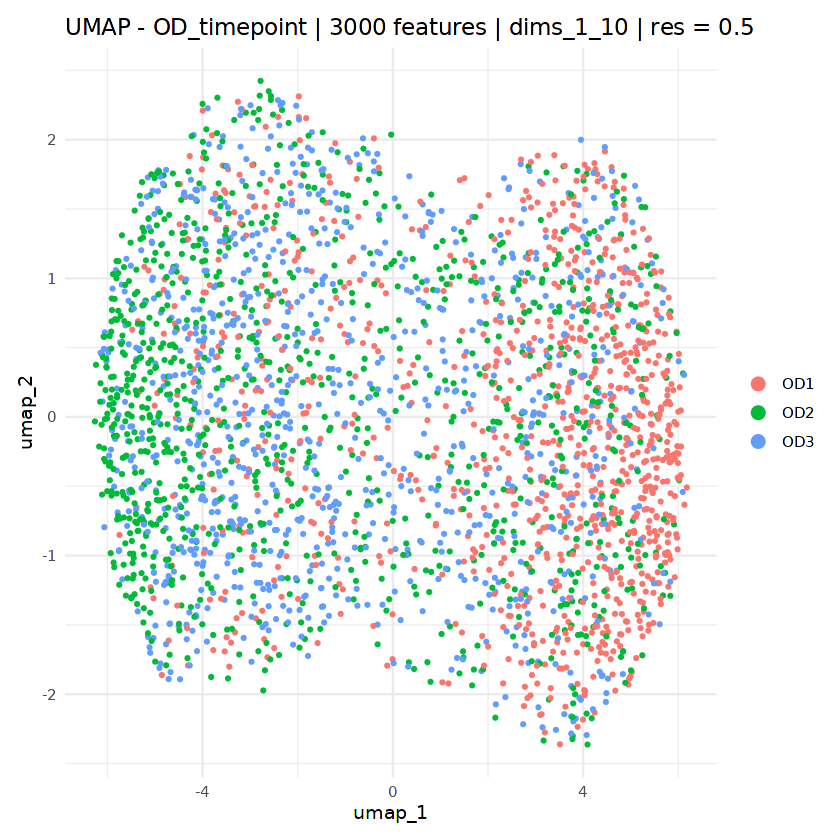

In [7]:
library(Seurat)
library(ggplot2)

# Paramètres à tester
nfeatures_list <- c(200, 500, 1000, 1500, 3000, 5000)
dims_list <- list(1:5, 1:10, 1:15)
resolutions <- c(0.3, 0.5, 0.8, 1.0)

for (n in nfeatures_list) {
  message("==== nfeatures = ", n, " ====")
  
  seu_tmp <- FindVariableFeatures(seurat_obj, nfeatures = n)
  seu_tmp <- ScaleData(seu_tmp)
  seu_tmp <- RunPCA(seu_tmp)
  
  # PCA-level plots
  print(ElbowPlot(seu_tmp, ndims = 50) + ggtitle(paste("ElbowPlot -", n, "features")))
  print(DimHeatmap(seu_tmp, dims = 1:6, cells = 4000, balanced = TRUE, ncol = 3))
  print(VizDimLoadings(seu_tmp, dims = 1:6, reduction = "pca", ncol = 3, nfeatures = 10))
  print(DimPlot(seu_tmp, reduction = "pca", dims = 1:2, group.by = "Culture_medium"))
  print(DimPlot(seu_tmp, reduction = "pca", dims = 1:2, group.by = "OD_timepoint"))
  
  # Boucle sur dim et resolution
  for (dims in dims_list) {
    dim_str <- paste0("dims_", dims[1], "_", tail(dims, 1))
    
    for (res in resolutions) {
      message(paste(">> nfeatures:", n, "| dims:", dim_str, "| resolution:", res))
      
      seu_tmp <- FindNeighbors(seu_tmp, dims = dims)
      seu_tmp <- FindClusters(seu_tmp, resolution = res)
      seu_tmp <- RunUMAP(seu_tmp, dims = dims)
      
      # UMAP plots
      print(
        DimPlot(seu_tmp, reduction = "umap", group.by = "Culture_medium") +
          ggtitle(paste("UMAP - Culture_medium |", n, "features |", dim_str, "| res =", res)) +
          theme_minimal()
      )
      
      print(
        DimPlot(seu_tmp, reduction = "umap", group.by = "OD_timepoint") +
          ggtitle(paste("UMAP - OD_timepoint |", n, "features |", dim_str, "| res =", res)) +
          theme_minimal()
      )
      
      # readline(prompt = paste(">>> Appuyez sur Entrée pour continuer (", n, "f |", dim_str, "| res", res, ")"))
    }
  }
}